# MobileNetV3Large with Coordinate Attention for Sugarcane Leaf Disease Classification

Code accompanying the paper *"MobileNetV3Large with Coordinate Attention for Accurate and Efficient Multi-Class Sugarcane Leaf Disease Classification"* (Bhardwaj, Shekhar, Sukhroop, Kumar).

**How to run:** open in Google Colab with a GPU runtime and run all cells **in order** in one session. Every model cell (Sections 9–17) reuses the data split and `tf.data` pipeline created in Sections 3–5, so those must be run first. Saved outputs from the original run (NVIDIA A100, TensorFlow 2.20.0) are kept in the notebook.


In [ ]:
# Dataset: https://www.kaggle.com/datasets/akilesh253/sugarcane-plant-diseases-dataset


## 1. Download the dataset from Kaggle
Upload your own `kaggle.json` API token when prompted (Kaggle → Settings → API → Create New Token). The token is never stored in this notebook.


In [ ]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.5/111.5 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.5/247.5 kB 27.0 MB/s eta 0:00:00


In [ ]:
from google.colab import files
import os

print("Please select your kaggle.json file.")
uploaded = files.upload()

# Find the uploaded JSON file
json_files = [
    filename
    for filename in uploaded.keys()
    if filename.lower().endswith(".json")
]

if len(json_files) == 0:
    raise FileNotFoundError(
        "No JSON file was uploaded. Please upload kaggle.json."
    )

if "kaggle.json" in uploaded:
    source_filename = "kaggle.json"
elif len(json_files) == 1:
    source_filename = json_files[0]
else:
    raise ValueError(
        "More than one JSON file was uploaded. "
        "Please upload only kaggle.json."
    )

# Create Kaggle credentials directory
kaggle_directory = "/root/.kaggle"
os.makedirs(kaggle_directory, exist_ok=True)

# Save the uploaded credentials
credentials_path = os.path.join(kaggle_directory, "kaggle.json")

with open(credentials_path, "wb") as file:
    file.write(uploaded[source_filename])

# Restrict access to the credentials file
os.chmod(credentials_path, 0o600)

print("Kaggle credentials configured successfully.")

Please select your kaggle.json file.


Saving kaggle.json to kaggle.json
Kaggle credentials configured successfully.


In [ ]:
import os
import shutil

DATA_DOWNLOAD_DIRECTORY = "/content/sugarcane_data"

# Remove an older copy when the cell is executed again
if os.path.exists(DATA_DOWNLOAD_DIRECTORY):
    shutil.rmtree(DATA_DOWNLOAD_DIRECTORY)

os.makedirs(DATA_DOWNLOAD_DIRECTORY, exist_ok=True)

print("Downloading the Sugarcane Plant Diseases Dataset...")

In [ ]:
!kaggle datasets download \
    -d akilesh253/sugarcane-plant-diseases-dataset \
    -p /content/sugarcane_data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/akilesh253/sugarcane-plant-diseases-dataset
License(s): Community Data License Agreement - Sharing - Version 1.0
100% 1.00G/1.00G [01:01<00:00, 17.5MB/s]



## 2. Dataset inspection


In [ ]:
from pathlib import Path

dataset_directory = Path(
    "/content/sugarcane_data/Sugarcane_leafs"
)

if not dataset_directory.exists():
    raise FileNotFoundError(
        f"Dataset directory was not found: {dataset_directory}"
    )

class_names = sorted([
    folder.name
    for folder in dataset_directory.iterdir()
    if folder.is_dir()
])

print("Dataset directory:", dataset_directory)
print("Number of classes:", len(class_names))
print("Classes found:")

for class_name in class_names:
    print("-", class_name)

Dataset directory: /content/sugarcane_data/Sugarcane_leafs
Number of classes: 6
Classes found:
- BacterialBlights
- Healthy
- Mosaic
- RedRot
- Rust
- Yellow


In [ ]:
SUPPORTED_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

class_counts = {}

for class_name in class_names:
    class_directory = dataset_directory / class_name

    image_files = [
        file_path
        for file_path in class_directory.rglob("*")
        if file_path.is_file()
        and file_path.suffix.lower() in SUPPORTED_EXTENSIONS
    ]

    class_counts[class_name] = len(image_files)

print("Class-wise image distribution")
print("-" * 45)

for class_name, image_count in class_counts.items():
    print(f"{class_name:25s}: {image_count:5d}")

print("-" * 45)
print(f"{'Total images':25s}: {sum(class_counts.values()):5d}")

Class-wise image distribution
---------------------------------------------
BacterialBlights         :  4800
Healthy                  :  3132
Mosaic                   :  2772
RedRot                   :  3108
Rust                     :  3084
Yellow                   :  3030
---------------------------------------------
Total images             : 19926


In [ ]:
import os

for root, directories, files in os.walk(dataset_directory):
    folder_level = root.replace(
        str(dataset_directory), ""
    ).count(os.sep)

    indentation = "    " * folder_level
    print(f"{indentation}{Path(root).name}/")

    file_indentation = "    " * (folder_level + 1)

    for filename in files[:3]:
        print(f"{file_indentation}{filename}")

    if len(files) > 3:
        print(
            f"{file_indentation}... and "
            f"{len(files) - 3} more files"
        )

Sugarcane_leafs/
    Healthy/
        zoomed_healthy (89).jpeg
        zoomed_healthy (85).jpeg
        rotated_healthy (346).jpeg
        ... and 3129 more files
    Rust/
        flipped_horiz_rust (385).jpeg
        zoomed_rust (78).jpeg
        zoomed_rust (101).jpeg
        ... and 3081 more files
    BacterialBlights/
        cropped_Bacterial Blight_2667.png
        zoomed_Bacterial Blight_3085.png
        flipped_vert_Bacterial Blight_2686.png
        ... and 4797 more files
    Mosaic/
        resized_mosaic (262).jpeg
        flipped_vert_mosaic (368).jpeg
        cropped_mosaic (51).jpeg
        ... and 2769 more files
    Yellow/
        cropped_yellow (124).jpeg
        rotated_yellow (188).jpeg
        rotated_yellow (225).jpeg
        ... and 3027 more files
    RedRot/
        flipped_horiz_redrot (71).jpeg
        cropped_redrot (406).jpeg
        rotated_redrot (232).jpeg
        ... and 3105 more files


In [ ]:
import random
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Supported image extensions
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# Number of sample images to display per class
samples_per_class = 5

# Fix random seed for reproducibility
random.seed(42)

# Get class folders
class_names = sorted([
    folder.name
    for folder in dataset_directory.iterdir()
    if folder.is_dir()
])

# Create figure
num_classes = len(class_names)
fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(15, 3 * num_classes))

# Handle case when only one class exists
if num_classes == 1:
    axes = [axes]

for i, class_name in enumerate(class_names):
    class_dir = dataset_directory / class_name

    image_files = [
        file_path for file_path in class_dir.rglob("*")
        if file_path.is_file() and file_path.suffix.lower() in SUPPORTED_EXTENSIONS
    ]

    selected_images = random.sample(image_files, min(samples_per_class, len(image_files)))

    for j in range(samples_per_class):
        ax = axes[i][j] if num_classes > 1 else axes[j]

        if j < len(selected_images):
            img = Image.open(selected_images[j]).convert("RGB")
            ax.imshow(img)
            ax.set_title(class_name if j == 0 else "", fontsize=14)
        else:
            ax.text(0.5, 0.5, "No Image", ha="center", va="center", fontsize=10)

        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import random
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
samples_per_class = 5
random.seed(42)

class_names = sorted([
    folder.name
    for folder in dataset_directory.iterdir()
    if folder.is_dir()
])

num_classes = len(class_names)
fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(16, 3 * num_classes))

if num_classes == 1:
    axes = [axes]

for i, class_name in enumerate(class_names):
    class_dir = dataset_directory / class_name

    image_files = [
        file_path for file_path in class_dir.rglob("*")
        if file_path.is_file() and file_path.suffix.lower() in SUPPORTED_EXTENSIONS
    ]

    selected_images = random.sample(image_files, min(samples_per_class, len(image_files)))

    for j in range(samples_per_class):
        ax = axes[i][j] if num_classes > 1 else axes[j]

        if j < len(selected_images):
            img = Image.open(selected_images[j]).convert("RGB")
            ax.imshow(img)
        else:
            ax.text(0.5, 0.5, "No Image", ha="center", va="center")

        ax.axis("off")

        if j == 0:
            ax.set_ylabel(class_name, fontsize=12, rotation=90, labelpad=20)

plt.suptitle("Class-wise Sample Image Collage", fontsize=12)
plt.tight_layout()
plt.show()

## 3. Image integrity screening and exact-duplicate removal (SHA-256)


In [ ]:
from pathlib import Path
from PIL import Image
import pandas as pd

dataset_directory = Path(
    "/content/sugarcane_data/Sugarcane_leafs"
)

SUPPORTED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

records = []
corrupted_files = []

class_names = sorted([
    folder.name
    for folder in dataset_directory.iterdir()
    if folder.is_dir()
])

for class_name in class_names:
    class_directory = dataset_directory / class_name

    for image_path in class_directory.rglob("*"):

        if (
            image_path.is_file()
            and image_path.suffix.lower() in SUPPORTED_EXTENSIONS
        ):
            try:
                with Image.open(image_path) as image:
                    image.verify()

                records.append({
                    "filepath": str(image_path),
                    "class_name": class_name
                })

            except Exception as error:
                corrupted_files.append({
                    "filepath": str(image_path),
                    "error": str(error)
                })

image_df = pd.DataFrame(records)

print("Valid images:", len(image_df))
print("Corrupted images:", len(corrupted_files))
print("Classes:", class_names)

display(image_df.head())

Valid images: 19926
Corrupted images: 0
Classes: ['BacterialBlights', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']


,filepath,class_name
0,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights
1,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights
2,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights
3,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights
4,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights


In [ ]:
import hashlib

def calculate_file_hash(file_path, chunk_size=8192):
    sha256_hash = hashlib.sha256()

    with open(file_path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)

            if not chunk:
                break

            sha256_hash.update(chunk)

    return sha256_hash.hexdigest()


image_df["file_hash"] = image_df["filepath"].apply(
    calculate_file_hash
)

duplicate_mask = image_df.duplicated(
    subset="file_hash",
    keep="first"
)

duplicate_df = image_df[duplicate_mask].copy()
clean_image_df = image_df[~duplicate_mask].copy()

print("Original valid images:", len(image_df))
print("Exact duplicate images:", len(duplicate_df))
print("Images after duplicate removal:", len(clean_image_df))

if len(duplicate_df) > 0:
    display(
        duplicate_df[
            ["filepath", "class_name", "file_hash"]
        ].head(10)
    )

Original valid images: 19926
Exact duplicate images: 840
Images after duplicate removal: 19086


,filepath,class_name,file_hash
5045,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,1657d0ba5cd7a1671d779315c999e50b737d8ae90612b5...
5063,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,fa1a7fc8567adfaee257a79513b7020fb0f4850bf86d61...
5103,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,83647f275a53d449eaa52e8ff281af34fcad6289093172...
5244,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,b3edd5260ec969eaa74e2ee01b0f64261cd5ea63233039...
5295,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,b9ce7e237ef8e7579d8039ba020cb18e0b18d2359ab5a1...
5332,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,192b3007e9cd75b8e80084cb7795dbfffa8a2ae0e55bdc...
5339,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,65f91d6c34be28a34d4a8c149e205f216faeba95de857b...
5346,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,461e026e812546f9f996c8df4f1194aeb51fbc973d6461...
5357,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,c3e7033e2f86eaa42227bdb54da13d07a9236ae07649bf...
5374,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,d118a5fdfbf87dc3ddc2dc696837bfc191c3b5bcfa6b2a...


## 4. Label encoding and stratified 70/15/15 split (seed 42)


In [ ]:
class_names = sorted(
    clean_image_df["class_name"].unique()
)

label_to_id = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

id_to_label = {
    index: class_name
    for class_name, index in label_to_id.items()
}

clean_image_df["label_id"] = clean_image_df[
    "class_name"
].map(label_to_id)

print("Class mapping:")

for class_name, label_id in label_to_id.items():
    print(f"{label_id}: {class_name}")

display(clean_image_df.head())

Class mapping:
0: BacterialBlights
1: Healthy
2: Mosaic
3: RedRot
4: Rust
5: Yellow


,filepath,class_name,file_hash,label_id
0,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,74023be3c2283f4a2582ec680452070e5bdc17cfd698b4...,0
1,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,41dc53577fc0f4ff90cf74c70b6d6b7dcbaa3b2e67e3df...,0
2,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,51c1d1dd1d145a14ff98b2b5779488c4596274d4c960c5...,0
3,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,b7aa87cc244c76e15f84f84b1fa02fd330bba8bead85cb...,0
4,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,39add86d7cec3e2ba968215b5798920b3876bdd6480ee8...,0


In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

# First split:
# 70% training and 30% temporary data
train_df, temporary_df = train_test_split(
    clean_image_df,
    test_size=0.30,
    random_state=SEED,
    stratify=clean_image_df["label_id"]
)

# Second split:
# Temporary data is divided equally into validation and test sets
val_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_df["label_id"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nPercentages")
print(f"Training:   {100 * len(train_df) / len(clean_image_df):.2f}%")
print(f"Validation: {100 * len(val_df) / len(clean_image_df):.2f}%")
print(f"Testing:    {100 * len(test_df) / len(clean_image_df):.2f}%")

Training images: 13360
Validation images: 2863
Testing images: 2863

Percentages
Training:   70.00%
Validation: 15.00%
Testing:    15.00%


In [ ]:
train_counts = train_df["class_name"].value_counts()
val_counts = val_df["class_name"].value_counts()
test_counts = test_df["class_name"].value_counts()

split_distribution = pd.DataFrame({
    "Training": train_counts,
    "Validation": val_counts,
    "Testing": test_counts
}).fillna(0).astype(int)

split_distribution["Total"] = (
    split_distribution["Training"]
    + split_distribution["Validation"]
    + split_distribution["Testing"]
)

display(split_distribution)

,Training,Validation,Testing,Total
class_name,,,,
BacterialBlights,3360,720,720,4800
RedRot,2175,466,467,3108
Yellow,2090,448,448,2986
Healthy,2064,442,442,2948
Rust,1971,423,422,2816
Mosaic,1700,364,364,2428


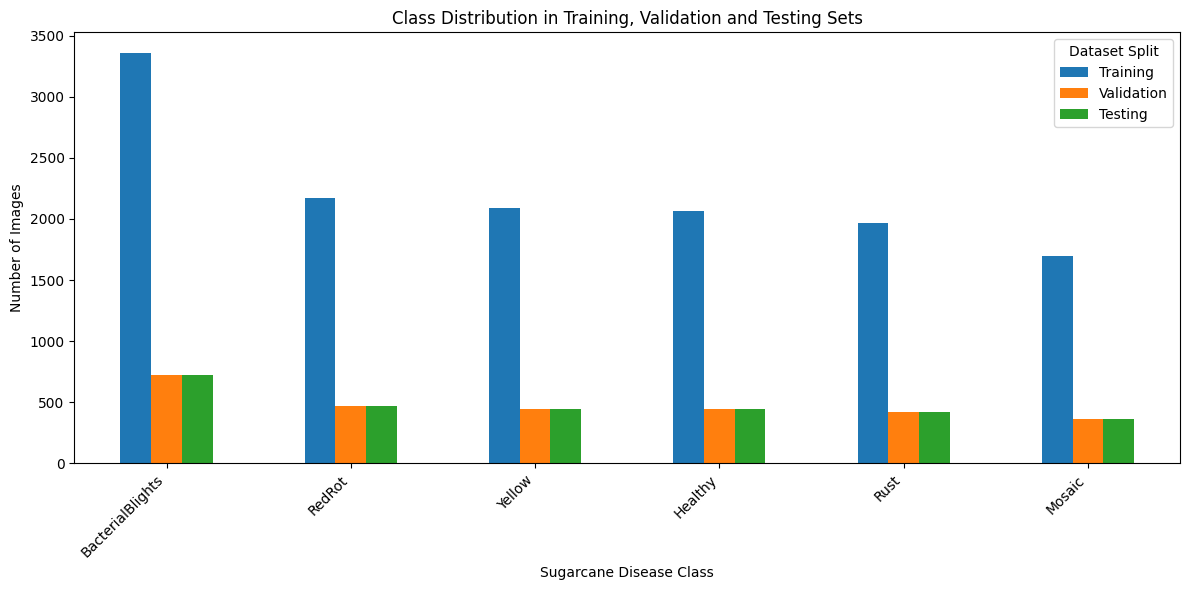

In [ ]:
import matplotlib.pyplot as plt

split_distribution[
    ["Training", "Validation", "Testing"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Class Distribution in Training, Validation and Testing Sets")
plt.xlabel("Sugarcane Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

In [ ]:
split_save_directory = Path(
    "/content/sugarcane_experiment_splits"
)

split_save_directory.mkdir(
    parents=True,
    exist_ok=True
)

train_df.to_csv(
    split_save_directory / "train_split.csv",
    index=False
)

val_df.to_csv(
    split_save_directory / "validation_split.csv",
    index=False
)

test_df.to_csv(
    split_save_directory / "test_split.csv",
    index=False
)

print("Split files saved at:")
print(split_save_directory)

Split files saved at:
/content/sugarcane_experiment_splits


## 5. tf.data input pipeline and online augmentation


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMAGE_SIZE = (IMG_HEIGHT, IMG_WIDTH)

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)

TensorFlow version: 2.20.0


In [ ]:
def load_and_prepare_image(filepath, label):
    """
    Read an image, decode it, resize it and return its label.
    """

    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # decode_image does not set a fixed shape automatically
    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label

In [ ]:
def create_tf_dataset(dataframe, training=False):
    """
    Convert a Pandas DataFrame into a TensorFlow dataset.
    """

    filepaths = dataframe["filepath"].astype(str).values
    labels = dataframe["label_id"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_prepare_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset

In [ ]:
train_dataset = create_tf_dataset(
    train_df,
    training=True
)

validation_dataset = create_tf_dataset(
    val_df,
    training=False
)

test_dataset = create_tf_dataset(
    test_df,
    training=False
)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [ ]:
images, labels = next(
    iter(train_dataset)
)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        )
    ],
    name="data_augmentation"
)

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


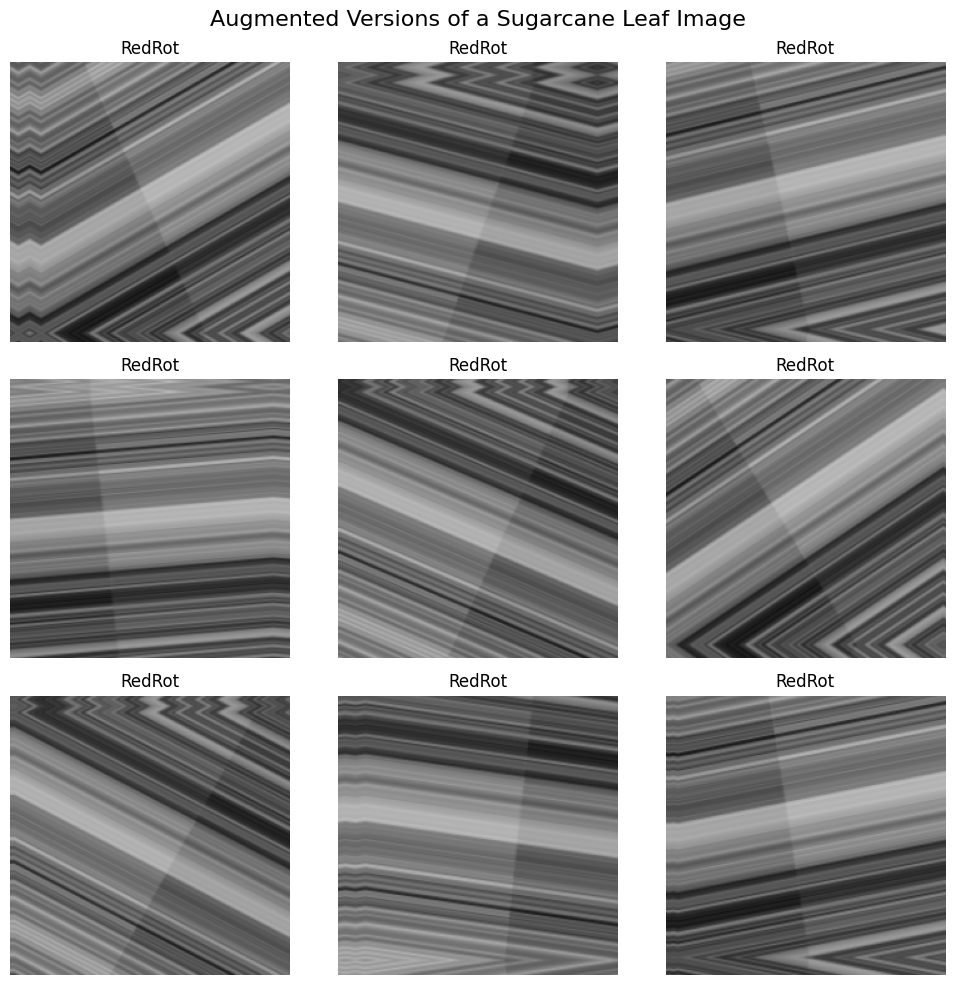

In [ ]:
sample_images, sample_labels = next(
    iter(train_dataset)
)

sample_image = sample_images[0]
sample_label = int(sample_labels[0].numpy())

plt.figure(figsize=(10, 10))

for plot_number in range(9):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    augmented_image = tf.clip_by_value(
        augmented_image,
        0,
        255
    )

    plt.subplot(3, 3, plot_number + 1)

    plt.imshow(
        tf.cast(
            augmented_image,
            tf.uint8
        )
    )

    plt.title(
        id_to_label[sample_label]
    )

    plt.axis("off")

plt.suptitle(
    "Augmented Versions of a Sugarcane Leaf Image",
    fontsize=16
)

plt.tight_layout()
plt.show()

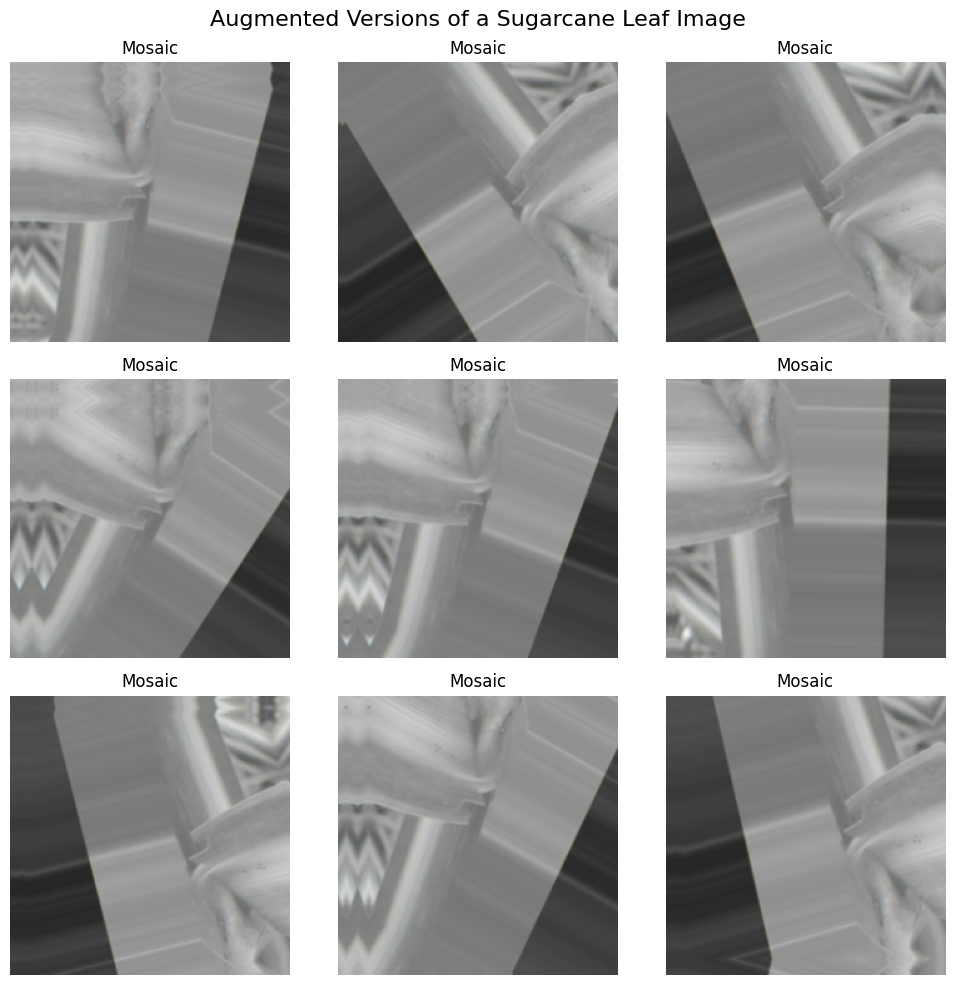

In [ ]:
sample_images, sample_labels = next(
    iter(train_dataset)
)

sample_image = sample_images[0]
sample_label = int(sample_labels[0].numpy())

plt.figure(figsize=(10, 10))

for plot_number in range(9):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    augmented_image = tf.clip_by_value(
        augmented_image,
        0,
        255
    )

    plt.subplot(3, 3, plot_number + 1)

    plt.imshow(
        tf.cast(
            augmented_image,
            tf.uint8
        )
    )

    plt.title(
        id_to_label[sample_label]
    )

    plt.axis("off")

plt.suptitle(
    "Augmented Versions of a Sugarcane Leaf Image",
    fontsize=16
)

plt.tight_layout()
plt.show()

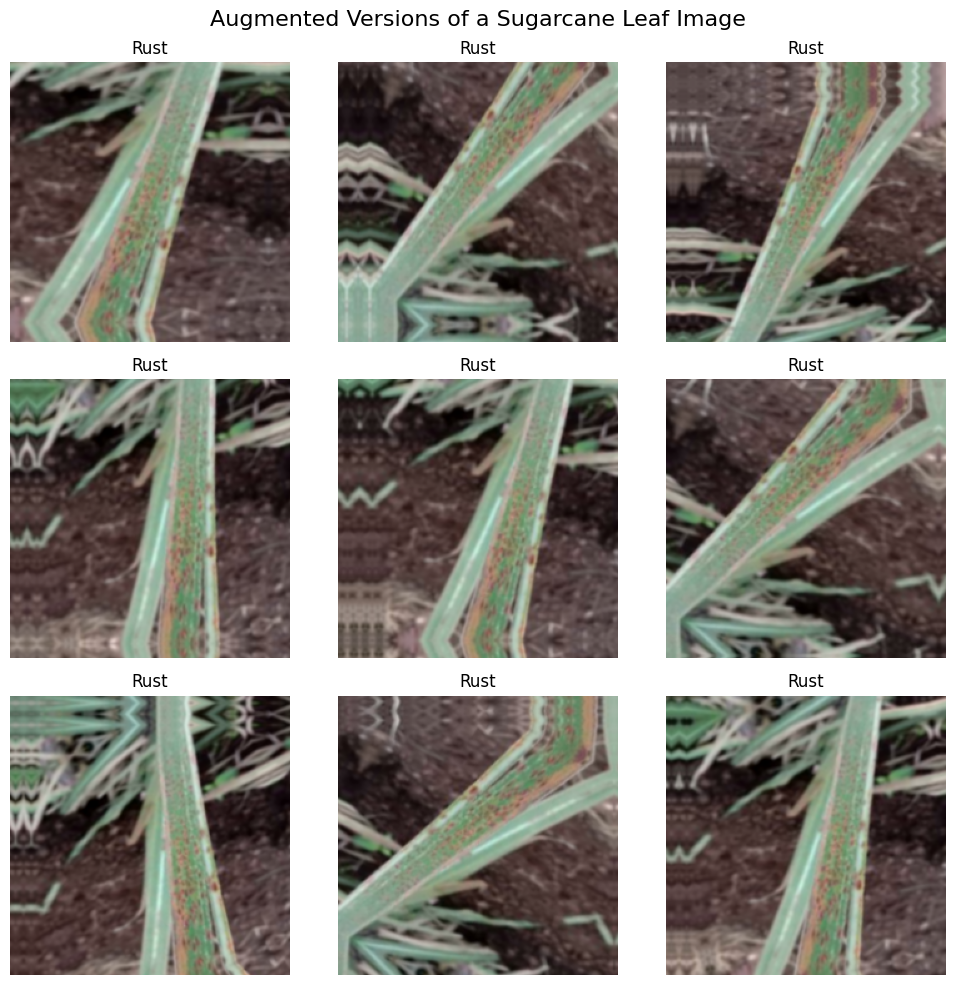

In [ ]:
sample_images, sample_labels = next(
    iter(train_dataset)
)

sample_image = sample_images[0]
sample_label = int(sample_labels[0].numpy())

plt.figure(figsize=(10, 10))

for plot_number in range(9):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    augmented_image = tf.clip_by_value(
        augmented_image,
        0,
        255
    )

    plt.subplot(3, 3, plot_number + 1)

    plt.imshow(
        tf.cast(
            augmented_image,
            tf.uint8
        )
    )

    plt.title(
        id_to_label[sample_label]
    )

    plt.axis("off")

plt.suptitle(
    "Augmented Versions of a Sugarcane Leaf Image",
    fontsize=16
)

plt.tight_layout()
plt.show()

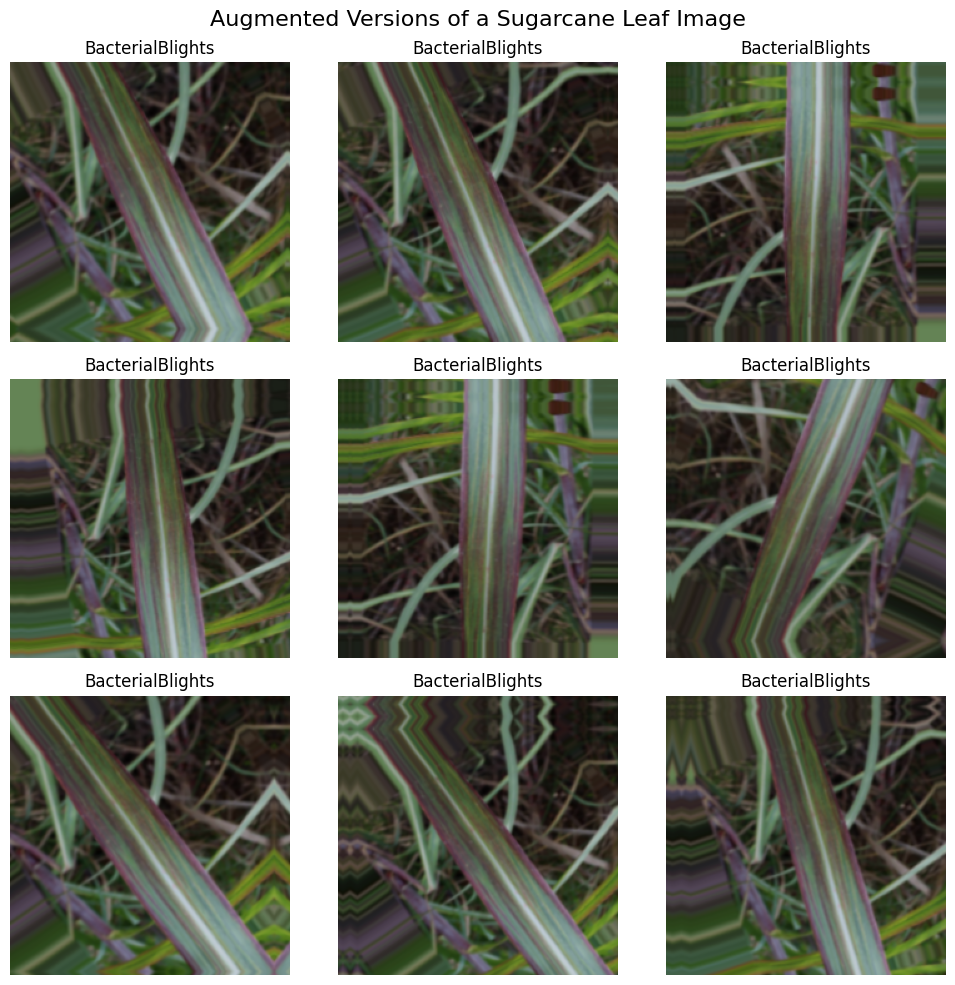

In [ ]:
sample_images, sample_labels = next(
    iter(train_dataset)
)

sample_image = sample_images[0]
sample_label = int(sample_labels[0].numpy())

plt.figure(figsize=(10, 10))

for plot_number in range(9):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    augmented_image = tf.clip_by_value(
        augmented_image,
        0,
        255
    )

    plt.subplot(3, 3, plot_number + 1)

    plt.imshow(
        tf.cast(
            augmented_image,
            tf.uint8
        )
    )

    plt.title(
        id_to_label[sample_label]
    )

    plt.axis("off")

plt.suptitle(
    "Augmented Versions of a Sugarcane Leaf Image",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 6. Custom CNN baseline (trained from scratch)


In [ ]:
from tensorflow.keras import models

number_of_classes = len(class_names)

baseline_model = models.Sequential(
    [
        layers.Input(
            shape=(IMG_HEIGHT, IMG_WIDTH, 3)
        ),

        # Augmentation is active only during training
        data_augmentation,

        # Convert pixel values from 0–255 to 0–1
        layers.Rescaling(1.0 / 255),

        # Convolution block 1
        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same",
            use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        # Convolution block 2
        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        # Convolution block 3
        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        # Convolution block 4
        layers.Conv2D(
            256,
            kernel_size=3,
            padding="same",
            use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        # Classification section
        layers.GlobalAveragePooling2D(),

        layers.Dropout(0.40),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(0.30),

        layers.Dense(
            number_of_classes,
            activation="softmax"
        )
    ],
    name="Sugarcane_Baseline_CNN"
)

baseline_model.summary()

Model: "Sugarcane_Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 423,526 (1.62 MB)

 Trainable params: 422,566 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
checkpoint_path = "/content/best_sugarcane_baseline.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.20,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

In [ ]:
EPOCHS = 40

history = baseline_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/40
418/418 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4871 - loss: 1.3634
Epoch 1: val_loss improved from None to 2.04339, saving model to /content/best_sugarcane_baseline.keras

Epoch 1: finished saving model to /content/best_sugarcane_baseline.keras
418/418 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.5543 - loss: 1.1753 - val_accuracy: 0.3287 - val_loss: 2.0434 - learning_rate: 0.0010
Epoch 2/40
417/418 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6262 - loss: 0.9824
Epoch 2: val_loss did not improve from 2.04339
418/418 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.6441 - loss: 0.9387 - val_accuracy: 0.5061 - val_loss: 2.0800 - learning_rate: 0.0010
Epoch 3/40
417/418 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6717 - loss: 0.8630
Epoch 3: val_loss improved from 2.04339 to 1.03611, saving model to /content/best_sugarcane_baseline.keras

Epoch 3: finished saving model to /content/best_sugarcane_baseline.keras
418/418 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - ac

In [ ]:
history_data = history.history

epochs_completed = range(
    1,
    len(history_data["loss"]) + 1
)

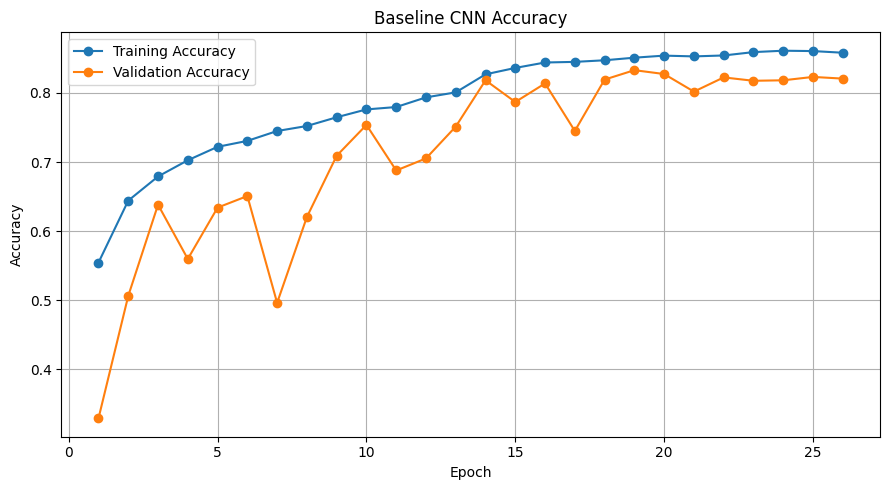

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_completed,
    history_data["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_completed,
    history_data["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Baseline CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

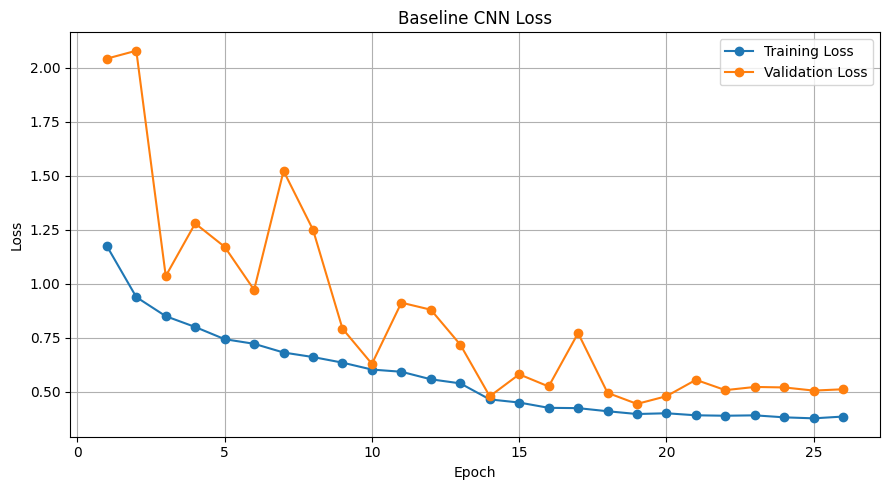

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_completed,
    history_data["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    history_data["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Baseline CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_accuracy = baseline_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy percentage: {test_accuracy * 100:.2f}%")

90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8460 - loss: 0.4415
Test loss: 0.4415
Test accuracy: 0.8460
Test accuracy percentage: 84.60%


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

true_labels = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

prediction_probabilities = baseline_model.predict(
    test_dataset,
    verbose=1
)

predicted_labels = np.argmax(
    prediction_probabilities,
    axis=1
)

print(
    classification_report(
        true_labels,
        predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
                  precision    recall  f1-score   support

BacterialBlights     0.9915    0.9736    0.9825       720
         Healthy     0.7764    0.8643    0.8180       442
          Mosaic     0.8087    0.6621    0.7281       364
          RedRot     0.7386    0.9379    0.8264       467
            Rust     0.8184    0.8223    0.8203       422
          Yellow     0.8968    0.6987    0.7854       448

        accuracy                         0.8460      2863
       macro avg     0.8384    0.8265    0.8268      2863
    weighted avg     0.8535    0.8460    0.8446      2863



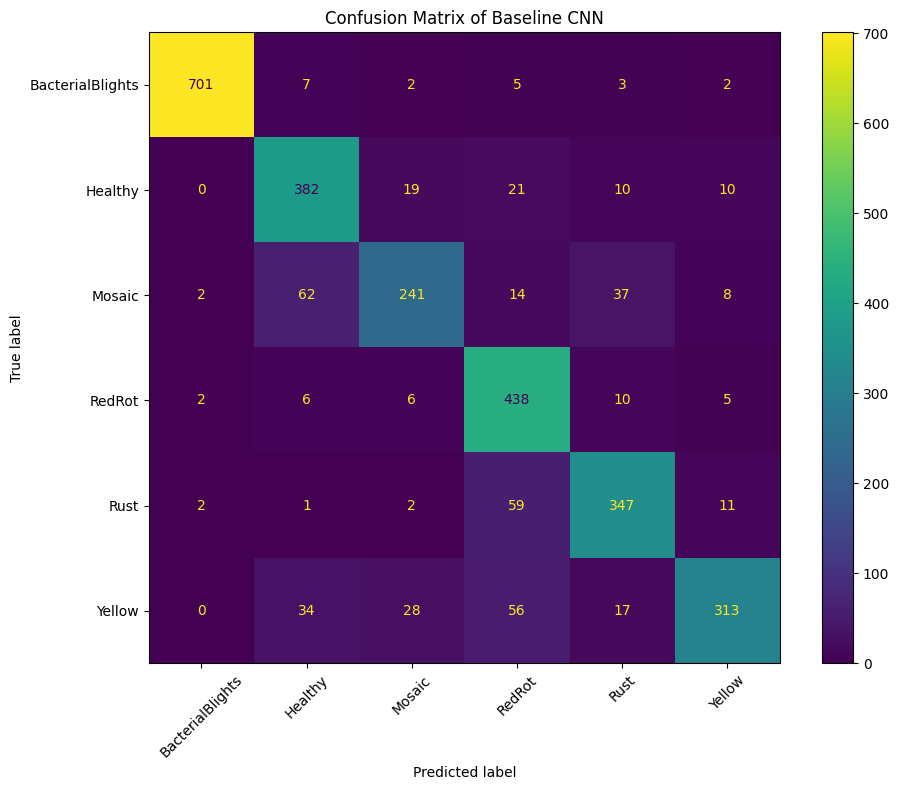

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

confusion_matrix_values = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=range(number_of_classes)
)

display_object = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_values,
    display_labels=class_names
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

display_object.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix of Baseline CNN")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

# Number of test images to show from each class
SAMPLES_PER_CLASS = 4
RANDOM_STATE = 42

selected_groups = []

# Select random test images separately from each class
for class_index, class_name in enumerate(class_names):

    class_test_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(class_test_df)
    )

    sampled_class_df = class_test_df.sample(
        n=number_to_select,
        random_state=RANDOM_STATE + class_index
    ).copy()

    selected_groups.append(sampled_class_df)

# Combine all selected images
selected_samples_df = pd.concat(
    selected_groups,
    ignore_index=True
)

print(
    "Total selected test images:",
    len(selected_samples_df)
)

display(
    selected_samples_df[
        ["filepath", "class_name", "label_id"]
    ].head()
)

Total selected test images: 24


,filepath,class_name,label_id
0,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,0
1,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,0
2,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,0
3,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,0
4,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,1


In [ ]:
def prepare_image_for_prediction(image_path):
    """
    Load and resize one image for model prediction.

    Pixel values remain in the range 0–255 because the baseline
    model already contains a Rescaling(1/255) layer.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    image_array = tf.keras.utils.img_to_array(
        image
    )

    return image_array


# Prepare all selected images
selected_image_batch = np.stack([
    prepare_image_for_prediction(image_path)
    for image_path in selected_samples_df["filepath"]
])

print(
    "Selected image batch shape:",
    selected_image_batch.shape
)

# Generate class probabilities
selected_probabilities = baseline_model.predict(
    selected_image_batch,
    verbose=1
)

# Predicted class index
selected_predicted_ids = np.argmax(
    selected_probabilities,
    axis=1
)

# Maximum softmax probability
selected_confidence_scores = np.max(
    selected_probabilities,
    axis=1
)

# Add prediction information to the DataFrame
selected_samples_df["predicted_id"] = (
    selected_predicted_ids
)

selected_samples_df["predicted_class"] = [
    id_to_label[int(predicted_id)]
    for predicted_id in selected_predicted_ids
]

selected_samples_df["confidence"] = (
    selected_confidence_scores
)

selected_samples_df["correct_prediction"] = (
    selected_samples_df["label_id"]
    == selected_samples_df["predicted_id"]
)

display(
    selected_samples_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ]
)

Selected image batch shape: (24, 224, 224, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step


,class_name,predicted_class,confidence,correct_prediction
0,BacterialBlights,BacterialBlights,0.999999,True
1,BacterialBlights,BacterialBlights,0.999524,True
2,BacterialBlights,BacterialBlights,0.995517,True
3,BacterialBlights,BacterialBlights,0.984987,True
4,Healthy,Healthy,0.429999,True
5,Healthy,Healthy,0.845278,True
6,Healthy,Mosaic,0.489789,False
7,Healthy,Healthy,0.939010,True
8,Mosaic,Mosaic,0.996972,True
9,Mosaic,Healthy,0.608546,False


In [ ]:
number_of_classes = len(class_names)

fig, axes = plt.subplots(
    nrows=number_of_classes,
    ncols=SAMPLES_PER_CLASS,
    figsize=(
        4 * SAMPLES_PER_CLASS,
        3.8 * number_of_classes
    ),
    squeeze=False
)

for row_index, class_name in enumerate(class_names):

    class_samples = selected_samples_df[
        selected_samples_df["class_name"] == class_name
    ].reset_index(drop=True)

    for column_index in range(SAMPLES_PER_CLASS):

        ax = axes[row_index, column_index]

        # Hide the position if the class has fewer images
        if column_index >= len(class_samples):
            ax.axis("off")
            continue

        sample = class_samples.iloc[column_index]

        # Open original image for visualization
        image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        true_class = sample["class_name"]
        predicted_class = sample["predicted_class"]
        confidence_percentage = (
            sample["confidence"] * 100
        )
        is_correct = sample["correct_prediction"]

        ax.imshow(image)

        # Green title for correct prediction;
        # red title for incorrect prediction
        title_colour = (
            "green" if is_correct else "red"
        )

        ax.set_title(
            f"True: {true_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        ax.axis("off")

        # Add the class name on the left side of each row
        if column_index == 0:
            ax.set_ylabel(
                true_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=18
            )

plt.suptitle(
    "Class-wise Sugarcane Disease Predictions with Confidence Scores",
    fontsize=17,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()
plt.show()

In [ ]:
confidence_summary = (
    selected_samples_df
    .groupby("class_name")
    .agg(
        Number_of_Samples=(
            "filepath",
            "count"
        ),
        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),
        Average_Confidence=(
            "confidence",
            "mean"
        ),
        Minimum_Confidence=(
            "confidence",
            "min"
        ),
        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

confidence_summary[
    "Class_Accuracy_Percentage"
] = (
    confidence_summary[
        "Correct_Predictions"
    ]
    / confidence_summary[
        "Number_of_Samples"
    ]
    * 100
)

for column in [
    "Average_Confidence",
    "Minimum_Confidence",
    "Maximum_Confidence"
]:
    confidence_summary[column] = (
        confidence_summary[column] * 100
    )

confidence_summary = confidence_summary.rename(
    columns={
        "class_name": "Class",
        "Average_Confidence":
            "Average_Confidence_Percentage",
        "Minimum_Confidence":
            "Minimum_Confidence_Percentage",
        "Maximum_Confidence":
            "Maximum_Confidence_Percentage"
    }
)

display(
    confidence_summary.round(2)
)

,Class,Number_of_Samples,Correct_Predictions,Average_Confidence_Percentage,Minimum_Confidence_Percentage,Maximum_Confidence_Percentage,Class_Accuracy_Percentage
0,BacterialBlights,4,4,99.500000,98.500000,100.000000,100.0
1,Healthy,4,3,67.599998,43.000000,93.900002,75.0
2,Mosaic,4,1,69.440002,49.500000,99.699997,25.0
3,RedRot,4,3,86.290001,49.529999,99.970001,75.0
4,Rust,4,4,85.820000,62.349998,100.000000,100.0
5,Yellow,4,1,81.269997,51.250000,95.339996,25.0


## 7. EfficientNetB0 (frozen feature extractor + one-time fine-tuning check)


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)

print("TensorFlow version:", tf.__version__)
print("Number of classes:", number_of_classes)
print("Classes:", class_names)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices("GPU")

if available_gpus:
    print("GPU detected:", available_gpus)
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )

TensorFlow version: 2.20.0
Number of classes: 6
Classes: ['BacterialBlights', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Image size: (224, 224)
Training images: 13360
Validation images: 2863
Testing images: 2863
GPU detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from tensorflow.keras import layers
from tensorflow.keras import models
from tensorflow.keras import regularizers

efficientnet_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        )
    ],
    name="efficientnet_data_augmentation"
)

print("EfficientNet data augmentation created.")

EfficientNet data augmentation created.


In [ ]:
tf.keras.utils.set_random_seed(SEED)

efficientnet_base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMG_HEIGHT,
        IMG_WIDTH,
        3
    )
)

# Freeze the complete pretrained feature extractor
efficientnet_base.trainable = False

print("EfficientNetB0 base loaded successfully.")
print("Number of base-model layers:", len(efficientnet_base.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
EfficientNetB0 base loaded successfully.
Number of base-model layers: 238


In [ ]:
inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="input_image"
)

# Apply augmentation only during training
x = efficientnet_augmentation(inputs)

# Keep the pretrained network in inference mode.
# This is especially important for BatchNormalization layers.
x = efficientnet_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.BatchNormalization(
    name="classification_batch_normalization"
)(x)

x = layers.Dropout(
    0.40,
    name="dropout_1"
)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="dense_256"
)(x)

x = layers.Dropout(
    0.30,
    name="dropout_2"
)(x)

outputs = layers.Dense(
    number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

efficientnet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="Sugarcane_EfficientNetB0"
)

efficientnet_model.summary()

Model: "Sugarcane_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnet_data_augmentation  │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_batch_normaliza… │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_predictions (Dense)       │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,384,169 (16.72 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Frozen EfficientNetB0 model compiled successfully.")

Frozen EfficientNetB0 model compiled successfully.


In [ ]:
efficientnet_output_directory = Path(
    "/content/efficientnet_results"
)

efficientnet_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

phase1_checkpoint_path = (
    efficientnet_output_directory
    / "efficientnet_phase1_best.keras"
)

phase1_log_path = (
    efficientnet_output_directory
    / "efficientnet_phase1_training_log.csv"
)

phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(phase1_checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(phase1_log_path),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]

In [ ]:
INITIAL_EPOCHS = 20

efficientnet_history_frozen = efficientnet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=INITIAL_EPOCHS,
    callbacks=phase1_callbacks,
    verbose=1
)

Epoch 1/20
418/418 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5990 - loss: 1.3408
Epoch 1: val_loss improved from None to 0.58309, saving model to /content/efficientnet_results/efficientnet_phase1_best.keras

Epoch 1: finished saving model to /content/efficientnet_results/efficientnet_phase1_best.keras
418/418 ━━━━━━━━━━━━━━━━━━━━ 28s 41ms/step - accuracy: 0.6681 - loss: 1.0691 - val_accuracy: 0.8034 - val_loss: 0.5831 - learning_rate: 0.0010
Epoch 2/20
418/418 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7320 - loss: 0.7894
Epoch 2: val_loss improved from 0.58309 to 0.53915, saving model to /content/efficientnet_results/efficientnet_phase1_best.keras

Epoch 2: finished saving model to /content/efficientnet_results/efficientnet_phase1_best.keras
418/418 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.7375 - loss: 0.7663 - val_accuracy: 0.8114 - val_loss: 0.5392 - learning_rate: 0.0010
Epoch 3/20
418/418 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7494 - loss: 0.7173
Epoch 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

# Confirm output directory
efficientnet_output_directory = Path(
    "/content/efficientnet_results"
)

efficientnet_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

phase1_checkpoint_path = (
    efficientnet_output_directory
    / "efficientnet_phase1_best.keras"
)

if not phase1_checkpoint_path.exists():
    raise FileNotFoundError(
        f"Phase-1 checkpoint was not found at: "
        f"{phase1_checkpoint_path}"
    )

# Load the best model obtained during frozen training
efficientnet_model = tf.keras.models.load_model(
    str(phase1_checkpoint_path)
)

print("Best Phase-1 model loaded successfully.")
print("Loaded from:", phase1_checkpoint_path)

Best Phase-1 model loaded successfully.
Loaded from: /content/efficientnet_results/efficientnet_phase1_best.keras


In [ ]:
efficientnet_base = None

for layer in efficientnet_model.layers:

    if isinstance(layer, tf.keras.Model):

        if "efficientnet" in layer.name.lower():
            efficientnet_base = layer
            break

if efficientnet_base is None:
    raise ValueError(
        "EfficientNet base model could not be located "
        "inside the classification model."
    )

print("Base model found:", efficientnet_base.name)
print(
    "Total base-model layers:",
    len(efficientnet_base.layers)
)

Base model found: efficientnet_data_augmentation
Total base-model layers: 5


In [ ]:
FINE_TUNE_LAYERS = 30

# First make the base model trainable
efficientnet_base.trainable = True

# Freeze all layers except the final selected layers
for layer in efficientnet_base.layers[
    :-FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in efficientnet_base.layers:
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

trainable_base_layers = [
    layer.name
    for layer in efficientnet_base.layers
    if layer.trainable
]

print(
    "Total EfficientNetB0 layers:",
    len(efficientnet_base.layers)
)

print(
    "Trainable EfficientNetB0 layers:",
    len(trainable_base_layers)
)

print("\nTrainable layers:")

for layer_name in trainable_base_layers:
    print("-", layer_name)

Total EfficientNetB0 layers: 5
Trainable EfficientNetB0 layers: 5

Trainable layers:
- random_flip_1
- random_rotation_1
- random_zoom_1
- random_translation_1
- random_contrast_1


In [ ]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Model compiled for one-time fine-tuning.")

Model compiled for one-time fine-tuning.


In [ ]:
fine_tune_checkpoint_path = (
    efficientnet_output_directory
    / "efficientnet_finetuned_best.keras"
)

fine_tune_log_path = (
    efficientnet_output_directory
    / "efficientnet_finetuning_log.csv"
)

fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            fine_tune_checkpoint_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            fine_tune_log_path
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]

print("Fine-tuning callbacks created.")

Fine-tuning callbacks created.


In [ ]:
MAX_FINE_TUNE_EPOCHS = 15

efficientnet_history_finetune = (
    efficientnet_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=MAX_FINE_TUNE_EPOCHS,
        callbacks=fine_tune_callbacks,
        verbose=1
    )
)

Epoch 1/15
418/418 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8402 - loss: 0.5101
Epoch 1: val_loss improved from None to 0.41613, saving model to /content/efficientnet_results/efficientnet_finetuned_best.keras

Epoch 1: finished saving model to /content/efficientnet_results/efficientnet_finetuned_best.keras
418/418 ━━━━━━━━━━━━━━━━━━━━ 28s 42ms/step - accuracy: 0.8430 - loss: 0.5044 - val_accuracy: 0.8767 - val_loss: 0.4161 - learning_rate: 1.0000e-05
Epoch 2/15
418/418 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8441 - loss: 0.5056
Epoch 2: val_loss did not improve from 0.41613
418/418 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.8426 - loss: 0.4993 - val_accuracy: 0.8753 - val_loss: 0.4166 - learning_rate: 1.0000e-05
Epoch 3/15
417/418 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8469 - loss: 0.4958
Epoch 3: val_loss did not improve from 0.41613

Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
418/418 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - 

In [ ]:
phase1_best_val_loss = min(
    efficientnet_history_frozen.history[
        "val_loss"
    ]
)

phase1_best_epoch = (
    np.argmin(
        efficientnet_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

fine_tune_best_val_loss = min(
    efficientnet_history_finetune.history[
        "val_loss"
    ]
)

fine_tune_best_epoch = (
    np.argmin(
        efficientnet_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

print("Frozen Phase")
print("-" * 45)
print(
    "Best epoch:",
    phase1_best_epoch
)
print(
    f"Minimum validation loss: "
    f"{phase1_best_val_loss:.4f}"
)

print("\nFine-tuning Phase")
print("-" * 45)
print(
    "Best epoch:",
    fine_tune_best_epoch
)
print(
    f"Minimum validation loss: "
    f"{fine_tune_best_val_loss:.4f}"
)

Frozen Phase
---------------------------------------------
Best epoch: 20
Minimum validation loss: 0.4149

Fine-tuning Phase
---------------------------------------------
Best epoch: 5
Minimum validation loss: 0.4159


In [ ]:
if (
    fine_tune_checkpoint_path.exists()
    and fine_tune_best_val_loss
    <= phase1_best_val_loss
):
    selected_model_path = (
        fine_tune_checkpoint_path
    )

    selected_model_name = (
        "Once Fine-tuned EfficientNetB0"
    )

else:
    selected_model_path = (
        phase1_checkpoint_path
    )

    selected_model_name = (
        "Frozen EfficientNetB0"
    )

best_efficientnet_model = (
    tf.keras.models.load_model(
        str(selected_model_path)
    )
)

print("Selected model:", selected_model_name)
print("Loaded from:", selected_model_path)

Selected model: Frozen EfficientNetB0
Loaded from: /content/efficientnet_results/efficientnet_phase1_best.keras


In [ ]:
phase1_epochs_completed = len(
    efficientnet_history_frozen.history[
        "loss"
    ]
)

fine_tune_epochs_completed = len(
    efficientnet_history_finetune.history[
        "loss"
    ]
)

combined_history = {}

history_keys = [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]

for history_key in history_keys:

    combined_history[history_key] = (
        list(
            efficientnet_history_frozen.history[
                history_key
            ]
        )
        +
        list(
            efficientnet_history_finetune.history[
                history_key
            ]
        )
    )

total_epochs_completed = len(
    combined_history["loss"]
)

combined_epoch_numbers = range(
    1,
    total_epochs_completed + 1
)

print(
    "Frozen epochs completed:",
    phase1_epochs_completed
)

print(
    "Fine-tuning epochs completed:",
    fine_tune_epochs_completed
)

print(
    "Total epochs completed:",
    total_epochs_completed
)

Frozen epochs completed: 20
Fine-tuning epochs completed: 9
Total epochs completed: 29


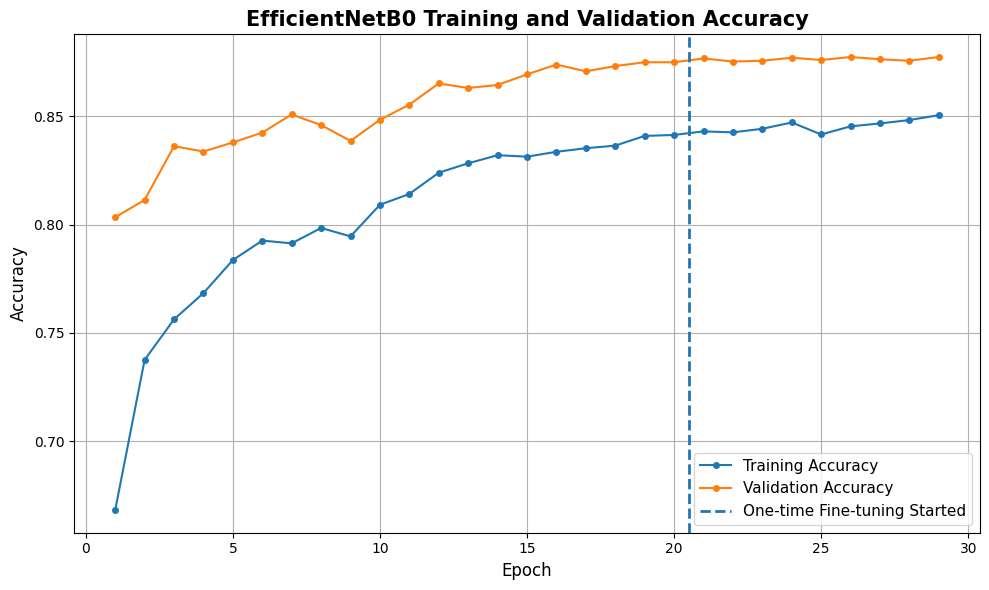

Saved at: /content/efficientnet_results/efficientnet_combined_accuracy.png


In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    combined_epoch_numbers,
    combined_history["accuracy"],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    combined_epoch_numbers,
    combined_history["val_accuracy"],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "EfficientNetB0 Training and Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)

plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

accuracy_graph_path = (
    efficientnet_output_directory
    / "efficientnet_combined_accuracy.png"
)

plt.savefig(
    accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved at:", accuracy_graph_path)

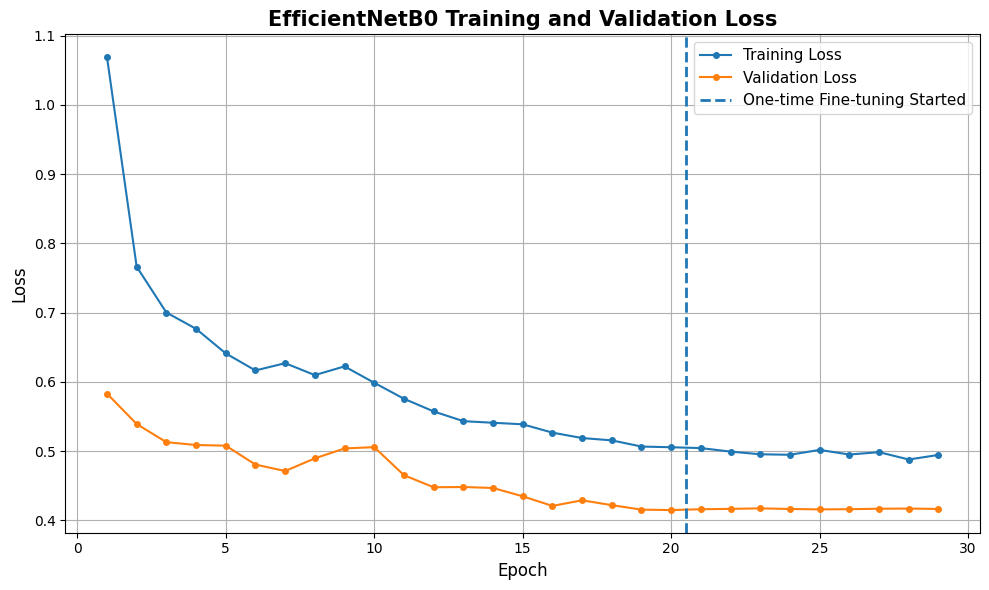

Saved at: /content/efficientnet_results/efficientnet_combined_loss.png


In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    combined_epoch_numbers,
    combined_history["loss"],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    combined_epoch_numbers,
    combined_history["val_loss"],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "EfficientNetB0 Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)

plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

loss_graph_path = (
    efficientnet_output_directory
    / "efficientnet_combined_loss.png"
)

plt.savefig(
    loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved at:", loss_graph_path)

In [ ]:
efficientnet_test_loss, efficientnet_test_accuracy = (
    best_efficientnet_model.evaluate(
        test_dataset,
        verbose=1
    )
)

print("\nEfficientNetB0 Test Results")
print("-" * 50)

print(
    f"Test loss: "
    f"{efficientnet_test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{efficientnet_test_accuracy:.4f}"
)

print(
    f"Test accuracy percentage: "
    f"{efficientnet_test_accuracy * 100:.2f}%"
)

90/90 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.8746 - loss: 0.4154

EfficientNetB0 Test Results
--------------------------------------------------
Test loss: 0.4154
Test accuracy: 0.8746
Test accuracy percentage: 87.46%


In [ ]:
efficientnet_true_labels = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

efficientnet_probabilities = (
    best_efficientnet_model.predict(
        test_dataset,
        verbose=1
    )
)

efficientnet_predicted_labels = np.argmax(
    efficientnet_probabilities,
    axis=1
)

efficientnet_confidence_scores = np.max(
    efficientnet_probabilities,
    axis=1
)

print(
    "True labels:",
    efficientnet_true_labels.shape
)

print(
    "Prediction probabilities:",
    efficientnet_probabilities.shape
)

print(
    "Predicted labels:",
    efficientnet_predicted_labels.shape
)

90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step
True labels: (2863,)
Prediction probabilities: (2863, 6)
Predicted labels: (2863,)


In [ ]:
from sklearn.metrics import classification_report

efficientnet_report = classification_report(
    efficientnet_true_labels,
    efficientnet_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(efficientnet_report)

                  precision    recall  f1-score   support

BacterialBlights     0.9902    0.9847    0.9875       720
         Healthy     0.7569    0.9299    0.8345       442
          Mosaic     0.8529    0.7802    0.8149       364
          RedRot     0.8374    0.8822    0.8592       467
            Rust     0.8504    0.8483    0.8493       422
          Yellow     0.9218    0.7366    0.8189       448

        accuracy                         0.8746      2863
       macro avg     0.8683    0.8603    0.8607      2863
    weighted avg     0.8805    0.8746    0.8743      2863



In [ ]:
efficientnet_report_dictionary = (
    classification_report(
        efficientnet_true_labels,
        efficientnet_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )
)

efficientnet_report_df = pd.DataFrame(
    efficientnet_report_dictionary
).transpose()

display(
    efficientnet_report_df.round(4)
)

report_path = (
    efficientnet_output_directory
    / "efficientnet_classification_report.csv"
)

efficientnet_report_df.to_csv(
    report_path
)

print("Report saved at:", report_path)

,precision,recall,f1-score,support
BacterialBlights,0.9902,0.9847,0.9875,720.0000
Healthy,0.7569,0.9299,0.8345,442.0000
Mosaic,0.8529,0.7802,0.8149,364.0000
RedRot,0.8374,0.8822,0.8592,467.0000
Rust,0.8504,0.8483,0.8493,422.0000
Yellow,0.9218,0.7366,0.8189,448.0000
accuracy,0.8746,0.8746,0.8746,0.8746
macro avg,0.8683,0.8603,0.8607,2863.0000
weighted avg,0.8805,0.8746,0.8743,2863.0000


Report saved at: /content/efficientnet_results/efficientnet_classification_report.csv


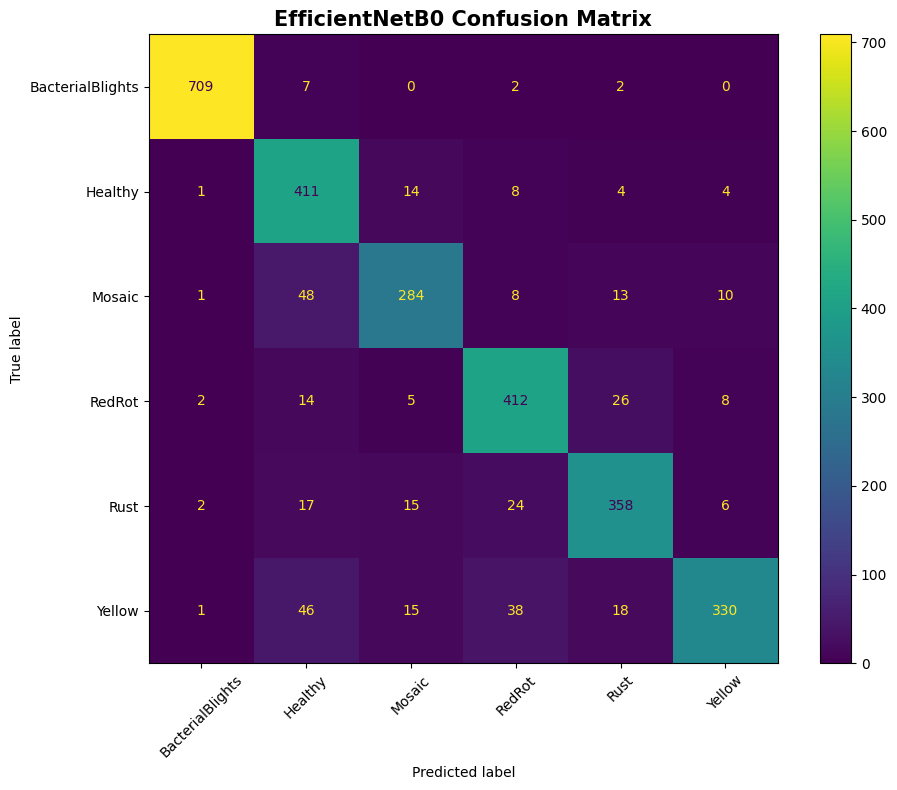

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

efficientnet_cm = confusion_matrix(
    efficientnet_true_labels,
    efficientnet_predicted_labels,
    labels=range(number_of_classes)
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=efficientnet_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

cm_display.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "EfficientNetB0 Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

confusion_matrix_path = (
    efficientnet_output_directory
    / "efficientnet_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
SAMPLES_PER_CLASS = 4
SAMPLE_RANDOM_STATE = 42

selected_class_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    sample_count = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_df = current_class_df.sample(
        n=sample_count,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    selected_class_groups.append(
        sampled_df
    )

selected_samples_df = pd.concat(
    selected_class_groups,
    ignore_index=True
)

print(
    "Selected test images:",
    len(selected_samples_df)
)

Selected test images: 24


In [ ]:
def prepare_image_for_efficientnet(
    image_path
):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    image_array = (
        tf.keras.utils.img_to_array(
            image
        )
    )

    return image_array


selected_image_batch = np.stack([
    prepare_image_for_efficientnet(
        image_path
    )
    for image_path
    in selected_samples_df["filepath"]
])

selected_probabilities = (
    best_efficientnet_model.predict(
        selected_image_batch,
        verbose=1
    )
)

selected_predicted_ids = np.argmax(
    selected_probabilities,
    axis=1
)

selected_confidences = np.max(
    selected_probabilities,
    axis=1
)

selected_samples_df[
    "predicted_id"
] = selected_predicted_ids

selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(prediction_id)]
    for prediction_id
    in selected_predicted_ids
]

selected_samples_df[
    "confidence"
] = selected_confidences

selected_samples_df[
    "correct_prediction"
] = (
    selected_samples_df["label_id"]
    == selected_samples_df["predicted_id"]
)

display(
    selected_samples_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].round(4)
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


,class_name,predicted_class,confidence,correct_prediction
0,BacterialBlights,BacterialBlights,0.9814,True
1,BacterialBlights,BacterialBlights,0.9940,True
2,BacterialBlights,BacterialBlights,0.9968,True
3,BacterialBlights,BacterialBlights,0.9852,True
4,Healthy,Healthy,0.4712,True
5,Healthy,Healthy,0.9570,True
6,Healthy,Healthy,0.9511,True
7,Healthy,Healthy,0.6743,True
8,Mosaic,Mosaic,0.9624,True
9,Mosaic,Healthy,0.5493,False


In [ ]:
prediction_collage_figure, collage_axes = (
    plt.subplots(
        nrows=number_of_classes,
        ncols=SAMPLES_PER_CLASS,
        figsize=(
            4.5 * SAMPLES_PER_CLASS,
            4.2 * number_of_classes
        ),
        squeeze=False
    )
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        selected_samples_df[
            selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample["class_name"]

        predicted_class = sample[
            "predicted_class"
        ]

        confidence_percentage = (
            sample["confidence"] * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_color = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_color,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:
            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise EfficientNetB0 Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

prediction_collage_path = (
    efficientnet_output_directory
    / "efficientnet_prediction_collage.png"
)

plt.savefig(
    prediction_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Prediction collage saved at:",
    prediction_collage_path
)

In [ ]:
efficientnet_test_results_df = (
    test_df.copy()
)

efficientnet_test_results_df[
    "predicted_id"
] = efficientnet_predicted_labels

efficientnet_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(prediction_id)]
    for prediction_id
    in efficientnet_predicted_labels
]

efficientnet_test_results_df[
    "confidence"
] = efficientnet_confidence_scores

efficientnet_test_results_df[
    "correct_prediction"
] = (
    efficientnet_test_results_df["label_id"]
    == efficientnet_test_results_df[
        "predicted_id"
    ]
)

display(
    efficientnet_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10)
)

,class_name,predicted_class,confidence,correct_prediction
0,BacterialBlights,BacterialBlights,0.984913,True
1,BacterialBlights,BacterialBlights,0.999986,True
2,Healthy,Healthy,0.998216,True
3,RedRot,RedRot,0.924324,True
4,Rust,Rust,0.977533,True
5,Mosaic,Mosaic,0.989861,True
6,RedRot,RedRot,0.990847,True
7,Rust,Rust,0.839371,True
8,BacterialBlights,BacterialBlights,0.999968,True
9,BacterialBlights,BacterialBlights,0.999764,True


In [ ]:
efficientnet_classwise_summary = (
    efficientnet_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

efficientnet_classwise_summary[
    "Incorrect_Predictions"
] = (
    efficientnet_classwise_summary[
        "Test_Images"
    ]
    -
    efficientnet_classwise_summary[
        "Correct_Predictions"
    ]
)

efficientnet_classwise_summary[
    "Class_Accuracy"
] = (
    efficientnet_classwise_summary[
        "Correct_Predictions"
    ]
    /
    efficientnet_classwise_summary[
        "Test_Images"
    ]
)

percentage_columns = [
    "Average_Confidence",
    "Minimum_Confidence",
    "Maximum_Confidence",
    "Class_Accuracy"
]

for column_name in percentage_columns:
    efficientnet_classwise_summary[
        column_name
    ] *= 100

efficientnet_classwise_summary = (
    efficientnet_classwise_summary.rename(
        columns={
            "class_name": "Class",

            "Average_Confidence":
                "Average_Confidence_Percentage",

            "Minimum_Confidence":
                "Minimum_Confidence_Percentage",

            "Maximum_Confidence":
                "Maximum_Confidence_Percentage",

            "Class_Accuracy":
                "Class_Accuracy_Percentage"
        }
    )
)

display(
    efficientnet_classwise_summary.round(2)
)

,Class,Test_Images,Correct_Predictions,Average_Confidence_Percentage,Minimum_Confidence_Percentage,Maximum_Confidence_Percentage,Incorrect_Predictions,Class_Accuracy_Percentage
0,BacterialBlights,720,709,96.559998,19.250000,100.000000,11,98.47
1,Healthy,442,411,85.330002,21.959999,100.000000,31,92.99
2,Mosaic,364,284,78.199997,21.690001,99.980003,80,78.02
3,RedRot,467,412,82.320000,22.820000,100.000000,55,88.22
4,Rust,422,358,86.760002,20.879999,100.000000,64,84.83
5,Yellow,448,330,78.900002,22.790001,100.000000,118,73.66


In [ ]:
classwise_summary_path = (
    efficientnet_output_directory
    / "efficientnet_classwise_summary.csv"
)

efficientnet_classwise_summary.to_csv(
    classwise_summary_path,
    index=False
)

print(
    "Class-wise summary saved at:",
    classwise_summary_path
)

Class-wise summary saved at: /content/efficientnet_results/efficientnet_classwise_summary.csv


In [ ]:
final_model_path = (
    efficientnet_output_directory
    / "final_sugarcane_efficientnetb0.keras"
)

best_efficientnet_model.save(
    final_model_path
)

print("Final model saved at:")
print(final_model_path)

Final model saved at:
/content/efficientnet_results/final_sugarcane_efficientnetb0.keras


In [ ]:
test_prediction_path = (
    efficientnet_output_directory
    / "efficientnet_test_predictions.csv"
)

efficientnet_test_results_df.to_csv(
    test_prediction_path,
    index=False
)

print("Test predictions saved at:")
print(test_prediction_path)

Test predictions saved at:
/content/efficientnet_results/efficientnet_test_predictions.csv


## 8. Statistical and calibration comparison: custom CNN vs EfficientNetB0


In [ ]:
!pip install -q statsmodels

Number of classes: 6
Classes: ['BacterialBlights', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Output directory: /content/statistical_calibration_results
Baseline model: Sugarcane_Baseline_CNN
EfficientNet model: Sugarcane_EfficientNetB0

Generating validation predictions...
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step

Generating test predictions...
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step

Prediction arrays are aligned.
Validation images: 2863
Test images: 2863

COMPLETE TEST METRIC COMPARISON


,Metric,Baseline CNN,EfficientNetB0,EfficientNet_Minus_Baseline
0,Accuracy,0.845966,0.874607,0.028641
1,Balanced Accuracy,0.826465,0.860330,0.033865
2,Macro Precision,0.838420,0.868254,0.029834
3,Macro Recall,0.826465,0.860330,0.033865
4,Macro F1,0.826793,0.860723,0.033930
5,Weighted F1,0.844554,0.874256,0.029702
6,Matthews Correlation Coefficient,0.814917,0.849033,0.034116
7,Cohen Kappa,0.812939,0.847781,0.034842
8,Macro ROC-AUC OVR,0.978373,0.986568,0.008194
9,Macro PR-AUC,0.916613,0.944647,0.028034



Generating 2000 stratified bootstrap resamples...
Bootstrap analysis completed.

BOOTSTRAP 95% CONFIDENCE INTERVALS


,Model,Metric,Point_Estimate,CI_95_Lower,CI_95_Upper
0,Baseline CNN,Accuracy,0.845966,0.833042,0.857492
1,EfficientNetB0,Accuracy,0.874607,0.862731,0.886483
2,Baseline CNN,Macro F1,0.826793,0.811904,0.840013
3,EfficientNetB0,Macro F1,0.860723,0.847528,0.874053
4,Baseline CNN,Macro ROC-AUC OVR,0.978373,0.975207,0.981265
5,EfficientNetB0,Macro ROC-AUC OVR,0.986568,0.984437,0.988646
6,Baseline CNN,Negative Log-Likelihood,0.441467,0.408427,0.476898
7,EfficientNetB0,Negative Log-Likelihood,0.333312,0.308060,0.357537
8,Baseline CNN,Multiclass Brier Score,0.214615,0.200083,0.230074
9,EfficientNetB0,Multiclass Brier Score,0.169708,0.157025,0.182195



BOOTSTRAP MODEL-DIFFERENCE ANALYSIS


,Metric,Difference_EfficientNet_Minus_Baseline,CI_95_Lower,CI_95_Upper,Interpretation
0,Accuracy,0.028641,0.015019,0.042962,EfficientNetB0 favoured
1,Macro F1,0.033930,0.018737,0.049932,EfficientNetB0 favoured
2,Macro ROC-AUC OVR,0.008194,0.005558,0.011256,EfficientNetB0 favoured
3,Negative Log-Likelihood,-0.108155,-0.140260,-0.078500,EfficientNetB0 favoured
4,Multiclass Brier Score,-0.044907,-0.059996,-0.031425,EfficientNetB0 favoured
5,Top-label ECE,0.001507,-0.012160,0.012094,No clear difference; 95% CI includes zero


... (6 outputs left out)


CALIBRATION IMPROVEMENT TESTS


,Model,Metric,Mean_Before,Mean_After,After_Minus_Before,Wilcoxon_Statistic,P_Value,Significant_At_0.05
0,Baseline CNN,Negative Log-Likelihood,0.441467,0.434010,-0.007457,912970.0,0.0,True
1,Baseline CNN,Multiclass Brier Loss,0.214615,0.213852,-0.000763,1027886.0,0.0,True
2,EfficientNetB0,Negative Log-Likelihood,0.333312,0.330479,-0.002834,662351.0,0.0,True
3,EfficientNetB0,Multiclass Brier Loss,0.169708,0.168484,-0.001224,804675.0,0.0,True



BOOTSTRAP CIs FOR CALIBRATION CHANGES


,Model,Metric,Difference_After_Minus_Before,CI_95_Lower,CI_95_Upper,Improvement_When_Negative
0,Baseline CNN,Negative Log-Likelihood,-0.007468,-0.012526,-0.002688,True
1,Baseline CNN,Multiclass Brier Score,-0.000772,-0.002264,0.000671,True
2,Baseline CNN,Top-label ECE,-0.002262,-0.012479,0.009812,True
3,EfficientNetB0,Negative Log-Likelihood,-0.002880,-0.006300,0.000541,True
4,EfficientNetB0,Multiclass Brier Score,-0.001237,-0.002299,-0.000144,True
5,EfficientNetB0,Top-label ECE,-0.005263,-0.016045,0.006803,True


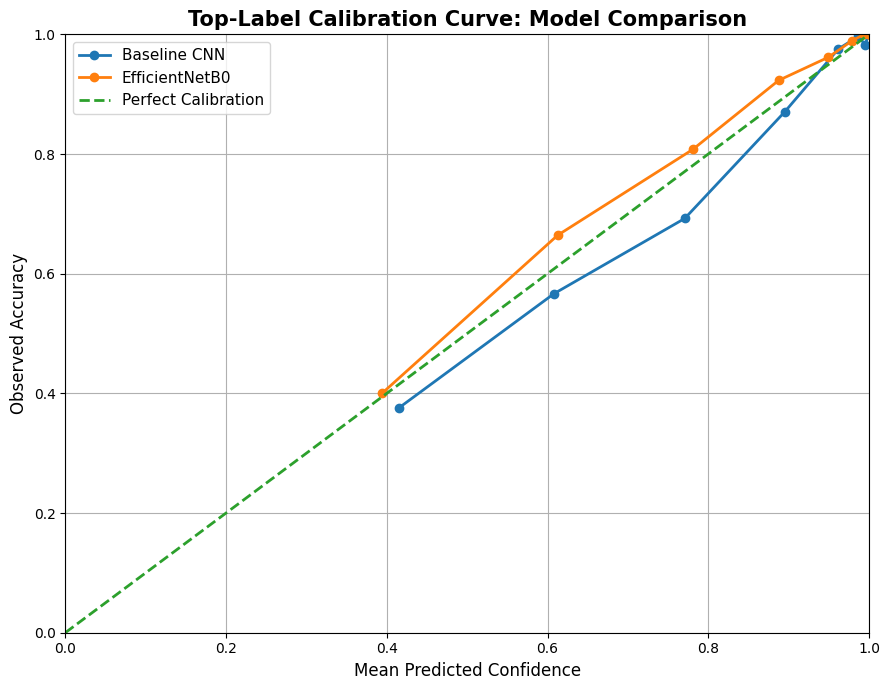

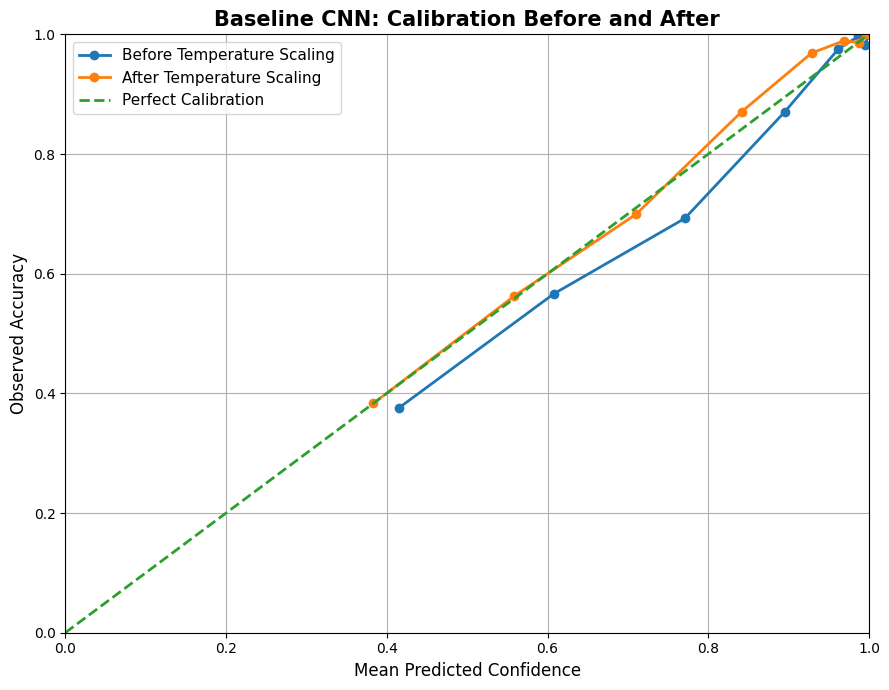

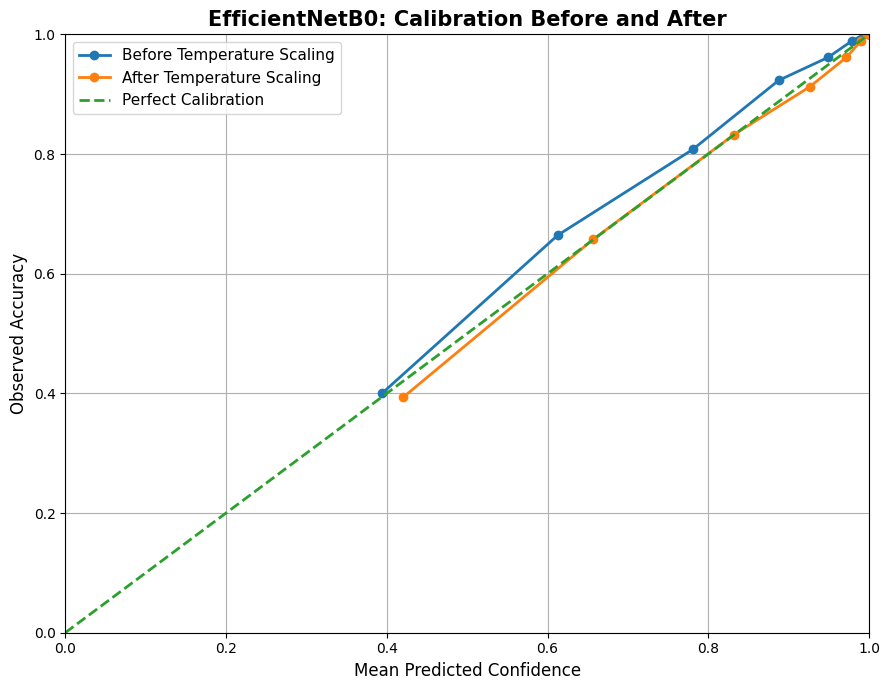

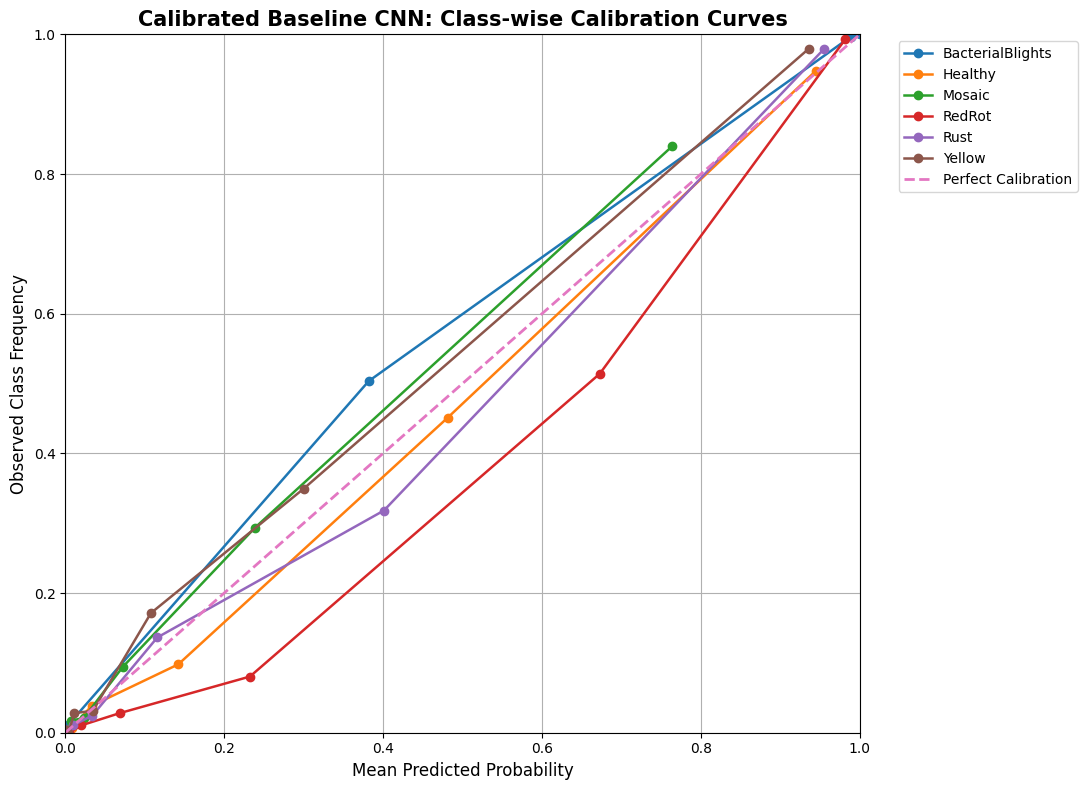

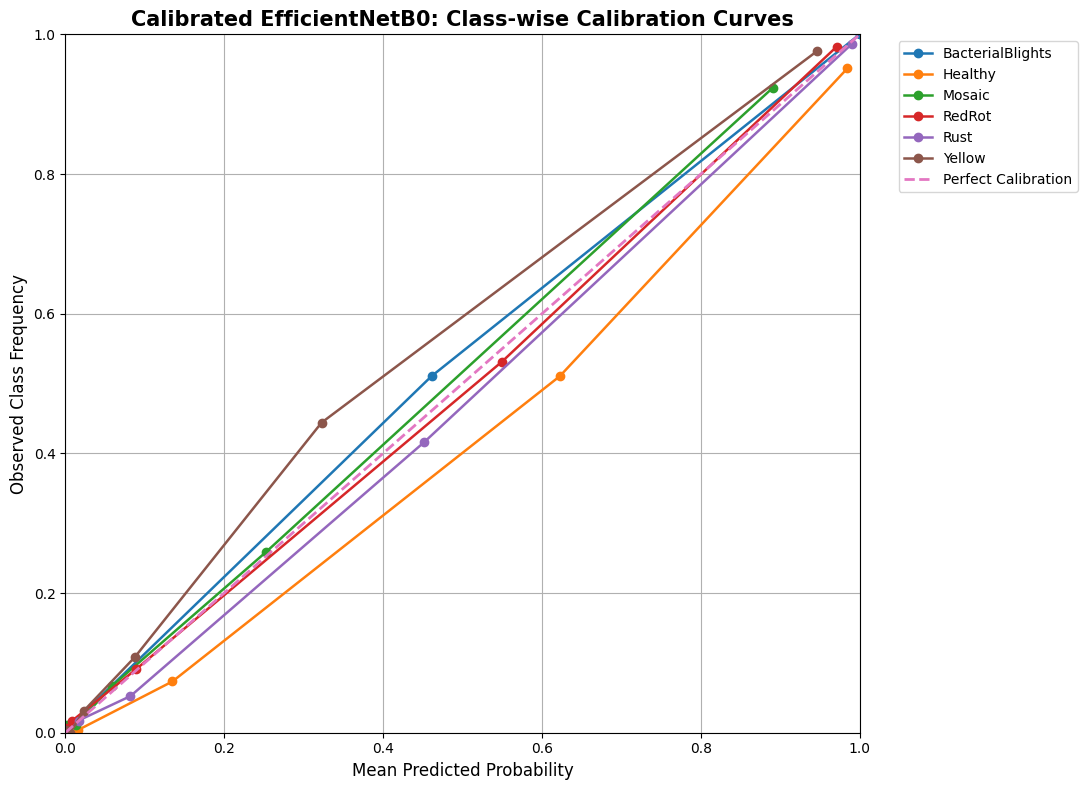


CLASS-WISE CALIBRATION ERRORS


,Model_Stage,Class,One_vs_Rest_ECE,One_vs_Rest_MCE
0,Baseline CNN - Before,BacterialBlights,0.011469,0.552145
1,Baseline CNN - Before,Healthy,0.015747,0.196523
2,Baseline CNN - Before,Mosaic,0.019341,0.177511
3,Baseline CNN - Before,RedRot,0.036377,0.345537
4,Baseline CNN - Before,Rust,0.014261,0.192123
5,Baseline CNN - Before,Yellow,0.019908,0.183528
6,Baseline CNN - After,BacterialBlights,0.014014,0.549109
7,Baseline CNN - After,Healthy,0.009032,0.088252
8,Baseline CNN - After,Mosaic,0.016065,0.203878
9,Baseline CNN - After,RedRot,0.037695,0.306596



TOP-LABEL RELIABILITY BIN TABLE


,Bin,Lower_Bound,Upper_Bound,Sample_Count,Mean_Confidence,Observed_Frequency,Absolute_Gap,Model_Stage
0,1,0.000000,0.530782,287,0.415689,0.376307,0.039383,Baseline CNN - Before
1,2,0.530782,0.691766,286,0.607895,0.566434,0.041462,Baseline CNN - Before
2,3,0.691766,0.845303,286,0.770755,0.692308,0.078448,Baseline CNN - Before
3,4,0.845303,0.938161,286,0.895272,0.870629,0.024643,Baseline CNN - Before
4,5,0.938161,0.978269,287,0.961927,0.975610,0.013682,Baseline CNN - Before
5,6,0.978269,0.992386,286,0.986647,0.996503,0.009857,Baseline CNN - Before
6,7,0.992386,0.997744,286,0.995495,0.982517,0.012978,Baseline CNN - Before
7,8,0.997744,0.999696,286,0.998930,1.000000,0.001070,Baseline CNN - Before
8,9,0.999696,0.999987,286,0.999899,1.000000,0.000101,Baseline CNN - Before
9,10,0.999987,1.000000,287,0.999997,1.000000,0.000003,Baseline CNN - Before


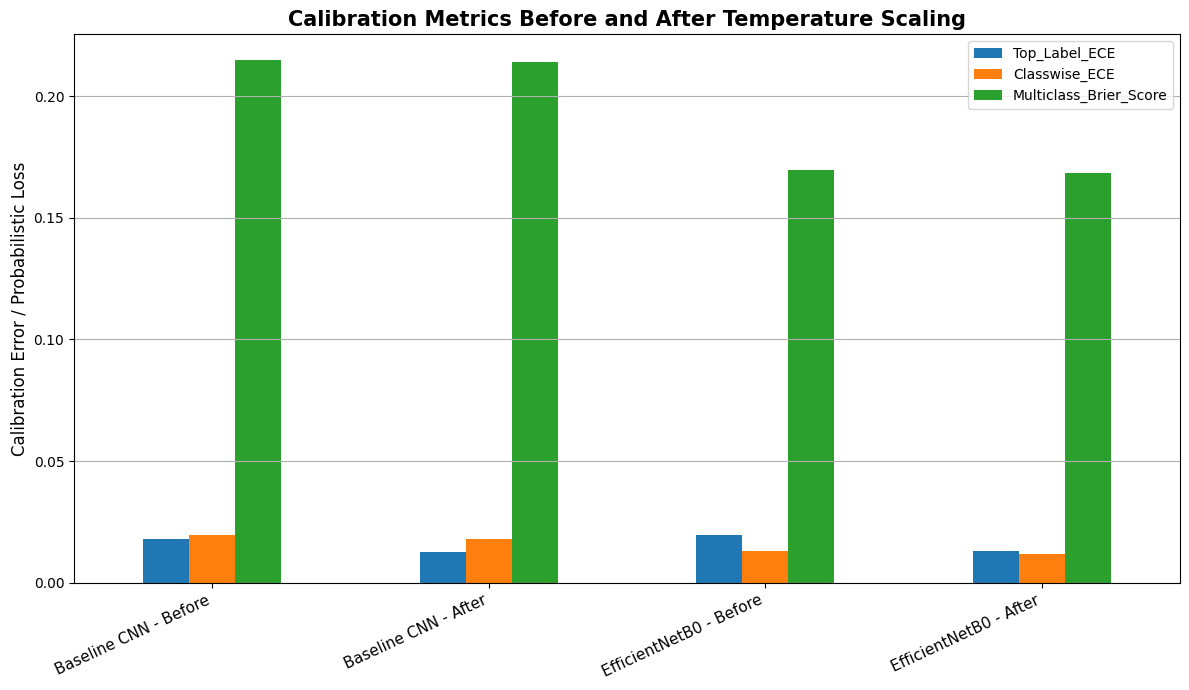

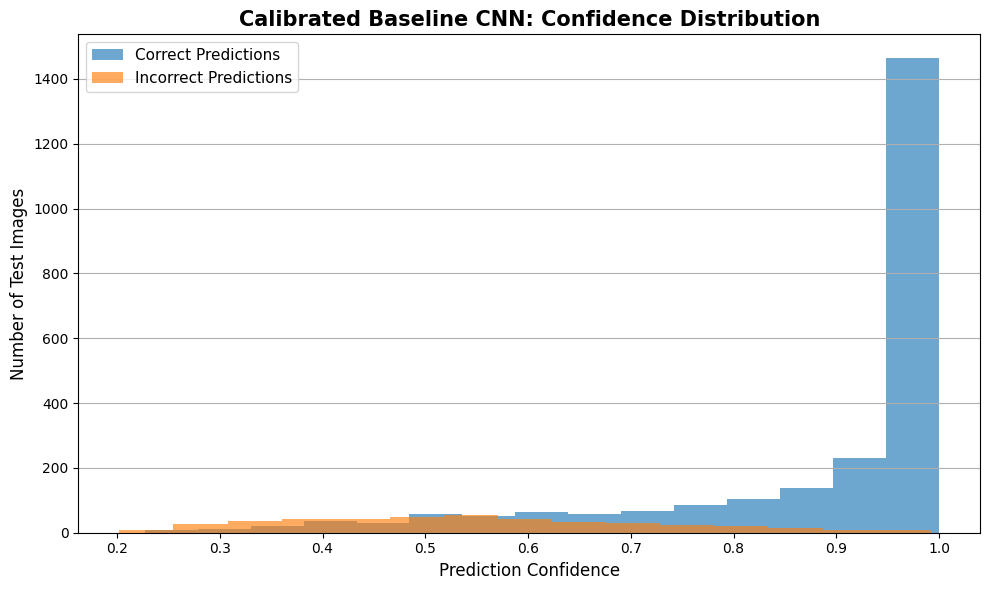

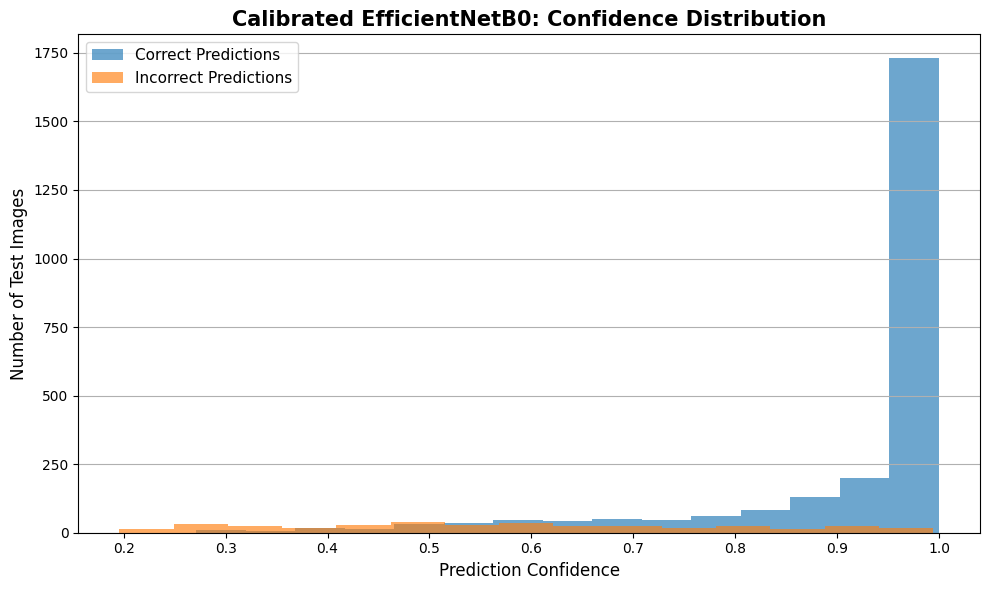


ANALYSIS COMPLETED SUCCESSFULLY
analysis_settings.csv                                       0.000 MB
baseline_calibration_before_after.png                       0.225 MB
baseline_classwise_calibration_curves.png                   0.465 MB
baseline_confidence_distribution.png                        0.125 MB
bootstrap_confidence_intervals.csv                          0.001 MB
bootstrap_model_difference_analysis.csv                     0.001 MB
calibrated_test_predictions.csv                             1.093 MB
calibration_change_bootstrap_ci.csv                         0.001 MB
calibration_improvement_tests.csv                           0.001 MB
calibration_metrics_before_after.csv                        0.001 MB
calibration_metrics_comparison.png                          0.225 MB
classwise_calibration_errors.csv                            0.002 MB
classwise_mcnemar_holm_results.csv                          0.001 MB
complete_metric_comparison.csv                              0.001 MB
e

In [ ]:
# ============================================================
# COMPLETE STATISTICAL AND CALIBRATION ANALYSIS
# Baseline CNN versus EfficientNetB0
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from scipy.optimize import minimize_scalar
from scipy.stats import wilcoxon

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix
)

from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize

from statsmodels.stats.contingency_tables import (
    mcnemar,
    SquareTable
)

from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. General settings
# ------------------------------------------------------------

STATISTICAL_SEED = 42
ALPHA = 0.05

# Increase to 5000 for the final publication analysis
N_BOOTSTRAP = 2000

# Paired sign-flip permutations
N_PERMUTATIONS = 20000

# Number of calibration bins
N_CALIBRATION_BINS = 10

rng = np.random.default_rng(STATISTICAL_SEED)

statistical_output_directory = Path(
    "/content/statistical_calibration_results"
)

statistical_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

print("Number of classes:", number_of_classes)
print("Classes:", class_names)
print("Output directory:", statistical_output_directory)


# ------------------------------------------------------------
# 2. Locate both trained models
# ------------------------------------------------------------

if "baseline_model" not in globals():
    raise NameError(
        "baseline_model is unavailable. Load the trained baseline "
        "CNN before running this analysis."
    )

baseline_eval_model = baseline_model


if "best_efficientnet_model" in globals():
    efficientnet_eval_model = best_efficientnet_model

elif "efficientnet_model" in globals():
    efficientnet_eval_model = efficientnet_model

else:
    raise NameError(
        "Neither best_efficientnet_model nor efficientnet_model "
        "is available."
    )

print("Baseline model:", baseline_eval_model.name)
print("EfficientNet model:", efficientnet_eval_model.name)


# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def collect_dataset_labels(dataset):
    """Collect labels from a deterministic TensorFlow dataset."""

    return np.concatenate([
        batch_labels.numpy()
        for _, batch_labels in dataset
    ]).astype(int)


def normalize_probabilities(probabilities):
    """Clip and normalize probability values safely."""

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )

    probabilities = np.clip(
        probabilities,
        1e-12,
        1.0
    )

    probabilities = (
        probabilities
        / probabilities.sum(
            axis=1,
            keepdims=True
        )
    )

    return probabilities


def multiclass_brier_score(
    true_labels,
    probabilities
):
    """
    Multiclass Brier score.

    Lower values indicate better probabilistic predictions.
    """

    true_one_hot = np.eye(
        probabilities.shape[1]
    )[true_labels]

    sample_brier_losses = np.sum(
        (probabilities - true_one_hot) ** 2,
        axis=1
    )

    return float(
        np.mean(sample_brier_losses)
    )


def per_sample_brier_loss(
    true_labels,
    probabilities
):
    """Return one multiclass Brier loss per image."""

    true_one_hot = np.eye(
        probabilities.shape[1]
    )[true_labels]

    return np.sum(
        (probabilities - true_one_hot) ** 2,
        axis=1
    )


def per_sample_negative_log_likelihood(
    true_labels,
    probabilities
):
    """Return one negative log-likelihood value per image."""

    selected_probabilities = probabilities[
        np.arange(len(true_labels)),
        true_labels
    ]

    selected_probabilities = np.clip(
        selected_probabilities,
        1e-12,
        1.0
    )

    return -np.log(
        selected_probabilities
    )


def binary_calibration_statistics(
    binary_outcomes,
    predicted_probabilities,
    number_of_bins=10,
    strategy="uniform"
):
    """
    Calculate ECE, MCE and calibration-bin information.

    binary_outcomes:
        0/1 observed outcome.

    predicted_probabilities:
        Predicted probability of outcome 1.
    """

    binary_outcomes = np.asarray(
        binary_outcomes,
        dtype=int
    )

    predicted_probabilities = np.clip(
        np.asarray(
            predicted_probabilities,
            dtype=float
        ),
        0.0,
        1.0
    )

    if strategy == "quantile":

        bin_edges = np.quantile(
            predicted_probabilities,
            np.linspace(
                0,
                1,
                number_of_bins + 1
            )
        )

        bin_edges[0] = 0.0
        bin_edges[-1] = 1.0

        bin_edges = np.unique(
            bin_edges
        )

        if len(bin_edges) < 2:
            bin_edges = np.array(
                [0.0, 1.0]
            )

    else:

        bin_edges = np.linspace(
            0.0,
            1.0,
            number_of_bins + 1
        )

    bin_ids = np.digitize(
        predicted_probabilities,
        bin_edges[1:-1],
        right=True
    )

    bin_records = []

    expected_calibration_error = 0.0
    maximum_calibration_error = 0.0

    total_samples = len(
        predicted_probabilities
    )

    for bin_index in range(
        len(bin_edges) - 1
    ):

        bin_mask = (
            bin_ids == bin_index
        )

        bin_count = int(
            np.sum(bin_mask)
        )

        if bin_count == 0:
            continue

        mean_confidence = float(
            np.mean(
                predicted_probabilities[
                    bin_mask
                ]
            )
        )

        observed_frequency = float(
            np.mean(
                binary_outcomes[
                    bin_mask
                ]
            )
        )

        calibration_gap = abs(
            observed_frequency
            - mean_confidence
        )

        bin_weight = (
            bin_count
            / total_samples
        )

        expected_calibration_error += (
            bin_weight
            * calibration_gap
        )

        maximum_calibration_error = max(
            maximum_calibration_error,
            calibration_gap
        )

        bin_records.append({
            "Bin": bin_index + 1,
            "Lower_Bound":
                bin_edges[bin_index],
            "Upper_Bound":
                bin_edges[bin_index + 1],
            "Sample_Count":
                bin_count,
            "Mean_Confidence":
                mean_confidence,
            "Observed_Frequency":
                observed_frequency,
            "Absolute_Gap":
                calibration_gap
        })

    bin_table = pd.DataFrame(
        bin_records
    )

    return (
        float(expected_calibration_error),
        float(maximum_calibration_error),
        bin_table
    )


def top_label_calibration_statistics(
    true_labels,
    probabilities,
    number_of_bins=10,
    strategy="uniform"
):
    """
    Calibration of the probability assigned to the predicted class.
    """

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    predicted_confidences = np.max(
        probabilities,
        axis=1
    )

    correctness = (
        predicted_labels == true_labels
    ).astype(int)

    return binary_calibration_statistics(
        correctness,
        predicted_confidences,
        number_of_bins=number_of_bins,
        strategy=strategy
    )


def classwise_ece(
    true_labels,
    probabilities,
    number_of_bins=10
):
    """Mean one-vs-rest ECE across all classes."""

    class_ece_values = []

    for class_id in range(
        probabilities.shape[1]
    ):

        binary_labels = (
            true_labels == class_id
        ).astype(int)

        current_ece, _, _ = (
            binary_calibration_statistics(
                binary_labels,
                probabilities[:, class_id],
                number_of_bins=number_of_bins,
                strategy="uniform"
            )
        )

        class_ece_values.append(
            current_ece
        )

    return float(
        np.mean(class_ece_values)
    )


def evaluate_probability_model(
    true_labels,
    probabilities
):
    """Calculate complete classification and calibration metrics."""

    probabilities = normalize_probabilities(
        probabilities
    )

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    true_one_hot = np.eye(
        probabilities.shape[1]
    )[true_labels]

    uniform_ece, mce, _ = (
        top_label_calibration_statistics(
            true_labels,
            probabilities,
            number_of_bins=N_CALIBRATION_BINS,
            strategy="uniform"
        )
    )

    adaptive_ece, _, _ = (
        top_label_calibration_statistics(
            true_labels,
            probabilities,
            number_of_bins=N_CALIBRATION_BINS,
            strategy="quantile"
        )
    )

    return {
        "Accuracy":
            accuracy_score(
                true_labels,
                predicted_labels
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                true_labels,
                predicted_labels
            ),

        "Macro Precision":
            precision_score(
                true_labels,
                predicted_labels,
                average="macro",
                zero_division=0
            ),

        "Macro Recall":
            recall_score(
                true_labels,
                predicted_labels,
                average="macro",
                zero_division=0
            ),

        "Macro F1":
            f1_score(
                true_labels,
                predicted_labels,
                average="macro",
                zero_division=0
            ),

        "Weighted F1":
            f1_score(
                true_labels,
                predicted_labels,
                average="weighted",
                zero_division=0
            ),

        "Matthews Correlation Coefficient":
            matthews_corrcoef(
                true_labels,
                predicted_labels
            ),

        "Cohen Kappa":
            cohen_kappa_score(
                true_labels,
                predicted_labels
            ),

        "Macro ROC-AUC OVR":
            roc_auc_score(
                true_labels,
                probabilities,
                multi_class="ovr",
                average="macro"
            ),

        "Macro PR-AUC":
            average_precision_score(
                true_one_hot,
                probabilities,
                average="macro"
            ),

        "Negative Log-Likelihood":
            log_loss(
                true_labels,
                probabilities,
                labels=all_class_ids
            ),

        "Multiclass Brier Score":
            multiclass_brier_score(
                true_labels,
                probabilities
            ),

        "Top-label ECE":
            uniform_ece,

        "Adaptive ECE":
            adaptive_ece,

        "Top-label MCE":
            mce,

        "Classwise ECE":
            classwise_ece(
                true_labels,
                probabilities,
                number_of_bins=N_CALIBRATION_BINS
            )
    }


def safe_wilcoxon(
    first_values,
    second_values
):
    """Run paired Wilcoxon safely when differences may all be zero."""

    first_values = np.asarray(
        first_values,
        dtype=float
    )

    second_values = np.asarray(
        second_values,
        dtype=float
    )

    differences = (
        first_values
        - second_values
    )

    if np.allclose(
        differences,
        0
    ):
        return 0.0, 1.0

    result = wilcoxon(
        first_values,
        second_values,
        alternative="two-sided",
        zero_method="pratt",
        method="auto"
    )

    return (
        float(result.statistic),
        float(result.pvalue)
    )


def stratified_bootstrap_indices(
    true_labels,
    random_generator
):
    """Bootstrap within each class to retain class distribution."""

    sampled_indices = []

    for class_id in np.unique(
        true_labels
    ):

        class_indices = np.where(
            true_labels == class_id
        )[0]

        current_sample = (
            random_generator.choice(
                class_indices,
                size=len(class_indices),
                replace=True
            )
        )

        sampled_indices.append(
            current_sample
        )

    combined_indices = np.concatenate(
        sampled_indices
    )

    random_generator.shuffle(
        combined_indices
    )

    return combined_indices


def bootstrap_metric_vector(
    true_labels,
    probabilities
):
    """Reduced metric vector for bootstrap analysis."""

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    uniform_ece, _, _ = (
        top_label_calibration_statistics(
            true_labels,
            probabilities,
            number_of_bins=N_CALIBRATION_BINS,
            strategy="uniform"
        )
    )

    return np.array([
        accuracy_score(
            true_labels,
            predicted_labels
        ),

        f1_score(
            true_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        ),

        roc_auc_score(
            true_labels,
            probabilities,
            multi_class="ovr",
            average="macro"
        ),

        log_loss(
            true_labels,
            probabilities,
            labels=all_class_ids
        ),

        multiclass_brier_score(
            true_labels,
            probabilities
        ),

        uniform_ece
    ])


def paired_sign_flip_test(
    paired_differences,
    number_of_permutations=20000,
    seed=42
):
    """
    Paired random sign-flip permutation test.

    Suitable for testing whether the mean paired difference is zero.
    """

    paired_differences = np.asarray(
        paired_differences,
        dtype=float
    )

    observed_statistic = float(
        np.mean(
            paired_differences
        )
    )

    random_generator = np.random.default_rng(
        seed
    )

    exceedance_count = 0
    generated = 0
    batch_size = 1000

    while generated < number_of_permutations:

        current_batch_size = min(
            batch_size,
            number_of_permutations - generated
        )

        random_signs = random_generator.choice(
            [-1.0, 1.0],
            size=(
                current_batch_size,
                len(paired_differences)
            )
        )

        permutation_statistics = np.mean(
            random_signs
            * paired_differences,
            axis=1
        )

        exceedance_count += np.sum(
            np.abs(
                permutation_statistics
            )
            >= abs(observed_statistic)
        )

        generated += current_batch_size

    p_value = (
        exceedance_count + 1
    ) / (
        number_of_permutations + 1
    )

    return (
        observed_statistic,
        float(p_value)
    )


def temperature_scale_probabilities(
    probabilities,
    temperature
):
    """
    Apply temperature scaling to softmax probabilities.

    T > 1 generally softens probabilities.
    T < 1 generally sharpens probabilities.
    """

    probabilities = normalize_probabilities(
        probabilities
    )

    log_probabilities = np.log(
        np.clip(
            probabilities,
            1e-12,
            1.0
        )
    )

    scaled_log_probabilities = (
        log_probabilities
        / temperature
    )

    scaled_log_probabilities -= np.max(
        scaled_log_probabilities,
        axis=1,
        keepdims=True
    )

    exponentiated_values = np.exp(
        scaled_log_probabilities
    )

    calibrated_probabilities = (
        exponentiated_values
        / exponentiated_values.sum(
            axis=1,
            keepdims=True
        )
    )

    return calibrated_probabilities


def fit_temperature(
    validation_labels,
    validation_probabilities
):
    """Select temperature by minimizing validation log loss."""

    def objective(log_temperature):

        temperature = np.exp(
            log_temperature
        )

        calibrated_validation_probabilities = (
            temperature_scale_probabilities(
                validation_probabilities,
                temperature
            )
        )

        return log_loss(
            validation_labels,
            calibrated_validation_probabilities,
            labels=all_class_ids
        )

    optimization_result = minimize_scalar(
        objective,
        bounds=(
            np.log(0.05),
            np.log(10.0)
        ),
        method="bounded",
        options={
            "xatol": 1e-6
        }
    )

    selected_temperature = float(
        np.exp(
            optimization_result.x
        )
    )

    return (
        selected_temperature,
        float(optimization_result.fun)
    )


# ------------------------------------------------------------
# 4. Obtain validation and test probabilities
# ------------------------------------------------------------

print("\nGenerating validation predictions...")

validation_true_labels = collect_dataset_labels(
    validation_dataset
)

baseline_validation_probabilities = (
    normalize_probabilities(
        baseline_eval_model.predict(
            validation_dataset,
            verbose=1
        )
    )
)

efficientnet_validation_probabilities = (
    normalize_probabilities(
        efficientnet_eval_model.predict(
            validation_dataset,
            verbose=1
        )
    )
)


print("\nGenerating test predictions...")

test_true_labels = collect_dataset_labels(
    test_dataset
)

baseline_test_probabilities = (
    normalize_probabilities(
        baseline_eval_model.predict(
            test_dataset,
            verbose=1
        )
    )
)

efficientnet_test_probabilities = (
    normalize_probabilities(
        efficientnet_eval_model.predict(
            test_dataset,
            verbose=1
        )
    )
)


if not (
    len(test_true_labels)
    == len(baseline_test_probabilities)
    == len(efficientnet_test_probabilities)
):
    raise ValueError(
        "The test labels and prediction arrays have "
        "different lengths."
    )

if not np.array_equal(
    validation_true_labels,
    collect_dataset_labels(
        validation_dataset
    )
):
    raise ValueError(
        "Validation dataset order is not deterministic."
    )

print("\nPrediction arrays are aligned.")
print("Validation images:", len(validation_true_labels))
print("Test images:", len(test_true_labels))


baseline_test_predictions = np.argmax(
    baseline_test_probabilities,
    axis=1
)

efficientnet_test_predictions = np.argmax(
    efficientnet_test_probabilities,
    axis=1
)


# ------------------------------------------------------------
# 5. Complete uncalibrated metric comparison
# ------------------------------------------------------------

baseline_metrics = evaluate_probability_model(
    test_true_labels,
    baseline_test_probabilities
)

efficientnet_metrics = evaluate_probability_model(
    test_true_labels,
    efficientnet_test_probabilities
)

complete_metric_comparison = pd.DataFrame({
    "Metric": list(
        baseline_metrics.keys()
    ),

    "Baseline CNN": list(
        baseline_metrics.values()
    ),

    "EfficientNetB0": [
        efficientnet_metrics[
            metric_name
        ]
        for metric_name in baseline_metrics.keys()
    ]
})

complete_metric_comparison[
    "EfficientNet_Minus_Baseline"
] = (
    complete_metric_comparison[
        "EfficientNetB0"
    ]
    -
    complete_metric_comparison[
        "Baseline CNN"
    ]
)

print("\nCOMPLETE TEST METRIC COMPARISON")
display(
    complete_metric_comparison.round(6)
)

complete_metric_comparison.to_csv(
    statistical_output_directory
    / "complete_metric_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 6. Create shared stratified bootstrap samples
# ------------------------------------------------------------

print(
    f"\nGenerating {N_BOOTSTRAP} "
    "stratified bootstrap resamples..."
)

bootstrap_indices_collection = [
    stratified_bootstrap_indices(
        test_true_labels,
        rng
    )
    for _ in range(N_BOOTSTRAP)
]

bootstrap_metric_names = [
    "Accuracy",
    "Macro F1",
    "Macro ROC-AUC OVR",
    "Negative Log-Likelihood",
    "Multiclass Brier Score",
    "Top-label ECE"
]

baseline_bootstrap_metrics = np.zeros(
    (
        N_BOOTSTRAP,
        len(bootstrap_metric_names)
    )
)

efficientnet_bootstrap_metrics = np.zeros_like(
    baseline_bootstrap_metrics
)

for bootstrap_index, sampled_indices in enumerate(
    bootstrap_indices_collection
):

    sampled_labels = test_true_labels[
        sampled_indices
    ]

    baseline_bootstrap_metrics[
        bootstrap_index
    ] = bootstrap_metric_vector(
        sampled_labels,
        baseline_test_probabilities[
            sampled_indices
        ]
    )

    efficientnet_bootstrap_metrics[
        bootstrap_index
    ] = bootstrap_metric_vector(
        sampled_labels,
        efficientnet_test_probabilities[
            sampled_indices
        ]
    )

print("Bootstrap analysis completed.")


# ------------------------------------------------------------
# 7. Bootstrap confidence intervals for each model
# ------------------------------------------------------------

bootstrap_ci_records = []

baseline_point_vector = bootstrap_metric_vector(
    test_true_labels,
    baseline_test_probabilities
)

efficientnet_point_vector = bootstrap_metric_vector(
    test_true_labels,
    efficientnet_test_probabilities
)

for metric_index, metric_name in enumerate(
    bootstrap_metric_names
):

    for (
        model_name,
        point_vector,
        bootstrap_values
    ) in [
        (
            "Baseline CNN",
            baseline_point_vector,
            baseline_bootstrap_metrics
        ),
        (
            "EfficientNetB0",
            efficientnet_point_vector,
            efficientnet_bootstrap_metrics
        )
    ]:

        lower_ci, upper_ci = np.percentile(
            bootstrap_values[
                :, metric_index
            ],
            [2.5, 97.5]
        )

        bootstrap_ci_records.append({
            "Model": model_name,
            "Metric": metric_name,
            "Point_Estimate":
                point_vector[metric_index],
            "CI_95_Lower":
                lower_ci,
            "CI_95_Upper":
                upper_ci
        })

bootstrap_confidence_intervals = pd.DataFrame(
    bootstrap_ci_records
)

print("\nBOOTSTRAP 95% CONFIDENCE INTERVALS")
display(
    bootstrap_confidence_intervals.round(6)
)

bootstrap_confidence_intervals.to_csv(
    statistical_output_directory
    / "bootstrap_confidence_intervals.csv",
    index=False
)


# ------------------------------------------------------------
# 8. Bootstrap confidence intervals for model differences
# ------------------------------------------------------------

bootstrap_difference_values = (
    efficientnet_bootstrap_metrics
    -
    baseline_bootstrap_metrics
)

point_differences = (
    efficientnet_point_vector
    -
    baseline_point_vector
)

higher_is_better_metrics = {
    "Accuracy",
    "Macro F1",
    "Macro ROC-AUC OVR"
}

difference_records = []

for metric_index, metric_name in enumerate(
    bootstrap_metric_names
):

    lower_difference, upper_difference = np.percentile(
        bootstrap_difference_values[
            :, metric_index
        ],
        [2.5, 97.5]
    )

    point_difference = (
        point_differences[
            metric_index
        ]
    )

    ci_includes_zero = (
        lower_difference <= 0
        <= upper_difference
    )

    if ci_includes_zero:
        interpretation = (
            "No clear difference; "
            "95% CI includes zero"
        )

    elif metric_name in higher_is_better_metrics:

        interpretation = (
            "EfficientNetB0 favoured"
            if point_difference > 0
            else "Baseline CNN favoured"
        )

    else:

        interpretation = (
            "EfficientNetB0 favoured"
            if point_difference < 0
            else "Baseline CNN favoured"
        )

    difference_records.append({
        "Metric": metric_name,
        "Difference_EfficientNet_Minus_Baseline":
            point_difference,
        "CI_95_Lower":
            lower_difference,
        "CI_95_Upper":
            upper_difference,
        "Interpretation":
            interpretation
    })

bootstrap_model_difference_table = pd.DataFrame(
    difference_records
)

print("\nBOOTSTRAP MODEL-DIFFERENCE ANALYSIS")
display(
    bootstrap_model_difference_table.round(6)
)

bootstrap_model_difference_table.to_csv(
    statistical_output_directory
    / "bootstrap_model_difference_analysis.csv",
    index=False
)


# ------------------------------------------------------------
# 9. McNemar exact test
# ------------------------------------------------------------

baseline_correct = (
    baseline_test_predictions
    == test_true_labels
)

efficientnet_correct = (
    efficientnet_test_predictions
    == test_true_labels
)

both_correct = int(
    np.sum(
        baseline_correct
        & efficientnet_correct
    )
)

baseline_only_correct = int(
    np.sum(
        baseline_correct
        & ~efficientnet_correct
    )
)

efficientnet_only_correct = int(
    np.sum(
        ~baseline_correct
        & efficientnet_correct
    )
)

both_incorrect = int(
    np.sum(
        ~baseline_correct
        & ~efficientnet_correct
    )
)

mcnemar_table = np.array([
    [
        both_correct,
        baseline_only_correct
    ],
    [
        efficientnet_only_correct,
        both_incorrect
    ]
])

mcnemar_result = mcnemar(
    mcnemar_table,
    exact=True
)

print("\nMCNEMAR CONTINGENCY TABLE")
print(mcnemar_table)

print(
    "Exact McNemar statistic:",
    mcnemar_result.statistic
)

print(
    "Exact McNemar p-value:",
    mcnemar_result.pvalue
)


# ------------------------------------------------------------
# 10. Paired permutation test for accuracy difference
# ------------------------------------------------------------

paired_correctness_difference = (
    efficientnet_correct.astype(float)
    -
    baseline_correct.astype(float)
)

(
    observed_accuracy_difference,
    permutation_accuracy_p_value
) = paired_sign_flip_test(
    paired_correctness_difference,
    number_of_permutations=N_PERMUTATIONS,
    seed=STATISTICAL_SEED
)

print("\nPAIRED PERMUTATION TEST FOR ACCURACY")
print(
    "Observed EfficientNet - Baseline accuracy:",
    observed_accuracy_difference
)

print(
    "Permutation p-value:",
    permutation_accuracy_p_value
)


# ------------------------------------------------------------
# 11. Wilcoxon tests for paired probabilistic losses
# ------------------------------------------------------------

baseline_sample_nll = (
    per_sample_negative_log_likelihood(
        test_true_labels,
        baseline_test_probabilities
    )
)

efficientnet_sample_nll = (
    per_sample_negative_log_likelihood(
        test_true_labels,
        efficientnet_test_probabilities
    )
)

nll_wilcoxon_statistic, nll_wilcoxon_p = (
    safe_wilcoxon(
        efficientnet_sample_nll,
        baseline_sample_nll
    )
)


baseline_sample_brier = (
    per_sample_brier_loss(
        test_true_labels,
        baseline_test_probabilities
    )
)

efficientnet_sample_brier = (
    per_sample_brier_loss(
        test_true_labels,
        efficientnet_test_probabilities
    )
)

brier_wilcoxon_statistic, brier_wilcoxon_p = (
    safe_wilcoxon(
        efficientnet_sample_brier,
        baseline_sample_brier
    )
)


# ------------------------------------------------------------
# 12. Optional Bowker symmetry test
# ------------------------------------------------------------

prediction_disagreement_table = confusion_matrix(
    baseline_test_predictions,
    efficientnet_test_predictions,
    labels=all_class_ids
)

try:
    bowker_result = SquareTable(
        prediction_disagreement_table,
        shift_zeros=True
    ).symmetry(
        method="bowker"
    )

    bowker_statistic = float(
        bowker_result.statistic
    )

    bowker_p_value = float(
        bowker_result.pvalue
    )

except Exception as error:

    bowker_statistic = np.nan
    bowker_p_value = np.nan

    print(
        "Bowker test could not be calculated:",
        error
    )


# ------------------------------------------------------------
# 13. Statistical test summary
# ------------------------------------------------------------

statistical_test_summary = pd.DataFrame([
    {
        "Test":
            "Exact McNemar Test",
        "Comparison":
            "Paired correct/incorrect predictions",
        "Statistic":
            float(mcnemar_result.statistic),
        "P_Value":
            float(mcnemar_result.pvalue),
        "Significant_At_0.05":
            mcnemar_result.pvalue < ALPHA
    },

    {
        "Test":
            "Paired Sign-Flip Permutation Test",
        "Comparison":
            "Accuracy difference",
        "Statistic":
            observed_accuracy_difference,
        "P_Value":
            permutation_accuracy_p_value,
        "Significant_At_0.05":
            permutation_accuracy_p_value < ALPHA
    },

    {
        "Test":
            "Wilcoxon Signed-Rank Test",
        "Comparison":
            "Per-image negative log-likelihood",
        "Statistic":
            nll_wilcoxon_statistic,
        "P_Value":
            nll_wilcoxon_p,
        "Significant_At_0.05":
            nll_wilcoxon_p < ALPHA
    },

    {
        "Test":
            "Wilcoxon Signed-Rank Test",
        "Comparison":
            "Per-image multiclass Brier loss",
        "Statistic":
            brier_wilcoxon_statistic,
        "P_Value":
            brier_wilcoxon_p,
        "Significant_At_0.05":
            brier_wilcoxon_p < ALPHA
    },

    {
        "Test":
            "Bowker Symmetry Test",
        "Comparison":
            "Multiclass prediction disagreement pattern",
        "Statistic":
            bowker_statistic,
        "P_Value":
            bowker_p_value,
        "Significant_At_0.05":
            (
                bowker_p_value < ALPHA
                if not np.isnan(
                    bowker_p_value
                )
                else False
            )
    }
])

print("\nSTATISTICAL TEST SUMMARY")
display(
    statistical_test_summary.round(6)
)

statistical_test_summary.to_csv(
    statistical_output_directory
    / "statistical_test_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 14. Class-wise exact McNemar tests with Holm correction
# ------------------------------------------------------------

classwise_test_records = []

for class_id, class_name in enumerate(
    class_names
):

    class_mask = (
        test_true_labels == class_id
    )

    current_baseline_correct = (
        baseline_test_predictions[
            class_mask
        ] == class_id
    )

    current_efficientnet_correct = (
        efficientnet_test_predictions[
            class_mask
        ] == class_id
    )

    class_both_correct = int(
        np.sum(
            current_baseline_correct
            & current_efficientnet_correct
        )
    )

    class_baseline_only = int(
        np.sum(
            current_baseline_correct
            & ~current_efficientnet_correct
        )
    )

    class_efficientnet_only = int(
        np.sum(
            ~current_baseline_correct
            & current_efficientnet_correct
        )
    )

    class_both_incorrect = int(
        np.sum(
            ~current_baseline_correct
            & ~current_efficientnet_correct
        )
    )

    class_table = np.array([
        [
            class_both_correct,
            class_baseline_only
        ],
        [
            class_efficientnet_only,
            class_both_incorrect
        ]
    ])

    discordant_total = (
        class_baseline_only
        + class_efficientnet_only
    )

    if discordant_total == 0:
        class_p_value = 1.0
        class_statistic = 0.0

    else:
        current_result = mcnemar(
            class_table,
            exact=True
        )

        class_statistic = float(
            current_result.statistic
        )

        class_p_value = float(
            current_result.pvalue
        )

    classwise_test_records.append({
        "Class": class_name,
        "Test_Images":
            int(np.sum(class_mask)),
        "Baseline_Class_Accuracy":
            float(
                np.mean(
                    current_baseline_correct
                )
            ),
        "EfficientNet_Class_Accuracy":
            float(
                np.mean(
                    current_efficientnet_correct
                )
            ),
        "Accuracy_Difference":
            float(
                np.mean(
                    current_efficientnet_correct
                )
                -
                np.mean(
                    current_baseline_correct
                )
            ),
        "Baseline_Only_Correct":
            class_baseline_only,
        "EfficientNet_Only_Correct":
            class_efficientnet_only,
        "McNemar_Statistic":
            class_statistic,
        "Raw_P_Value":
            class_p_value
    })

classwise_mcnemar_results = pd.DataFrame(
    classwise_test_records
)

holm_decisions, holm_p_values, _, _ = (
    multipletests(
        classwise_mcnemar_results[
            "Raw_P_Value"
        ],
        alpha=ALPHA,
        method="holm"
    )
)

classwise_mcnemar_results[
    "Holm_Adjusted_P_Value"
] = holm_p_values

classwise_mcnemar_results[
    "Significant_After_Holm"
] = holm_decisions

print("\nCLASS-WISE McNEMAR TESTS")
display(
    classwise_mcnemar_results.round(6)
)

classwise_mcnemar_results.to_csv(
    statistical_output_directory
    / "classwise_mcnemar_holm_results.csv",
    index=False
)


# ------------------------------------------------------------
# 15. Fit temperature scaling on validation data only
# ------------------------------------------------------------

(
    baseline_temperature,
    baseline_calibrated_validation_nll
) = fit_temperature(
    validation_true_labels,
    baseline_validation_probabilities
)

(
    efficientnet_temperature,
    efficientnet_calibrated_validation_nll
) = fit_temperature(
    validation_true_labels,
    efficientnet_validation_probabilities
)

print("\nTEMPERATURE SCALING")
print(
    f"Baseline selected temperature: "
    f"{baseline_temperature:.6f}"
)

print(
    f"EfficientNet selected temperature: "
    f"{efficientnet_temperature:.6f}"
)


baseline_calibrated_test_probabilities = (
    temperature_scale_probabilities(
        baseline_test_probabilities,
        baseline_temperature
    )
)

efficientnet_calibrated_test_probabilities = (
    temperature_scale_probabilities(
        efficientnet_test_probabilities,
        efficientnet_temperature
    )
)


# ------------------------------------------------------------
# 16. Calibration metrics before and after temperature scaling
# ------------------------------------------------------------

calibration_probability_sets = {
    "Baseline CNN - Before":
        baseline_test_probabilities,

    "Baseline CNN - After":
        baseline_calibrated_test_probabilities,

    "EfficientNetB0 - Before":
        efficientnet_test_probabilities,

    "EfficientNetB0 - After":
        efficientnet_calibrated_test_probabilities
}

calibration_metric_records = []

for model_stage, probabilities in (
    calibration_probability_sets.items()
):

    current_metrics = (
        evaluate_probability_model(
            test_true_labels,
            probabilities
        )
    )

    calibration_metric_records.append({
        "Model_Stage":
            model_stage,
        "Accuracy":
            current_metrics["Accuracy"],
        "Negative_Log_Likelihood":
            current_metrics[
                "Negative Log-Likelihood"
            ],
        "Multiclass_Brier_Score":
            current_metrics[
                "Multiclass Brier Score"
            ],
        "Top_Label_ECE":
            current_metrics[
                "Top-label ECE"
            ],
        "Adaptive_ECE":
            current_metrics[
                "Adaptive ECE"
            ],
        "Top_Label_MCE":
            current_metrics[
                "Top-label MCE"
            ],
        "Classwise_ECE":
            current_metrics[
                "Classwise ECE"
            ]
    })

calibration_metric_comparison = pd.DataFrame(
    calibration_metric_records
)

print("\nCALIBRATION METRICS BEFORE AND AFTER")
display(
    calibration_metric_comparison.round(6)
)

calibration_metric_comparison.to_csv(
    statistical_output_directory
    / "calibration_metrics_before_after.csv",
    index=False
)


# ------------------------------------------------------------
# 17. Statistical tests for calibration improvement
# ------------------------------------------------------------

calibration_test_records = []

for model_name, original_probs, calibrated_probs in [
    (
        "Baseline CNN",
        baseline_test_probabilities,
        baseline_calibrated_test_probabilities
    ),
    (
        "EfficientNetB0",
        efficientnet_test_probabilities,
        efficientnet_calibrated_test_probabilities
    )
]:

    original_nll = (
        per_sample_negative_log_likelihood(
            test_true_labels,
            original_probs
        )
    )

    calibrated_nll = (
        per_sample_negative_log_likelihood(
            test_true_labels,
            calibrated_probs
        )
    )

    nll_statistic, nll_p_value = (
        safe_wilcoxon(
            calibrated_nll,
            original_nll
        )
    )

    original_brier = (
        per_sample_brier_loss(
            test_true_labels,
            original_probs
        )
    )

    calibrated_brier = (
        per_sample_brier_loss(
            test_true_labels,
            calibrated_probs
        )
    )

    brier_statistic, brier_p_value = (
        safe_wilcoxon(
            calibrated_brier,
            original_brier
        )
    )

    calibration_test_records.extend([
        {
            "Model":
                model_name,
            "Metric":
                "Negative Log-Likelihood",
            "Mean_Before":
                float(np.mean(original_nll)),
            "Mean_After":
                float(np.mean(calibrated_nll)),
            "After_Minus_Before":
                float(
                    np.mean(calibrated_nll)
                    -
                    np.mean(original_nll)
                ),
            "Wilcoxon_Statistic":
                nll_statistic,
            "P_Value":
                nll_p_value,
            "Significant_At_0.05":
                nll_p_value < ALPHA
        },

        {
            "Model":
                model_name,
            "Metric":
                "Multiclass Brier Loss",
            "Mean_Before":
                float(np.mean(original_brier)),
            "Mean_After":
                float(np.mean(calibrated_brier)),
            "After_Minus_Before":
                float(
                    np.mean(calibrated_brier)
                    -
                    np.mean(original_brier)
                ),
            "Wilcoxon_Statistic":
                brier_statistic,
            "P_Value":
                brier_p_value,
            "Significant_At_0.05":
                brier_p_value < ALPHA
        }
    ])

calibration_improvement_tests = pd.DataFrame(
    calibration_test_records
)

print("\nCALIBRATION IMPROVEMENT TESTS")
display(
    calibration_improvement_tests.round(6)
)

calibration_improvement_tests.to_csv(
    statistical_output_directory
    / "calibration_improvement_tests.csv",
    index=False
)


# ------------------------------------------------------------
# 18. Bootstrap CIs for calibration changes
# ------------------------------------------------------------

calibration_bootstrap_records = []

for model_name, original_probs, calibrated_probs in [
    (
        "Baseline CNN",
        baseline_test_probabilities,
        baseline_calibrated_test_probabilities
    ),
    (
        "EfficientNetB0",
        efficientnet_test_probabilities,
        efficientnet_calibrated_test_probabilities
    )
]:

    bootstrap_nll_differences = []
    bootstrap_brier_differences = []
    bootstrap_ece_differences = []

    for sampled_indices in (
        bootstrap_indices_collection
    ):

        sampled_labels = test_true_labels[
            sampled_indices
        ]

        sampled_original = original_probs[
            sampled_indices
        ]

        sampled_calibrated = calibrated_probs[
            sampled_indices
        ]

        original_nll_value = log_loss(
            sampled_labels,
            sampled_original,
            labels=all_class_ids
        )

        calibrated_nll_value = log_loss(
            sampled_labels,
            sampled_calibrated,
            labels=all_class_ids
        )

        original_brier_value = (
            multiclass_brier_score(
                sampled_labels,
                sampled_original
            )
        )

        calibrated_brier_value = (
            multiclass_brier_score(
                sampled_labels,
                sampled_calibrated
            )
        )

        original_ece_value, _, _ = (
            top_label_calibration_statistics(
                sampled_labels,
                sampled_original,
                number_of_bins=N_CALIBRATION_BINS,
                strategy="uniform"
            )
        )

        calibrated_ece_value, _, _ = (
            top_label_calibration_statistics(
                sampled_labels,
                sampled_calibrated,
                number_of_bins=N_CALIBRATION_BINS,
                strategy="uniform"
            )
        )

        bootstrap_nll_differences.append(
            calibrated_nll_value
            - original_nll_value
        )

        bootstrap_brier_differences.append(
            calibrated_brier_value
            - original_brier_value
        )

        bootstrap_ece_differences.append(
            calibrated_ece_value
            - original_ece_value
        )

    for metric_name, differences in [
        (
            "Negative Log-Likelihood",
            bootstrap_nll_differences
        ),
        (
            "Multiclass Brier Score",
            bootstrap_brier_differences
        ),
        (
            "Top-label ECE",
            bootstrap_ece_differences
        )
    ]:

        lower_ci, upper_ci = np.percentile(
            differences,
            [2.5, 97.5]
        )

        calibration_bootstrap_records.append({
            "Model":
                model_name,
            "Metric":
                metric_name,
            "Difference_After_Minus_Before":
                float(np.mean(differences)),
            "CI_95_Lower":
                float(lower_ci),
            "CI_95_Upper":
                float(upper_ci),
            "Improvement_When_Negative":
                True
        })

calibration_bootstrap_ci = pd.DataFrame(
    calibration_bootstrap_records
)

print("\nBOOTSTRAP CIs FOR CALIBRATION CHANGES")
display(
    calibration_bootstrap_ci.round(6)
)

calibration_bootstrap_ci.to_csv(
    statistical_output_directory
    / "calibration_change_bootstrap_ci.csv",
    index=False
)


# ------------------------------------------------------------
# 19. Top-label calibration curve: model comparison
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

for model_name, probabilities in [
    (
        "Baseline CNN",
        baseline_test_probabilities
    ),
    (
        "EfficientNetB0",
        efficientnet_test_probabilities
    )
]:

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    confidences = np.max(
        probabilities,
        axis=1
    )

    correctness = (
        predicted_labels
        == test_true_labels
    ).astype(int)

    observed_accuracy, mean_confidence = (
        calibration_curve(
            correctness,
            confidences,
            n_bins=N_CALIBRATION_BINS,
            strategy="quantile"
        )
    )

    plt.plot(
        mean_confidence,
        observed_accuracy,
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

plt.title(
    "Top-Label Calibration Curve: Model Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Mean Predicted Confidence",
    fontsize=12
)

plt.ylabel(
    "Observed Accuracy",
    fontsize=12
)

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.legend(fontsize=11)
plt.tight_layout()

top_label_comparison_path = (
    statistical_output_directory
    / "top_label_calibration_model_comparison.png"
)

plt.savefig(
    top_label_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 20. Function to plot before-versus-after calibration
# ------------------------------------------------------------

def plot_before_after_top_label_calibration(
    true_labels,
    original_probabilities,
    calibrated_probabilities,
    model_name,
    save_path
):

    plt.figure(figsize=(9, 7))

    for stage_name, probabilities in [
        (
            "Before Temperature Scaling",
            original_probabilities
        ),
        (
            "After Temperature Scaling",
            calibrated_probabilities
        )
    ]:

        predicted_labels = np.argmax(
            probabilities,
            axis=1
        )

        confidences = np.max(
            probabilities,
            axis=1
        )

        correctness = (
            predicted_labels
            == true_labels
        ).astype(int)

        observed_accuracy, mean_confidence = (
            calibration_curve(
                correctness,
                confidences,
                n_bins=N_CALIBRATION_BINS,
                strategy="quantile"
            )
        )

        plt.plot(
            mean_confidence,
            observed_accuracy,
            marker="o",
            linewidth=2,
            label=stage_name
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=2,
        label="Perfect Calibration"
    )

    plt.title(
        f"{model_name}: Calibration Before and After",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        "Mean Predicted Confidence",
        fontsize=12
    )

    plt.ylabel(
        "Observed Accuracy",
        fontsize=12
    )

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.legend(fontsize=11)
    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


plot_before_after_top_label_calibration(
    test_true_labels,
    baseline_test_probabilities,
    baseline_calibrated_test_probabilities,
    "Baseline CNN",
    statistical_output_directory
    / "baseline_calibration_before_after.png"
)

plot_before_after_top_label_calibration(
    test_true_labels,
    efficientnet_test_probabilities,
    efficientnet_calibrated_test_probabilities,
    "EfficientNetB0",
    statistical_output_directory
    / "efficientnet_calibration_before_after.png"
)


# ------------------------------------------------------------
# 21. Class-wise one-vs-rest calibration curves
# ------------------------------------------------------------

def plot_classwise_calibration_curves(
    true_labels,
    probabilities,
    model_name,
    save_path
):

    plt.figure(figsize=(11, 8))

    for class_id, class_name in enumerate(
        class_names
    ):

        binary_true_labels = (
            true_labels == class_id
        ).astype(int)

        observed_frequency, mean_probability = (
            calibration_curve(
                binary_true_labels,
                probabilities[:, class_id],
                n_bins=N_CALIBRATION_BINS,
                strategy="quantile"
            )
        )

        plt.plot(
            mean_probability,
            observed_frequency,
            marker="o",
            linewidth=1.8,
            label=class_name
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=2,
        label="Perfect Calibration"
    )

    plt.title(
        f"{model_name}: Class-wise Calibration Curves",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        "Mean Predicted Probability",
        fontsize=12
    )

    plt.ylabel(
        "Observed Class Frequency",
        fontsize=12
    )

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.legend(
        fontsize=10,
        bbox_to_anchor=(1.04, 1),
        loc="upper left"
    )

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


plot_classwise_calibration_curves(
    test_true_labels,
    baseline_calibrated_test_probabilities,
    "Calibrated Baseline CNN",
    statistical_output_directory
    / "baseline_classwise_calibration_curves.png"
)

plot_classwise_calibration_curves(
    test_true_labels,
    efficientnet_calibrated_test_probabilities,
    "Calibrated EfficientNetB0",
    statistical_output_directory
    / "efficientnet_classwise_calibration_curves.png"
)


# ------------------------------------------------------------
# 22. Class-wise calibration-error table
# ------------------------------------------------------------

classwise_calibration_records = []

for model_stage, probabilities in (
    calibration_probability_sets.items()
):

    for class_id, class_name in enumerate(
        class_names
    ):

        binary_true_labels = (
            test_true_labels == class_id
        ).astype(int)

        current_ece, current_mce, _ = (
            binary_calibration_statistics(
                binary_true_labels,
                probabilities[:, class_id],
                number_of_bins=N_CALIBRATION_BINS,
                strategy="uniform"
            )
        )

        classwise_calibration_records.append({
            "Model_Stage":
                model_stage,
            "Class":
                class_name,
            "One_vs_Rest_ECE":
                current_ece,
            "One_vs_Rest_MCE":
                current_mce
        })

classwise_calibration_table = pd.DataFrame(
    classwise_calibration_records
)

print("\nCLASS-WISE CALIBRATION ERRORS")
display(
    classwise_calibration_table.round(6)
)

classwise_calibration_table.to_csv(
    statistical_output_directory
    / "classwise_calibration_errors.csv",
    index=False
)


# ------------------------------------------------------------
# 23. Save top-label reliability-bin information
# ------------------------------------------------------------

reliability_bin_records = []

for model_stage, probabilities in (
    calibration_probability_sets.items()
):

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    predicted_confidences = np.max(
        probabilities,
        axis=1
    )

    correctness = (
        predicted_labels
        == test_true_labels
    ).astype(int)

    _, _, current_bin_table = (
        binary_calibration_statistics(
            correctness,
            predicted_confidences,
            number_of_bins=N_CALIBRATION_BINS,
            strategy="quantile"
        )
    )

    current_bin_table[
        "Model_Stage"
    ] = model_stage

    reliability_bin_records.append(
        current_bin_table
    )

reliability_bin_table = pd.concat(
    reliability_bin_records,
    ignore_index=True
)

reliability_bin_table.to_csv(
    statistical_output_directory
    / "top_label_reliability_bins.csv",
    index=False
)

print("\nTOP-LABEL RELIABILITY BIN TABLE")
display(
    reliability_bin_table.round(6)
)


# ------------------------------------------------------------
# 24. Plot calibration metric comparison
# ------------------------------------------------------------

calibration_plot_data = (
    calibration_metric_comparison[
        [
            "Model_Stage",
            "Top_Label_ECE",
            "Classwise_ECE",
            "Multiclass_Brier_Score"
        ]
    ]
    .set_index("Model_Stage")
)

calibration_plot_data.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title(
    "Calibration Metrics Before and After Temperature Scaling",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("")
plt.ylabel(
    "Calibration Error / Probabilistic Loss",
    fontsize=12
)

plt.xticks(
    rotation=25,
    ha="right",
    fontsize=11
)

plt.legend(fontsize=10)
plt.grid(axis="y")
plt.tight_layout()

calibration_metrics_graph_path = (
    statistical_output_directory
    / "calibration_metrics_comparison.png"
)

plt.savefig(
    calibration_metrics_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 25. Confidence distributions for correct/incorrect cases
# ------------------------------------------------------------

def plot_confidence_distribution(
    true_labels,
    probabilities,
    model_name,
    save_path
):

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    confidences = np.max(
        probabilities,
        axis=1
    )

    correct_mask = (
        predicted_labels == true_labels
    )

    plt.figure(figsize=(10, 6))

    plt.hist(
        confidences[correct_mask],
        bins=15,
        alpha=0.65,
        label="Correct Predictions"
    )

    plt.hist(
        confidences[~correct_mask],
        bins=15,
        alpha=0.65,
        label="Incorrect Predictions"
    )

    plt.title(
        f"{model_name}: Confidence Distribution",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        "Prediction Confidence",
        fontsize=12
    )

    plt.ylabel(
        "Number of Test Images",
        fontsize=12
    )

    plt.legend(fontsize=11)
    plt.grid(axis="y")
    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


plot_confidence_distribution(
    test_true_labels,
    baseline_calibrated_test_probabilities,
    "Calibrated Baseline CNN",
    statistical_output_directory
    / "baseline_confidence_distribution.png"
)

plot_confidence_distribution(
    test_true_labels,
    efficientnet_calibrated_test_probabilities,
    "Calibrated EfficientNetB0",
    statistical_output_directory
    / "efficientnet_confidence_distribution.png"
)


# ------------------------------------------------------------
# 26. Save calibrated test probabilities
# ------------------------------------------------------------

calibrated_prediction_records = test_df[
    [
        "filepath",
        "class_name",
        "label_id"
    ]
].copy()

calibrated_prediction_records[
    "Baseline_Predicted_Class"
] = [
    id_to_label[int(class_id)]
    for class_id in np.argmax(
        baseline_calibrated_test_probabilities,
        axis=1
    )
]

calibrated_prediction_records[
    "Baseline_Calibrated_Confidence"
] = np.max(
    baseline_calibrated_test_probabilities,
    axis=1
)

calibrated_prediction_records[
    "EfficientNet_Predicted_Class"
] = [
    id_to_label[int(class_id)]
    for class_id in np.argmax(
        efficientnet_calibrated_test_probabilities,
        axis=1
    )
]

calibrated_prediction_records[
    "EfficientNet_Calibrated_Confidence"
] = np.max(
    efficientnet_calibrated_test_probabilities,
    axis=1
)

for class_id, class_name in enumerate(
    class_names
):

    calibrated_prediction_records[
        f"Baseline_Probability_{class_name}"
    ] = (
        baseline_calibrated_test_probabilities[
            :, class_id
        ]
    )

    calibrated_prediction_records[
        f"EfficientNet_Probability_{class_name}"
    ] = (
        efficientnet_calibrated_test_probabilities[
            :, class_id
        ]
    )

calibrated_prediction_records.to_csv(
    statistical_output_directory
    / "calibrated_test_predictions.csv",
    index=False
)


# ------------------------------------------------------------
# 27. Save analysis settings
# ------------------------------------------------------------

analysis_settings = pd.DataFrame([
    {
        "Setting":
            "Bootstrap resamples",
        "Value":
            N_BOOTSTRAP
    },
    {
        "Setting":
            "Permutation repetitions",
        "Value":
            N_PERMUTATIONS
    },
    {
        "Setting":
            "Calibration bins",
        "Value":
            N_CALIBRATION_BINS
    },
    {
        "Setting":
            "Significance level",
        "Value":
            ALPHA
    },
    {
        "Setting":
            "Baseline temperature",
        "Value":
            baseline_temperature
    },
    {
        "Setting":
            "EfficientNet temperature",
        "Value":
            efficientnet_temperature
    }
])

analysis_settings.to_csv(
    statistical_output_directory
    / "analysis_settings.csv",
    index=False
)


# ------------------------------------------------------------
# 28. Display all generated files
# ------------------------------------------------------------

print("\nANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 75)

for saved_file in sorted(
    statistical_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:55s}"
        f"{file_size_mb:10.3f} MB"
    )

## 9. ResNet50


In [ ]:
# ============================================================
# COMPLETE RESNET50 MODEL EXPERIMENT — SINGLE COLAB CELL
# Frozen transfer learning + one-time fine-tuning
# ============================================================

import gc
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score
)

from tensorflow.keras import layers, models, regularizers


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "Required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)

print("=" * 70)
print("RESNET50 SUGARCANE DISEASE CLASSIFICATION")
print("=" * 70)
print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices("GPU")

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. Select Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. EXPERIMENT SETTINGS
# ============================================================

RESNET_INITIAL_EPOCHS = 15
RESNET_FINE_TUNE_EPOCHS = 12
RESNET_FINE_TUNE_LAYERS = 30

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

SAMPLES_PER_CLASS = 4
RANDOM_STATE = 42

resnet_output_directory = Path(
    "/content/resnet50_results"
)

resnet_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

phase1_weights_path = (
    resnet_output_directory
    / "resnet50_phase1_best.weights.h5"
)

phase2_weights_path = (
    resnet_output_directory
    / "resnet50_finetuned_best.weights.h5"
)

final_model_path = (
    resnet_output_directory
    / "final_sugarcane_resnet50.keras"
)


# ============================================================
# 3. RESNET DATA AUGMENTATION
# ============================================================

resnet_data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        )
    ],
    name="resnet_data_augmentation"
)


# ============================================================
# 4. CREATE RESNET-SPECIFIC DATA PIPELINES
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE


def augment_and_preprocess_for_resnet(images, labels):
    """
    Apply augmentation followed by ResNet50 preprocessing.
    Input images are currently in the 0–255 range.
    """

    images = resnet_data_augmentation(
        images,
        training=True
    )

    images = (
        tf.keras.applications.resnet50.preprocess_input(
            images
        )
    )

    return images, labels


def preprocess_for_resnet(images, labels):
    """
    Apply only ResNet50 preprocessing to validation/test images.
    """

    images = (
        tf.keras.applications.resnet50.preprocess_input(
            images
        )
    )

    return images, labels


resnet_train_dataset = (
    train_dataset
    .map(
        augment_and_preprocess_for_resnet,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

resnet_validation_dataset = (
    validation_dataset
    .map(
        preprocess_for_resnet,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

resnet_test_dataset = (
    test_dataset
    .map(
        preprocess_for_resnet,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

print("\nResNet50 data pipelines created successfully.")


# ============================================================
# 5. LOAD PRETRAINED RESNET50
# ============================================================

tf.keras.utils.set_random_seed(SEED)

resnet_base = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMG_HEIGHT,
        IMG_WIDTH,
        3
    )
)

resnet_base.trainable = False

print("\nResNet50 ImageNet base loaded.")
print("Total base-model layers:", len(resnet_base.layers))


# ============================================================
# 6. BUILD RESNET50 CLASSIFICATION MODEL
# ============================================================

resnet_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="resnet_preprocessed_input"
)

# training=False keeps pretrained BatchNormalization
# layers in inference mode during both stages.
x = resnet_base(
    resnet_inputs,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.BatchNormalization(
    name="classifier_batch_normalization"
)(x)

x = layers.Dropout(
    0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    0.30,
    name="classifier_dropout_2"
)(x)

resnet_outputs = layers.Dense(
    number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

resnet_model = models.Model(
    inputs=resnet_inputs,
    outputs=resnet_outputs,
    name="Sugarcane_ResNet50"
)

resnet_model.summary()


# ============================================================
# 7. PHASE 1: COMPILE FROZEN RESNET50
# ============================================================

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 8. PHASE 1 CALLBACKS
# ============================================================

phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(phase1_weights_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(
            resnet_output_directory
            / "resnet50_phase1_training_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 9. PHASE 1 TRAINING
# ============================================================

print("\n" + "=" * 70)
print("PHASE 1: TRAINING RESNET50 CLASSIFICATION HEAD")
print("=" * 70)

resnet_history_frozen = resnet_model.fit(
    resnet_train_dataset,
    validation_data=resnet_validation_dataset,
    epochs=RESNET_INITIAL_EPOCHS,
    callbacks=phase1_callbacks,
    verbose=1
)

phase1_best_epoch = (
    np.argmin(
        resnet_history_frozen.history["val_loss"]
    ) + 1
)

phase1_best_val_loss = float(
    np.min(
        resnet_history_frozen.history["val_loss"]
    )
)

phase1_best_val_accuracy = float(
    resnet_history_frozen.history["val_accuracy"][
        phase1_best_epoch - 1
    ]
)

print("\nPhase 1 best epoch:", phase1_best_epoch)
print(
    f"Phase 1 minimum validation loss: "
    f"{phase1_best_val_loss:.4f}"
)
print(
    f"Phase 1 validation accuracy: "
    f"{phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 10. ONE-TIME FINE-TUNING CONFIGURATION
# ============================================================

print("\n" + "=" * 70)
print("CONFIGURING ONE-TIME RESNET50 FINE-TUNING")
print("=" * 70)

# Start fine-tuning from the best frozen-stage weights
if phase1_weights_path.exists():
    resnet_model.load_weights(
        str(phase1_weights_path)
    )

resnet_base.trainable = True

# Freeze all base layers except the last selected layers
for layer in resnet_base.layers[
    :-RESNET_FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep all pretrained BatchNormalization layers frozen
for layer in resnet_base.layers:
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

trainable_resnet_layers = [
    layer.name
    for layer in resnet_base.layers
    if layer.trainable
]

print(
    "Trainable ResNet50 base layers:",
    len(trainable_resnet_layers)
)

print("\nFinal trainable layers:")

for layer_name in trainable_resnet_layers:
    print("-", layer_name)


# ============================================================
# 11. RECOMPILE FOR FINE-TUNING
# ============================================================

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 12. FINE-TUNING CALLBACKS
# ============================================================

phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(phase2_weights_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(
            resnet_output_directory
            / "resnet50_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 13. FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 70)
print("PHASE 2: ONE-TIME RESNET50 FINE-TUNING")
print("=" * 70)

resnet_history_finetune = resnet_model.fit(
    resnet_train_dataset,
    validation_data=resnet_validation_dataset,
    epochs=RESNET_FINE_TUNE_EPOCHS,
    callbacks=phase2_callbacks,
    verbose=1
)

phase2_best_epoch = (
    np.argmin(
        resnet_history_finetune.history["val_loss"]
    ) + 1
)

phase2_best_val_loss = float(
    np.min(
        resnet_history_finetune.history["val_loss"]
    )
)

phase2_best_val_accuracy = float(
    resnet_history_finetune.history["val_accuracy"][
        phase2_best_epoch - 1
    ]
)

print("\nFine-tuning best epoch:", phase2_best_epoch)
print(
    f"Fine-tuning minimum validation loss: "
    f"{phase2_best_val_loss:.4f}"
)
print(
    f"Fine-tuning validation accuracy: "
    f"{phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 14. SELECT THE BETTER CHECKPOINT
# ============================================================

if (
    phase2_weights_path.exists()
    and phase2_best_val_loss <= phase1_best_val_loss
):
    resnet_model.load_weights(
        str(phase2_weights_path)
    )

    selected_resnet_stage = (
        "Once Fine-tuned ResNet50"
    )

    selected_validation_loss = (
        phase2_best_val_loss
    )

else:
    resnet_model.load_weights(
        str(phase1_weights_path)
    )

    selected_resnet_stage = (
        "Frozen Transfer-learning ResNet50"
    )

    selected_validation_loss = (
        phase1_best_val_loss
    )

best_resnet_model = resnet_model

print("\n" + "=" * 70)
print("SELECTED MODEL:", selected_resnet_stage)
print(
    f"Selected validation loss: "
    f"{selected_validation_loss:.4f}"
)
print("=" * 70)


# ============================================================
# 15. COMBINE TRAINING HISTORIES
# ============================================================

phase1_epochs_completed = len(
    resnet_history_frozen.history["loss"]
)

phase2_epochs_completed = len(
    resnet_history_finetune.history["loss"]
)

resnet_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:
    resnet_combined_history[metric_name] = (
        list(
            resnet_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            resnet_history_finetune.history[
                metric_name
            ]
        )
    )

total_epochs_completed = len(
    resnet_combined_history["loss"]
)

epoch_numbers = range(
    1,
    total_epochs_completed + 1
)

print("Frozen-stage epochs:", phase1_epochs_completed)
print("Fine-tuning epochs:", phase2_epochs_completed)
print("Total epochs:", total_epochs_completed)


# ============================================================
# 16. SAVE COMBINED TRAINING HISTORY
# ============================================================

resnet_history_df = pd.DataFrame({
    "Epoch": list(epoch_numbers),
    "Training_Loss":
        resnet_combined_history["loss"],
    "Validation_Loss":
        resnet_combined_history["val_loss"],
    "Training_Accuracy":
        resnet_combined_history["accuracy"],
    "Validation_Accuracy":
        resnet_combined_history["val_accuracy"]
})

resnet_history_df["Training_Phase"] = [
    (
        "Frozen Transfer Learning"
        if epoch <= phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in epoch_numbers
]

resnet_history_df.to_csv(
    resnet_output_directory
    / "resnet50_complete_training_history.csv",
    index=False
)


# ============================================================
# 17. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epoch_numbers,
    resnet_combined_history["accuracy"],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    epoch_numbers,
    resnet_combined_history["val_accuracy"],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="Fine-tuning Started"
)

plt.title(
    "ResNet50 Training and Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

resnet_accuracy_graph_path = (
    resnet_output_directory
    / "resnet50_accuracy_graph.png"
)

plt.savefig(
    resnet_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epoch_numbers,
    resnet_combined_history["loss"],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    epoch_numbers,
    resnet_combined_history["val_loss"],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="Fine-tuning Started"
)

plt.title(
    "ResNet50 Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

resnet_loss_graph_path = (
    resnet_output_directory
    / "resnet50_loss_graph.png"
)

plt.savefig(
    resnet_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 19. TEST EVALUATION
# ============================================================

resnet_test_loss, resnet_test_accuracy = (
    best_resnet_model.evaluate(
        resnet_test_dataset,
        verbose=1
    )
)

print("\n" + "=" * 70)
print("RESNET50 TEST RESULTS")
print("=" * 70)
print(f"Test loss: {resnet_test_loss:.4f}")
print(f"Test accuracy: {resnet_test_accuracy:.4f}")
print(
    f"Test accuracy percentage: "
    f"{resnet_test_accuracy * 100:.2f}%"
)


# ============================================================
# 20. GENERATE TEST PREDICTIONS
# ============================================================

resnet_true_labels = np.concatenate([
    labels.numpy()
    for _, labels in resnet_test_dataset
]).astype(int)

resnet_probabilities = (
    best_resnet_model.predict(
        resnet_test_dataset,
        verbose=1
    )
)

resnet_probabilities = np.asarray(
    resnet_probabilities,
    dtype=np.float64
)

resnet_probabilities = np.clip(
    resnet_probabilities,
    1e-12,
    1.0
)

resnet_probabilities = (
    resnet_probabilities
    / resnet_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

resnet_predicted_labels = np.argmax(
    resnet_probabilities,
    axis=1
)

resnet_confidence_scores = np.max(
    resnet_probabilities,
    axis=1
)


# ============================================================
# 21. COMPLETE PERFORMANCE METRICS
# ============================================================

resnet_metrics = {
    "Model": "ResNet50",

    "Test Loss":
        resnet_test_loss,

    "Accuracy":
        accuracy_score(
            resnet_true_labels,
            resnet_predicted_labels
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            resnet_true_labels,
            resnet_predicted_labels
        ),

    "Macro Precision":
        precision_score(
            resnet_true_labels,
            resnet_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro Recall":
        recall_score(
            resnet_true_labels,
            resnet_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro F1":
        f1_score(
            resnet_true_labels,
            resnet_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted F1":
        f1_score(
            resnet_true_labels,
            resnet_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews Correlation Coefficient":
        matthews_corrcoef(
            resnet_true_labels,
            resnet_predicted_labels
        ),

    "Cohen Kappa":
        cohen_kappa_score(
            resnet_true_labels,
            resnet_predicted_labels
        )
}

resnet_metrics_df = pd.DataFrame(
    [resnet_metrics]
)

print("\nCOMPLETE RESNET50 METRICS")
display(
    resnet_metrics_df.round(4)
)

resnet_metrics_df.to_csv(
    resnet_output_directory
    / "resnet50_complete_metrics.csv",
    index=False
)


# ============================================================
# 22. CLASSIFICATION REPORT
# ============================================================

resnet_report_text = classification_report(
    resnet_true_labels,
    resnet_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nRESNET50 CLASSIFICATION REPORT")
print("-" * 70)
print(resnet_report_text)

resnet_report_dictionary = classification_report(
    resnet_true_labels,
    resnet_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0,
    output_dict=True
)

resnet_report_df = pd.DataFrame(
    resnet_report_dictionary
).transpose()

display(
    resnet_report_df.round(4)
)

resnet_report_df.to_csv(
    resnet_output_directory
    / "resnet50_classification_report.csv"
)


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

resnet_confusion_matrix = confusion_matrix(
    resnet_true_labels,
    resnet_predicted_labels,
    labels=range(number_of_classes)
)

resnet_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=resnet_confusion_matrix,
    display_labels=class_names
)

resnet_cm_figure, resnet_cm_axis = plt.subplots(
    figsize=(10, 8)
)

resnet_cm_display.plot(
    ax=resnet_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "ResNet50 Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

resnet_confusion_matrix_path = (
    resnet_output_directory
    / "resnet50_confusion_matrix.png"
)

plt.savefig(
    resnet_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 24. CREATE COMPLETE TEST-PREDICTION TABLE
# ============================================================

resnet_test_results_df = (
    test_df.reset_index(drop=True).copy()
)

if len(resnet_test_results_df) != len(
    resnet_predicted_labels
):
    raise ValueError(
        "test_df and ResNet prediction lengths do not match."
    )

resnet_test_results_df[
    "predicted_id"
] = resnet_predicted_labels

resnet_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id in resnet_predicted_labels
]

resnet_test_results_df[
    "confidence"
] = resnet_confidence_scores

resnet_test_results_df[
    "correct_prediction"
] = (
    resnet_test_results_df["label_id"]
    == resnet_test_results_df["predicted_id"]
)

for class_id, class_name in enumerate(
    class_names
):
    resnet_test_results_df[
        f"Probability_{class_name}"
    ] = resnet_probabilities[:, class_id]

resnet_test_results_df.to_csv(
    resnet_output_directory
    / "resnet50_complete_test_predictions.csv",
    index=False
)


# ============================================================
# 25. CLASS-WISE ACCURACY AND CONFIDENCE SUMMARY
# ============================================================

resnet_classwise_summary = (
    resnet_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

resnet_classwise_summary[
    "Incorrect_Predictions"
] = (
    resnet_classwise_summary["Test_Images"]
    -
    resnet_classwise_summary[
        "Correct_Predictions"
    ]
)

resnet_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    resnet_classwise_summary[
        "Correct_Predictions"
    ]
    /
    resnet_classwise_summary[
        "Test_Images"
    ]
    * 100
)

resnet_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    resnet_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

resnet_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    resnet_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

resnet_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    resnet_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

resnet_classwise_summary = (
    resnet_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

resnet_classwise_summary = (
    resnet_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print("\nRESNET50 CLASS-WISE SUMMARY")
display(
    resnet_classwise_summary.round(2)
)

resnet_classwise_summary.to_csv(
    resnet_output_directory
    / "resnet50_classwise_summary.csv",
    index=False
)


# ============================================================
# 26. SELECT CLASS-WISE COLLAGE IMAGES
# ============================================================

selected_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            RANDOM_STATE + class_index
        )
    ).copy()

    selected_groups.append(
        sampled_class_df
    )

resnet_selected_samples_df = pd.concat(
    selected_groups,
    ignore_index=True
)


# ============================================================
# 27. PREPARE SELECTED IMAGES FOR RESNET50
# ============================================================

def load_resnet_sample_image(image_path):
    """
    Load one image and return its raw RGB array.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


resnet_raw_sample_batch = np.stack([
    load_resnet_sample_image(image_path)
    for image_path
    in resnet_selected_samples_df["filepath"]
]).astype(np.float32)

resnet_processed_sample_batch = (
    tf.keras.applications.resnet50.preprocess_input(
        resnet_raw_sample_batch.copy()
    )
)

resnet_selected_probabilities = (
    best_resnet_model.predict(
        resnet_processed_sample_batch,
        verbose=1
    )
)

resnet_selected_predicted_ids = np.argmax(
    resnet_selected_probabilities,
    axis=1
)

resnet_selected_confidences = np.max(
    resnet_selected_probabilities,
    axis=1
)

resnet_selected_samples_df[
    "predicted_id"
] = resnet_selected_predicted_ids

resnet_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in resnet_selected_predicted_ids
]

resnet_selected_samples_df[
    "confidence"
] = resnet_selected_confidences

resnet_selected_samples_df[
    "correct_prediction"
] = (
    resnet_selected_samples_df["label_id"]
    == resnet_selected_samples_df["predicted_id"]
)


# ============================================================
# 28. CLASS-WISE PREDICTION COLLAGE
# ============================================================

resnet_collage_figure, resnet_collage_axes = (
    plt.subplots(
        nrows=number_of_classes,
        ncols=SAMPLES_PER_CLASS,
        figsize=(
            4.5 * SAMPLES_PER_CLASS,
            4.2 * number_of_classes
        ),
        squeeze=False
    )
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        resnet_selected_samples_df[
            resnet_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = resnet_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample["class_name"]
        predicted_class = sample["predicted_class"]

        confidence_percentage = (
            sample["confidence"] * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green" if is_correct else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:
            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise ResNet50 Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

resnet_collage_path = (
    resnet_output_directory
    / "resnet50_prediction_confidence_collage.png"
)

plt.savefig(
    resnet_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 29. SAVE FINAL RESNET50 MODEL
# ============================================================

best_resnet_model.save(
    final_model_path
)

print("\nFinal ResNet50 model saved at:")
print(final_model_path)

print(
    "\nImportant: this saved model expects images processed using "
    "tf.keras.applications.resnet50.preprocess_input()."
)


# ============================================================
# 30. OPTIONAL MODEL COMPARISON
# ============================================================

comparison_records = [
    {
        "Model": "ResNet50",
        "Test Loss": resnet_test_loss,
        "Test Accuracy":
            resnet_test_accuracy,
        "Test Accuracy Percentage":
            resnet_test_accuracy * 100,
        "Macro F1":
            resnet_metrics["Macro F1"],
        "Weighted F1":
            resnet_metrics["Weighted F1"]
    }
]

if "baseline_model" in globals():

    baseline_compare_loss, baseline_compare_accuracy = (
        baseline_model.evaluate(
            test_dataset,
            verbose=0
        )
    )

    baseline_compare_probabilities = (
        baseline_model.predict(
            test_dataset,
            verbose=0
        )
    )

    baseline_compare_predictions = np.argmax(
        baseline_compare_probabilities,
        axis=1
    )

    comparison_records.append({
        "Model": "Baseline CNN",
        "Test Loss":
            baseline_compare_loss,
        "Test Accuracy":
            baseline_compare_accuracy,
        "Test Accuracy Percentage":
            baseline_compare_accuracy * 100,
        "Macro F1":
            f1_score(
                resnet_true_labels,
                baseline_compare_predictions,
                average="macro",
                zero_division=0
            ),
        "Weighted F1":
            f1_score(
                resnet_true_labels,
                baseline_compare_predictions,
                average="weighted",
                zero_division=0
            )
    })


if "best_efficientnet_model" in globals():

    efficientnet_compare_loss, efficientnet_compare_accuracy = (
        best_efficientnet_model.evaluate(
            test_dataset,
            verbose=0
        )
    )

    efficientnet_compare_probabilities = (
        best_efficientnet_model.predict(
            test_dataset,
            verbose=0
        )
    )

    efficientnet_compare_predictions = np.argmax(
        efficientnet_compare_probabilities,
        axis=1
    )

    comparison_records.append({
        "Model": "EfficientNetB0",
        "Test Loss":
            efficientnet_compare_loss,
        "Test Accuracy":
            efficientnet_compare_accuracy,
        "Test Accuracy Percentage":
            efficientnet_compare_accuracy * 100,
        "Macro F1":
            f1_score(
                resnet_true_labels,
                efficientnet_compare_predictions,
                average="macro",
                zero_division=0
            ),
        "Weighted F1":
            f1_score(
                resnet_true_labels,
                efficientnet_compare_predictions,
                average="weighted",
                zero_division=0
            )
    })

model_comparison_df = pd.DataFrame(
    comparison_records
).sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
display(
    model_comparison_df.round(4)
)

model_comparison_df.to_csv(
    resnet_output_directory
    / "resnet50_model_comparison.csv",
    index=False
)


# ============================================================
# 31. DISPLAY ALL GENERATED FILES
# ============================================================

print("\n" + "=" * 70)
print("RESNET50 EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 70)

for saved_file in sorted(
    resnet_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:55s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 10. DenseNet121


In [ ]:
# ============================================================
# COMPLETE DENSENET121 EXPERIMENT — SINGLE COLAB CELL
# Frozen transfer learning + one-time fine-tuning
# ============================================================

import gc
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from tensorflow.keras import layers, models, regularizers


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

print("=" * 75)
print("DENSENET121 SUGARCANE DISEASE CLASSIFICATION")
print("=" * 75)

print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices("GPU")

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. EXPERIMENT SETTINGS
# ============================================================

# Frozen transfer-learning phase
DENSENET_INITIAL_EPOCHS = 15

# One-time fine-tuning phase
DENSENET_FINE_TUNE_EPOCHS = 12

# Only the final part of DenseNet121 will be fine-tuned
DENSENET_FINE_TUNE_LAYERS = 40

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

SAMPLES_PER_CLASS = 4
SAMPLE_RANDOM_STATE = 42

densenet_output_directory = Path(
    "/content/densenet121_results"
)

densenet_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

phase1_weights_path = (
    densenet_output_directory
    / "densenet121_phase1_best.weights.h5"
)

phase2_weights_path = (
    densenet_output_directory
    / "densenet121_finetuned_best.weights.h5"
)

final_densenet_model_path = (
    densenet_output_directory
    / "final_sugarcane_densenet121.keras"
)


# ============================================================
# 3. DENSENET DATA AUGMENTATION
# ============================================================

densenet_data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        )
    ],
    name="densenet_data_augmentation"
)


# ============================================================
# 4. CREATE DENSENET-SPECIFIC DATA PIPELINES
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE


def augment_and_preprocess_for_densenet(
    images,
    labels
):
    """
    Apply training augmentation and DenseNet preprocessing.

    The original pipeline supplies float images in the 0–255 range.
    """

    images = densenet_data_augmentation(
        images,
        training=True
    )

    images = (
        tf.keras.applications.densenet.preprocess_input(
            images
        )
    )

    return images, labels


def preprocess_for_densenet(
    images,
    labels
):
    """
    Apply DenseNet preprocessing without augmentation.
    """

    images = (
        tf.keras.applications.densenet.preprocess_input(
            images
        )
    )

    return images, labels


densenet_train_dataset = (
    train_dataset
    .map(
        augment_and_preprocess_for_densenet,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

densenet_validation_dataset = (
    validation_dataset
    .map(
        preprocess_for_densenet,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

densenet_test_dataset = (
    test_dataset
    .map(
        preprocess_for_densenet,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

print("\nDenseNet121 data pipelines created successfully.")


# Check one preprocessed batch
sample_batch_images, sample_batch_labels = next(
    iter(densenet_train_dataset)
)

print(
    "DenseNet training batch shape:",
    sample_batch_images.shape
)

print(
    "DenseNet label batch shape:",
    sample_batch_labels.shape
)

print(
    "Preprocessed minimum value:",
    float(tf.reduce_min(sample_batch_images))
)

print(
    "Preprocessed maximum value:",
    float(tf.reduce_max(sample_batch_images))
)


# ============================================================
# 5. LOAD IMAGENET-PRETRAINED DENSENET121
# ============================================================

tf.keras.utils.set_random_seed(SEED)

densenet_base = tf.keras.applications.DenseNet121(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMG_HEIGHT,
        IMG_WIDTH,
        3
    )
)

# Freeze complete pretrained backbone in phase 1
densenet_base.trainable = False

print("\nDenseNet121 ImageNet base loaded successfully.")
print(
    "Total DenseNet121 backbone layers:",
    len(densenet_base.layers)
)


# ============================================================
# 6. BUILD DENSENET121 CLASSIFICATION MODEL
# ============================================================

densenet_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="densenet_preprocessed_input"
)

# training=False keeps pretrained BatchNormalization
# layers in inference mode.
x = densenet_base(
    densenet_inputs,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.BatchNormalization(
    name="classifier_batch_normalization"
)(x)

x = layers.Dropout(
    rate=0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    units=256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    rate=0.30,
    name="classifier_dropout_2"
)(x)

densenet_outputs = layers.Dense(
    units=number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

densenet_model = models.Model(
    inputs=densenet_inputs,
    outputs=densenet_outputs,
    name="Sugarcane_DenseNet121"
)

densenet_model.summary()


# ============================================================
# 7. COMPILE FROZEN DENSENET121
# ============================================================

densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 8. PHASE-1 CALLBACKS
# ============================================================

densenet_phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(phase1_weights_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            densenet_output_directory
            / "densenet121_phase1_training_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 9. PHASE 1: TRAIN CLASSIFICATION HEAD
# ============================================================

print("\n" + "=" * 75)
print("PHASE 1: FROZEN DENSENET121 TRANSFER LEARNING")
print("=" * 75)

densenet_history_frozen = densenet_model.fit(
    densenet_train_dataset,
    validation_data=densenet_validation_dataset,
    epochs=DENSENET_INITIAL_EPOCHS,
    callbacks=densenet_phase1_callbacks,
    verbose=1
)

phase1_best_epoch = int(
    np.argmin(
        densenet_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

phase1_best_val_loss = float(
    np.min(
        densenet_history_frozen.history[
            "val_loss"
        ]
    )
)

phase1_best_val_accuracy = float(
    densenet_history_frozen.history[
        "val_accuracy"
    ][phase1_best_epoch - 1]
)

print("\nDenseNet121 phase-1 results")
print("-" * 50)
print("Best epoch:", phase1_best_epoch)

print(
    f"Minimum validation loss: "
    f"{phase1_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 10. CONFIGURE ONE-TIME FINE-TUNING
# ============================================================

print("\n" + "=" * 75)
print("CONFIGURING ONE-TIME DENSENET121 FINE-TUNING")
print("=" * 75)

# Begin fine-tuning from the best frozen-phase weights
if not phase1_weights_path.exists():
    raise FileNotFoundError(
        f"Phase-1 checkpoint was not found: "
        f"{phase1_weights_path}"
    )

densenet_model.load_weights(
    str(phase1_weights_path)
)

# Make the backbone trainable
densenet_base.trainable = True

# Freeze all backbone layers except the final selected layers
for layer in densenet_base.layers[
    :-DENSENET_FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep all pretrained BatchNormalization layers frozen
for layer in densenet_base.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

trainable_densenet_layers = [
    layer.name
    for layer in densenet_base.layers
    if layer.trainable
]

print(
    "Total DenseNet121 backbone layers:",
    len(densenet_base.layers)
)

print(
    "Trainable backbone layers:",
    len(trainable_densenet_layers)
)

print("\nTrainable DenseNet121 layers:")

for layer_name in trainable_densenet_layers:
    print("-", layer_name)


# ============================================================
# 11. RECOMPILE FOR FINE-TUNING
# ============================================================

densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\nDenseNet121 compiled for one-time fine-tuning.")


# ============================================================
# 12. FINE-TUNING CALLBACKS
# ============================================================

densenet_phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(phase2_weights_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            densenet_output_directory
            / "densenet121_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 13. PHASE 2: FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 75)
print("PHASE 2: ONE-TIME DENSENET121 FINE-TUNING")
print("=" * 75)

densenet_history_finetune = densenet_model.fit(
    densenet_train_dataset,
    validation_data=densenet_validation_dataset,
    epochs=DENSENET_FINE_TUNE_EPOCHS,
    callbacks=densenet_phase2_callbacks,
    verbose=1
)

phase2_best_epoch = int(
    np.argmin(
        densenet_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

phase2_best_val_loss = float(
    np.min(
        densenet_history_finetune.history[
            "val_loss"
        ]
    )
)

phase2_best_val_accuracy = float(
    densenet_history_finetune.history[
        "val_accuracy"
    ][phase2_best_epoch - 1]
)

print("\nDenseNet121 fine-tuning results")
print("-" * 50)
print("Best fine-tuning epoch:", phase2_best_epoch)

print(
    f"Minimum validation loss: "
    f"{phase2_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 14. AUTOMATICALLY SELECT BETTER CHECKPOINT
# ============================================================

if (
    phase2_weights_path.exists()
    and phase2_best_val_loss
    <= phase1_best_val_loss
):

    densenet_model.load_weights(
        str(phase2_weights_path)
    )

    selected_densenet_stage = (
        "Once Fine-tuned DenseNet121"
    )

    selected_validation_loss = (
        phase2_best_val_loss
    )

    selected_validation_accuracy = (
        phase2_best_val_accuracy
    )

else:

    densenet_model.load_weights(
        str(phase1_weights_path)
    )

    selected_densenet_stage = (
        "Frozen Transfer-learning DenseNet121"
    )

    selected_validation_loss = (
        phase1_best_val_loss
    )

    selected_validation_accuracy = (
        phase1_best_val_accuracy
    )

best_densenet_model = densenet_model

print("\n" + "=" * 75)
print("SELECTED DENSENET121 MODEL")
print("=" * 75)

print("Selected stage:", selected_densenet_stage)

print(
    f"Selected validation loss: "
    f"{selected_validation_loss:.4f}"
)

print(
    f"Selected validation accuracy: "
    f"{selected_validation_accuracy:.4f}"
)


# ============================================================
# 15. COMBINE BOTH TRAINING HISTORIES
# ============================================================

phase1_epochs_completed = len(
    densenet_history_frozen.history["loss"]
)

phase2_epochs_completed = len(
    densenet_history_finetune.history["loss"]
)

densenet_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:

    densenet_combined_history[metric_name] = (
        list(
            densenet_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            densenet_history_finetune.history[
                metric_name
            ]
        )
    )

total_epochs_completed = len(
    densenet_combined_history["loss"]
)

densenet_epoch_numbers = range(
    1,
    total_epochs_completed + 1
)

print("\nTraining summary")
print("-" * 50)

print(
    "Frozen training epochs completed:",
    phase1_epochs_completed
)

print(
    "Fine-tuning epochs completed:",
    phase2_epochs_completed
)

print(
    "Total training epochs completed:",
    total_epochs_completed
)


# ============================================================
# 16. SAVE COMPLETE TRAINING HISTORY
# ============================================================

densenet_history_df = pd.DataFrame({
    "Epoch":
        list(densenet_epoch_numbers),

    "Training_Loss":
        densenet_combined_history["loss"],

    "Validation_Loss":
        densenet_combined_history["val_loss"],

    "Training_Accuracy":
        densenet_combined_history["accuracy"],

    "Validation_Accuracy":
        densenet_combined_history["val_accuracy"]
})

densenet_history_df["Training_Phase"] = [
    (
        "Frozen Transfer Learning"
        if epoch <= phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in densenet_epoch_numbers
]

densenet_history_path = (
    densenet_output_directory
    / "densenet121_complete_training_history.csv"
)

densenet_history_df.to_csv(
    densenet_history_path,
    index=False
)


# ============================================================
# 17. PLOT ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    densenet_epoch_numbers,
    densenet_combined_history["accuracy"],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    densenet_epoch_numbers,
    densenet_combined_history["val_accuracy"],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "DenseNet121 Training and Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

densenet_accuracy_graph_path = (
    densenet_output_directory
    / "densenet121_accuracy_graph.png"
)

plt.savefig(
    densenet_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18. PLOT LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    densenet_epoch_numbers,
    densenet_combined_history["loss"],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    densenet_epoch_numbers,
    densenet_combined_history["val_loss"],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "DenseNet121 Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

densenet_loss_graph_path = (
    densenet_output_directory
    / "densenet121_loss_graph.png"
)

plt.savefig(
    densenet_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 19. EVALUATE SELECTED MODEL ON TEST DATA
# ============================================================

(
    densenet_test_loss,
    densenet_test_accuracy
) = best_densenet_model.evaluate(
    densenet_test_dataset,
    verbose=1
)

print("\n" + "=" * 75)
print("DENSENET121 TEST RESULTS")
print("=" * 75)

print(
    f"Test loss: "
    f"{densenet_test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{densenet_test_accuracy:.4f}"
)

print(
    f"Test accuracy percentage: "
    f"{densenet_test_accuracy * 100:.2f}%"
)


# ============================================================
# 20. GENERATE COMPLETE TEST PREDICTIONS
# ============================================================

densenet_true_labels = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels
    in densenet_test_dataset
]).astype(int)

densenet_probabilities = (
    best_densenet_model.predict(
        densenet_test_dataset,
        verbose=1
    )
)

# Ensure numerically valid probabilities
densenet_probabilities = np.asarray(
    densenet_probabilities,
    dtype=np.float64
)

densenet_probabilities = np.clip(
    densenet_probabilities,
    1e-12,
    1.0
)

densenet_probabilities = (
    densenet_probabilities
    /
    densenet_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

densenet_predicted_labels = np.argmax(
    densenet_probabilities,
    axis=1
)

densenet_confidence_scores = np.max(
    densenet_probabilities,
    axis=1
)

if not (
    len(densenet_true_labels)
    == len(densenet_predicted_labels)
    == len(test_df)
):
    raise ValueError(
        "Test labels, predictions and test_df "
        "have different lengths."
    )

print(
    "\nTrue-label shape:",
    densenet_true_labels.shape
)

print(
    "Probability shape:",
    densenet_probabilities.shape
)

print(
    "Predicted-label shape:",
    densenet_predicted_labels.shape
)


# ============================================================
# 21. COMPLETE PERFORMANCE METRICS
# ============================================================

densenet_true_one_hot = np.eye(
    number_of_classes
)[densenet_true_labels]

densenet_metrics = {
    "Model":
        "DenseNet121",

    "Selected_Stage":
        selected_densenet_stage,

    "Test_Loss":
        densenet_test_loss,

    "Accuracy":
        accuracy_score(
            densenet_true_labels,
            densenet_predicted_labels
        ),

    "Balanced_Accuracy":
        balanced_accuracy_score(
            densenet_true_labels,
            densenet_predicted_labels
        ),

    "Macro_Precision":
        precision_score(
            densenet_true_labels,
            densenet_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_Recall":
        recall_score(
            densenet_true_labels,
            densenet_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_F1":
        f1_score(
            densenet_true_labels,
            densenet_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted_F1":
        f1_score(
            densenet_true_labels,
            densenet_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews_Correlation_Coefficient":
        matthews_corrcoef(
            densenet_true_labels,
            densenet_predicted_labels
        ),

    "Cohen_Kappa":
        cohen_kappa_score(
            densenet_true_labels,
            densenet_predicted_labels
        ),

    "Macro_ROC_AUC_OVR":
        roc_auc_score(
            densenet_true_labels,
            densenet_probabilities,
            multi_class="ovr",
            average="macro"
        ),

    "Macro_PR_AUC":
        average_precision_score(
            densenet_true_one_hot,
            densenet_probabilities,
            average="macro"
        ),

    "Negative_Log_Likelihood":
        log_loss(
            densenet_true_labels,
            densenet_probabilities,
            labels=all_class_ids
        )
}

densenet_metrics_df = pd.DataFrame(
    [densenet_metrics]
)

print("\nCOMPLETE DENSENET121 METRICS")

display(
    densenet_metrics_df.round(4)
)

densenet_metrics_path = (
    densenet_output_directory
    / "densenet121_complete_metrics.csv"
)

densenet_metrics_df.to_csv(
    densenet_metrics_path,
    index=False
)


# ============================================================
# 22. CLASSIFICATION REPORT
# ============================================================

densenet_report_text = classification_report(
    densenet_true_labels,
    densenet_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nDENSENET121 CLASSIFICATION REPORT")
print("-" * 75)
print(densenet_report_text)

densenet_report_dictionary = classification_report(
    densenet_true_labels,
    densenet_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0,
    output_dict=True
)

densenet_report_df = pd.DataFrame(
    densenet_report_dictionary
).transpose()

display(
    densenet_report_df.round(4)
)

densenet_report_path = (
    densenet_output_directory
    / "densenet121_classification_report.csv"
)

densenet_report_df.to_csv(
    densenet_report_path
)


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

densenet_confusion_matrix = confusion_matrix(
    densenet_true_labels,
    densenet_predicted_labels,
    labels=range(number_of_classes)
)

densenet_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=densenet_confusion_matrix,
    display_labels=class_names
)

densenet_cm_figure, densenet_cm_axis = plt.subplots(
    figsize=(10, 8)
)

densenet_cm_display.plot(
    ax=densenet_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "DenseNet121 Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

densenet_confusion_matrix_path = (
    densenet_output_directory
    / "densenet121_confusion_matrix.png"
)

plt.savefig(
    densenet_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 24. CREATE COMPLETE TEST-PREDICTION TABLE
# ============================================================

densenet_test_results_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

densenet_test_results_df[
    "predicted_id"
] = densenet_predicted_labels

densenet_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in densenet_predicted_labels
]

densenet_test_results_df[
    "confidence"
] = densenet_confidence_scores

densenet_test_results_df[
    "correct_prediction"
] = (
    densenet_test_results_df["label_id"]
    ==
    densenet_test_results_df[
        "predicted_id"
    ]
)

# Save probability for every class
for class_id, class_name in enumerate(
    class_names
):

    densenet_test_results_df[
        f"Probability_{class_name}"
    ] = densenet_probabilities[
        :,
        class_id
    ]

densenet_test_predictions_path = (
    densenet_output_directory
    / "densenet121_complete_test_predictions.csv"
)

densenet_test_results_df.to_csv(
    densenet_test_predictions_path,
    index=False
)

display(
    densenet_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10).round(4)
)


# ============================================================
# 25. CLASS-WISE ACCURACY AND CONFIDENCE SUMMARY
# ============================================================

densenet_classwise_summary = (
    densenet_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

densenet_classwise_summary[
    "Incorrect_Predictions"
] = (
    densenet_classwise_summary[
        "Test_Images"
    ]
    -
    densenet_classwise_summary[
        "Correct_Predictions"
    ]
)

densenet_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    densenet_classwise_summary[
        "Correct_Predictions"
    ]
    /
    densenet_classwise_summary[
        "Test_Images"
    ]
    * 100
)

densenet_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    densenet_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

densenet_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    densenet_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

densenet_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    densenet_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

densenet_classwise_summary = (
    densenet_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

densenet_classwise_summary = (
    densenet_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print("\nDENSENET121 CLASS-WISE SUMMARY")

display(
    densenet_classwise_summary.round(2)
)

densenet_classwise_summary_path = (
    densenet_output_directory
    / "densenet121_classwise_summary.csv"
)

densenet_classwise_summary.to_csv(
    densenet_classwise_summary_path,
    index=False
)


# ============================================================
# 26. CLASS-WISE ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    densenet_classwise_summary["Class"],
    densenet_classwise_summary[
        "Class_Accuracy_Percentage"
    ]
)

plt.title(
    "Class-wise Test Accuracy of DenseNet121",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

densenet_classwise_accuracy_path = (
    densenet_output_directory
    / "densenet121_classwise_accuracy.png"
)

plt.savefig(
    densenet_classwise_accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 27. CLASS-WISE AVERAGE CONFIDENCE GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    densenet_classwise_summary["Class"],
    densenet_classwise_summary[
        "Average_Confidence_Percentage"
    ]
)

plt.title(
    "Class-wise Average Confidence of DenseNet121",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Average Confidence (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

densenet_classwise_confidence_path = (
    densenet_output_directory
    / "densenet121_classwise_average_confidence.png"
)

plt.savefig(
    densenet_classwise_confidence_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 28. SELECT COLLAGE IMAGES CLASS-WISE
# ============================================================

selected_class_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    selected_class_groups.append(
        sampled_class_df
    )

densenet_selected_samples_df = pd.concat(
    selected_class_groups,
    ignore_index=True
)

print(
    "\nImages selected for prediction collage:",
    len(densenet_selected_samples_df)
)


# ============================================================
# 29. PREPARE COLLAGE IMAGES AND PREDICT
# ============================================================

def load_densenet_sample_image(
    image_path
):
    """
    Load one RGB image and return its raw 0–255 array.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


densenet_raw_sample_batch = np.stack([
    load_densenet_sample_image(
        image_path
    )
    for image_path
    in densenet_selected_samples_df[
        "filepath"
    ]
]).astype(np.float32)

densenet_processed_sample_batch = (
    tf.keras.applications.densenet.preprocess_input(
        densenet_raw_sample_batch.copy()
    )
)

densenet_selected_probabilities = (
    best_densenet_model.predict(
        densenet_processed_sample_batch,
        verbose=1
    )
)

densenet_selected_predicted_ids = np.argmax(
    densenet_selected_probabilities,
    axis=1
)

densenet_selected_confidences = np.max(
    densenet_selected_probabilities,
    axis=1
)

densenet_selected_samples_df[
    "predicted_id"
] = densenet_selected_predicted_ids

densenet_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in densenet_selected_predicted_ids
]

densenet_selected_samples_df[
    "confidence"
] = densenet_selected_confidences

densenet_selected_samples_df[
    "correct_prediction"
] = (
    densenet_selected_samples_df[
        "label_id"
    ]
    ==
    densenet_selected_samples_df[
        "predicted_id"
    ]
)


# ============================================================
# 30. CLASS-WISE CONFIDENCE PREDICTION COLLAGE
# ============================================================

densenet_collage_figure, densenet_collage_axes = (
    plt.subplots(
        nrows=number_of_classes,
        ncols=SAMPLES_PER_CLASS,
        figsize=(
            4.5 * SAMPLES_PER_CLASS,
            4.2 * number_of_classes
        ),
        squeeze=False
    )
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        densenet_selected_samples_df[
            densenet_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = densenet_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample[
            "class_name"
        ]

        predicted_class = sample[
            "predicted_class"
        ]

        confidence_percentage = (
            sample["confidence"]
            * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise DenseNet121 Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

densenet_collage_path = (
    densenet_output_directory
    / "densenet121_prediction_confidence_collage.png"
)

plt.savefig(
    densenet_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Prediction collage saved at:",
    densenet_collage_path
)


# ============================================================
# 31. SAVE FINAL SELECTED DENSENET121 MODEL
# ============================================================

best_densenet_model.save(
    final_densenet_model_path
)

print("\nFinal DenseNet121 model saved at:")
print(final_densenet_model_path)

print(
    "\nImportant: the saved DenseNet121 model expects "
    "images processed using "
    "tf.keras.applications.densenet.preprocess_input()."
)


# ============================================================
# 32. COMPARE WITH AVAILABLE PREVIOUS MODELS
# ============================================================

comparison_records = [
    {
        "Model":
            "DenseNet121",

        "Test_Loss":
            densenet_test_loss,

        "Test_Accuracy":
            densenet_test_accuracy,

        "Test_Accuracy_Percentage":
            densenet_test_accuracy * 100,

        "Macro_F1":
            densenet_metrics["Macro_F1"],

        "Weighted_F1":
            densenet_metrics["Weighted_F1"],

        "MCC":
            densenet_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Cohen_Kappa":
            densenet_metrics["Cohen_Kappa"]
    }
]


def add_existing_model_to_comparison(
    model_name,
    test_loss_value,
    test_accuracy_value,
    predicted_labels=None
):
    """
    Add a previously evaluated model when its stored
    result variables are available.
    """

    model_record = {
        "Model":
            model_name,

        "Test_Loss":
            test_loss_value,

        "Test_Accuracy":
            test_accuracy_value,

        "Test_Accuracy_Percentage":
            test_accuracy_value * 100,

        "Macro_F1":
            np.nan,

        "Weighted_F1":
            np.nan,

        "MCC":
            np.nan,

        "Cohen_Kappa":
            np.nan
    }

    if (
        predicted_labels is not None
        and len(predicted_labels)
        == len(densenet_true_labels)
    ):

        model_record["Macro_F1"] = f1_score(
            densenet_true_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )

        model_record["Weighted_F1"] = f1_score(
            densenet_true_labels,
            predicted_labels,
            average="weighted",
            zero_division=0
        )

        model_record["MCC"] = (
            matthews_corrcoef(
                densenet_true_labels,
                predicted_labels
            )
        )

        model_record["Cohen_Kappa"] = (
            cohen_kappa_score(
                densenet_true_labels,
                predicted_labels
            )
        )

    comparison_records.append(
        model_record
    )


# Baseline CNN
if (
    "baseline_test_loss" in globals()
    and "baseline_test_accuracy" in globals()
):

    baseline_predictions_for_comparison = (
        predicted_labels
        if "predicted_labels" in globals()
        else None
    )

    add_existing_model_to_comparison(
        model_name="Baseline CNN",
        test_loss_value=baseline_test_loss,
        test_accuracy_value=baseline_test_accuracy,
        predicted_labels=baseline_predictions_for_comparison
    )


# EfficientNetB0
if (
    "efficientnet_test_loss" in globals()
    and "efficientnet_test_accuracy" in globals()
):

    efficientnet_predictions_for_comparison = (
        efficientnet_predicted_labels
        if "efficientnet_predicted_labels" in globals()
        else None
    )

    add_existing_model_to_comparison(
        model_name="EfficientNetB0",
        test_loss_value=efficientnet_test_loss,
        test_accuracy_value=efficientnet_test_accuracy,
        predicted_labels=efficientnet_predictions_for_comparison
    )


# ResNet50
if (
    "resnet_test_loss" in globals()
    and "resnet_test_accuracy" in globals()
):

    resnet_predictions_for_comparison = (
        resnet_predicted_labels
        if "resnet_predicted_labels" in globals()
        else None
    )

    add_existing_model_to_comparison(
        model_name="ResNet50",
        test_loss_value=resnet_test_loss,
        test_accuracy_value=resnet_test_accuracy,
        predicted_labels=resnet_predictions_for_comparison
    )


densenet_model_comparison_df = pd.DataFrame(
    comparison_records
)

densenet_model_comparison_df = (
    densenet_model_comparison_df
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAVAILABLE MODEL COMPARISON")

display(
    densenet_model_comparison_df.round(4)
)

densenet_comparison_path = (
    densenet_output_directory
    / "densenet121_model_comparison.csv"
)

densenet_model_comparison_df.to_csv(
    densenet_comparison_path,
    index=False
)


# ============================================================
# 33. DISPLAY ALL GENERATED FILES
# ============================================================

print("\n" + "=" * 75)
print("DENSENET121 EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 75)

for saved_file in sorted(
    densenet_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:58s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 11. MobileNetV3Large


In [ ]:
# ============================================================
# COMPLETE MOBILENETV3LARGE EXPERIMENT — SINGLE COLAB CELL
# Frozen transfer learning + one-time fine-tuning
# ============================================================

import gc
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from tensorflow.keras import layers, models, regularizers


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

print("=" * 78)
print("MOBILENETV3LARGE SUGARCANE DISEASE CLASSIFICATION")
print("=" * 78)

print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices("GPU")

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. EXPERIMENT SETTINGS
# ============================================================

# Frozen classification-head training
MOBILENET_INITIAL_EPOCHS = 15

# One-time fine-tuning
MOBILENET_FINE_TUNE_EPOCHS = 12

# Number of final backbone layers considered for fine-tuning
MOBILENET_FINE_TUNE_LAYERS = 30

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

SAMPLES_PER_CLASS = 4
SAMPLE_RANDOM_STATE = 42

mobilenet_output_directory = Path(
    "/content/mobilenetv3large_results"
)

mobilenet_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

mobilenet_phase1_weights_path = (
    mobilenet_output_directory
    / "mobilenetv3large_phase1_best.weights.h5"
)

mobilenet_phase2_weights_path = (
    mobilenet_output_directory
    / "mobilenetv3large_finetuned_best.weights.h5"
)

final_mobilenet_model_path = (
    mobilenet_output_directory
    / "final_sugarcane_mobilenetv3large.keras"
)


# ============================================================
# 3. DATA AUGMENTATION
# ============================================================

mobilenet_data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        )
    ],
    name="mobilenetv3_data_augmentation"
)

print("\nMobileNetV3Large augmentation pipeline created.")


# ============================================================
# 4. LOAD IMAGENET-PRETRAINED MOBILENETV3LARGE
# ============================================================

tf.keras.utils.set_random_seed(SEED)

mobilenet_base = tf.keras.applications.MobileNetV3Large(
    input_shape=(
        IMG_HEIGHT,
        IMG_WIDTH,
        3
    ),
    alpha=1.0,
    minimalistic=False,
    include_top=False,
    weights="imagenet",

    # The model internally converts 0–255 inputs
    # to the range required by MobileNetV3.
    include_preprocessing=True
)

# Freeze complete pretrained backbone initially
mobilenet_base.trainable = False

print("\nMobileNetV3Large ImageNet backbone loaded.")
print(
    "Total backbone layers:",
    len(mobilenet_base.layers)
)


# ============================================================
# 5. BUILD MOBILENETV3LARGE CLASSIFIER
# ============================================================

mobilenet_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="raw_rgb_image"
)

# Data augmentation is active only while training
x = mobilenet_data_augmentation(
    mobilenet_inputs
)

# training=False keeps pretrained BatchNormalization
# layers in inference mode.
x = mobilenet_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.BatchNormalization(
    name="classifier_batch_normalization"
)(x)

x = layers.Dropout(
    rate=0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    units=256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    rate=0.30,
    name="classifier_dropout_2"
)(x)

mobilenet_outputs = layers.Dense(
    units=number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

mobilenetv3_model = models.Model(
    inputs=mobilenet_inputs,
    outputs=mobilenet_outputs,
    name="Sugarcane_MobileNetV3Large"
)

mobilenetv3_model.summary()


# ============================================================
# 6. MODEL SIZE AND PARAMETER INFORMATION
# ============================================================

mobilenet_total_parameters = (
    mobilenetv3_model.count_params()
)

mobilenet_trainable_parameters_phase1 = int(
    np.sum([
        np.prod(variable.shape)
        for variable in mobilenetv3_model.trainable_weights
    ])
)

mobilenet_nontrainable_parameters_phase1 = int(
    np.sum([
        np.prod(variable.shape)
        for variable in mobilenetv3_model.non_trainable_weights
    ])
)

print("\nModel parameter information")
print("-" * 55)
print(
    f"Total parameters: "
    f"{mobilenet_total_parameters:,}"
)
print(
    f"Phase-1 trainable parameters: "
    f"{mobilenet_trainable_parameters_phase1:,}"
)
print(
    f"Phase-1 non-trainable parameters: "
    f"{mobilenet_nontrainable_parameters_phase1:,}"
)


# ============================================================
# 7. COMPILE FROZEN MODEL
# ============================================================

mobilenetv3_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 8. PHASE-1 CALLBACKS
# ============================================================

mobilenet_phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            mobilenet_phase1_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            mobilenet_output_directory
            / "mobilenetv3large_phase1_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 9. PHASE 1: TRAIN CLASSIFICATION HEAD
# ============================================================

print("\n" + "=" * 78)
print("PHASE 1: FROZEN MOBILENETV3LARGE TRANSFER LEARNING")
print("=" * 78)

mobilenet_history_frozen = mobilenetv3_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=MOBILENET_INITIAL_EPOCHS,
    callbacks=mobilenet_phase1_callbacks,
    verbose=1
)

mobilenet_phase1_best_epoch = int(
    np.argmin(
        mobilenet_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

mobilenet_phase1_best_val_loss = float(
    np.min(
        mobilenet_history_frozen.history[
            "val_loss"
        ]
    )
)

mobilenet_phase1_best_val_accuracy = float(
    mobilenet_history_frozen.history[
        "val_accuracy"
    ][mobilenet_phase1_best_epoch - 1]
)

print("\nMobileNetV3Large Phase-1 results")
print("-" * 55)
print(
    "Best epoch:",
    mobilenet_phase1_best_epoch
)
print(
    f"Minimum validation loss: "
    f"{mobilenet_phase1_best_val_loss:.4f}"
)
print(
    f"Validation accuracy at best-loss epoch: "
    f"{mobilenet_phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 10. CONFIGURE ONE-TIME FINE-TUNING
# ============================================================

print("\n" + "=" * 78)
print("CONFIGURING ONE-TIME MOBILENETV3LARGE FINE-TUNING")
print("=" * 78)

if not mobilenet_phase1_weights_path.exists():
    raise FileNotFoundError(
        "Phase-1 MobileNetV3Large checkpoint was not found."
    )

# Start fine-tuning from best frozen-stage weights
mobilenetv3_model.load_weights(
    str(mobilenet_phase1_weights_path)
)

mobilenet_base.trainable = True

# Freeze all layers except final selected layers
for layer in mobilenet_base.layers[
    :-MOBILENET_FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep all pretrained BatchNormalization layers frozen
for layer in mobilenet_base.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

mobilenet_trainable_backbone_layers = [
    layer.name
    for layer in mobilenet_base.layers
    if layer.trainable
]

print(
    "Total MobileNetV3Large backbone layers:",
    len(mobilenet_base.layers)
)

print(
    "Trainable backbone layers:",
    len(mobilenet_trainable_backbone_layers)
)

print("\nTrainable backbone layers:")

for layer_name in mobilenet_trainable_backbone_layers:
    print("-", layer_name)

mobilenet_trainable_parameters_phase2 = int(
    np.sum([
        np.prod(variable.shape)
        for variable in mobilenetv3_model.trainable_weights
    ])
)

print(
    f"\nFine-tuning trainable parameters: "
    f"{mobilenet_trainable_parameters_phase2:,}"
)


# ============================================================
# 11. RECOMPILE FOR FINE-TUNING
# ============================================================

mobilenetv3_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print(
    "\nMobileNetV3Large compiled for "
    "one-time fine-tuning."
)


# ============================================================
# 12. PHASE-2 CALLBACKS
# ============================================================

mobilenet_phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            mobilenet_phase2_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            mobilenet_output_directory
            / "mobilenetv3large_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 13. PHASE 2: FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 78)
print("PHASE 2: ONE-TIME MOBILENETV3LARGE FINE-TUNING")
print("=" * 78)

mobilenet_history_finetune = mobilenetv3_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=MOBILENET_FINE_TUNE_EPOCHS,
    callbacks=mobilenet_phase2_callbacks,
    verbose=1
)

mobilenet_phase2_best_epoch = int(
    np.argmin(
        mobilenet_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

mobilenet_phase2_best_val_loss = float(
    np.min(
        mobilenet_history_finetune.history[
            "val_loss"
        ]
    )
)

mobilenet_phase2_best_val_accuracy = float(
    mobilenet_history_finetune.history[
        "val_accuracy"
    ][mobilenet_phase2_best_epoch - 1]
)

print("\nMobileNetV3Large fine-tuning results")
print("-" * 55)
print(
    "Best fine-tuning epoch:",
    mobilenet_phase2_best_epoch
)
print(
    f"Minimum validation loss: "
    f"{mobilenet_phase2_best_val_loss:.4f}"
)
print(
    f"Validation accuracy at best-loss epoch: "
    f"{mobilenet_phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 14. SELECT THE BETTER CHECKPOINT
# ============================================================

if (
    mobilenet_phase2_weights_path.exists()
    and mobilenet_phase2_best_val_loss
    <= mobilenet_phase1_best_val_loss
):

    mobilenetv3_model.load_weights(
        str(mobilenet_phase2_weights_path)
    )

    selected_mobilenet_stage = (
        "Once Fine-tuned MobileNetV3Large"
    )

    selected_mobilenet_validation_loss = (
        mobilenet_phase2_best_val_loss
    )

    selected_mobilenet_validation_accuracy = (
        mobilenet_phase2_best_val_accuracy
    )

else:

    mobilenetv3_model.load_weights(
        str(mobilenet_phase1_weights_path)
    )

    selected_mobilenet_stage = (
        "Frozen Transfer-learning MobileNetV3Large"
    )

    selected_mobilenet_validation_loss = (
        mobilenet_phase1_best_val_loss
    )

    selected_mobilenet_validation_accuracy = (
        mobilenet_phase1_best_val_accuracy
    )

best_mobilenetv3_model = mobilenetv3_model

print("\n" + "=" * 78)
print("SELECTED MOBILENETV3LARGE MODEL")
print("=" * 78)
print(
    "Selected stage:",
    selected_mobilenet_stage
)
print(
    f"Selected validation loss: "
    f"{selected_mobilenet_validation_loss:.4f}"
)
print(
    f"Selected validation accuracy: "
    f"{selected_mobilenet_validation_accuracy:.4f}"
)


# ============================================================
# 15. COMBINE BOTH TRAINING HISTORIES
# ============================================================

mobilenet_phase1_epochs_completed = len(
    mobilenet_history_frozen.history[
        "loss"
    ]
)

mobilenet_phase2_epochs_completed = len(
    mobilenet_history_finetune.history[
        "loss"
    ]
)

mobilenet_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:

    mobilenet_combined_history[metric_name] = (
        list(
            mobilenet_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            mobilenet_history_finetune.history[
                metric_name
            ]
        )
    )

mobilenet_total_epochs_completed = len(
    mobilenet_combined_history["loss"]
)

mobilenet_epoch_numbers = range(
    1,
    mobilenet_total_epochs_completed + 1
)

print("\nTraining summary")
print("-" * 55)
print(
    "Frozen-stage epochs:",
    mobilenet_phase1_epochs_completed
)
print(
    "Fine-tuning epochs:",
    mobilenet_phase2_epochs_completed
)
print(
    "Total epochs:",
    mobilenet_total_epochs_completed
)


# ============================================================
# 16. SAVE COMPLETE TRAINING HISTORY
# ============================================================

mobilenet_history_df = pd.DataFrame({
    "Epoch":
        list(mobilenet_epoch_numbers),

    "Training_Loss":
        mobilenet_combined_history["loss"],

    "Validation_Loss":
        mobilenet_combined_history["val_loss"],

    "Training_Accuracy":
        mobilenet_combined_history["accuracy"],

    "Validation_Accuracy":
        mobilenet_combined_history[
            "val_accuracy"
        ]
})

mobilenet_history_df["Training_Phase"] = [
    (
        "Frozen Transfer Learning"
        if epoch
        <= mobilenet_phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in mobilenet_epoch_numbers
]

mobilenet_history_df.to_csv(
    mobilenet_output_directory
    / "mobilenetv3large_complete_training_history.csv",
    index=False
)


# ============================================================
# 17. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    mobilenet_epoch_numbers,
    mobilenet_combined_history["accuracy"],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    mobilenet_epoch_numbers,
    mobilenet_combined_history["val_accuracy"],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=mobilenet_phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "MobileNetV3Large Training and Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

mobilenet_accuracy_graph_path = (
    mobilenet_output_directory
    / "mobilenetv3large_accuracy_graph.png"
)

plt.savefig(
    mobilenet_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    mobilenet_epoch_numbers,
    mobilenet_combined_history["loss"],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    mobilenet_epoch_numbers,
    mobilenet_combined_history["val_loss"],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=mobilenet_phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "MobileNetV3Large Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

mobilenet_loss_graph_path = (
    mobilenet_output_directory
    / "mobilenetv3large_loss_graph.png"
)

plt.savefig(
    mobilenet_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 19. TEST EVALUATION
# ============================================================

(
    mobilenetv3_test_loss,
    mobilenetv3_test_accuracy
) = best_mobilenetv3_model.evaluate(
    test_dataset,
    verbose=1
)

print("\n" + "=" * 78)
print("MOBILENETV3LARGE TEST RESULTS")
print("=" * 78)
print(
    f"Test loss: "
    f"{mobilenetv3_test_loss:.4f}"
)
print(
    f"Test accuracy: "
    f"{mobilenetv3_test_accuracy:.4f}"
)
print(
    f"Test accuracy percentage: "
    f"{mobilenetv3_test_accuracy * 100:.2f}%"
)


# ============================================================
# 20. GENERATE TEST PREDICTIONS
# ============================================================

mobilenetv3_true_labels = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels in test_dataset
]).astype(int)

prediction_start_time = time.perf_counter()

mobilenetv3_probabilities = (
    best_mobilenetv3_model.predict(
        test_dataset,
        verbose=1
    )
)

prediction_end_time = time.perf_counter()

mobilenetv3_probabilities = np.asarray(
    mobilenetv3_probabilities,
    dtype=np.float64
)

mobilenetv3_probabilities = np.clip(
    mobilenetv3_probabilities,
    1e-12,
    1.0
)

mobilenetv3_probabilities = (
    mobilenetv3_probabilities
    /
    mobilenetv3_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

mobilenetv3_predicted_labels = np.argmax(
    mobilenetv3_probabilities,
    axis=1
)

mobilenetv3_confidence_scores = np.max(
    mobilenetv3_probabilities,
    axis=1
)

mobilenet_prediction_time_seconds = (
    prediction_end_time
    - prediction_start_time
)

mobilenet_average_inference_ms = (
    mobilenet_prediction_time_seconds
    / len(mobilenetv3_true_labels)
    * 1000
)

if not (
    len(mobilenetv3_true_labels)
    == len(mobilenetv3_predicted_labels)
    == len(test_df)
):
    raise ValueError(
        "Test labels, predictions and test_df "
        "have different lengths."
    )

print(
    "\nProbability array shape:",
    mobilenetv3_probabilities.shape
)

print(
    f"Total prediction time: "
    f"{mobilenet_prediction_time_seconds:.4f} seconds"
)

print(
    f"Approximate inference time per image: "
    f"{mobilenet_average_inference_ms:.4f} ms"
)


# ============================================================
# 21. COMPLETE PERFORMANCE METRICS
# ============================================================

mobilenetv3_true_one_hot = np.eye(
    number_of_classes
)[mobilenetv3_true_labels]

mobilenetv3_metrics = {
    "Model":
        "MobileNetV3Large",

    "Selected_Stage":
        selected_mobilenet_stage,

    "Total_Parameters":
        mobilenet_total_parameters,

    "Fine_Tuning_Trainable_Parameters":
        mobilenet_trainable_parameters_phase2,

    "Test_Loss":
        mobilenetv3_test_loss,

    "Accuracy":
        accuracy_score(
            mobilenetv3_true_labels,
            mobilenetv3_predicted_labels
        ),

    "Balanced_Accuracy":
        balanced_accuracy_score(
            mobilenetv3_true_labels,
            mobilenetv3_predicted_labels
        ),

    "Macro_Precision":
        precision_score(
            mobilenetv3_true_labels,
            mobilenetv3_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_Recall":
        recall_score(
            mobilenetv3_true_labels,
            mobilenetv3_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_F1":
        f1_score(
            mobilenetv3_true_labels,
            mobilenetv3_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted_F1":
        f1_score(
            mobilenetv3_true_labels,
            mobilenetv3_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews_Correlation_Coefficient":
        matthews_corrcoef(
            mobilenetv3_true_labels,
            mobilenetv3_predicted_labels
        ),

    "Cohen_Kappa":
        cohen_kappa_score(
            mobilenetv3_true_labels,
            mobilenetv3_predicted_labels
        ),

    "Macro_ROC_AUC_OVR":
        roc_auc_score(
            mobilenetv3_true_labels,
            mobilenetv3_probabilities,
            multi_class="ovr",
            average="macro"
        ),

    "Macro_PR_AUC":
        average_precision_score(
            mobilenetv3_true_one_hot,
            mobilenetv3_probabilities,
            average="macro"
        ),

    "Negative_Log_Likelihood":
        log_loss(
            mobilenetv3_true_labels,
            mobilenetv3_probabilities,
            labels=all_class_ids
        ),

    "Approximate_Inference_Time_ms_Per_Image":
        mobilenet_average_inference_ms
}

mobilenetv3_metrics_df = pd.DataFrame(
    [mobilenetv3_metrics]
)

print("\nCOMPLETE MOBILENETV3LARGE METRICS")

display(
    mobilenetv3_metrics_df.round(4)
)

mobilenetv3_metrics_df.to_csv(
    mobilenet_output_directory
    / "mobilenetv3large_complete_metrics.csv",
    index=False
)


# ============================================================
# 22. CLASSIFICATION REPORT
# ============================================================

mobilenetv3_report_text = classification_report(
    mobilenetv3_true_labels,
    mobilenetv3_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nMOBILENETV3LARGE CLASSIFICATION REPORT")
print("-" * 78)
print(mobilenetv3_report_text)

mobilenetv3_report_dictionary = (
    classification_report(
        mobilenetv3_true_labels,
        mobilenetv3_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )
)

mobilenetv3_report_df = pd.DataFrame(
    mobilenetv3_report_dictionary
).transpose()

display(
    mobilenetv3_report_df.round(4)
)

mobilenetv3_report_df.to_csv(
    mobilenet_output_directory
    / "mobilenetv3large_classification_report.csv"
)


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

mobilenetv3_confusion_matrix = confusion_matrix(
    mobilenetv3_true_labels,
    mobilenetv3_predicted_labels,
    labels=range(number_of_classes)
)

mobilenetv3_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=mobilenetv3_confusion_matrix,
    display_labels=class_names
)

mobilenetv3_cm_figure, mobilenetv3_cm_axis = (
    plt.subplots(
        figsize=(10, 8)
    )
)

mobilenetv3_cm_display.plot(
    ax=mobilenetv3_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "MobileNetV3Large Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

mobilenetv3_confusion_matrix_path = (
    mobilenet_output_directory
    / "mobilenetv3large_confusion_matrix.png"
)

plt.savefig(
    mobilenetv3_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 24. COMPLETE TEST-PREDICTION TABLE
# ============================================================

mobilenetv3_test_results_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

mobilenetv3_test_results_df[
    "predicted_id"
] = mobilenetv3_predicted_labels

mobilenetv3_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in mobilenetv3_predicted_labels
]

mobilenetv3_test_results_df[
    "confidence"
] = mobilenetv3_confidence_scores

mobilenetv3_test_results_df[
    "correct_prediction"
] = (
    mobilenetv3_test_results_df["label_id"]
    ==
    mobilenetv3_test_results_df[
        "predicted_id"
    ]
)

for class_id, class_name in enumerate(
    class_names
):

    mobilenetv3_test_results_df[
        f"Probability_{class_name}"
    ] = mobilenetv3_probabilities[
        :,
        class_id
    ]

mobilenetv3_test_results_df.to_csv(
    mobilenet_output_directory
    / "mobilenetv3large_complete_test_predictions.csv",
    index=False
)

display(
    mobilenetv3_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10).round(4)
)


# ============================================================
# 25. CLASS-WISE ACCURACY AND CONFIDENCE SUMMARY
# ============================================================

mobilenetv3_classwise_summary = (
    mobilenetv3_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

mobilenetv3_classwise_summary[
    "Incorrect_Predictions"
] = (
    mobilenetv3_classwise_summary[
        "Test_Images"
    ]
    -
    mobilenetv3_classwise_summary[
        "Correct_Predictions"
    ]
)

mobilenetv3_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    mobilenetv3_classwise_summary[
        "Correct_Predictions"
    ]
    /
    mobilenetv3_classwise_summary[
        "Test_Images"
    ]
    * 100
)

mobilenetv3_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    mobilenetv3_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

mobilenetv3_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    mobilenetv3_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

mobilenetv3_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    mobilenetv3_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

mobilenetv3_classwise_summary = (
    mobilenetv3_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

mobilenetv3_classwise_summary = (
    mobilenetv3_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print("\nMOBILENETV3LARGE CLASS-WISE SUMMARY")

display(
    mobilenetv3_classwise_summary.round(2)
)

mobilenetv3_classwise_summary.to_csv(
    mobilenet_output_directory
    / "mobilenetv3large_classwise_summary.csv",
    index=False
)


# ============================================================
# 26. CLASS-WISE ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    mobilenetv3_classwise_summary["Class"],
    mobilenetv3_classwise_summary[
        "Class_Accuracy_Percentage"
    ]
)

plt.title(
    "Class-wise Test Accuracy of MobileNetV3Large",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    mobilenet_output_directory
    / "mobilenetv3large_classwise_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 27. CLASS-WISE AVERAGE CONFIDENCE GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    mobilenetv3_classwise_summary["Class"],
    mobilenetv3_classwise_summary[
        "Average_Confidence_Percentage"
    ]
)

plt.title(
    "Class-wise Average Confidence of MobileNetV3Large",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Average Confidence (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    mobilenet_output_directory
    / "mobilenetv3large_classwise_confidence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 28. SELECT CLASS-WISE COLLAGE IMAGES
# ============================================================

mobilenet_selected_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    mobilenet_selected_groups.append(
        sampled_class_df
    )

mobilenet_selected_samples_df = pd.concat(
    mobilenet_selected_groups,
    ignore_index=True
)

print(
    "\nImages selected for prediction collage:",
    len(mobilenet_selected_samples_df)
)


# ============================================================
# 29. PREPARE COLLAGE IMAGES AND PREDICT
# ============================================================

def load_mobilenet_sample_image(
    image_path
):
    """
    Load one RGB image in the 0–255 range.

    No external preprocessing is required because
    include_preprocessing=True was used.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


mobilenet_sample_batch = np.stack([
    load_mobilenet_sample_image(
        image_path
    )
    for image_path
    in mobilenet_selected_samples_df[
        "filepath"
    ]
]).astype(np.float32)

mobilenet_selected_probabilities = (
    best_mobilenetv3_model.predict(
        mobilenet_sample_batch,
        verbose=1
    )
)

mobilenet_selected_predicted_ids = np.argmax(
    mobilenet_selected_probabilities,
    axis=1
)

mobilenet_selected_confidences = np.max(
    mobilenet_selected_probabilities,
    axis=1
)

mobilenet_selected_samples_df[
    "predicted_id"
] = mobilenet_selected_predicted_ids

mobilenet_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in mobilenet_selected_predicted_ids
]

mobilenet_selected_samples_df[
    "confidence"
] = mobilenet_selected_confidences

mobilenet_selected_samples_df[
    "correct_prediction"
] = (
    mobilenet_selected_samples_df[
        "label_id"
    ]
    ==
    mobilenet_selected_samples_df[
        "predicted_id"
    ]
)


# ============================================================
# 30. CLASS-WISE CONFIDENCE PREDICTION COLLAGE
# ============================================================

mobilenet_collage_figure, mobilenet_collage_axes = (
    plt.subplots(
        nrows=number_of_classes,
        ncols=SAMPLES_PER_CLASS,
        figsize=(
            4.5 * SAMPLES_PER_CLASS,
            4.2 * number_of_classes
        ),
        squeeze=False
    )
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        mobilenet_selected_samples_df[
            mobilenet_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = mobilenet_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample[
            "class_name"
        ]

        predicted_class = sample[
            "predicted_class"
        ]

        confidence_percentage = (
            sample["confidence"] * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise MobileNetV3Large Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

mobilenet_collage_path = (
    mobilenet_output_directory
    / "mobilenetv3large_prediction_confidence_collage.png"
)

plt.savefig(
    mobilenet_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Prediction collage saved at:",
    mobilenet_collage_path
)


# ============================================================
# 31. SAVE FINAL SELECTED MODEL
# ============================================================

best_mobilenetv3_model.save(
    final_mobilenet_model_path
)

mobilenet_saved_model_size_mb = (
    final_mobilenet_model_path.stat().st_size
    / (1024 ** 2)
)

print("\nFinal MobileNetV3Large model saved at:")
print(final_mobilenet_model_path)

print(
    f"Saved model size: "
    f"{mobilenet_saved_model_size_mb:.2f} MB"
)

print(
    "\nThe saved model accepts RGB images in the "
    "0–255 pixel-value range."
)


# ============================================================
# 32. COMPARISON WITH AVAILABLE PREVIOUS MODELS
# ============================================================

comparison_records = [
    {
        "Model":
            "MobileNetV3Large",

        "Test_Loss":
            mobilenetv3_test_loss,

        "Test_Accuracy":
            mobilenetv3_test_accuracy,

        "Test_Accuracy_Percentage":
            mobilenetv3_test_accuracy * 100,

        "Macro_F1":
            mobilenetv3_metrics["Macro_F1"],

        "Weighted_F1":
            mobilenetv3_metrics["Weighted_F1"],

        "MCC":
            mobilenetv3_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Cohen_Kappa":
            mobilenetv3_metrics["Cohen_Kappa"],

        "Total_Parameters":
            mobilenet_total_parameters
    }
]


def add_available_model(
    model_name,
    test_loss_value,
    test_accuracy_value,
    true_labels,
    predicted_labels,
    total_parameters=np.nan
):
    """
    Add a previous model to the comparison table.
    """

    if (
        predicted_labels is None
        or len(predicted_labels)
        != len(true_labels)
    ):
        macro_f1_value = np.nan
        weighted_f1_value = np.nan
        mcc_value = np.nan
        kappa_value = np.nan

    else:
        macro_f1_value = f1_score(
            true_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )

        weighted_f1_value = f1_score(
            true_labels,
            predicted_labels,
            average="weighted",
            zero_division=0
        )

        mcc_value = matthews_corrcoef(
            true_labels,
            predicted_labels
        )

        kappa_value = cohen_kappa_score(
            true_labels,
            predicted_labels
        )

    comparison_records.append({
        "Model":
            model_name,

        "Test_Loss":
            test_loss_value,

        "Test_Accuracy":
            test_accuracy_value,

        "Test_Accuracy_Percentage":
            test_accuracy_value * 100,

        "Macro_F1":
            macro_f1_value,

        "Weighted_F1":
            weighted_f1_value,

        "MCC":
            mcc_value,

        "Cohen_Kappa":
            kappa_value,

        "Total_Parameters":
            total_parameters
    })


# Baseline CNN
if (
    "baseline_test_loss" in globals()
    and "baseline_test_accuracy" in globals()
):

    baseline_predictions_for_comparison = (
        predicted_labels
        if "predicted_labels" in globals()
        else None
    )

    baseline_parameter_count = (
        baseline_model.count_params()
        if "baseline_model" in globals()
        else np.nan
    )

    add_available_model(
        model_name="Baseline CNN",
        test_loss_value=baseline_test_loss,
        test_accuracy_value=baseline_test_accuracy,
        true_labels=mobilenetv3_true_labels,
        predicted_labels=baseline_predictions_for_comparison,
        total_parameters=baseline_parameter_count
    )


# EfficientNetB0
if (
    "efficientnet_test_loss" in globals()
    and "efficientnet_test_accuracy" in globals()
):

    efficientnet_predictions_for_comparison = (
        efficientnet_predicted_labels
        if "efficientnet_predicted_labels" in globals()
        else None
    )

    efficientnet_parameter_count = (
        best_efficientnet_model.count_params()
        if "best_efficientnet_model" in globals()
        else np.nan
    )

    add_available_model(
        model_name="EfficientNetB0",
        test_loss_value=efficientnet_test_loss,
        test_accuracy_value=efficientnet_test_accuracy,
        true_labels=mobilenetv3_true_labels,
        predicted_labels=efficientnet_predictions_for_comparison,
        total_parameters=efficientnet_parameter_count
    )


# ResNet50
if (
    "resnet_test_loss" in globals()
    and "resnet_test_accuracy" in globals()
):

    resnet_predictions_for_comparison = (
        resnet_predicted_labels
        if "resnet_predicted_labels" in globals()
        else None
    )

    resnet_parameter_count = (
        best_resnet_model.count_params()
        if "best_resnet_model" in globals()
        else np.nan
    )

    add_available_model(
        model_name="ResNet50",
        test_loss_value=resnet_test_loss,
        test_accuracy_value=resnet_test_accuracy,
        true_labels=mobilenetv3_true_labels,
        predicted_labels=resnet_predictions_for_comparison,
        total_parameters=resnet_parameter_count
    )


# DenseNet121
if (
    "densenet_test_loss" in globals()
    and "densenet_test_accuracy" in globals()
):

    densenet_predictions_for_comparison = (
        densenet_predicted_labels
        if "densenet_predicted_labels" in globals()
        else None
    )

    densenet_parameter_count = (
        best_densenet_model.count_params()
        if "best_densenet_model" in globals()
        else np.nan
    )

    add_available_model(
        model_name="DenseNet121",
        test_loss_value=densenet_test_loss,
        test_accuracy_value=densenet_test_accuracy,
        true_labels=mobilenetv3_true_labels,
        predicted_labels=densenet_predictions_for_comparison,
        total_parameters=densenet_parameter_count
    )


mobilenet_model_comparison_df = pd.DataFrame(
    comparison_records
)

mobilenet_model_comparison_df = (
    mobilenet_model_comparison_df
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAVAILABLE MODEL COMPARISON")

display(
    mobilenet_model_comparison_df.round(4)
)

mobilenet_model_comparison_df.to_csv(
    mobilenet_output_directory
    / "mobilenetv3large_model_comparison.csv",
    index=False
)


# ============================================================
# 33. DISPLAY ALL GENERATED FILES
# ============================================================

print("\n" + "=" * 78)
print("MOBILENETV3LARGE EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 78)

for saved_file in sorted(
    mobilenet_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:62s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 12. EfficientNetV2B0


In [ ]:
# ============================================================
# COMPLETE EFFICIENTNETV2B0 EXPERIMENT — SINGLE COLAB CELL
# Frozen transfer learning + one-time fine-tuning
# ============================================================

import gc
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from tensorflow.keras import layers, models, regularizers


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

print("=" * 80)
print("EFFICIENTNETV2B0 SUGARCANE DISEASE CLASSIFICATION")
print("=" * 80)

print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices("GPU")

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. EXPERIMENT SETTINGS
# ============================================================

# Frozen transfer-learning phase
EFFICIENTNETV2_INITIAL_EPOCHS = 15

# Only one fine-tuning phase
EFFICIENTNETV2_FINE_TUNE_EPOCHS = 12

# Final backbone layers considered for fine-tuning
EFFICIENTNETV2_FINE_TUNE_LAYERS = 35

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

SAMPLES_PER_CLASS = 4
SAMPLE_RANDOM_STATE = 42

efficientnetv2_output_directory = Path(
    "/content/efficientnetv2b0_results"
)

efficientnetv2_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

efficientnetv2_phase1_weights_path = (
    efficientnetv2_output_directory
    / "efficientnetv2b0_phase1_best.weights.h5"
)

efficientnetv2_phase2_weights_path = (
    efficientnetv2_output_directory
    / "efficientnetv2b0_finetuned_best.weights.h5"
)

final_efficientnetv2_model_path = (
    efficientnetv2_output_directory
    / "final_sugarcane_efficientnetv2b0.keras"
)


# ============================================================
# 3. DATA AUGMENTATION
# ============================================================

efficientnetv2_data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        )
    ],
    name="efficientnetv2_data_augmentation"
)

print("\nEfficientNetV2B0 augmentation pipeline created.")


# ============================================================
# 4. LOAD IMAGENET-PRETRAINED EFFICIENTNETV2B0
# ============================================================

tf.keras.utils.set_random_seed(SEED)

# include_preprocessing=True means the model accepts
# float image values in the 0–255 range.
try:
    efficientnetv2_base = (
        tf.keras.applications.EfficientNetV2B0(
            include_top=False,
            weights="imagenet",
            input_shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            ),
            include_preprocessing=True
        )
    )

except TypeError:
    # Compatibility fallback for TensorFlow versions
    # in which preprocessing is included by default
    # but the explicit argument is unavailable.
    efficientnetv2_base = (
        tf.keras.applications.EfficientNetV2B0(
            include_top=False,
            weights="imagenet",
            input_shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            )
        )
    )

# Freeze the complete pretrained backbone initially
efficientnetv2_base.trainable = False

print("\nEfficientNetV2B0 ImageNet backbone loaded.")
print(
    "Total backbone layers:",
    len(efficientnetv2_base.layers)
)


# ============================================================
# 5. BUILD THE CLASSIFICATION MODEL
# ============================================================

efficientnetv2_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="raw_rgb_image"
)

# Augmentation remains active only during training
x = efficientnetv2_data_augmentation(
    efficientnetv2_inputs
)

# Do not add Rescaling(1/255).
# EfficientNetV2B0 performs preprocessing internally.
#
# training=False keeps pretrained BatchNormalization
# layers in inference mode.
x = efficientnetv2_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.BatchNormalization(
    name="classifier_batch_normalization"
)(x)

x = layers.Dropout(
    rate=0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    units=256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    rate=0.30,
    name="classifier_dropout_2"
)(x)

efficientnetv2_outputs = layers.Dense(
    units=number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

efficientnetv2_model = models.Model(
    inputs=efficientnetv2_inputs,
    outputs=efficientnetv2_outputs,
    name="Sugarcane_EfficientNetV2B0"
)

efficientnetv2_model.summary()


# ============================================================
# 6. PARAMETER INFORMATION
# ============================================================

efficientnetv2_total_parameters = (
    efficientnetv2_model.count_params()
)

efficientnetv2_phase1_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in efficientnetv2_model.trainable_weights
    )
)

efficientnetv2_phase1_nontrainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in efficientnetv2_model.non_trainable_weights
    )
)

print("\nModel parameter information")
print("-" * 60)

print(
    f"Total parameters: "
    f"{efficientnetv2_total_parameters:,}"
)

print(
    f"Phase-1 trainable parameters: "
    f"{efficientnetv2_phase1_trainable_parameters:,}"
)

print(
    f"Phase-1 non-trainable parameters: "
    f"{efficientnetv2_phase1_nontrainable_parameters:,}"
)


# ============================================================
# 7. COMPILE FROZEN MODEL
# ============================================================

efficientnetv2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 8. PHASE-1 CALLBACKS
# ============================================================

efficientnetv2_phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            efficientnetv2_phase1_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            efficientnetv2_output_directory
            / "efficientnetv2b0_phase1_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 9. PHASE 1: TRAIN THE CLASSIFICATION HEAD
# ============================================================

print("\n" + "=" * 80)
print("PHASE 1: FROZEN EFFICIENTNETV2B0 TRANSFER LEARNING")
print("=" * 80)

efficientnetv2_history_frozen = (
    efficientnetv2_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=EFFICIENTNETV2_INITIAL_EPOCHS,
        callbacks=efficientnetv2_phase1_callbacks,
        verbose=1
    )
)

efficientnetv2_phase1_best_epoch = int(
    np.argmin(
        efficientnetv2_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

efficientnetv2_phase1_best_val_loss = float(
    np.min(
        efficientnetv2_history_frozen.history[
            "val_loss"
        ]
    )
)

efficientnetv2_phase1_best_val_accuracy = float(
    efficientnetv2_history_frozen.history[
        "val_accuracy"
    ][
        efficientnetv2_phase1_best_epoch - 1
    ]
)

print("\nEfficientNetV2B0 Phase-1 results")
print("-" * 60)

print(
    "Best epoch:",
    efficientnetv2_phase1_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{efficientnetv2_phase1_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{efficientnetv2_phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 10. CONFIGURE ONE-TIME FINE-TUNING
# ============================================================

print("\n" + "=" * 80)
print("CONFIGURING ONE-TIME EFFICIENTNETV2B0 FINE-TUNING")
print("=" * 80)

if not efficientnetv2_phase1_weights_path.exists():
    raise FileNotFoundError(
        "The best Phase-1 EfficientNetV2B0 "
        "checkpoint was not found."
    )

# Begin from the best frozen-stage weights
efficientnetv2_model.load_weights(
    str(efficientnetv2_phase1_weights_path)
)

# Make the backbone trainable
efficientnetv2_base.trainable = True

# Freeze all except the final selected backbone layers
for layer in efficientnetv2_base.layers[
    :-EFFICIENTNETV2_FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep every pretrained BatchNormalization layer frozen
for layer in efficientnetv2_base.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

efficientnetv2_trainable_backbone_layers = [
    layer.name
    for layer in efficientnetv2_base.layers
    if layer.trainable
]

print(
    "Total EfficientNetV2B0 backbone layers:",
    len(efficientnetv2_base.layers)
)

print(
    "Trainable backbone layers:",
    len(efficientnetv2_trainable_backbone_layers)
)

print("\nTrainable backbone layers:")

for layer_name in (
    efficientnetv2_trainable_backbone_layers
):
    print("-", layer_name)

efficientnetv2_phase2_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in efficientnetv2_model.trainable_weights
    )
)

print(
    f"\nFine-tuning trainable parameters: "
    f"{efficientnetv2_phase2_trainable_parameters:,}"
)


# ============================================================
# 11. RECOMPILE FOR FINE-TUNING
# ============================================================

efficientnetv2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print(
    "\nEfficientNetV2B0 compiled for "
    "one-time fine-tuning."
)


# ============================================================
# 12. PHASE-2 CALLBACKS
# ============================================================

efficientnetv2_phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            efficientnetv2_phase2_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            efficientnetv2_output_directory
            / "efficientnetv2b0_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 13. PHASE 2: FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 80)
print("PHASE 2: ONE-TIME EFFICIENTNETV2B0 FINE-TUNING")
print("=" * 80)

efficientnetv2_history_finetune = (
    efficientnetv2_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=EFFICIENTNETV2_FINE_TUNE_EPOCHS,
        callbacks=efficientnetv2_phase2_callbacks,
        verbose=1
    )
)

efficientnetv2_phase2_best_epoch = int(
    np.argmin(
        efficientnetv2_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

efficientnetv2_phase2_best_val_loss = float(
    np.min(
        efficientnetv2_history_finetune.history[
            "val_loss"
        ]
    )
)

efficientnetv2_phase2_best_val_accuracy = float(
    efficientnetv2_history_finetune.history[
        "val_accuracy"
    ][
        efficientnetv2_phase2_best_epoch - 1
    ]
)

print("\nEfficientNetV2B0 fine-tuning results")
print("-" * 60)

print(
    "Best fine-tuning epoch:",
    efficientnetv2_phase2_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{efficientnetv2_phase2_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{efficientnetv2_phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 14. SELECT THE BETTER CHECKPOINT
# ============================================================

if (
    efficientnetv2_phase2_weights_path.exists()
    and
    efficientnetv2_phase2_best_val_loss
    <= efficientnetv2_phase1_best_val_loss
):

    efficientnetv2_model.load_weights(
        str(efficientnetv2_phase2_weights_path)
    )

    selected_efficientnetv2_stage = (
        "Once Fine-tuned EfficientNetV2B0"
    )

    selected_efficientnetv2_validation_loss = (
        efficientnetv2_phase2_best_val_loss
    )

    selected_efficientnetv2_validation_accuracy = (
        efficientnetv2_phase2_best_val_accuracy
    )

else:

    efficientnetv2_model.load_weights(
        str(efficientnetv2_phase1_weights_path)
    )

    selected_efficientnetv2_stage = (
        "Frozen Transfer-learning EfficientNetV2B0"
    )

    selected_efficientnetv2_validation_loss = (
        efficientnetv2_phase1_best_val_loss
    )

    selected_efficientnetv2_validation_accuracy = (
        efficientnetv2_phase1_best_val_accuracy
    )

best_efficientnetv2_model = (
    efficientnetv2_model
)

print("\n" + "=" * 80)
print("SELECTED EFFICIENTNETV2B0 MODEL")
print("=" * 80)

print(
    "Selected stage:",
    selected_efficientnetv2_stage
)

print(
    f"Selected validation loss: "
    f"{selected_efficientnetv2_validation_loss:.4f}"
)

print(
    f"Selected validation accuracy: "
    f"{selected_efficientnetv2_validation_accuracy:.4f}"
)


# ============================================================
# 15. COMBINE BOTH TRAINING HISTORIES
# ============================================================

efficientnetv2_phase1_epochs_completed = len(
    efficientnetv2_history_frozen.history[
        "loss"
    ]
)

efficientnetv2_phase2_epochs_completed = len(
    efficientnetv2_history_finetune.history[
        "loss"
    ]
)

efficientnetv2_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:

    efficientnetv2_combined_history[
        metric_name
    ] = (
        list(
            efficientnetv2_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            efficientnetv2_history_finetune.history[
                metric_name
            ]
        )
    )

efficientnetv2_total_epochs_completed = len(
    efficientnetv2_combined_history["loss"]
)

efficientnetv2_epoch_numbers = range(
    1,
    efficientnetv2_total_epochs_completed + 1
)

print("\nTraining summary")
print("-" * 60)

print(
    "Frozen-stage epochs:",
    efficientnetv2_phase1_epochs_completed
)

print(
    "Fine-tuning epochs:",
    efficientnetv2_phase2_epochs_completed
)

print(
    "Total epochs:",
    efficientnetv2_total_epochs_completed
)


# ============================================================
# 16. SAVE COMPLETE TRAINING HISTORY
# ============================================================

efficientnetv2_history_df = pd.DataFrame({
    "Epoch":
        list(efficientnetv2_epoch_numbers),

    "Training_Loss":
        efficientnetv2_combined_history["loss"],

    "Validation_Loss":
        efficientnetv2_combined_history["val_loss"],

    "Training_Accuracy":
        efficientnetv2_combined_history["accuracy"],

    "Validation_Accuracy":
        efficientnetv2_combined_history[
            "val_accuracy"
        ]
})

efficientnetv2_history_df[
    "Training_Phase"
] = [
    (
        "Frozen Transfer Learning"
        if epoch
        <= efficientnetv2_phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in efficientnetv2_epoch_numbers
]

efficientnetv2_history_df.to_csv(
    efficientnetv2_output_directory
    / "efficientnetv2b0_complete_training_history.csv",
    index=False
)


# ============================================================
# 17. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    efficientnetv2_epoch_numbers,
    efficientnetv2_combined_history[
        "accuracy"
    ],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    efficientnetv2_epoch_numbers,
    efficientnetv2_combined_history[
        "val_accuracy"
    ],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=efficientnetv2_phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "EfficientNetV2B0 Training and Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

efficientnetv2_accuracy_graph_path = (
    efficientnetv2_output_directory
    / "efficientnetv2b0_accuracy_graph.png"
)

plt.savefig(
    efficientnetv2_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    efficientnetv2_epoch_numbers,
    efficientnetv2_combined_history[
        "loss"
    ],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    efficientnetv2_epoch_numbers,
    efficientnetv2_combined_history[
        "val_loss"
    ],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=efficientnetv2_phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "EfficientNetV2B0 Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

efficientnetv2_loss_graph_path = (
    efficientnetv2_output_directory
    / "efficientnetv2b0_loss_graph.png"
)

plt.savefig(
    efficientnetv2_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 19. TEST EVALUATION
# ============================================================

(
    efficientnetv2_test_loss,
    efficientnetv2_test_accuracy
) = best_efficientnetv2_model.evaluate(
    test_dataset,
    verbose=1
)

print("\n" + "=" * 80)
print("EFFICIENTNETV2B0 TEST RESULTS")
print("=" * 80)

print(
    f"Test loss: "
    f"{efficientnetv2_test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{efficientnetv2_test_accuracy:.4f}"
)

print(
    f"Test accuracy percentage: "
    f"{efficientnetv2_test_accuracy * 100:.2f}%"
)


# ============================================================
# 20. GENERATE TEST PREDICTIONS
# ============================================================

efficientnetv2_true_labels = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels in test_dataset
]).astype(int)

prediction_start_time = time.perf_counter()

efficientnetv2_probabilities = (
    best_efficientnetv2_model.predict(
        test_dataset,
        verbose=1
    )
)

prediction_end_time = time.perf_counter()

efficientnetv2_probabilities = np.asarray(
    efficientnetv2_probabilities,
    dtype=np.float64
)

efficientnetv2_probabilities = np.clip(
    efficientnetv2_probabilities,
    1e-12,
    1.0
)

efficientnetv2_probabilities = (
    efficientnetv2_probabilities
    /
    efficientnetv2_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

efficientnetv2_predicted_labels = np.argmax(
    efficientnetv2_probabilities,
    axis=1
)

efficientnetv2_confidence_scores = np.max(
    efficientnetv2_probabilities,
    axis=1
)

efficientnetv2_prediction_time_seconds = (
    prediction_end_time
    - prediction_start_time
)

efficientnetv2_average_inference_ms = (
    efficientnetv2_prediction_time_seconds
    / len(efficientnetv2_true_labels)
    * 1000
)

if not (
    len(efficientnetv2_true_labels)
    == len(efficientnetv2_predicted_labels)
    == len(test_df)
):
    raise ValueError(
        "Test labels, predictions and test_df "
        "have different lengths."
    )

print(
    "\nProbability array shape:",
    efficientnetv2_probabilities.shape
)

print(
    f"Total prediction time: "
    f"{efficientnetv2_prediction_time_seconds:.4f} seconds"
)

print(
    f"Approximate inference time per image: "
    f"{efficientnetv2_average_inference_ms:.4f} ms"
)


# ============================================================
# 21. COMPLETE PERFORMANCE METRICS
# ============================================================

efficientnetv2_true_one_hot = np.eye(
    number_of_classes
)[efficientnetv2_true_labels]

efficientnetv2_metrics = {
    "Model":
        "EfficientNetV2B0",

    "Selected_Stage":
        selected_efficientnetv2_stage,

    "Total_Parameters":
        efficientnetv2_total_parameters,

    "Fine_Tuning_Trainable_Parameters":
        efficientnetv2_phase2_trainable_parameters,

    "Test_Loss":
        efficientnetv2_test_loss,

    "Accuracy":
        accuracy_score(
            efficientnetv2_true_labels,
            efficientnetv2_predicted_labels
        ),

    "Balanced_Accuracy":
        balanced_accuracy_score(
            efficientnetv2_true_labels,
            efficientnetv2_predicted_labels
        ),

    "Macro_Precision":
        precision_score(
            efficientnetv2_true_labels,
            efficientnetv2_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_Recall":
        recall_score(
            efficientnetv2_true_labels,
            efficientnetv2_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_F1":
        f1_score(
            efficientnetv2_true_labels,
            efficientnetv2_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted_F1":
        f1_score(
            efficientnetv2_true_labels,
            efficientnetv2_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews_Correlation_Coefficient":
        matthews_corrcoef(
            efficientnetv2_true_labels,
            efficientnetv2_predicted_labels
        ),

    "Cohen_Kappa":
        cohen_kappa_score(
            efficientnetv2_true_labels,
            efficientnetv2_predicted_labels
        ),

    "Macro_ROC_AUC_OVR":
        roc_auc_score(
            efficientnetv2_true_labels,
            efficientnetv2_probabilities,
            multi_class="ovr",
            average="macro"
        ),

    "Macro_PR_AUC":
        average_precision_score(
            efficientnetv2_true_one_hot,
            efficientnetv2_probabilities,
            average="macro"
        ),

    "Negative_Log_Likelihood":
        log_loss(
            efficientnetv2_true_labels,
            efficientnetv2_probabilities,
            labels=all_class_ids
        ),

    "Approximate_Inference_Time_ms_Per_Image":
        efficientnetv2_average_inference_ms
}

efficientnetv2_metrics_df = pd.DataFrame(
    [efficientnetv2_metrics]
)

print("\nCOMPLETE EFFICIENTNETV2B0 METRICS")

display(
    efficientnetv2_metrics_df.round(4)
)

efficientnetv2_metrics_df.to_csv(
    efficientnetv2_output_directory
    / "efficientnetv2b0_complete_metrics.csv",
    index=False
)


# ============================================================
# 22. CLASSIFICATION REPORT
# ============================================================

efficientnetv2_report_text = classification_report(
    efficientnetv2_true_labels,
    efficientnetv2_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nEFFICIENTNETV2B0 CLASSIFICATION REPORT")
print("-" * 80)
print(efficientnetv2_report_text)

efficientnetv2_report_dictionary = (
    classification_report(
        efficientnetv2_true_labels,
        efficientnetv2_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )
)

efficientnetv2_report_df = pd.DataFrame(
    efficientnetv2_report_dictionary
).transpose()

display(
    efficientnetv2_report_df.round(4)
)

efficientnetv2_report_df.to_csv(
    efficientnetv2_output_directory
    / "efficientnetv2b0_classification_report.csv"
)


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

efficientnetv2_confusion_matrix = confusion_matrix(
    efficientnetv2_true_labels,
    efficientnetv2_predicted_labels,
    labels=range(number_of_classes)
)

efficientnetv2_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=efficientnetv2_confusion_matrix,
    display_labels=class_names
)

efficientnetv2_cm_figure, efficientnetv2_cm_axis = (
    plt.subplots(
        figsize=(10, 8)
    )
)

efficientnetv2_cm_display.plot(
    ax=efficientnetv2_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "EfficientNetV2B0 Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

efficientnetv2_confusion_matrix_path = (
    efficientnetv2_output_directory
    / "efficientnetv2b0_confusion_matrix.png"
)

plt.savefig(
    efficientnetv2_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 24. COMPLETE TEST-PREDICTION TABLE
# ============================================================

efficientnetv2_test_results_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

efficientnetv2_test_results_df[
    "predicted_id"
] = efficientnetv2_predicted_labels

efficientnetv2_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in efficientnetv2_predicted_labels
]

efficientnetv2_test_results_df[
    "confidence"
] = efficientnetv2_confidence_scores

efficientnetv2_test_results_df[
    "correct_prediction"
] = (
    efficientnetv2_test_results_df["label_id"]
    ==
    efficientnetv2_test_results_df[
        "predicted_id"
    ]
)

for class_id, class_name in enumerate(
    class_names
):

    efficientnetv2_test_results_df[
        f"Probability_{class_name}"
    ] = efficientnetv2_probabilities[
        :,
        class_id
    ]

efficientnetv2_test_results_df.to_csv(
    efficientnetv2_output_directory
    / "efficientnetv2b0_complete_test_predictions.csv",
    index=False
)

display(
    efficientnetv2_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10).round(4)
)


# ============================================================
# 25. CLASS-WISE ACCURACY AND CONFIDENCE SUMMARY
# ============================================================

efficientnetv2_classwise_summary = (
    efficientnetv2_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

efficientnetv2_classwise_summary[
    "Incorrect_Predictions"
] = (
    efficientnetv2_classwise_summary[
        "Test_Images"
    ]
    -
    efficientnetv2_classwise_summary[
        "Correct_Predictions"
    ]
)

efficientnetv2_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    efficientnetv2_classwise_summary[
        "Correct_Predictions"
    ]
    /
    efficientnetv2_classwise_summary[
        "Test_Images"
    ]
    * 100
)

efficientnetv2_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    efficientnetv2_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

efficientnetv2_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    efficientnetv2_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

efficientnetv2_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    efficientnetv2_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

efficientnetv2_classwise_summary = (
    efficientnetv2_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

efficientnetv2_classwise_summary = (
    efficientnetv2_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print("\nEFFICIENTNETV2B0 CLASS-WISE SUMMARY")

display(
    efficientnetv2_classwise_summary.round(2)
)

efficientnetv2_classwise_summary.to_csv(
    efficientnetv2_output_directory
    / "efficientnetv2b0_classwise_summary.csv",
    index=False
)


# ============================================================
# 26. CLASS-WISE ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    efficientnetv2_classwise_summary["Class"],
    efficientnetv2_classwise_summary[
        "Class_Accuracy_Percentage"
    ]
)

plt.title(
    "Class-wise Test Accuracy of EfficientNetV2B0",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    efficientnetv2_output_directory
    / "efficientnetv2b0_classwise_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 27. CLASS-WISE AVERAGE CONFIDENCE GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    efficientnetv2_classwise_summary["Class"],
    efficientnetv2_classwise_summary[
        "Average_Confidence_Percentage"
    ]
)

plt.title(
    "Class-wise Average Confidence of EfficientNetV2B0",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Average Confidence (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    efficientnetv2_output_directory
    / "efficientnetv2b0_classwise_confidence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 28. SELECT CLASS-WISE COLLAGE IMAGES
# ============================================================

efficientnetv2_selected_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    efficientnetv2_selected_groups.append(
        sampled_class_df
    )

efficientnetv2_selected_samples_df = pd.concat(
    efficientnetv2_selected_groups,
    ignore_index=True
)

print(
    "\nImages selected for prediction collage:",
    len(efficientnetv2_selected_samples_df)
)


# ============================================================
# 29. LOAD SELECTED IMAGES AND PREDICT
# ============================================================

def load_efficientnetv2_sample_image(
    image_path
):
    """
    Load one RGB image with values in the 0–255 range.

    No external preprocessing is applied because
    EfficientNetV2B0 includes preprocessing internally.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


efficientnetv2_sample_batch = np.stack([
    load_efficientnetv2_sample_image(
        image_path
    )
    for image_path
    in efficientnetv2_selected_samples_df[
        "filepath"
    ]
]).astype(np.float32)

efficientnetv2_selected_probabilities = (
    best_efficientnetv2_model.predict(
        efficientnetv2_sample_batch,
        verbose=1
    )
)

efficientnetv2_selected_predicted_ids = (
    np.argmax(
        efficientnetv2_selected_probabilities,
        axis=1
    )
)

efficientnetv2_selected_confidences = (
    np.max(
        efficientnetv2_selected_probabilities,
        axis=1
    )
)

efficientnetv2_selected_samples_df[
    "predicted_id"
] = efficientnetv2_selected_predicted_ids

efficientnetv2_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in efficientnetv2_selected_predicted_ids
]

efficientnetv2_selected_samples_df[
    "confidence"
] = efficientnetv2_selected_confidences

efficientnetv2_selected_samples_df[
    "correct_prediction"
] = (
    efficientnetv2_selected_samples_df[
        "label_id"
    ]
    ==
    efficientnetv2_selected_samples_df[
        "predicted_id"
    ]
)


# ============================================================
# 30. CLASS-WISE CONFIDENCE PREDICTION COLLAGE
# ============================================================

(
    efficientnetv2_collage_figure,
    efficientnetv2_collage_axes
) = plt.subplots(
    nrows=number_of_classes,
    ncols=SAMPLES_PER_CLASS,
    figsize=(
        4.5 * SAMPLES_PER_CLASS,
        4.2 * number_of_classes
    ),
    squeeze=False
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        efficientnetv2_selected_samples_df[
            efficientnetv2_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = efficientnetv2_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample[
            "class_name"
        ]

        predicted_class = sample[
            "predicted_class"
        ]

        confidence_percentage = (
            sample["confidence"] * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise EfficientNetV2B0 Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

efficientnetv2_collage_path = (
    efficientnetv2_output_directory
    / "efficientnetv2b0_prediction_confidence_collage.png"
)

plt.savefig(
    efficientnetv2_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Prediction collage saved at:",
    efficientnetv2_collage_path
)


# ============================================================
# 31. SAVE THE FINAL SELECTED MODEL
# ============================================================

best_efficientnetv2_model.save(
    final_efficientnetv2_model_path
)

efficientnetv2_saved_model_size_mb = (
    final_efficientnetv2_model_path.stat().st_size
    / (1024 ** 2)
)

print("\nFinal EfficientNetV2B0 model saved at:")
print(final_efficientnetv2_model_path)

print(
    f"Saved model size: "
    f"{efficientnetv2_saved_model_size_mb:.2f} MB"
)

print(
    "\nThe saved model accepts RGB images "
    "with pixel values in the 0–255 range."
)


# ============================================================
# 32. COMPARE WITH AVAILABLE PREVIOUS MODELS
# ============================================================

comparison_records = [
    {
        "Model":
            "EfficientNetV2B0",

        "Test_Loss":
            efficientnetv2_test_loss,

        "Test_Accuracy":
            efficientnetv2_test_accuracy,

        "Test_Accuracy_Percentage":
            efficientnetv2_test_accuracy * 100,

        "Macro_F1":
            efficientnetv2_metrics["Macro_F1"],

        "Weighted_F1":
            efficientnetv2_metrics["Weighted_F1"],

        "MCC":
            efficientnetv2_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Cohen_Kappa":
            efficientnetv2_metrics["Cohen_Kappa"],

        "Total_Parameters":
            efficientnetv2_total_parameters
    }
]


def add_previous_model_to_comparison(
    model_name,
    test_loss_value,
    test_accuracy_value,
    predicted_labels_value=None,
    parameter_count=np.nan
):
    """
    Add a previously trained model when its stored
    results are available.
    """

    if (
        predicted_labels_value is not None
        and len(predicted_labels_value)
        == len(efficientnetv2_true_labels)
    ):

        macro_f1_value = f1_score(
            efficientnetv2_true_labels,
            predicted_labels_value,
            average="macro",
            zero_division=0
        )

        weighted_f1_value = f1_score(
            efficientnetv2_true_labels,
            predicted_labels_value,
            average="weighted",
            zero_division=0
        )

        mcc_value = matthews_corrcoef(
            efficientnetv2_true_labels,
            predicted_labels_value
        )

        kappa_value = cohen_kappa_score(
            efficientnetv2_true_labels,
            predicted_labels_value
        )

    else:

        macro_f1_value = np.nan
        weighted_f1_value = np.nan
        mcc_value = np.nan
        kappa_value = np.nan

    comparison_records.append({
        "Model":
            model_name,

        "Test_Loss":
            test_loss_value,

        "Test_Accuracy":
            test_accuracy_value,

        "Test_Accuracy_Percentage":
            test_accuracy_value * 100,

        "Macro_F1":
            macro_f1_value,

        "Weighted_F1":
            weighted_f1_value,

        "MCC":
            mcc_value,

        "Cohen_Kappa":
            kappa_value,

        "Total_Parameters":
            parameter_count
    })


# ------------------------------------------------------------
# Baseline CNN
# ------------------------------------------------------------

if (
    "baseline_test_loss" in globals()
    and "baseline_test_accuracy" in globals()
):

    baseline_predictions_for_comparison = None

    if "baseline_test_probabilities" in globals():
        baseline_predictions_for_comparison = np.argmax(
            baseline_test_probabilities,
            axis=1
        )

    elif (
        "predicted_labels" in globals()
        and len(predicted_labels)
        == len(efficientnetv2_true_labels)
    ):
        baseline_predictions_for_comparison = (
            predicted_labels
        )

    baseline_parameter_count = (
        baseline_model.count_params()
        if "baseline_model" in globals()
        else np.nan
    )

    add_previous_model_to_comparison(
        model_name="Baseline CNN",
        test_loss_value=baseline_test_loss,
        test_accuracy_value=baseline_test_accuracy,
        predicted_labels_value=(
            baseline_predictions_for_comparison
        ),
        parameter_count=baseline_parameter_count
    )


# ------------------------------------------------------------
# EfficientNetB0
# ------------------------------------------------------------

if (
    "efficientnet_test_loss" in globals()
    and "efficientnet_test_accuracy" in globals()
):

    efficientnet_parameter_count = (
        best_efficientnet_model.count_params()
        if "best_efficientnet_model" in globals()
        else np.nan
    )

    add_previous_model_to_comparison(
        model_name="EfficientNetB0",
        test_loss_value=efficientnet_test_loss,
        test_accuracy_value=efficientnet_test_accuracy,
        predicted_labels_value=(
            efficientnet_predicted_labels
            if "efficientnet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=efficientnet_parameter_count
    )


# ------------------------------------------------------------
# ResNet50
# ------------------------------------------------------------

if (
    "resnet_test_loss" in globals()
    and "resnet_test_accuracy" in globals()
):

    resnet_parameter_count = (
        best_resnet_model.count_params()
        if "best_resnet_model" in globals()
        else np.nan
    )

    add_previous_model_to_comparison(
        model_name="ResNet50",
        test_loss_value=resnet_test_loss,
        test_accuracy_value=resnet_test_accuracy,
        predicted_labels_value=(
            resnet_predicted_labels
            if "resnet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=resnet_parameter_count
    )


# ------------------------------------------------------------
# DenseNet121
# ------------------------------------------------------------

if (
    "densenet_test_loss" in globals()
    and "densenet_test_accuracy" in globals()
):

    densenet_parameter_count = (
        best_densenet_model.count_params()
        if "best_densenet_model" in globals()
        else np.nan
    )

    add_previous_model_to_comparison(
        model_name="DenseNet121",
        test_loss_value=densenet_test_loss,
        test_accuracy_value=densenet_test_accuracy,
        predicted_labels_value=(
            densenet_predicted_labels
            if "densenet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=densenet_parameter_count
    )


# ------------------------------------------------------------
# MobileNetV3Large
# ------------------------------------------------------------

if (
    "mobilenetv3_test_loss" in globals()
    and "mobilenetv3_test_accuracy" in globals()
):

    mobilenet_parameter_count = (
        best_mobilenetv3_model.count_params()
        if "best_mobilenetv3_model" in globals()
        else np.nan
    )

    add_previous_model_to_comparison(
        model_name="MobileNetV3Large",
        test_loss_value=mobilenetv3_test_loss,
        test_accuracy_value=mobilenetv3_test_accuracy,
        predicted_labels_value=(
            mobilenetv3_predicted_labels
            if "mobilenetv3_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=mobilenet_parameter_count
    )


efficientnetv2_model_comparison_df = pd.DataFrame(
    comparison_records
)

efficientnetv2_model_comparison_df = (
    efficientnetv2_model_comparison_df
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAVAILABLE MODEL COMPARISON")

display(
    efficientnetv2_model_comparison_df.round(4)
)

efficientnetv2_model_comparison_df.to_csv(
    efficientnetv2_output_directory
    / "efficientnetv2b0_model_comparison.csv",
    index=False
)


# ============================================================
# 33. DISPLAY ALL GENERATED FILES
# ============================================================

print("\n" + "=" * 80)
print("EFFICIENTNETV2B0 EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 80)

for saved_file in sorted(
    efficientnetv2_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:65s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 13. ResNet50 + CBAM


In [ ]:
# ============================================================
# COMPLETE RESNET50-CBAM EXPERIMENT — SINGLE COLAB CELL
# Frozen transfer learning + one-time fine-tuning
# ============================================================

import gc
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from tensorflow.keras import layers, models, regularizers


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

print("=" * 82)
print("RESNET50-CBAM SUGARCANE DISEASE CLASSIFICATION")
print("=" * 82)

print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices("GPU")

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. EXPERIMENT SETTINGS
# ============================================================

# Frozen transfer-learning stage
CBAM_INITIAL_EPOCHS = 15

# One-time fine-tuning stage
CBAM_FINE_TUNE_EPOCHS = 12

# Final ResNet50 layers considered for fine-tuning
CBAM_FINE_TUNE_LAYERS = 30

# CBAM channel-reduction ratio
CBAM_REDUCTION_RATIO = 16

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

SAMPLES_PER_CLASS = 4
ATTENTION_SAMPLES_PER_CLASS = 3
SAMPLE_RANDOM_STATE = 42

cbam_output_directory = Path(
    "/content/resnet50_cbam_results"
)

cbam_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

cbam_phase1_weights_path = (
    cbam_output_directory
    / "resnet50_cbam_phase1_best.weights.h5"
)

cbam_phase2_weights_path = (
    cbam_output_directory
    / "resnet50_cbam_finetuned_best.weights.h5"
)

final_cbam_model_path = (
    cbam_output_directory
    / "final_sugarcane_resnet50_cbam.keras"
)


# ============================================================
# 3. SERIALIZABLE CUSTOM LAYERS
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="SugarcaneCBAM"
)
class ResNet50Preprocess(layers.Layer):
    """
    Apply the standard ImageNet ResNet50 preprocessing.
    The model can therefore receive raw RGB images in 0–255.
    """

    def call(self, inputs):
        return (
            tf.keras.applications.resnet50.preprocess_input(
                inputs
            )
        )

    def get_config(self):
        return super().get_config()


@tf.keras.utils.register_keras_serializable(
    package="SugarcaneCBAM"
)
class ChannelPool(layers.Layer):
    """
    Produce spatial descriptors by concatenating:
    1. Channel-wise mean
    2. Channel-wise maximum
    """

    def call(self, inputs):
        channel_average = tf.reduce_mean(
            inputs,
            axis=-1,
            keepdims=True
        )

        channel_maximum = tf.reduce_max(
            inputs,
            axis=-1,
            keepdims=True
        )

        return tf.concat(
            [
                channel_average,
                channel_maximum
            ],
            axis=-1
        )

    def get_config(self):
        return super().get_config()


# ============================================================
# 4. CBAM FUNCTION
# ============================================================

def apply_cbam(
    feature_map,
    reduction_ratio=16,
    prefix="cbam"
):
    """
    Sequentially apply:

    1. Channel Attention
    2. Spatial Attention

    Returns the refined feature map.
    """

    channel_count = int(
        feature_map.shape[-1]
    )

    reduced_channel_count = max(
        channel_count // reduction_ratio,
        1
    )

    # --------------------------------------------------------
    # CHANNEL ATTENTION
    # --------------------------------------------------------

    average_pooled_features = (
        layers.GlobalAveragePooling2D(
            keepdims=True,
            name=f"{prefix}_channel_average_pool"
        )(feature_map)
    )

    maximum_pooled_features = (
        layers.GlobalMaxPooling2D(
            keepdims=True,
            name=f"{prefix}_channel_maximum_pool"
        )(feature_map)
    )

    # Shared multilayer perceptron
    shared_dense_1 = layers.Dense(
        reduced_channel_count,
        activation="relu",
        use_bias=True,
        name=f"{prefix}_shared_dense_1"
    )

    shared_dense_2 = layers.Dense(
        channel_count,
        activation=None,
        use_bias=True,
        name=f"{prefix}_shared_dense_2"
    )

    average_channel_descriptor = shared_dense_2(
        shared_dense_1(
            average_pooled_features
        )
    )

    maximum_channel_descriptor = shared_dense_2(
        shared_dense_1(
            maximum_pooled_features
        )
    )

    combined_channel_descriptor = layers.Add(
        name=f"{prefix}_channel_descriptor_add"
    )([
        average_channel_descriptor,
        maximum_channel_descriptor
    ])

    channel_attention_map = layers.Activation(
        "sigmoid",
        name=f"{prefix}_channel_attention_map"
    )(
        combined_channel_descriptor
    )

    channel_refined_features = layers.Multiply(
        name=f"{prefix}_channel_refined_features"
    )([
        feature_map,
        channel_attention_map
    ])

    # --------------------------------------------------------
    # SPATIAL ATTENTION
    # --------------------------------------------------------

    spatial_descriptor = ChannelPool(
        name=f"{prefix}_spatial_descriptor"
    )(
        channel_refined_features
    )

    spatial_attention_map = layers.Conv2D(
        filters=1,
        kernel_size=7,
        strides=1,
        padding="same",
        activation="sigmoid",
        use_bias=False,
        name=f"{prefix}_spatial_attention_map"
    )(
        spatial_descriptor
    )

    spatial_refined_features = layers.Multiply(
        name=f"{prefix}_refined_features"
    )([
        channel_refined_features,
        spatial_attention_map
    ])

    return spatial_refined_features


# ============================================================
# 5. DATA AUGMENTATION
# ============================================================

cbam_data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        )
    ],
    name="cbam_data_augmentation"
)

print("\nCBAM data augmentation pipeline created.")


# ============================================================
# 6. LOAD PRETRAINED RESNET50 BACKBONE
# ============================================================

tf.keras.utils.set_random_seed(SEED)

resnet50_cbam_base = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMG_HEIGHT,
        IMG_WIDTH,
        3
    )
)

# Freeze the complete backbone initially
resnet50_cbam_base.trainable = False

print("\nImageNet-pretrained ResNet50 loaded.")
print(
    "Total ResNet50 backbone layers:",
    len(resnet50_cbam_base.layers)
)


# ============================================================
# 7. BUILD RESNET50-CBAM MODEL
# ============================================================

cbam_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="raw_rgb_image"
)

# Augmentation is active only during training
x = cbam_data_augmentation(
    cbam_inputs
)

# Apply ResNet50 preprocessing within the model
x = ResNet50Preprocess(
    name="resnet50_preprocessing"
)(x)

# Keep the pretrained backbone in inference mode
x = resnet50_cbam_base(
    x,
    training=False
)

# Apply CBAM to the final ResNet50 convolutional feature map
x = apply_cbam(
    feature_map=x,
    reduction_ratio=CBAM_REDUCTION_RATIO,
    prefix="cbam"
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.BatchNormalization(
    name="classifier_batch_normalization"
)(x)

x = layers.Dropout(
    rate=0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    units=256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    rate=0.30,
    name="classifier_dropout_2"
)(x)

cbam_outputs = layers.Dense(
    units=number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

resnet50_cbam_model = models.Model(
    inputs=cbam_inputs,
    outputs=cbam_outputs,
    name="Sugarcane_ResNet50_CBAM"
)

resnet50_cbam_model.summary()


# ============================================================
# 8. PARAMETER INFORMATION
# ============================================================

cbam_total_parameters = (
    resnet50_cbam_model.count_params()
)

cbam_phase1_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in resnet50_cbam_model.trainable_weights
    )
)

cbam_phase1_nontrainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in resnet50_cbam_model.non_trainable_weights
    )
)

print("\nModel parameter information")
print("-" * 65)

print(
    f"Total parameters: "
    f"{cbam_total_parameters:,}"
)

print(
    f"Phase-1 trainable parameters: "
    f"{cbam_phase1_trainable_parameters:,}"
)

print(
    f"Phase-1 non-trainable parameters: "
    f"{cbam_phase1_nontrainable_parameters:,}"
)


# ============================================================
# 9. COMPILE FROZEN MODEL
# ============================================================

resnet50_cbam_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 10. PHASE-1 CALLBACKS
# ============================================================

cbam_phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            cbam_phase1_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            cbam_output_directory
            / "resnet50_cbam_phase1_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 11. PHASE 1: TRAIN CBAM AND CLASSIFICATION HEAD
# ============================================================

print("\n" + "=" * 82)
print("PHASE 1: FROZEN RESNET50 WITH TRAINABLE CBAM HEAD")
print("=" * 82)

cbam_history_frozen = (
    resnet50_cbam_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=CBAM_INITIAL_EPOCHS,
        callbacks=cbam_phase1_callbacks,
        verbose=1
    )
)

cbam_phase1_best_epoch = int(
    np.argmin(
        cbam_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

cbam_phase1_best_val_loss = float(
    np.min(
        cbam_history_frozen.history[
            "val_loss"
        ]
    )
)

cbam_phase1_best_val_accuracy = float(
    cbam_history_frozen.history[
        "val_accuracy"
    ][
        cbam_phase1_best_epoch - 1
    ]
)

print("\nResNet50-CBAM Phase-1 results")
print("-" * 65)

print(
    "Best epoch:",
    cbam_phase1_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{cbam_phase1_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{cbam_phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 12. CONFIGURE ONE-TIME FINE-TUNING
# ============================================================

print("\n" + "=" * 82)
print("CONFIGURING ONE-TIME RESNET50-CBAM FINE-TUNING")
print("=" * 82)

if not cbam_phase1_weights_path.exists():
    raise FileNotFoundError(
        "The best Phase-1 ResNet50-CBAM "
        "checkpoint was not found."
    )

# Begin from the best frozen-stage weights
resnet50_cbam_model.load_weights(
    str(cbam_phase1_weights_path)
)

# Make backbone trainable
resnet50_cbam_base.trainable = True

# Freeze all except final selected backbone layers
for layer in resnet50_cbam_base.layers[
    :-CBAM_FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep pretrained BatchNormalization layers frozen
for layer in resnet50_cbam_base.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

cbam_trainable_backbone_layers = [
    layer.name
    for layer in resnet50_cbam_base.layers
    if layer.trainable
]

print(
    "Total ResNet50 backbone layers:",
    len(resnet50_cbam_base.layers)
)

print(
    "Trainable backbone layers:",
    len(cbam_trainable_backbone_layers)
)

print("\nTrainable ResNet50 backbone layers:")

for layer_name in cbam_trainable_backbone_layers:
    print("-", layer_name)

cbam_phase2_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in resnet50_cbam_model.trainable_weights
    )
)

print(
    f"\nFine-tuning trainable parameters: "
    f"{cbam_phase2_trainable_parameters:,}"
)


# ============================================================
# 13. RECOMPILE FOR FINE-TUNING
# ============================================================

resnet50_cbam_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print(
    "\nResNet50-CBAM compiled for "
    "one-time fine-tuning."
)


# ============================================================
# 14. PHASE-2 CALLBACKS
# ============================================================

cbam_phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            cbam_phase2_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            cbam_output_directory
            / "resnet50_cbam_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 15. PHASE 2: FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 82)
print("PHASE 2: ONE-TIME RESNET50-CBAM FINE-TUNING")
print("=" * 82)

cbam_history_finetune = (
    resnet50_cbam_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=CBAM_FINE_TUNE_EPOCHS,
        callbacks=cbam_phase2_callbacks,
        verbose=1
    )
)

cbam_phase2_best_epoch = int(
    np.argmin(
        cbam_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

cbam_phase2_best_val_loss = float(
    np.min(
        cbam_history_finetune.history[
            "val_loss"
        ]
    )
)

cbam_phase2_best_val_accuracy = float(
    cbam_history_finetune.history[
        "val_accuracy"
    ][
        cbam_phase2_best_epoch - 1
    ]
)

print("\nResNet50-CBAM fine-tuning results")
print("-" * 65)

print(
    "Best fine-tuning epoch:",
    cbam_phase2_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{cbam_phase2_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{cbam_phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 16. SELECT THE BETTER CHECKPOINT
# ============================================================

if (
    cbam_phase2_weights_path.exists()
    and cbam_phase2_best_val_loss
    <= cbam_phase1_best_val_loss
):

    resnet50_cbam_model.load_weights(
        str(cbam_phase2_weights_path)
    )

    selected_cbam_stage = (
        "Once Fine-tuned ResNet50-CBAM"
    )

    selected_cbam_validation_loss = (
        cbam_phase2_best_val_loss
    )

    selected_cbam_validation_accuracy = (
        cbam_phase2_best_val_accuracy
    )

else:

    resnet50_cbam_model.load_weights(
        str(cbam_phase1_weights_path)
    )

    # Retain frozen status when the phase-1 model is better
    resnet50_cbam_base.trainable = False

    selected_cbam_stage = (
        "Frozen ResNet50 with CBAM Head"
    )

    selected_cbam_validation_loss = (
        cbam_phase1_best_val_loss
    )

    selected_cbam_validation_accuracy = (
        cbam_phase1_best_val_accuracy
    )

best_resnet50_cbam_model = (
    resnet50_cbam_model
)

print("\n" + "=" * 82)
print("SELECTED RESNET50-CBAM MODEL")
print("=" * 82)

print(
    "Selected stage:",
    selected_cbam_stage
)

print(
    f"Selected validation loss: "
    f"{selected_cbam_validation_loss:.4f}"
)

print(
    f"Selected validation accuracy: "
    f"{selected_cbam_validation_accuracy:.4f}"
)


# ============================================================
# 17. COMBINE TRAINING HISTORIES
# ============================================================

cbam_phase1_epochs_completed = len(
    cbam_history_frozen.history["loss"]
)

cbam_phase2_epochs_completed = len(
    cbam_history_finetune.history["loss"]
)

cbam_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:

    cbam_combined_history[
        metric_name
    ] = (
        list(
            cbam_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            cbam_history_finetune.history[
                metric_name
            ]
        )
    )

cbam_total_epochs_completed = len(
    cbam_combined_history["loss"]
)

cbam_epoch_numbers = range(
    1,
    cbam_total_epochs_completed + 1
)

print("\nTraining summary")
print("-" * 65)

print(
    "Frozen-stage epochs:",
    cbam_phase1_epochs_completed
)

print(
    "Fine-tuning epochs:",
    cbam_phase2_epochs_completed
)

print(
    "Total epochs:",
    cbam_total_epochs_completed
)


# ============================================================
# 18. SAVE COMPLETE TRAINING HISTORY
# ============================================================

cbam_history_df = pd.DataFrame({
    "Epoch":
        list(cbam_epoch_numbers),

    "Training_Loss":
        cbam_combined_history["loss"],

    "Validation_Loss":
        cbam_combined_history["val_loss"],

    "Training_Accuracy":
        cbam_combined_history["accuracy"],

    "Validation_Accuracy":
        cbam_combined_history[
            "val_accuracy"
        ]
})

cbam_history_df["Training_Phase"] = [
    (
        "Frozen ResNet50 with CBAM Head"
        if epoch <= cbam_phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in cbam_epoch_numbers
]

cbam_history_df.to_csv(
    cbam_output_directory
    / "resnet50_cbam_complete_training_history.csv",
    index=False
)


# ============================================================
# 19. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    cbam_epoch_numbers,
    cbam_combined_history["accuracy"],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    cbam_epoch_numbers,
    cbam_combined_history["val_accuracy"],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=cbam_phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "ResNet50-CBAM Training and Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

cbam_accuracy_graph_path = (
    cbam_output_directory
    / "resnet50_cbam_accuracy_graph.png"
)

plt.savefig(
    cbam_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 20. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    cbam_epoch_numbers,
    cbam_combined_history["loss"],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    cbam_epoch_numbers,
    cbam_combined_history["val_loss"],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=cbam_phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "ResNet50-CBAM Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

cbam_loss_graph_path = (
    cbam_output_directory
    / "resnet50_cbam_loss_graph.png"
)

plt.savefig(
    cbam_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 21. TEST EVALUATION
# ============================================================

(
    resnet50_cbam_test_loss,
    resnet50_cbam_test_accuracy
) = best_resnet50_cbam_model.evaluate(
    test_dataset,
    verbose=1
)

print("\n" + "=" * 82)
print("RESNET50-CBAM TEST RESULTS")
print("=" * 82)

print(
    f"Test loss: "
    f"{resnet50_cbam_test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{resnet50_cbam_test_accuracy:.4f}"
)

print(
    f"Test accuracy percentage: "
    f"{resnet50_cbam_test_accuracy * 100:.2f}%"
)


# ============================================================
# 22. GENERATE TEST PREDICTIONS
# ============================================================

resnet50_cbam_true_labels = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels in test_dataset
]).astype(int)

prediction_start_time = time.perf_counter()

resnet50_cbam_probabilities = (
    best_resnet50_cbam_model.predict(
        test_dataset,
        verbose=1
    )
)

prediction_end_time = time.perf_counter()

resnet50_cbam_probabilities = np.asarray(
    resnet50_cbam_probabilities,
    dtype=np.float64
)

resnet50_cbam_probabilities = np.clip(
    resnet50_cbam_probabilities,
    1e-12,
    1.0
)

resnet50_cbam_probabilities = (
    resnet50_cbam_probabilities
    /
    resnet50_cbam_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

resnet50_cbam_predicted_labels = np.argmax(
    resnet50_cbam_probabilities,
    axis=1
)

resnet50_cbam_confidence_scores = np.max(
    resnet50_cbam_probabilities,
    axis=1
)

resnet50_cbam_prediction_time_seconds = (
    prediction_end_time
    - prediction_start_time
)

resnet50_cbam_inference_ms = (
    resnet50_cbam_prediction_time_seconds
    / len(resnet50_cbam_true_labels)
    * 1000
)

if not (
    len(resnet50_cbam_true_labels)
    == len(resnet50_cbam_predicted_labels)
    == len(test_df)
):
    raise ValueError(
        "Test labels, predictions and test_df "
        "have different lengths."
    )

print(
    "\nPrediction-probability shape:",
    resnet50_cbam_probabilities.shape
)

print(
    f"Approximate inference time per image: "
    f"{resnet50_cbam_inference_ms:.4f} ms"
)


# ============================================================
# 23. COMPLETE PERFORMANCE METRICS
# ============================================================

resnet50_cbam_true_one_hot = np.eye(
    number_of_classes
)[resnet50_cbam_true_labels]

resnet50_cbam_brier_score = float(
    np.mean(
        np.sum(
            (
                resnet50_cbam_probabilities
                - resnet50_cbam_true_one_hot
            ) ** 2,
            axis=1
        )
    )
)

resnet50_cbam_metrics = {
    "Model":
        "ResNet50-CBAM",

    "Selected_Stage":
        selected_cbam_stage,

    "Total_Parameters":
        cbam_total_parameters,

    "Fine_Tuning_Trainable_Parameters":
        cbam_phase2_trainable_parameters,

    "Test_Loss":
        resnet50_cbam_test_loss,

    "Accuracy":
        accuracy_score(
            resnet50_cbam_true_labels,
            resnet50_cbam_predicted_labels
        ),

    "Balanced_Accuracy":
        balanced_accuracy_score(
            resnet50_cbam_true_labels,
            resnet50_cbam_predicted_labels
        ),

    "Macro_Precision":
        precision_score(
            resnet50_cbam_true_labels,
            resnet50_cbam_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_Recall":
        recall_score(
            resnet50_cbam_true_labels,
            resnet50_cbam_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_F1":
        f1_score(
            resnet50_cbam_true_labels,
            resnet50_cbam_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted_F1":
        f1_score(
            resnet50_cbam_true_labels,
            resnet50_cbam_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews_Correlation_Coefficient":
        matthews_corrcoef(
            resnet50_cbam_true_labels,
            resnet50_cbam_predicted_labels
        ),

    "Cohen_Kappa":
        cohen_kappa_score(
            resnet50_cbam_true_labels,
            resnet50_cbam_predicted_labels
        ),

    "Macro_ROC_AUC_OVR":
        roc_auc_score(
            resnet50_cbam_true_labels,
            resnet50_cbam_probabilities,
            multi_class="ovr",
            average="macro"
        ),

    "Macro_PR_AUC":
        average_precision_score(
            resnet50_cbam_true_one_hot,
            resnet50_cbam_probabilities,
            average="macro"
        ),

    "Negative_Log_Likelihood":
        log_loss(
            resnet50_cbam_true_labels,
            resnet50_cbam_probabilities,
            labels=all_class_ids
        ),

    "Multiclass_Brier_Score":
        resnet50_cbam_brier_score,

    "Approximate_Inference_Time_ms_Per_Image":
        resnet50_cbam_inference_ms
}

resnet50_cbam_metrics_df = pd.DataFrame(
    [resnet50_cbam_metrics]
)

print("\nCOMPLETE RESNET50-CBAM METRICS")

display(
    resnet50_cbam_metrics_df.round(4)
)

resnet50_cbam_metrics_df.to_csv(
    cbam_output_directory
    / "resnet50_cbam_complete_metrics.csv",
    index=False
)


# ============================================================
# 24. CLASSIFICATION REPORT
# ============================================================

resnet50_cbam_report_text = (
    classification_report(
        resnet50_cbam_true_labels,
        resnet50_cbam_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("\nRESNET50-CBAM CLASSIFICATION REPORT")
print("-" * 82)
print(resnet50_cbam_report_text)

resnet50_cbam_report_dictionary = (
    classification_report(
        resnet50_cbam_true_labels,
        resnet50_cbam_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )
)

resnet50_cbam_report_df = pd.DataFrame(
    resnet50_cbam_report_dictionary
).transpose()

display(
    resnet50_cbam_report_df.round(4)
)

resnet50_cbam_report_df.to_csv(
    cbam_output_directory
    / "resnet50_cbam_classification_report.csv"
)


# ============================================================
# 25. CONFUSION MATRIX
# ============================================================

resnet50_cbam_confusion_matrix = confusion_matrix(
    resnet50_cbam_true_labels,
    resnet50_cbam_predicted_labels,
    labels=range(number_of_classes)
)

resnet50_cbam_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=resnet50_cbam_confusion_matrix,
    display_labels=class_names
)

cbam_cm_figure, cbam_cm_axis = plt.subplots(
    figsize=(10, 8)
)

resnet50_cbam_cm_display.plot(
    ax=cbam_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "ResNet50-CBAM Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

cbam_confusion_matrix_path = (
    cbam_output_directory
    / "resnet50_cbam_confusion_matrix.png"
)

plt.savefig(
    cbam_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 26. COMPLETE TEST-PREDICTION TABLE
# ============================================================

resnet50_cbam_test_results_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

resnet50_cbam_test_results_df[
    "predicted_id"
] = resnet50_cbam_predicted_labels

resnet50_cbam_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in resnet50_cbam_predicted_labels
]

resnet50_cbam_test_results_df[
    "confidence"
] = resnet50_cbam_confidence_scores

resnet50_cbam_test_results_df[
    "correct_prediction"
] = (
    resnet50_cbam_test_results_df["label_id"]
    ==
    resnet50_cbam_test_results_df[
        "predicted_id"
    ]
)

for class_id, class_name in enumerate(
    class_names
):

    resnet50_cbam_test_results_df[
        f"Probability_{class_name}"
    ] = resnet50_cbam_probabilities[
        :,
        class_id
    ]

resnet50_cbam_test_results_df.to_csv(
    cbam_output_directory
    / "resnet50_cbam_complete_test_predictions.csv",
    index=False
)

display(
    resnet50_cbam_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10).round(4)
)


# ============================================================
# 27. CLASS-WISE ACCURACY AND CONFIDENCE SUMMARY
# ============================================================

resnet50_cbam_classwise_summary = (
    resnet50_cbam_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

resnet50_cbam_classwise_summary[
    "Incorrect_Predictions"
] = (
    resnet50_cbam_classwise_summary[
        "Test_Images"
    ]
    -
    resnet50_cbam_classwise_summary[
        "Correct_Predictions"
    ]
)

resnet50_cbam_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    resnet50_cbam_classwise_summary[
        "Correct_Predictions"
    ]
    /
    resnet50_cbam_classwise_summary[
        "Test_Images"
    ]
    * 100
)

resnet50_cbam_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    resnet50_cbam_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

resnet50_cbam_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    resnet50_cbam_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

resnet50_cbam_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    resnet50_cbam_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

resnet50_cbam_classwise_summary = (
    resnet50_cbam_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

resnet50_cbam_classwise_summary = (
    resnet50_cbam_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print("\nRESNET50-CBAM CLASS-WISE SUMMARY")

display(
    resnet50_cbam_classwise_summary.round(2)
)

resnet50_cbam_classwise_summary.to_csv(
    cbam_output_directory
    / "resnet50_cbam_classwise_summary.csv",
    index=False
)


# ============================================================
# 28. CLASS-WISE ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    resnet50_cbam_classwise_summary["Class"],
    resnet50_cbam_classwise_summary[
        "Class_Accuracy_Percentage"
    ]
)

plt.title(
    "Class-wise Test Accuracy of ResNet50-CBAM",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    cbam_output_directory
    / "resnet50_cbam_classwise_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 29. CLASS-WISE AVERAGE CONFIDENCE GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    resnet50_cbam_classwise_summary["Class"],
    resnet50_cbam_classwise_summary[
        "Average_Confidence_Percentage"
    ]
)

plt.title(
    "Class-wise Average Confidence of ResNet50-CBAM",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Average Confidence (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    cbam_output_directory
    / "resnet50_cbam_classwise_confidence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 30. SELECT CLASS-WISE COLLAGE IMAGES
# ============================================================

cbam_selected_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    cbam_selected_groups.append(
        sampled_class_df
    )

cbam_selected_samples_df = pd.concat(
    cbam_selected_groups,
    ignore_index=True
)

print(
    "\nImages selected for prediction collage:",
    len(cbam_selected_samples_df)
)


# ============================================================
# 31. LOAD COLLAGE IMAGES AND PREDICT
# ============================================================

def load_cbam_sample_image(image_path):
    """
    Load one raw RGB image in the 0–255 range.
    Preprocessing is performed inside the model.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


cbam_sample_batch = np.stack([
    load_cbam_sample_image(
        image_path
    )
    for image_path
    in cbam_selected_samples_df["filepath"]
]).astype(np.float32)

cbam_selected_probabilities = (
    best_resnet50_cbam_model.predict(
        cbam_sample_batch,
        verbose=1
    )
)

cbam_selected_predicted_ids = np.argmax(
    cbam_selected_probabilities,
    axis=1
)

cbam_selected_confidences = np.max(
    cbam_selected_probabilities,
    axis=1
)

cbam_selected_samples_df[
    "predicted_id"
] = cbam_selected_predicted_ids

cbam_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in cbam_selected_predicted_ids
]

cbam_selected_samples_df[
    "confidence"
] = cbam_selected_confidences

cbam_selected_samples_df[
    "correct_prediction"
] = (
    cbam_selected_samples_df["label_id"]
    ==
    cbam_selected_samples_df["predicted_id"]
)


# ============================================================
# 32. CLASS-WISE CONFIDENCE PREDICTION COLLAGE
# ============================================================

cbam_collage_figure, cbam_collage_axes = (
    plt.subplots(
        nrows=number_of_classes,
        ncols=SAMPLES_PER_CLASS,
        figsize=(
            4.5 * SAMPLES_PER_CLASS,
            4.2 * number_of_classes
        ),
        squeeze=False
    )
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        cbam_selected_samples_df[
            cbam_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = cbam_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample[
            "class_name"
        ]

        predicted_class = sample[
            "predicted_class"
        ]

        confidence_percentage = (
            sample["confidence"]
            * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:
            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise ResNet50-CBAM Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

cbam_prediction_collage_path = (
    cbam_output_directory
    / "resnet50_cbam_prediction_confidence_collage.png"
)

plt.savefig(
    cbam_prediction_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Prediction collage saved at:",
    cbam_prediction_collage_path
)


# ============================================================
# 33. EXTRACT THE LEARNED SPATIAL ATTENTION MAPS
# ============================================================

cbam_attention_extractor = models.Model(
    inputs=best_resnet50_cbam_model.input,
    outputs=best_resnet50_cbam_model.get_layer(
        "cbam_spatial_attention_map"
    ).output,
    name="CBAM_Spatial_Attention_Extractor"
)

cbam_spatial_attention_maps = (
    cbam_attention_extractor.predict(
        cbam_sample_batch,
        verbose=1
    )
)

# Resize each low-resolution attention map to image size
cbam_spatial_attention_maps = tf.image.resize(
    cbam_spatial_attention_maps,
    IMAGE_SIZE,
    method="bilinear"
).numpy()

# Normalize every map independently to 0–1
for image_index in range(
    len(cbam_spatial_attention_maps)
):

    current_map = (
        cbam_spatial_attention_maps[
            image_index,
            :,
            :,
            0
        ]
    )

    current_minimum = np.min(
        current_map
    )

    current_maximum = np.max(
        current_map
    )

    cbam_spatial_attention_maps[
        image_index,
        :,
        :,
        0
    ] = (
        current_map - current_minimum
    ) / (
        current_maximum
        - current_minimum
        + 1e-8
    )

print(
    "\nSpatial-attention map shape:",
    cbam_spatial_attention_maps.shape
)


# ============================================================
# 34. CLASS-WISE CBAM ATTENTION-MAP COLLAGE
# ============================================================

attention_selected_indices = []

for class_name in class_names:

    current_indices = np.where(
        cbam_selected_samples_df[
            "class_name"
        ].values == class_name
    )[0]

    attention_selected_indices.extend(
        current_indices[
            :ATTENTION_SAMPLES_PER_CLASS
        ].tolist()
    )

attention_rows = number_of_classes
attention_columns = ATTENTION_SAMPLES_PER_CLASS

attention_figure, attention_axes = plt.subplots(
    nrows=attention_rows,
    ncols=attention_columns,
    figsize=(
        5 * attention_columns,
        4.5 * attention_rows
    ),
    squeeze=False
)

for row_index, class_name in enumerate(
    class_names
):

    class_indices = [
        sample_index
        for sample_index in attention_selected_indices
        if (
            cbam_selected_samples_df.iloc[
                sample_index
            ]["class_name"]
            == class_name
        )
    ]

    for column_index in range(
        attention_columns
    ):

        axis = attention_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            class_indices
        ):
            axis.axis("off")
            continue

        sample_index = class_indices[
            column_index
        ]

        sample = cbam_selected_samples_df.iloc[
            sample_index
        ]

        original_image = np.asarray(
            Image.open(
                sample["filepath"]
            )
            .convert("RGB")
            .resize(
                (
                    IMG_WIDTH,
                    IMG_HEIGHT
                )
            )
        )

        attention_map = (
            cbam_spatial_attention_maps[
                sample_index,
                :,
                :,
                0
            ]
        )

        axis.imshow(
            original_image
        )

        axis.imshow(
            attention_map,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

        confidence_percentage = (
            sample["confidence"]
            * 100
        )

        axis.set_title(
            f"True: {sample['class_name']}\n"
            f"Predicted: {sample['predicted_class']}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:
            axis.set_ylabel(
                class_name,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise ResNet50-CBAM Spatial Attention Maps",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

cbam_attention_collage_path = (
    cbam_output_directory
    / "resnet50_cbam_spatial_attention_maps.png"
)

plt.savefig(
    cbam_attention_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "CBAM attention-map collage saved at:",
    cbam_attention_collage_path
)


# ============================================================
# 35. SAVE FINAL MODEL
# ============================================================

best_resnet50_cbam_model.save(
    final_cbam_model_path
)

cbam_saved_model_size_mb = (
    final_cbam_model_path.stat().st_size
    / (1024 ** 2)
)

print("\nFinal ResNet50-CBAM model saved at:")
print(final_cbam_model_path)

print(
    f"Saved model size: "
    f"{cbam_saved_model_size_mb:.2f} MB"
)

print(
    "\nThe saved model accepts raw RGB images "
    "with pixel values in the 0–255 range."
)


# ============================================================
# 36. COMPARE WITH AVAILABLE PREVIOUS MODELS
# ============================================================

comparison_records = [
    {
        "Model":
            "ResNet50-CBAM",

        "Test_Loss":
            resnet50_cbam_test_loss,

        "Test_Accuracy":
            resnet50_cbam_test_accuracy,

        "Test_Accuracy_Percentage":
            resnet50_cbam_test_accuracy * 100,

        "Macro_F1":
            resnet50_cbam_metrics["Macro_F1"],

        "Weighted_F1":
            resnet50_cbam_metrics["Weighted_F1"],

        "MCC":
            resnet50_cbam_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Cohen_Kappa":
            resnet50_cbam_metrics["Cohen_Kappa"],

        "Total_Parameters":
            cbam_total_parameters
    }
]


def add_previous_model(
    model_name,
    test_loss_value,
    test_accuracy_value,
    predicted_labels_value=None,
    parameter_count=np.nan
):
    """
    Add an available previous model without retraining it.
    """

    if (
        predicted_labels_value is not None
        and len(predicted_labels_value)
        == len(resnet50_cbam_true_labels)
    ):

        macro_f1_value = f1_score(
            resnet50_cbam_true_labels,
            predicted_labels_value,
            average="macro",
            zero_division=0
        )

        weighted_f1_value = f1_score(
            resnet50_cbam_true_labels,
            predicted_labels_value,
            average="weighted",
            zero_division=0
        )

        mcc_value = matthews_corrcoef(
            resnet50_cbam_true_labels,
            predicted_labels_value
        )

        kappa_value = cohen_kappa_score(
            resnet50_cbam_true_labels,
            predicted_labels_value
        )

    else:
        macro_f1_value = np.nan
        weighted_f1_value = np.nan
        mcc_value = np.nan
        kappa_value = np.nan

    comparison_records.append({
        "Model":
            model_name,

        "Test_Loss":
            test_loss_value,

        "Test_Accuracy":
            test_accuracy_value,

        "Test_Accuracy_Percentage":
            test_accuracy_value * 100,

        "Macro_F1":
            macro_f1_value,

        "Weighted_F1":
            weighted_f1_value,

        "MCC":
            mcc_value,

        "Cohen_Kappa":
            kappa_value,

        "Total_Parameters":
            parameter_count
    })


# Original ResNet50
if (
    "resnet_test_loss" in globals()
    and "resnet_test_accuracy" in globals()
):

    add_previous_model(
        model_name="ResNet50",
        test_loss_value=resnet_test_loss,
        test_accuracy_value=resnet_test_accuracy,
        predicted_labels_value=(
            resnet_predicted_labels
            if "resnet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_resnet_model.count_params()
            if "best_resnet_model" in globals()
            else np.nan
        )
    )


# Baseline CNN
if (
    "baseline_test_loss" in globals()
    and "baseline_test_accuracy" in globals()
):

    baseline_comparison_predictions = None

    if "baseline_test_probabilities" in globals():
        baseline_comparison_predictions = np.argmax(
            baseline_test_probabilities,
            axis=1
        )

    elif (
        "predicted_labels" in globals()
        and len(predicted_labels)
        == len(resnet50_cbam_true_labels)
    ):
        baseline_comparison_predictions = (
            predicted_labels
        )

    add_previous_model(
        model_name="Baseline CNN",
        test_loss_value=baseline_test_loss,
        test_accuracy_value=baseline_test_accuracy,
        predicted_labels_value=(
            baseline_comparison_predictions
        ),
        parameter_count=(
            baseline_model.count_params()
            if "baseline_model" in globals()
            else np.nan
        )
    )


# EfficientNetB0
if (
    "efficientnet_test_loss" in globals()
    and "efficientnet_test_accuracy" in globals()
):

    add_previous_model(
        model_name="EfficientNetB0",
        test_loss_value=efficientnet_test_loss,
        test_accuracy_value=efficientnet_test_accuracy,
        predicted_labels_value=(
            efficientnet_predicted_labels
            if "efficientnet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_efficientnet_model.count_params()
            if "best_efficientnet_model" in globals()
            else np.nan
        )
    )


# DenseNet121
if (
    "densenet_test_loss" in globals()
    and "densenet_test_accuracy" in globals()
):

    add_previous_model(
        model_name="DenseNet121",
        test_loss_value=densenet_test_loss,
        test_accuracy_value=densenet_test_accuracy,
        predicted_labels_value=(
            densenet_predicted_labels
            if "densenet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_densenet_model.count_params()
            if "best_densenet_model" in globals()
            else np.nan
        )
    )


# MobileNetV3Large
if (
    "mobilenetv3_test_loss" in globals()
    and "mobilenetv3_test_accuracy" in globals()
):

    add_previous_model(
        model_name="MobileNetV3Large",
        test_loss_value=mobilenetv3_test_loss,
        test_accuracy_value=mobilenetv3_test_accuracy,
        predicted_labels_value=(
            mobilenetv3_predicted_labels
            if "mobilenetv3_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_mobilenetv3_model.count_params()
            if "best_mobilenetv3_model"
            in globals()
            else np.nan
        )
    )


# EfficientNetV2B0
if (
    "efficientnetv2_test_loss" in globals()
    and "efficientnetv2_test_accuracy" in globals()
):

    add_previous_model(
        model_name="EfficientNetV2B0",
        test_loss_value=efficientnetv2_test_loss,
        test_accuracy_value=efficientnetv2_test_accuracy,
        predicted_labels_value=(
            efficientnetv2_predicted_labels
            if "efficientnetv2_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_efficientnetv2_model.count_params()
            if "best_efficientnetv2_model"
            in globals()
            else np.nan
        )
    )


resnet50_cbam_model_comparison_df = pd.DataFrame(
    comparison_records
)

resnet50_cbam_model_comparison_df = (
    resnet50_cbam_model_comparison_df
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAVAILABLE MODEL COMPARISON")

display(
    resnet50_cbam_model_comparison_df.round(4)
)

resnet50_cbam_model_comparison_df.to_csv(
    cbam_output_directory
    / "resnet50_cbam_model_comparison.csv",
    index=False
)


# ============================================================
# 37. DIRECT RESNET50 VERSUS RESNET50-CBAM ABLATION
# ============================================================

if (
    "resnet_test_accuracy" in globals()
    and "resnet_predicted_labels" in globals()
):

    resnet_cbam_ablation_df = pd.DataFrame({
        "Model": [
            "ResNet50",
            "ResNet50-CBAM"
        ],

        "Test_Accuracy": [
            resnet_test_accuracy,
            resnet50_cbam_test_accuracy
        ],

        "Test_Accuracy_Percentage": [
            resnet_test_accuracy * 100,
            resnet50_cbam_test_accuracy * 100
        ],

        "Macro_F1": [
            f1_score(
                resnet50_cbam_true_labels,
                resnet_predicted_labels,
                average="macro",
                zero_division=0
            ),

            resnet50_cbam_metrics[
                "Macro_F1"
            ]
        ],

        "Weighted_F1": [
            f1_score(
                resnet50_cbam_true_labels,
                resnet_predicted_labels,
                average="weighted",
                zero_division=0
            ),

            resnet50_cbam_metrics[
                "Weighted_F1"
            ]
        ],

        "Total_Parameters": [
            (
                best_resnet_model.count_params()
                if "best_resnet_model"
                in globals()
                else np.nan
            ),

            cbam_total_parameters
        ]
    })

    resnet_cbam_ablation_df[
        "Accuracy_Improvement_Over_ResNet50"
    ] = (
        resnet_cbam_ablation_df[
            "Test_Accuracy"
        ]
        - resnet_test_accuracy
    )

    print(
        "\nRESNET50 VERSUS RESNET50-CBAM ABLATION"
    )

    display(
        resnet_cbam_ablation_df.round(4)
    )

    resnet_cbam_ablation_df.to_csv(
        cbam_output_directory
        / "resnet50_vs_resnet50_cbam_ablation.csv",
        index=False
    )


# ============================================================
# 38. DISPLAY ALL GENERATED FILES
# ============================================================

print("\n" + "=" * 82)
print("RESNET50-CBAM EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 82)

for saved_file in sorted(
    cbam_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:67s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 14. DenseNet121 + CBAM


In [ ]:
# ============================================================
# COMPLETE DENSENET121-CBAM EXPERIMENT — SINGLE COLAB CELL
# Frozen transfer learning + one-time fine-tuning
# ============================================================

import gc
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from IPython.display import display

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from tensorflow.keras import (
    layers,
    models,
    regularizers
)


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

print("=" * 85)
print("DENSENET121-CBAM SUGARCANE DISEASE CLASSIFICATION")
print("=" * 85)

print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices(
    "GPU"
)

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. EXPERIMENT SETTINGS
# ============================================================

# Frozen DenseNet121 stage
DENSENET_CBAM_INITIAL_EPOCHS = 15

# One-time fine-tuning stage
DENSENET_CBAM_FINE_TUNE_EPOCHS = 12

# Last backbone layers considered for fine-tuning
DENSENET_CBAM_FINE_TUNE_LAYERS = 40

# CBAM channel-compression ratio
CBAM_REDUCTION_RATIO = 16

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

SAMPLES_PER_CLASS = 4
ATTENTION_SAMPLES_PER_CLASS = 3
SAMPLE_RANDOM_STATE = 42

densenet_cbam_output_directory = Path(
    "/content/densenet121_cbam_results"
)

densenet_cbam_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

densenet_cbam_phase1_weights_path = (
    densenet_cbam_output_directory
    / "densenet121_cbam_phase1_best.weights.h5"
)

densenet_cbam_phase2_weights_path = (
    densenet_cbam_output_directory
    / "densenet121_cbam_finetuned_best.weights.h5"
)

final_densenet_cbam_model_path = (
    densenet_cbam_output_directory
    / "final_sugarcane_densenet121_cbam.keras"
)


# ============================================================
# 3. SERIALIZABLE CUSTOM PREPROCESSING LAYER
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="SugarcaneDenseNetCBAM"
)
class DenseNetPreprocess(layers.Layer):
    """
    Apply DenseNet121 ImageNet preprocessing.

    This permits the complete model to receive raw RGB images
    whose pixel values remain in the 0–255 range.
    """

    def call(self, inputs):
        return (
            tf.keras.applications.densenet
            .preprocess_input(inputs)
        )

    def get_config(self):
        return super().get_config()


# ============================================================
# 4. SERIALIZABLE CHANNEL-POOLING LAYER
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="SugarcaneDenseNetCBAM"
)
class DenseNetChannelPool(layers.Layer):
    """
    Create the two-channel spatial descriptor used by CBAM:

    Channel 1: mean across feature channels
    Channel 2: maximum across feature channels
    """

    def call(self, inputs):

        average_map = tf.reduce_mean(
            inputs,
            axis=-1,
            keepdims=True
        )

        maximum_map = tf.reduce_max(
            inputs,
            axis=-1,
            keepdims=True
        )

        return tf.concat(
            [
                average_map,
                maximum_map
            ],
            axis=-1
        )

    def get_config(self):
        return super().get_config()


# ============================================================
# 5. CBAM IMPLEMENTATION
# ============================================================

def apply_densenet_cbam(
    feature_map,
    reduction_ratio=16,
    prefix="densenet_cbam"
):
    """
    Apply CBAM sequentially:

    1. Channel attention
    2. Spatial attention

    Parameters
    ----------
    feature_map:
        DenseNet convolutional feature map.

    reduction_ratio:
        Channel reduction used by the shared MLP.

    Returns
    -------
    CBAM-refined feature map.
    """

    channel_count = int(
        feature_map.shape[-1]
    )

    reduced_channel_count = max(
        channel_count // reduction_ratio,
        1
    )

    # --------------------------------------------------------
    # CHANNEL ATTENTION
    # --------------------------------------------------------

    channel_average_pool = (
        layers.GlobalAveragePooling2D(
            keepdims=True,
            name=(
                f"{prefix}_"
                "channel_average_pool"
            )
        )(feature_map)
    )

    channel_maximum_pool = (
        layers.GlobalMaxPooling2D(
            keepdims=True,
            name=(
                f"{prefix}_"
                "channel_maximum_pool"
            )
        )(feature_map)
    )

    # Shared MLP for average-pooled and max-pooled descriptors
    shared_dense_1 = layers.Dense(
        units=reduced_channel_count,
        activation="relu",
        use_bias=True,
        kernel_initializer="he_normal",
        name=f"{prefix}_shared_dense_1"
    )

    shared_dense_2 = layers.Dense(
        units=channel_count,
        activation=None,
        use_bias=True,
        name=f"{prefix}_shared_dense_2"
    )

    average_channel_descriptor = (
        shared_dense_2(
            shared_dense_1(
                channel_average_pool
            )
        )
    )

    maximum_channel_descriptor = (
        shared_dense_2(
            shared_dense_1(
                channel_maximum_pool
            )
        )
    )

    combined_channel_descriptor = layers.Add(
        name=(
            f"{prefix}_"
            "channel_descriptor_add"
        )
    )([
        average_channel_descriptor,
        maximum_channel_descriptor
    ])

    channel_attention_map = layers.Activation(
        activation="sigmoid",
        name=f"{prefix}_channel_attention_map"
    )(
        combined_channel_descriptor
    )

    channel_refined_features = layers.Multiply(
        name=(
            f"{prefix}_"
            "channel_refined_features"
        )
    )([
        feature_map,
        channel_attention_map
    ])

    # --------------------------------------------------------
    # SPATIAL ATTENTION
    # --------------------------------------------------------

    spatial_descriptor = DenseNetChannelPool(
        name=f"{prefix}_spatial_descriptor"
    )(
        channel_refined_features
    )

    spatial_attention_map = layers.Conv2D(
        filters=1,
        kernel_size=7,
        strides=1,
        padding="same",
        activation="sigmoid",
        use_bias=False,
        kernel_initializer="he_normal",
        name=f"{prefix}_spatial_attention_map"
    )(
        spatial_descriptor
    )

    cbam_refined_features = layers.Multiply(
        name=f"{prefix}_refined_features"
    )([
        channel_refined_features,
        spatial_attention_map
    ])

    return cbam_refined_features


# ============================================================
# 6. DATA AUGMENTATION
# ============================================================

densenet_cbam_data_augmentation = (
    tf.keras.Sequential(
        [
            layers.RandomFlip(
                mode="horizontal_and_vertical",
                seed=SEED
            ),

            layers.RandomRotation(
                factor=0.10,
                fill_mode="reflect",
                seed=SEED
            ),

            layers.RandomZoom(
                height_factor=(-0.10, 0.10),
                width_factor=(-0.10, 0.10),
                fill_mode="reflect",
                seed=SEED
            ),

            layers.RandomTranslation(
                height_factor=0.08,
                width_factor=0.08,
                fill_mode="reflect",
                seed=SEED
            ),

            layers.RandomContrast(
                factor=0.10,
                seed=SEED
            )
        ],
        name="densenet_cbam_data_augmentation"
    )
)

print(
    "\nDenseNet121-CBAM augmentation "
    "pipeline created."
)


# ============================================================
# 7. LOAD IMAGENET-PRETRAINED DENSENET121
# ============================================================

tf.keras.utils.set_random_seed(SEED)

densenet121_cbam_base = (
    tf.keras.applications.DenseNet121(
        include_top=False,
        weights="imagenet",
        input_shape=(
            IMG_HEIGHT,
            IMG_WIDTH,
            3
        )
    )
)

# Freeze the complete backbone in phase 1
densenet121_cbam_base.trainable = False

print(
    "\nImageNet-pretrained DenseNet121 loaded."
)

print(
    "Total DenseNet121 backbone layers:",
    len(densenet121_cbam_base.layers)
)

print(
    "DenseNet121 output shape:",
    densenet121_cbam_base.output_shape
)


# ============================================================
# 8. BUILD DENSENET121-CBAM MODEL
# ============================================================

densenet_cbam_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="raw_rgb_image"
)

# Augmentation operates only during training
x = densenet_cbam_data_augmentation(
    densenet_cbam_inputs
)

# Include DenseNet preprocessing inside the model
x = DenseNetPreprocess(
    name="densenet121_preprocessing"
)(x)

# Keep pretrained BatchNormalization layers in inference mode
x = densenet121_cbam_base(
    x,
    training=False
)

# Add CBAM after the final DenseNet convolutional features
x = apply_densenet_cbam(
    feature_map=x,
    reduction_ratio=CBAM_REDUCTION_RATIO,
    prefix="densenet_cbam"
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.BatchNormalization(
    name="classifier_batch_normalization"
)(x)

x = layers.Dropout(
    rate=0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    units=256,
    activation="relu",
    kernel_regularizer=regularizers.l2(
        1e-4
    ),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    rate=0.30,
    name="classifier_dropout_2"
)(x)

densenet_cbam_outputs = layers.Dense(
    units=number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

densenet121_cbam_model = models.Model(
    inputs=densenet_cbam_inputs,
    outputs=densenet_cbam_outputs,
    name="Sugarcane_DenseNet121_CBAM"
)

densenet121_cbam_model.summary()


# ============================================================
# 9. PARAMETER INFORMATION
# ============================================================

densenet_cbam_total_parameters = (
    densenet121_cbam_model.count_params()
)

densenet_cbam_phase1_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in densenet121_cbam_model.trainable_weights
    )
)

densenet_cbam_phase1_nontrainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in densenet121_cbam_model.non_trainable_weights
    )
)

print("\nModel parameter information")
print("-" * 65)

print(
    f"Total parameters: "
    f"{densenet_cbam_total_parameters:,}"
)

print(
    f"Phase-1 trainable parameters: "
    f"{densenet_cbam_phase1_trainable_parameters:,}"
)

print(
    f"Phase-1 non-trainable parameters: "
    f"{densenet_cbam_phase1_nontrainable_parameters:,}"
)


# ============================================================
# 10. COMPILE FROZEN MODEL
# ============================================================

densenet121_cbam_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=(
        tf.keras.losses
        .SparseCategoricalCrossentropy()
    ),

    metrics=[
        tf.keras.metrics
        .SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 11. PHASE-1 CALLBACKS
# ============================================================

densenet_cbam_phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            densenet_cbam_phase1_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            densenet_cbam_output_directory
            / "densenet121_cbam_phase1_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 12. PHASE 1: TRAIN CBAM AND CLASSIFICATION HEAD
# ============================================================

print("\n" + "=" * 85)
print(
    "PHASE 1: FROZEN DENSENET121 "
    "WITH TRAINABLE CBAM HEAD"
)
print("=" * 85)

densenet_cbam_history_frozen = (
    densenet121_cbam_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=DENSENET_CBAM_INITIAL_EPOCHS,
        callbacks=densenet_cbam_phase1_callbacks,
        verbose=1
    )
)

densenet_cbam_phase1_best_epoch = int(
    np.argmin(
        densenet_cbam_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

densenet_cbam_phase1_best_val_loss = float(
    np.min(
        densenet_cbam_history_frozen.history[
            "val_loss"
        ]
    )
)

densenet_cbam_phase1_best_val_accuracy = float(
    densenet_cbam_history_frozen.history[
        "val_accuracy"
    ][
        densenet_cbam_phase1_best_epoch - 1
    ]
)

print("\nDenseNet121-CBAM Phase-1 results")
print("-" * 65)

print(
    "Best epoch:",
    densenet_cbam_phase1_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{densenet_cbam_phase1_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{densenet_cbam_phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 13. CONFIGURE ONE-TIME FINE-TUNING
# ============================================================

print("\n" + "=" * 85)
print(
    "CONFIGURING ONE-TIME "
    "DENSENET121-CBAM FINE-TUNING"
)
print("=" * 85)

if not densenet_cbam_phase1_weights_path.exists():
    raise FileNotFoundError(
        "The best phase-1 DenseNet121-CBAM "
        "checkpoint was not found."
    )

# Begin from the best phase-1 weights
densenet121_cbam_model.load_weights(
    str(densenet_cbam_phase1_weights_path)
)

# Make the backbone trainable
densenet121_cbam_base.trainable = True

# Freeze all except the final selected layers
for layer in densenet121_cbam_base.layers[
    :-DENSENET_CBAM_FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep every pretrained BatchNormalization layer frozen
for layer in densenet121_cbam_base.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

densenet_cbam_trainable_backbone_layers = [
    layer.name
    for layer in densenet121_cbam_base.layers
    if layer.trainable
]

print(
    "Total DenseNet121 backbone layers:",
    len(densenet121_cbam_base.layers)
)

print(
    "Trainable backbone layers:",
    len(
        densenet_cbam_trainable_backbone_layers
    )
)

print("\nTrainable DenseNet121 layers:")

for layer_name in (
    densenet_cbam_trainable_backbone_layers
):
    print("-", layer_name)

densenet_cbam_phase2_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in densenet121_cbam_model.trainable_weights
    )
)

print(
    f"\nFine-tuning trainable parameters: "
    f"{densenet_cbam_phase2_trainable_parameters:,}"
)


# ============================================================
# 14. RECOMPILE FOR FINE-TUNING
# ============================================================

densenet121_cbam_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=(
        tf.keras.losses
        .SparseCategoricalCrossentropy()
    ),

    metrics=[
        tf.keras.metrics
        .SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print(
    "\nDenseNet121-CBAM compiled for "
    "one-time fine-tuning."
)


# ============================================================
# 15. PHASE-2 CALLBACKS
# ============================================================

densenet_cbam_phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            densenet_cbam_phase2_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            densenet_cbam_output_directory
            / "densenet121_cbam_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 16. PHASE 2: FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 85)
print(
    "PHASE 2: ONE-TIME "
    "DENSENET121-CBAM FINE-TUNING"
)
print("=" * 85)

densenet_cbam_history_finetune = (
    densenet121_cbam_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=(
            DENSENET_CBAM_FINE_TUNE_EPOCHS
        ),
        callbacks=densenet_cbam_phase2_callbacks,
        verbose=1
    )
)

densenet_cbam_phase2_best_epoch = int(
    np.argmin(
        densenet_cbam_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

densenet_cbam_phase2_best_val_loss = float(
    np.min(
        densenet_cbam_history_finetune.history[
            "val_loss"
        ]
    )
)

densenet_cbam_phase2_best_val_accuracy = float(
    densenet_cbam_history_finetune.history[
        "val_accuracy"
    ][
        densenet_cbam_phase2_best_epoch - 1
    ]
)

print(
    "\nDenseNet121-CBAM fine-tuning results"
)

print("-" * 65)

print(
    "Best fine-tuning epoch:",
    densenet_cbam_phase2_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{densenet_cbam_phase2_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{densenet_cbam_phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 17. SELECT THE BETTER CHECKPOINT
# ============================================================

if (
    densenet_cbam_phase2_weights_path.exists()
    and
    densenet_cbam_phase2_best_val_loss
    <= densenet_cbam_phase1_best_val_loss
):

    densenet121_cbam_model.load_weights(
        str(
            densenet_cbam_phase2_weights_path
        )
    )

    selected_densenet_cbam_stage = (
        "Once Fine-tuned DenseNet121-CBAM"
    )

    selected_densenet_cbam_validation_loss = (
        densenet_cbam_phase2_best_val_loss
    )

    selected_densenet_cbam_validation_accuracy = (
        densenet_cbam_phase2_best_val_accuracy
    )

else:

    densenet121_cbam_model.load_weights(
        str(
            densenet_cbam_phase1_weights_path
        )
    )

    densenet121_cbam_base.trainable = False

    selected_densenet_cbam_stage = (
        "Frozen DenseNet121 with CBAM Head"
    )

    selected_densenet_cbam_validation_loss = (
        densenet_cbam_phase1_best_val_loss
    )

    selected_densenet_cbam_validation_accuracy = (
        densenet_cbam_phase1_best_val_accuracy
    )

best_densenet121_cbam_model = (
    densenet121_cbam_model
)

# Recompile after final trainable-state selection.
# This does not retrain the model.
best_densenet121_cbam_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=(
        tf.keras.losses
        .SparseCategoricalCrossentropy()
    ),

    metrics=[
        tf.keras.metrics
        .SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\n" + "=" * 85)
print("SELECTED DENSENET121-CBAM MODEL")
print("=" * 85)

print(
    "Selected stage:",
    selected_densenet_cbam_stage
)

print(
    f"Selected validation loss: "
    f"{selected_densenet_cbam_validation_loss:.4f}"
)

print(
    f"Selected validation accuracy: "
    f"{selected_densenet_cbam_validation_accuracy:.4f}"
)


# ============================================================
# 18. COMBINE TRAINING HISTORIES
# ============================================================

densenet_cbam_phase1_epochs_completed = len(
    densenet_cbam_history_frozen.history[
        "loss"
    ]
)

densenet_cbam_phase2_epochs_completed = len(
    densenet_cbam_history_finetune.history[
        "loss"
    ]
)

densenet_cbam_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:

    densenet_cbam_combined_history[
        metric_name
    ] = (
        list(
            densenet_cbam_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            densenet_cbam_history_finetune.history[
                metric_name
            ]
        )
    )

densenet_cbam_total_epochs_completed = len(
    densenet_cbam_combined_history[
        "loss"
    ]
)

densenet_cbam_epoch_numbers = range(
    1,
    densenet_cbam_total_epochs_completed + 1
)

print("\nTraining summary")
print("-" * 65)

print(
    "Frozen-stage epochs:",
    densenet_cbam_phase1_epochs_completed
)

print(
    "Fine-tuning epochs:",
    densenet_cbam_phase2_epochs_completed
)

print(
    "Total epochs:",
    densenet_cbam_total_epochs_completed
)


# ============================================================
# 19. SAVE COMPLETE TRAINING HISTORY
# ============================================================

densenet_cbam_history_df = pd.DataFrame({
    "Epoch":
        list(densenet_cbam_epoch_numbers),

    "Training_Loss":
        densenet_cbam_combined_history[
            "loss"
        ],

    "Validation_Loss":
        densenet_cbam_combined_history[
            "val_loss"
        ],

    "Training_Accuracy":
        densenet_cbam_combined_history[
            "accuracy"
        ],

    "Validation_Accuracy":
        densenet_cbam_combined_history[
            "val_accuracy"
        ]
})

densenet_cbam_history_df[
    "Training_Phase"
] = [
    (
        "Frozen DenseNet121 with CBAM Head"
        if epoch
        <= densenet_cbam_phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in densenet_cbam_epoch_numbers
]

densenet_cbam_history_df.to_csv(
    densenet_cbam_output_directory
    / (
        "densenet121_cbam_"
        "complete_training_history.csv"
    ),
    index=False
)


# ============================================================
# 20. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    densenet_cbam_epoch_numbers,
    densenet_cbam_combined_history[
        "accuracy"
    ],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    densenet_cbam_epoch_numbers,
    densenet_cbam_combined_history[
        "val_accuracy"
    ],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=(
        densenet_cbam_phase1_epochs_completed
        + 0.5
    ),
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "DenseNet121-CBAM Training and "
    "Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

densenet_cbam_accuracy_graph_path = (
    densenet_cbam_output_directory
    / "densenet121_cbam_accuracy_graph.png"
)

plt.savefig(
    densenet_cbam_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 21. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    densenet_cbam_epoch_numbers,
    densenet_cbam_combined_history[
        "loss"
    ],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    densenet_cbam_epoch_numbers,
    densenet_cbam_combined_history[
        "val_loss"
    ],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=(
        densenet_cbam_phase1_epochs_completed
        + 0.5
    ),
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "DenseNet121-CBAM Training and "
    "Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

densenet_cbam_loss_graph_path = (
    densenet_cbam_output_directory
    / "densenet121_cbam_loss_graph.png"
)

plt.savefig(
    densenet_cbam_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 22. TEST EVALUATION
# ============================================================

(
    densenet121_cbam_test_loss,
    densenet121_cbam_test_accuracy
) = best_densenet121_cbam_model.evaluate(
    test_dataset,
    verbose=1
)

print("\n" + "=" * 85)
print("DENSENET121-CBAM TEST RESULTS")
print("=" * 85)

print(
    f"Test loss: "
    f"{densenet121_cbam_test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{densenet121_cbam_test_accuracy:.4f}"
)

print(
    f"Test accuracy percentage: "
    f"{densenet121_cbam_test_accuracy * 100:.2f}%"
)


# ============================================================
# 23. GENERATE TEST PREDICTIONS
# ============================================================

densenet121_cbam_true_labels = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels in test_dataset
]).astype(int)

expected_test_labels = (
    test_df
    .reset_index(drop=True)["label_id"]
    .to_numpy(dtype=int)
)

if not np.array_equal(
    densenet121_cbam_true_labels,
    expected_test_labels
):
    raise ValueError(
        "The test_dataset order does not match test_df. "
        "Ensure test_dataset was created without shuffling."
    )

# Warm-up prediction before timing
for warmup_images, _ in test_dataset.take(1):
    _ = best_densenet121_cbam_model.predict(
        warmup_images,
        verbose=0
    )

prediction_start_time = time.perf_counter()

densenet121_cbam_probabilities = (
    best_densenet121_cbam_model.predict(
        test_dataset,
        verbose=1
    )
)

prediction_end_time = time.perf_counter()

densenet121_cbam_probabilities = np.asarray(
    densenet121_cbam_probabilities,
    dtype=np.float64
)

densenet121_cbam_probabilities = np.clip(
    densenet121_cbam_probabilities,
    1e-12,
    1.0
)

densenet121_cbam_probabilities = (
    densenet121_cbam_probabilities
    /
    densenet121_cbam_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

densenet121_cbam_predicted_labels = np.argmax(
    densenet121_cbam_probabilities,
    axis=1
)

densenet121_cbam_confidence_scores = np.max(
    densenet121_cbam_probabilities,
    axis=1
)

densenet121_cbam_prediction_seconds = (
    prediction_end_time
    - prediction_start_time
)

densenet121_cbam_inference_ms = (
    densenet121_cbam_prediction_seconds
    / len(densenet121_cbam_true_labels)
    * 1000
)

if not (
    len(densenet121_cbam_true_labels)
    == len(densenet121_cbam_predicted_labels)
    == len(test_df)
):
    raise ValueError(
        "Test labels, predictions and test_df "
        "have different lengths."
    )

print(
    "\nPrediction probability shape:",
    densenet121_cbam_probabilities.shape
)

print(
    f"Total prediction time: "
    f"{densenet121_cbam_prediction_seconds:.4f} seconds"
)

print(
    f"Approximate inference time per image: "
    f"{densenet121_cbam_inference_ms:.4f} ms"
)


# ============================================================
# 24. COMPLETE PERFORMANCE METRICS
# ============================================================

densenet121_cbam_true_one_hot = np.eye(
    number_of_classes
)[densenet121_cbam_true_labels]

densenet121_cbam_brier_score = float(
    np.mean(
        np.sum(
            (
                densenet121_cbam_probabilities
                - densenet121_cbam_true_one_hot
            ) ** 2,
            axis=1
        )
    )
)

try:
    densenet121_cbam_macro_roc_auc = (
        roc_auc_score(
            densenet121_cbam_true_labels,
            densenet121_cbam_probabilities,
            multi_class="ovr",
            average="macro"
        )
    )
except ValueError:
    densenet121_cbam_macro_roc_auc = np.nan

try:
    densenet121_cbam_macro_pr_auc = (
        average_precision_score(
            densenet121_cbam_true_one_hot,
            densenet121_cbam_probabilities,
            average="macro"
        )
    )
except ValueError:
    densenet121_cbam_macro_pr_auc = np.nan

densenet121_cbam_metrics = {
    "Model":
        "DenseNet121-CBAM",

    "Selected_Stage":
        selected_densenet_cbam_stage,

    "Total_Parameters":
        densenet_cbam_total_parameters,

    "Fine_Tuning_Trainable_Parameters":
        densenet_cbam_phase2_trainable_parameters,

    "Test_Loss":
        densenet121_cbam_test_loss,

    "Accuracy":
        accuracy_score(
            densenet121_cbam_true_labels,
            densenet121_cbam_predicted_labels
        ),

    "Balanced_Accuracy":
        balanced_accuracy_score(
            densenet121_cbam_true_labels,
            densenet121_cbam_predicted_labels
        ),

    "Macro_Precision":
        precision_score(
            densenet121_cbam_true_labels,
            densenet121_cbam_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_Recall":
        recall_score(
            densenet121_cbam_true_labels,
            densenet121_cbam_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_F1":
        f1_score(
            densenet121_cbam_true_labels,
            densenet121_cbam_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted_F1":
        f1_score(
            densenet121_cbam_true_labels,
            densenet121_cbam_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews_Correlation_Coefficient":
        matthews_corrcoef(
            densenet121_cbam_true_labels,
            densenet121_cbam_predicted_labels
        ),

    "Cohen_Kappa":
        cohen_kappa_score(
            densenet121_cbam_true_labels,
            densenet121_cbam_predicted_labels
        ),

    "Macro_ROC_AUC_OVR":
        densenet121_cbam_macro_roc_auc,

    "Macro_PR_AUC":
        densenet121_cbam_macro_pr_auc,

    "Negative_Log_Likelihood":
        log_loss(
            densenet121_cbam_true_labels,
            densenet121_cbam_probabilities,
            labels=all_class_ids
        ),

    "Multiclass_Brier_Score":
        densenet121_cbam_brier_score,

    "Approximate_Inference_Time_ms_Per_Image":
        densenet121_cbam_inference_ms
}

densenet121_cbam_metrics_df = pd.DataFrame(
    [densenet121_cbam_metrics]
)

print("\nCOMPLETE DENSENET121-CBAM METRICS")

display(
    densenet121_cbam_metrics_df.round(4)
)

densenet121_cbam_metrics_df.to_csv(
    densenet_cbam_output_directory
    / "densenet121_cbam_complete_metrics.csv",
    index=False
)


# ============================================================
# 25. CLASSIFICATION REPORT
# ============================================================

densenet121_cbam_report_text = (
    classification_report(
        densenet121_cbam_true_labels,
        densenet121_cbam_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print(
    "\nDENSENET121-CBAM "
    "CLASSIFICATION REPORT"
)

print("-" * 85)
print(densenet121_cbam_report_text)

densenet121_cbam_report_dictionary = (
    classification_report(
        densenet121_cbam_true_labels,
        densenet121_cbam_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )
)

densenet121_cbam_report_df = pd.DataFrame(
    densenet121_cbam_report_dictionary
).transpose()

display(
    densenet121_cbam_report_df.round(4)
)

densenet121_cbam_report_df.to_csv(
    densenet_cbam_output_directory
    / (
        "densenet121_cbam_"
        "classification_report.csv"
    )
)


# ============================================================
# 26. CONFUSION MATRIX
# ============================================================

densenet121_cbam_confusion_matrix = (
    confusion_matrix(
        densenet121_cbam_true_labels,
        densenet121_cbam_predicted_labels,
        labels=range(number_of_classes)
    )
)

densenet121_cbam_cm_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=(
            densenet121_cbam_confusion_matrix
        ),
        display_labels=class_names
    )
)

densenet_cbam_cm_figure, densenet_cbam_cm_axis = (
    plt.subplots(
        figsize=(10, 8)
    )
)

densenet121_cbam_cm_display.plot(
    ax=densenet_cbam_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "DenseNet121-CBAM Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

densenet_cbam_confusion_matrix_path = (
    densenet_cbam_output_directory
    / "densenet121_cbam_confusion_matrix.png"
)

plt.savefig(
    densenet_cbam_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 27. COMPLETE TEST-PREDICTION TABLE
# ============================================================

densenet121_cbam_test_results_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

densenet121_cbam_test_results_df[
    "predicted_id"
] = densenet121_cbam_predicted_labels

densenet121_cbam_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in densenet121_cbam_predicted_labels
]

densenet121_cbam_test_results_df[
    "confidence"
] = densenet121_cbam_confidence_scores

densenet121_cbam_test_results_df[
    "correct_prediction"
] = (
    densenet121_cbam_test_results_df[
        "label_id"
    ]
    ==
    densenet121_cbam_test_results_df[
        "predicted_id"
    ]
)

for class_id, class_name in enumerate(
    class_names
):

    densenet121_cbam_test_results_df[
        f"Probability_{class_name}"
    ] = densenet121_cbam_probabilities[
        :,
        class_id
    ]

densenet121_cbam_test_results_df.to_csv(
    densenet_cbam_output_directory
    / (
        "densenet121_cbam_"
        "complete_test_predictions.csv"
    ),
    index=False
)

display(
    densenet121_cbam_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10).round(4)
)


# ============================================================
# 28. CLASS-WISE ACCURACY AND CONFIDENCE SUMMARY
# ============================================================

densenet121_cbam_classwise_summary = (
    densenet121_cbam_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

densenet121_cbam_classwise_summary[
    "Incorrect_Predictions"
] = (
    densenet121_cbam_classwise_summary[
        "Test_Images"
    ]
    -
    densenet121_cbam_classwise_summary[
        "Correct_Predictions"
    ]
)

densenet121_cbam_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    densenet121_cbam_classwise_summary[
        "Correct_Predictions"
    ]
    /
    densenet121_cbam_classwise_summary[
        "Test_Images"
    ]
    * 100
)

densenet121_cbam_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    densenet121_cbam_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

densenet121_cbam_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    densenet121_cbam_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

densenet121_cbam_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    densenet121_cbam_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

densenet121_cbam_classwise_summary = (
    densenet121_cbam_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

densenet121_cbam_classwise_summary = (
    densenet121_cbam_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print(
    "\nDENSENET121-CBAM CLASS-WISE SUMMARY"
)

display(
    densenet121_cbam_classwise_summary.round(
        2
    )
)

densenet121_cbam_classwise_summary.to_csv(
    densenet_cbam_output_directory
    / "densenet121_cbam_classwise_summary.csv",
    index=False
)


# ============================================================
# 29. CLASS-WISE ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    densenet121_cbam_classwise_summary[
        "Class"
    ],
    densenet121_cbam_classwise_summary[
        "Class_Accuracy_Percentage"
    ]
)

plt.title(
    "Class-wise Test Accuracy of "
    "DenseNet121-CBAM",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    densenet_cbam_output_directory
    / "densenet121_cbam_classwise_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 30. CLASS-WISE CONFIDENCE GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    densenet121_cbam_classwise_summary[
        "Class"
    ],
    densenet121_cbam_classwise_summary[
        "Average_Confidence_Percentage"
    ]
)

plt.title(
    "Class-wise Average Confidence of "
    "DenseNet121-CBAM",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Average Confidence (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    densenet_cbam_output_directory
    / (
        "densenet121_cbam_"
        "classwise_confidence.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 31. SELECT CLASS-WISE COLLAGE IMAGES
# ============================================================

densenet_cbam_selected_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    densenet_cbam_selected_groups.append(
        sampled_class_df
    )

densenet_cbam_selected_samples_df = (
    pd.concat(
        densenet_cbam_selected_groups,
        ignore_index=True
    )
)

print(
    "\nImages selected for prediction collage:",
    len(densenet_cbam_selected_samples_df)
)


# ============================================================
# 32. LOAD COLLAGE IMAGES AND PREDICT
# ============================================================

def load_densenet_cbam_sample_image(
    image_path
):
    """
    Load one RGB image in the raw 0–255 range.

    DenseNet preprocessing is included within the model.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


densenet_cbam_sample_batch = np.stack([
    load_densenet_cbam_sample_image(
        image_path
    )
    for image_path
    in densenet_cbam_selected_samples_df[
        "filepath"
    ]
]).astype(np.float32)

densenet_cbam_selected_probabilities = (
    best_densenet121_cbam_model.predict(
        densenet_cbam_sample_batch,
        verbose=1
    )
)

densenet_cbam_selected_predicted_ids = (
    np.argmax(
        densenet_cbam_selected_probabilities,
        axis=1
    )
)

densenet_cbam_selected_confidences = (
    np.max(
        densenet_cbam_selected_probabilities,
        axis=1
    )
)

densenet_cbam_selected_samples_df[
    "predicted_id"
] = densenet_cbam_selected_predicted_ids

densenet_cbam_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in densenet_cbam_selected_predicted_ids
]

densenet_cbam_selected_samples_df[
    "confidence"
] = densenet_cbam_selected_confidences

densenet_cbam_selected_samples_df[
    "correct_prediction"
] = (
    densenet_cbam_selected_samples_df[
        "label_id"
    ]
    ==
    densenet_cbam_selected_samples_df[
        "predicted_id"
    ]
)


# ============================================================
# 33. CLASS-WISE PREDICTION CONFIDENCE COLLAGE
# ============================================================

(
    densenet_cbam_collage_figure,
    densenet_cbam_collage_axes
) = plt.subplots(
    nrows=number_of_classes,
    ncols=SAMPLES_PER_CLASS,
    figsize=(
        4.5 * SAMPLES_PER_CLASS,
        4.2 * number_of_classes
    ),
    squeeze=False
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        densenet_cbam_selected_samples_df[
            densenet_cbam_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = densenet_cbam_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample[
            "class_name"
        ]

        predicted_class = sample[
            "predicted_class"
        ]

        confidence_percentage = (
            sample["confidence"] * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise DenseNet121-CBAM Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

densenet_cbam_prediction_collage_path = (
    densenet_cbam_output_directory
    / (
        "densenet121_cbam_"
        "prediction_confidence_collage.png"
    )
)

plt.savefig(
    densenet_cbam_prediction_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Prediction collage saved at:",
    densenet_cbam_prediction_collage_path
)


# ============================================================
# 34. EXTRACT SPATIAL ATTENTION MAPS
# ============================================================

densenet_cbam_attention_extractor = (
    models.Model(
        inputs=(
            best_densenet121_cbam_model.input
        ),
        outputs=(
            best_densenet121_cbam_model
            .get_layer(
                "densenet_cbam_"
                "spatial_attention_map"
            )
            .output
        ),
        name=(
            "DenseNet121_CBAM_"
            "Spatial_Attention_Extractor"
        )
    )
)

densenet_cbam_spatial_attention_maps = (
    densenet_cbam_attention_extractor.predict(
        densenet_cbam_sample_batch,
        verbose=1
    )
)

densenet_cbam_spatial_attention_maps = (
    tf.image.resize(
        densenet_cbam_spatial_attention_maps,
        IMAGE_SIZE,
        method="bilinear"
    ).numpy()
)

# Normalize each spatial map independently
for image_index in range(
    len(
        densenet_cbam_spatial_attention_maps
    )
):

    current_attention_map = (
        densenet_cbam_spatial_attention_maps[
            image_index,
            :,
            :,
            0
        ]
    )

    minimum_value = np.min(
        current_attention_map
    )

    maximum_value = np.max(
        current_attention_map
    )

    densenet_cbam_spatial_attention_maps[
        image_index,
        :,
        :,
        0
    ] = (
        current_attention_map
        - minimum_value
    ) / (
        maximum_value
        - minimum_value
        + 1e-8
    )

print(
    "\nSpatial-attention map shape:",
    densenet_cbam_spatial_attention_maps.shape
)


# ============================================================
# 35. CLASS-WISE ATTENTION-MAP COLLAGE
# ============================================================

attention_selected_indices = []

for class_name in class_names:

    current_class_indices = np.where(
        densenet_cbam_selected_samples_df[
            "class_name"
        ].to_numpy() == class_name
    )[0]

    attention_selected_indices.extend(
        current_class_indices[
            :ATTENTION_SAMPLES_PER_CLASS
        ].tolist()
    )

attention_figure, attention_axes = (
    plt.subplots(
        nrows=number_of_classes,
        ncols=ATTENTION_SAMPLES_PER_CLASS,
        figsize=(
            5 * ATTENTION_SAMPLES_PER_CLASS,
            4.5 * number_of_classes
        ),
        squeeze=False
    )
)

for row_index, class_name in enumerate(
    class_names
):

    class_attention_indices = [
        sample_index
        for sample_index
        in attention_selected_indices
        if (
            densenet_cbam_selected_samples_df
            .iloc[sample_index][
                "class_name"
            ]
            == class_name
        )
    ]

    for column_index in range(
        ATTENTION_SAMPLES_PER_CLASS
    ):

        axis = attention_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            class_attention_indices
        ):
            axis.axis("off")
            continue

        sample_index = (
            class_attention_indices[
                column_index
            ]
        )

        sample = (
            densenet_cbam_selected_samples_df
            .iloc[sample_index]
        )

        original_image = np.asarray(
            Image.open(
                sample["filepath"]
            )
            .convert("RGB")
            .resize(
                (
                    IMG_WIDTH,
                    IMG_HEIGHT
                )
            )
        )

        attention_map = (
            densenet_cbam_spatial_attention_maps[
                sample_index,
                :,
                :,
                0
            ]
        )

        axis.imshow(original_image)

        axis.imshow(
            attention_map,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

        confidence_percentage = (
            sample["confidence"] * 100
        )

        title_colour = (
            "green"
            if sample["correct_prediction"]
            else "red"
        )

        axis.set_title(
            f"True: {sample['class_name']}\n"
            f"Predicted: "
            f"{sample['predicted_class']}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                class_name,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise DenseNet121-CBAM "
    "Spatial Attention Maps",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

densenet_cbam_attention_collage_path = (
    densenet_cbam_output_directory
    / (
        "densenet121_cbam_"
        "spatial_attention_maps.png"
    )
)

plt.savefig(
    densenet_cbam_attention_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Attention-map collage saved at:",
    densenet_cbam_attention_collage_path
)


# ============================================================
# 36. SAVE THE FINAL MODEL
# ============================================================

best_densenet121_cbam_model.save(
    final_densenet_cbam_model_path
)

densenet_cbam_model_size_mb = (
    final_densenet_cbam_model_path
    .stat()
    .st_size
    / (1024 ** 2)
)

print(
    "\nFinal DenseNet121-CBAM model saved at:"
)

print(final_densenet_cbam_model_path)

print(
    f"Saved model size: "
    f"{densenet_cbam_model_size_mb:.2f} MB"
)

print(
    "\nThe saved model accepts raw RGB images "
    "with pixel values in the 0–255 range."
)


# ============================================================
# 37. COMPARE WITH AVAILABLE PREVIOUS MODELS
# ============================================================

comparison_records = [
    {
        "Model":
            "DenseNet121-CBAM",

        "Test_Loss":
            densenet121_cbam_test_loss,

        "Test_Accuracy":
            densenet121_cbam_test_accuracy,

        "Test_Accuracy_Percentage":
            densenet121_cbam_test_accuracy
            * 100,

        "Macro_F1":
            densenet121_cbam_metrics[
                "Macro_F1"
            ],

        "Weighted_F1":
            densenet121_cbam_metrics[
                "Weighted_F1"
            ],

        "MCC":
            densenet121_cbam_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Cohen_Kappa":
            densenet121_cbam_metrics[
                "Cohen_Kappa"
            ],

        "Total_Parameters":
            densenet_cbam_total_parameters
    }
]


def add_available_previous_model(
    model_name,
    test_loss_value,
    test_accuracy_value,
    predicted_labels_value=None,
    parameter_count=np.nan
):
    """
    Add a previous model to the comparison table
    without retraining that model.
    """

    labels_are_valid = (
        predicted_labels_value is not None
        and
        len(predicted_labels_value)
        == len(densenet121_cbam_true_labels)
    )

    if labels_are_valid:

        macro_f1_value = f1_score(
            densenet121_cbam_true_labels,
            predicted_labels_value,
            average="macro",
            zero_division=0
        )

        weighted_f1_value = f1_score(
            densenet121_cbam_true_labels,
            predicted_labels_value,
            average="weighted",
            zero_division=0
        )

        mcc_value = matthews_corrcoef(
            densenet121_cbam_true_labels,
            predicted_labels_value
        )

        kappa_value = cohen_kappa_score(
            densenet121_cbam_true_labels,
            predicted_labels_value
        )

    else:

        macro_f1_value = np.nan
        weighted_f1_value = np.nan
        mcc_value = np.nan
        kappa_value = np.nan

    comparison_records.append({
        "Model":
            model_name,

        "Test_Loss":
            test_loss_value,

        "Test_Accuracy":
            test_accuracy_value,

        "Test_Accuracy_Percentage":
            test_accuracy_value * 100,

        "Macro_F1":
            macro_f1_value,

        "Weighted_F1":
            weighted_f1_value,

        "MCC":
            mcc_value,

        "Cohen_Kappa":
            kappa_value,

        "Total_Parameters":
            parameter_count
    })


# ------------------------------------------------------------
# DenseNet121 without CBAM
# ------------------------------------------------------------

if (
    "densenet_test_loss" in globals()
    and
    "densenet_test_accuracy" in globals()
):

    add_available_previous_model(
        model_name="DenseNet121",
        test_loss_value=densenet_test_loss,
        test_accuracy_value=densenet_test_accuracy,
        predicted_labels_value=(
            densenet_predicted_labels
            if "densenet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_densenet_model.count_params()
            if "best_densenet_model"
            in globals()
            else np.nan
        )
    )


# ------------------------------------------------------------
# ResNet50-CBAM
# ------------------------------------------------------------

if (
    "resnet50_cbam_test_loss" in globals()
    and
    "resnet50_cbam_test_accuracy"
    in globals()
):

    add_available_previous_model(
        model_name="ResNet50-CBAM",
        test_loss_value=(
            resnet50_cbam_test_loss
        ),
        test_accuracy_value=(
            resnet50_cbam_test_accuracy
        ),
        predicted_labels_value=(
            resnet50_cbam_predicted_labels
            if "resnet50_cbam_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_resnet50_cbam_model.count_params()
            if "best_resnet50_cbam_model"
            in globals()
            else np.nan
        )
    )


# ------------------------------------------------------------
# ResNet50
# ------------------------------------------------------------

if (
    "resnet_test_loss" in globals()
    and
    "resnet_test_accuracy" in globals()
):

    add_available_previous_model(
        model_name="ResNet50",
        test_loss_value=resnet_test_loss,
        test_accuracy_value=resnet_test_accuracy,
        predicted_labels_value=(
            resnet_predicted_labels
            if "resnet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_resnet_model.count_params()
            if "best_resnet_model"
            in globals()
            else np.nan
        )
    )


# ------------------------------------------------------------
# EfficientNetB0
# ------------------------------------------------------------

if (
    "efficientnet_test_loss" in globals()
    and
    "efficientnet_test_accuracy" in globals()
):

    add_available_previous_model(
        model_name="EfficientNetB0",
        test_loss_value=efficientnet_test_loss,
        test_accuracy_value=(
            efficientnet_test_accuracy
        ),
        predicted_labels_value=(
            efficientnet_predicted_labels
            if "efficientnet_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_efficientnet_model.count_params()
            if "best_efficientnet_model"
            in globals()
            else np.nan
        )
    )


# ------------------------------------------------------------
# EfficientNetV2B0
# ------------------------------------------------------------

if (
    "efficientnetv2_test_loss" in globals()
    and
    "efficientnetv2_test_accuracy"
    in globals()
):

    add_available_previous_model(
        model_name="EfficientNetV2B0",
        test_loss_value=(
            efficientnetv2_test_loss
        ),
        test_accuracy_value=(
            efficientnetv2_test_accuracy
        ),
        predicted_labels_value=(
            efficientnetv2_predicted_labels
            if "efficientnetv2_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_efficientnetv2_model.count_params()
            if "best_efficientnetv2_model"
            in globals()
            else np.nan
        )
    )


# ------------------------------------------------------------
# MobileNetV3Large
# ------------------------------------------------------------

if (
    "mobilenetv3_test_loss" in globals()
    and
    "mobilenetv3_test_accuracy"
    in globals()
):

    add_available_previous_model(
        model_name="MobileNetV3Large",
        test_loss_value=mobilenetv3_test_loss,
        test_accuracy_value=(
            mobilenetv3_test_accuracy
        ),
        predicted_labels_value=(
            mobilenetv3_predicted_labels
            if "mobilenetv3_predicted_labels"
            in globals()
            else None
        ),
        parameter_count=(
            best_mobilenetv3_model.count_params()
            if "best_mobilenetv3_model"
            in globals()
            else np.nan
        )
    )


densenet_cbam_model_comparison_df = (
    pd.DataFrame(
        comparison_records
    )
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAVAILABLE MODEL COMPARISON")

display(
    densenet_cbam_model_comparison_df.round(
        4
    )
)

densenet_cbam_model_comparison_df.to_csv(
    densenet_cbam_output_directory
    / "densenet121_cbam_model_comparison.csv",
    index=False
)


# ============================================================
# 38. DENSENET121 VS DENSENET121-CBAM ABLATION
# ============================================================

if (
    "densenet_test_accuracy" in globals()
    and
    "densenet_predicted_labels" in globals()
    and
    len(densenet_predicted_labels)
    == len(densenet121_cbam_true_labels)
):

    densenet_cbam_ablation_df = pd.DataFrame({
        "Model": [
            "DenseNet121",
            "DenseNet121-CBAM"
        ],

        "Test_Accuracy": [
            densenet_test_accuracy,
            densenet121_cbam_test_accuracy
        ],

        "Test_Accuracy_Percentage": [
            densenet_test_accuracy * 100,
            densenet121_cbam_test_accuracy
            * 100
        ],

        "Macro_F1": [
            f1_score(
                densenet121_cbam_true_labels,
                densenet_predicted_labels,
                average="macro",
                zero_division=0
            ),

            densenet121_cbam_metrics[
                "Macro_F1"
            ]
        ],

        "Weighted_F1": [
            f1_score(
                densenet121_cbam_true_labels,
                densenet_predicted_labels,
                average="weighted",
                zero_division=0
            ),

            densenet121_cbam_metrics[
                "Weighted_F1"
            ]
        ],

        "Total_Parameters": [
            (
                best_densenet_model.count_params()
                if "best_densenet_model"
                in globals()
                else np.nan
            ),

            densenet_cbam_total_parameters
        ]
    })

    densenet_cbam_ablation_df[
        "Accuracy_Improvement_Over_DenseNet121"
    ] = (
        densenet_cbam_ablation_df[
            "Test_Accuracy"
        ]
        - densenet_test_accuracy
    )

    densenet_cbam_ablation_df[
        "Macro_F1_Improvement_Over_DenseNet121"
    ] = (
        densenet_cbam_ablation_df[
            "Macro_F1"
        ]
        -
        densenet_cbam_ablation_df.loc[
            0,
            "Macro_F1"
        ]
    )

    print(
        "\nDENSENET121 VERSUS "
        "DENSENET121-CBAM ABLATION"
    )

    display(
        densenet_cbam_ablation_df.round(4)
    )

    densenet_cbam_ablation_df.to_csv(
        densenet_cbam_output_directory
        / (
            "densenet121_vs_"
            "densenet121_cbam_ablation.csv"
        ),
        index=False
    )

else:

    print(
        "\nDenseNet121 ablation table was not "
        "created because the previous DenseNet121 "
        "prediction variables were unavailable."
    )


# ============================================================
# 39. DISPLAY ALL GENERATED FILES
# ============================================================

print("\n" + "=" * 85)
print(
    "DENSENET121-CBAM EXPERIMENT "
    "COMPLETED SUCCESSFULLY"
)
print("=" * 85)

for saved_file in sorted(
    densenet_cbam_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:69s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 15. MobileNetV3Large + ECA


In [ ]:
# ============================================================
# COMPLETE MOBILENETV3LARGE-ECA EXPERIMENT — SINGLE COLAB CELL
# Frozen transfer learning + one-time fine-tuning
# Early stopping + complete evaluation + ECA visualization
# ============================================================

import gc
import math
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from IPython.display import display

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from tensorflow.keras import (
    layers,
    models,
    regularizers
)


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

print("=" * 88)
print("MOBILENETV3LARGE-ECA SUGARCANE DISEASE CLASSIFICATION")
print("=" * 88)

print("TensorFlow version:", tf.__version__)
print("Class names:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices("GPU")

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. EXPERIMENT SETTINGS
# ============================================================

# Frozen transfer-learning stage
MOBILENET_ECA_INITIAL_EPOCHS = 15

# One-time fine-tuning stage
MOBILENET_ECA_FINE_TUNE_EPOCHS = 12

# Last MobileNetV3Large layers considered for fine-tuning
MOBILENET_ECA_FINE_TUNE_LAYERS = 30

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

# ECA adaptive-kernel parameters
ECA_GAMMA = 2
ECA_B = 1

SAMPLES_PER_CLASS = 4
SAMPLE_RANDOM_STATE = 42

mobilenet_eca_output_directory = Path(
    "/content/mobilenetv3large_eca_results"
)

mobilenet_eca_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

mobilenet_eca_phase1_weights_path = (
    mobilenet_eca_output_directory
    / "mobilenetv3large_eca_phase1_best.weights.h5"
)

mobilenet_eca_phase2_weights_path = (
    mobilenet_eca_output_directory
    / "mobilenetv3large_eca_finetuned_best.weights.h5"
)

final_mobilenet_eca_model_path = (
    mobilenet_eca_output_directory
    / "final_sugarcane_mobilenetv3large_eca.keras"
)


# ============================================================
# 3. SERIALIZABLE ECA ATTENTION-WEIGHT LAYER
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="SugarcaneMobileNetECA"
)
class ECAAttentionWeights(layers.Layer):
    """
    Efficient Channel Attention weight generator.

    Input:
        Four-dimensional feature map:
        batch × height × width × channels

    Output:
        Channel-attention weights:
        batch × 1 × 1 × channels
    """

    def __init__(
        self,
        gamma=2,
        b=1,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.gamma = gamma
        self.b = b
        self.kernel_size = None
        self.eca_conv1d = None


    def build(self, input_shape):

        channel_count = int(
            input_shape[-1]
        )

        # Adaptive ECA kernel size
        adaptive_value = int(
            abs(
                (
                    math.log2(channel_count)
                    + self.b
                )
                / self.gamma
            )
        )

        # Kernel size must be positive and odd
        adaptive_value = max(
            adaptive_value,
            1
        )

        self.kernel_size = (
            adaptive_value
            if adaptive_value % 2 == 1
            else adaptive_value + 1
        )

        self.eca_conv1d = layers.Conv1D(
            filters=1,
            kernel_size=self.kernel_size,
            padding="same",
            use_bias=False,
            kernel_initializer="he_normal",
            name="eca_local_channel_conv1d"
        )

        super().build(input_shape)


    def call(self, inputs):

        # Global average pooling over spatial dimensions
        channel_descriptor = tf.reduce_mean(
            inputs,
            axis=[1, 2]
        )

        # B × C → B × C × 1
        channel_descriptor = tf.expand_dims(
            channel_descriptor,
            axis=-1
        )

        # Local cross-channel interaction
        attention_weights = self.eca_conv1d(
            channel_descriptor
        )

        attention_weights = tf.nn.sigmoid(
            attention_weights
        )

        # B × C × 1 → B × 1 × 1 × C
        attention_weights = tf.transpose(
            attention_weights,
            perm=[0, 2, 1]
        )

        attention_weights = tf.expand_dims(
            attention_weights,
            axis=1
        )

        return attention_weights


    def compute_output_shape(
        self,
        input_shape
    ):
        return (
            input_shape[0],
            1,
            1,
            input_shape[-1]
        )


    def get_config(self):

        config = super().get_config()

        config.update({
            "gamma": self.gamma,
            "b": self.b
        })

        return config


# ============================================================
# 4. DATA AUGMENTATION
# ============================================================

mobilenet_eca_data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        )
    ],
    name="mobilenetv3large_eca_augmentation"
)

print(
    "\nMobileNetV3Large-ECA augmentation "
    "pipeline created."
)


# ============================================================
# 5. LOAD IMAGENET-PRETRAINED MOBILENETV3LARGE
# ============================================================

tf.keras.utils.set_random_seed(SEED)

try:
    mobilenetv3_eca_base = (
        tf.keras.applications.MobileNetV3Large(
            input_shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            ),
            alpha=1.0,
            minimalistic=False,
            include_top=False,
            weights="imagenet",
            include_preprocessing=True
        )
    )

except TypeError:
    # Compatibility fallback for TensorFlow versions where
    # preprocessing is internally included by default.
    mobilenetv3_eca_base = (
        tf.keras.applications.MobileNetV3Large(
            input_shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            ),
            alpha=1.0,
            minimalistic=False,
            include_top=False,
            weights="imagenet"
        )
    )

# Freeze complete backbone initially
mobilenetv3_eca_base.trainable = False

print(
    "\nImageNet-pretrained "
    "MobileNetV3Large backbone loaded."
)

print(
    "Backbone layer count:",
    len(mobilenetv3_eca_base.layers)
)

print(
    "Backbone output shape:",
    mobilenetv3_eca_base.output_shape
)


# ============================================================
# 6. BUILD MOBILENETV3LARGE-ECA MODEL
# ============================================================

mobilenet_eca_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="raw_rgb_image"
)

# Augmentation is automatically inactive during evaluation
x = mobilenet_eca_data_augmentation(
    mobilenet_eca_inputs
)

# MobileNetV3Large includes input preprocessing internally.
#
# training=False keeps pretrained Batch Normalization
# layers in inference mode.
backbone_features = mobilenetv3_eca_base(
    x,
    training=False
)

# Generate ECA channel weights
eca_channel_weights = ECAAttentionWeights(
    gamma=ECA_GAMMA,
    b=ECA_B,
    name="eca_channel_weights"
)(
    backbone_features
)

# Apply learned ECA channel weights
eca_refined_features = layers.Multiply(
    name="eca_refined_features"
)([
    backbone_features,
    eca_channel_weights
])

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(
    eca_refined_features
)

x = layers.BatchNormalization(
    name="classifier_batch_normalization"
)(x)

x = layers.Dropout(
    rate=0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    units=256,
    activation="relu",
    kernel_regularizer=regularizers.l2(
        1e-4
    ),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    rate=0.30,
    name="classifier_dropout_2"
)(x)

mobilenet_eca_outputs = layers.Dense(
    units=number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

mobilenetv3_eca_model = models.Model(
    inputs=mobilenet_eca_inputs,
    outputs=mobilenet_eca_outputs,
    name="Sugarcane_MobileNetV3Large_ECA"
)

mobilenetv3_eca_model.summary()


# ============================================================
# 7. ECA KERNEL AND PARAMETER INFORMATION
# ============================================================

eca_layer = mobilenetv3_eca_model.get_layer(
    "eca_channel_weights"
)

print("\nECA configuration")
print("-" * 60)

print(
    "MobileNet output channels:",
    mobilenetv3_eca_base.output_shape[-1]
)

print(
    "Adaptive ECA kernel size:",
    eca_layer.kernel_size
)

mobilenet_eca_total_parameters = (
    mobilenetv3_eca_model.count_params()
)

mobilenet_eca_phase1_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in mobilenetv3_eca_model.trainable_weights
    )
)

mobilenet_eca_phase1_nontrainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in mobilenetv3_eca_model.non_trainable_weights
    )
)

eca_parameter_count = int(
    sum(
        np.prod(variable.shape)
        for variable
        in eca_layer.trainable_weights
    )
)

print(
    f"Total model parameters: "
    f"{mobilenet_eca_total_parameters:,}"
)

print(
    f"Phase-1 trainable parameters: "
    f"{mobilenet_eca_phase1_trainable_parameters:,}"
)

print(
    f"Phase-1 non-trainable parameters: "
    f"{mobilenet_eca_phase1_nontrainable_parameters:,}"
)

print(
    f"Additional ECA parameters: "
    f"{eca_parameter_count:,}"
)


# ============================================================
# 8. COMPILE FROZEN MODEL
# ============================================================

mobilenetv3_eca_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 9. PHASE-1 CALLBACKS
# ============================================================

mobilenet_eca_phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            mobilenet_eca_phase1_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            mobilenet_eca_output_directory
            / "mobilenetv3large_eca_phase1_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 10. PHASE 1: TRAIN ECA AND CLASSIFICATION HEAD
# ============================================================

print("\n" + "=" * 88)
print(
    "PHASE 1: FROZEN MOBILENETV3LARGE "
    "WITH TRAINABLE ECA HEAD"
)
print("=" * 88)

mobilenet_eca_history_frozen = (
    mobilenetv3_eca_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=MOBILENET_ECA_INITIAL_EPOCHS,
        callbacks=mobilenet_eca_phase1_callbacks,
        verbose=1
    )
)

mobilenet_eca_phase1_best_epoch = int(
    np.argmin(
        mobilenet_eca_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

mobilenet_eca_phase1_best_val_loss = float(
    np.min(
        mobilenet_eca_history_frozen.history[
            "val_loss"
        ]
    )
)

mobilenet_eca_phase1_best_val_accuracy = float(
    mobilenet_eca_history_frozen.history[
        "val_accuracy"
    ][
        mobilenet_eca_phase1_best_epoch - 1
    ]
)

print("\nPhase-1 results")
print("-" * 60)

print(
    "Best epoch:",
    mobilenet_eca_phase1_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{mobilenet_eca_phase1_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{mobilenet_eca_phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 11. CONFIGURE ONE-TIME FINE-TUNING
# ============================================================

print("\n" + "=" * 88)
print(
    "CONFIGURING ONE-TIME "
    "MOBILENETV3LARGE-ECA FINE-TUNING"
)
print("=" * 88)

if not mobilenet_eca_phase1_weights_path.exists():
    raise FileNotFoundError(
        "The best MobileNetV3Large-ECA "
        "Phase-1 checkpoint was not found."
    )

# Start from best frozen-phase weights
mobilenetv3_eca_model.load_weights(
    str(mobilenet_eca_phase1_weights_path)
)

mobilenetv3_eca_base.trainable = True

# Freeze all except the final selected backbone layers
for layer in mobilenetv3_eca_base.layers[
    :-MOBILENET_ECA_FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep every pretrained BatchNormalization layer frozen
for layer in mobilenetv3_eca_base.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

mobilenet_eca_trainable_backbone_layers = [
    layer.name
    for layer in mobilenetv3_eca_base.layers
    if layer.trainable
]

print(
    "Total backbone layers:",
    len(mobilenetv3_eca_base.layers)
)

print(
    "Trainable backbone layers:",
    len(
        mobilenet_eca_trainable_backbone_layers
    )
)

print("\nTrainable backbone layers:")

for layer_name in (
    mobilenet_eca_trainable_backbone_layers
):
    print("-", layer_name)

mobilenet_eca_phase2_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in mobilenetv3_eca_model.trainable_weights
    )
)

print(
    f"\nFine-tuning trainable parameters: "
    f"{mobilenet_eca_phase2_trainable_parameters:,}"
)


# ============================================================
# 12. RECOMPILE FOR FINE-TUNING
# ============================================================

mobilenetv3_eca_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print(
    "\nMobileNetV3Large-ECA compiled for "
    "one-time fine-tuning."
)


# ============================================================
# 13. PHASE-2 CALLBACKS
# ============================================================

mobilenet_eca_phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            mobilenet_eca_phase2_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            mobilenet_eca_output_directory
            / "mobilenetv3large_eca_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 14. PHASE 2: FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 88)
print(
    "PHASE 2: ONE-TIME "
    "MOBILENETV3LARGE-ECA FINE-TUNING"
)
print("=" * 88)

mobilenet_eca_history_finetune = (
    mobilenetv3_eca_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=MOBILENET_ECA_FINE_TUNE_EPOCHS,
        callbacks=mobilenet_eca_phase2_callbacks,
        verbose=1
    )
)

mobilenet_eca_phase2_best_epoch = int(
    np.argmin(
        mobilenet_eca_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

mobilenet_eca_phase2_best_val_loss = float(
    np.min(
        mobilenet_eca_history_finetune.history[
            "val_loss"
        ]
    )
)

mobilenet_eca_phase2_best_val_accuracy = float(
    mobilenet_eca_history_finetune.history[
        "val_accuracy"
    ][
        mobilenet_eca_phase2_best_epoch - 1
    ]
)

print("\nFine-tuning results")
print("-" * 60)

print(
    "Best fine-tuning epoch:",
    mobilenet_eca_phase2_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{mobilenet_eca_phase2_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{mobilenet_eca_phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 15. SELECT BETTER CHECKPOINT
# ============================================================

if (
    mobilenet_eca_phase2_weights_path.exists()
    and
    mobilenet_eca_phase2_best_val_loss
    <= mobilenet_eca_phase1_best_val_loss
):

    mobilenetv3_eca_model.load_weights(
        str(
            mobilenet_eca_phase2_weights_path
        )
    )

    selected_mobilenet_eca_stage = (
        "Once Fine-tuned MobileNetV3Large-ECA"
    )

    selected_mobilenet_eca_validation_loss = (
        mobilenet_eca_phase2_best_val_loss
    )

    selected_mobilenet_eca_validation_accuracy = (
        mobilenet_eca_phase2_best_val_accuracy
    )

else:

    mobilenetv3_eca_model.load_weights(
        str(
            mobilenet_eca_phase1_weights_path
        )
    )

    mobilenetv3_eca_base.trainable = False

    selected_mobilenet_eca_stage = (
        "Frozen MobileNetV3Large with ECA Head"
    )

    selected_mobilenet_eca_validation_loss = (
        mobilenet_eca_phase1_best_val_loss
    )

    selected_mobilenet_eca_validation_accuracy = (
        mobilenet_eca_phase1_best_val_accuracy
    )

best_mobilenetv3_eca_model = (
    mobilenetv3_eca_model
)

# Recompile after selecting the final trainable state.
# This operation does not retrain the network.
best_mobilenetv3_eca_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\n" + "=" * 88)
print("SELECTED MOBILENETV3LARGE-ECA MODEL")
print("=" * 88)

print(
    "Selected stage:",
    selected_mobilenet_eca_stage
)

print(
    f"Selected validation loss: "
    f"{selected_mobilenet_eca_validation_loss:.4f}"
)

print(
    f"Selected validation accuracy: "
    f"{selected_mobilenet_eca_validation_accuracy:.4f}"
)


# ============================================================
# 16. COMBINE TRAINING HISTORIES
# ============================================================

mobilenet_eca_phase1_epochs_completed = len(
    mobilenet_eca_history_frozen.history[
        "loss"
    ]
)

mobilenet_eca_phase2_epochs_completed = len(
    mobilenet_eca_history_finetune.history[
        "loss"
    ]
)

mobilenet_eca_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:

    mobilenet_eca_combined_history[
        metric_name
    ] = (
        list(
            mobilenet_eca_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            mobilenet_eca_history_finetune.history[
                metric_name
            ]
        )
    )

mobilenet_eca_total_epochs_completed = len(
    mobilenet_eca_combined_history["loss"]
)

mobilenet_eca_epoch_numbers = range(
    1,
    mobilenet_eca_total_epochs_completed + 1
)

print("\nTraining summary")
print("-" * 60)

print(
    "Frozen-stage epochs:",
    mobilenet_eca_phase1_epochs_completed
)

print(
    "Fine-tuning epochs:",
    mobilenet_eca_phase2_epochs_completed
)

print(
    "Total completed epochs:",
    mobilenet_eca_total_epochs_completed
)


# ============================================================
# 17. SAVE TRAINING HISTORY
# ============================================================

mobilenet_eca_history_df = pd.DataFrame({
    "Epoch":
        list(mobilenet_eca_epoch_numbers),

    "Training_Loss":
        mobilenet_eca_combined_history[
            "loss"
        ],

    "Validation_Loss":
        mobilenet_eca_combined_history[
            "val_loss"
        ],

    "Training_Accuracy":
        mobilenet_eca_combined_history[
            "accuracy"
        ],

    "Validation_Accuracy":
        mobilenet_eca_combined_history[
            "val_accuracy"
        ]
})

mobilenet_eca_history_df[
    "Training_Phase"
] = [
    (
        "Frozen MobileNetV3Large with ECA Head"
        if epoch
        <= mobilenet_eca_phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in mobilenet_eca_epoch_numbers
]

mobilenet_eca_history_df.to_csv(
    mobilenet_eca_output_directory
    / (
        "mobilenetv3large_eca_"
        "complete_training_history.csv"
    ),
    index=False
)


# ============================================================
# 18. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    mobilenet_eca_epoch_numbers,
    mobilenet_eca_combined_history[
        "accuracy"
    ],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    mobilenet_eca_epoch_numbers,
    mobilenet_eca_combined_history[
        "val_accuracy"
    ],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=(
        mobilenet_eca_phase1_epochs_completed
        + 0.5
    ),
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "MobileNetV3Large-ECA Training and "
    "Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

mobilenet_eca_accuracy_graph_path = (
    mobilenet_eca_output_directory
    / "mobilenetv3large_eca_accuracy_graph.png"
)

plt.savefig(
    mobilenet_eca_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 19. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    mobilenet_eca_epoch_numbers,
    mobilenet_eca_combined_history[
        "loss"
    ],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    mobilenet_eca_epoch_numbers,
    mobilenet_eca_combined_history[
        "val_loss"
    ],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=(
        mobilenet_eca_phase1_epochs_completed
        + 0.5
    ),
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "MobileNetV3Large-ECA Training and "
    "Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

mobilenet_eca_loss_graph_path = (
    mobilenet_eca_output_directory
    / "mobilenetv3large_eca_loss_graph.png"
)

plt.savefig(
    mobilenet_eca_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 20. TEST EVALUATION
# ============================================================

(
    mobilenetv3_eca_test_loss,
    mobilenetv3_eca_test_accuracy
) = best_mobilenetv3_eca_model.evaluate(
    test_dataset,
    verbose=1
)

print("\n" + "=" * 88)
print("MOBILENETV3LARGE-ECA TEST RESULTS")
print("=" * 88)

print(
    f"Test loss: "
    f"{mobilenetv3_eca_test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{mobilenetv3_eca_test_accuracy:.4f}"
)

print(
    f"Test accuracy percentage: "
    f"{mobilenetv3_eca_test_accuracy * 100:.2f}%"
)


# ============================================================
# 21. GENERATE TEST PREDICTIONS
# ============================================================

mobilenetv3_eca_true_labels = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels in test_dataset
]).astype(int)

expected_test_labels = (
    test_df
    .reset_index(drop=True)["label_id"]
    .to_numpy(dtype=int)
)

if not np.array_equal(
    mobilenetv3_eca_true_labels,
    expected_test_labels
):
    raise ValueError(
        "The test_dataset order does not match test_df. "
        "Ensure that the test dataset is not shuffled."
    )

# Warm-up the model before measuring inference time
for warmup_images, _ in test_dataset.take(1):

    _ = best_mobilenetv3_eca_model.predict(
        warmup_images,
        verbose=0
    )

prediction_start_time = time.perf_counter()

mobilenetv3_eca_probabilities = (
    best_mobilenetv3_eca_model.predict(
        test_dataset,
        verbose=1
    )
)

prediction_end_time = time.perf_counter()

mobilenetv3_eca_probabilities = np.asarray(
    mobilenetv3_eca_probabilities,
    dtype=np.float64
)

mobilenetv3_eca_probabilities = np.clip(
    mobilenetv3_eca_probabilities,
    1e-12,
    1.0
)

mobilenetv3_eca_probabilities = (
    mobilenetv3_eca_probabilities
    /
    mobilenetv3_eca_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

mobilenetv3_eca_predicted_labels = np.argmax(
    mobilenetv3_eca_probabilities,
    axis=1
)

mobilenetv3_eca_confidence_scores = np.max(
    mobilenetv3_eca_probabilities,
    axis=1
)

mobilenetv3_eca_prediction_seconds = (
    prediction_end_time
    - prediction_start_time
)

mobilenetv3_eca_inference_ms = (
    mobilenetv3_eca_prediction_seconds
    / len(mobilenetv3_eca_true_labels)
    * 1000
)

if not (
    len(mobilenetv3_eca_true_labels)
    == len(mobilenetv3_eca_predicted_labels)
    == len(test_df)
):
    raise ValueError(
        "Test labels, predictions and test_df "
        "have different lengths."
    )

print(
    "\nPrediction probability shape:",
    mobilenetv3_eca_probabilities.shape
)

print(
    f"Total prediction time: "
    f"{mobilenetv3_eca_prediction_seconds:.4f} seconds"
)

print(
    f"Approximate inference time per image: "
    f"{mobilenetv3_eca_inference_ms:.4f} ms"
)


# ============================================================
# 22. COMPLETE PERFORMANCE METRICS
# ============================================================

mobilenetv3_eca_true_one_hot = np.eye(
    number_of_classes
)[mobilenetv3_eca_true_labels]

mobilenetv3_eca_brier_score = float(
    np.mean(
        np.sum(
            (
                mobilenetv3_eca_probabilities
                - mobilenetv3_eca_true_one_hot
            ) ** 2,
            axis=1
        )
    )
)

try:
    mobilenetv3_eca_macro_roc_auc = (
        roc_auc_score(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_probabilities,
            multi_class="ovr",
            average="macro"
        )
    )

except ValueError:
    mobilenetv3_eca_macro_roc_auc = np.nan

try:
    mobilenetv3_eca_macro_pr_auc = (
        average_precision_score(
            mobilenetv3_eca_true_one_hot,
            mobilenetv3_eca_probabilities,
            average="macro"
        )
    )

except ValueError:
    mobilenetv3_eca_macro_pr_auc = np.nan

mobilenetv3_eca_metrics = {
    "Model":
        "MobileNetV3Large-ECA",

    "Selected_Stage":
        selected_mobilenet_eca_stage,

    "Total_Parameters":
        mobilenet_eca_total_parameters,

    "Additional_ECA_Parameters":
        eca_parameter_count,

    "Fine_Tuning_Trainable_Parameters":
        mobilenet_eca_phase2_trainable_parameters,

    "Test_Loss":
        mobilenetv3_eca_test_loss,

    "Accuracy":
        accuracy_score(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_predicted_labels
        ),

    "Balanced_Accuracy":
        balanced_accuracy_score(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_predicted_labels
        ),

    "Macro_Precision":
        precision_score(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_Recall":
        recall_score(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_F1":
        f1_score(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted_F1":
        f1_score(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews_Correlation_Coefficient":
        matthews_corrcoef(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_predicted_labels
        ),

    "Cohen_Kappa":
        cohen_kappa_score(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_predicted_labels
        ),

    "Macro_ROC_AUC_OVR":
        mobilenetv3_eca_macro_roc_auc,

    "Macro_PR_AUC":
        mobilenetv3_eca_macro_pr_auc,

    "Negative_Log_Likelihood":
        log_loss(
            mobilenetv3_eca_true_labels,
            mobilenetv3_eca_probabilities,
            labels=all_class_ids
        ),

    "Multiclass_Brier_Score":
        mobilenetv3_eca_brier_score,

    "Approximate_Inference_Time_ms_Per_Image":
        mobilenetv3_eca_inference_ms
}

mobilenetv3_eca_metrics_df = pd.DataFrame(
    [mobilenetv3_eca_metrics]
)

print(
    "\nCOMPLETE MOBILENETV3LARGE-ECA METRICS"
)

display(
    mobilenetv3_eca_metrics_df.round(4)
)

mobilenetv3_eca_metrics_df.to_csv(
    mobilenet_eca_output_directory
    / "mobilenetv3large_eca_complete_metrics.csv",
    index=False
)


# ============================================================
# 23. CLASSIFICATION REPORT
# ============================================================

mobilenetv3_eca_report_text = (
    classification_report(
        mobilenetv3_eca_true_labels,
        mobilenetv3_eca_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print(
    "\nMOBILENETV3LARGE-ECA "
    "CLASSIFICATION REPORT"
)

print("-" * 88)
print(mobilenetv3_eca_report_text)

mobilenetv3_eca_report_dictionary = (
    classification_report(
        mobilenetv3_eca_true_labels,
        mobilenetv3_eca_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )
)

mobilenetv3_eca_report_df = pd.DataFrame(
    mobilenetv3_eca_report_dictionary
).transpose()

display(
    mobilenetv3_eca_report_df.round(4)
)

mobilenetv3_eca_report_df.to_csv(
    mobilenet_eca_output_directory
    / (
        "mobilenetv3large_eca_"
        "classification_report.csv"
    )
)


# ============================================================
# 24. CONFUSION MATRIX
# ============================================================

mobilenetv3_eca_confusion_matrix = confusion_matrix(
    mobilenetv3_eca_true_labels,
    mobilenetv3_eca_predicted_labels,
    labels=range(number_of_classes)
)

mobilenetv3_eca_cm_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=(
            mobilenetv3_eca_confusion_matrix
        ),
        display_labels=class_names
    )
)

mobilenet_eca_cm_figure, mobilenet_eca_cm_axis = (
    plt.subplots(
        figsize=(10, 8)
    )
)

mobilenetv3_eca_cm_display.plot(
    ax=mobilenet_eca_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "MobileNetV3Large-ECA Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

mobilenet_eca_confusion_matrix_path = (
    mobilenet_eca_output_directory
    / "mobilenetv3large_eca_confusion_matrix.png"
)

plt.savefig(
    mobilenet_eca_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 25. COMPLETE TEST-PREDICTION TABLE
# ============================================================

mobilenetv3_eca_test_results_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

mobilenetv3_eca_test_results_df[
    "predicted_id"
] = mobilenetv3_eca_predicted_labels

mobilenetv3_eca_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in mobilenetv3_eca_predicted_labels
]

mobilenetv3_eca_test_results_df[
    "confidence"
] = mobilenetv3_eca_confidence_scores

mobilenetv3_eca_test_results_df[
    "correct_prediction"
] = (
    mobilenetv3_eca_test_results_df[
        "label_id"
    ]
    ==
    mobilenetv3_eca_test_results_df[
        "predicted_id"
    ]
)

for class_id, class_name in enumerate(
    class_names
):

    mobilenetv3_eca_test_results_df[
        f"Probability_{class_name}"
    ] = mobilenetv3_eca_probabilities[
        :,
        class_id
    ]

mobilenetv3_eca_test_results_df.to_csv(
    mobilenet_eca_output_directory
    / (
        "mobilenetv3large_eca_"
        "complete_test_predictions.csv"
    ),
    index=False
)

display(
    mobilenetv3_eca_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10).round(4)
)


# ============================================================
# 26. CLASS-WISE ACCURACY AND CONFIDENCE SUMMARY
# ============================================================

mobilenetv3_eca_classwise_summary = (
    mobilenetv3_eca_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

mobilenetv3_eca_classwise_summary[
    "Incorrect_Predictions"
] = (
    mobilenetv3_eca_classwise_summary[
        "Test_Images"
    ]
    -
    mobilenetv3_eca_classwise_summary[
        "Correct_Predictions"
    ]
)

mobilenetv3_eca_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    mobilenetv3_eca_classwise_summary[
        "Correct_Predictions"
    ]
    /
    mobilenetv3_eca_classwise_summary[
        "Test_Images"
    ]
    * 100
)

mobilenetv3_eca_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    mobilenetv3_eca_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

mobilenetv3_eca_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    mobilenetv3_eca_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

mobilenetv3_eca_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    mobilenetv3_eca_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

mobilenetv3_eca_classwise_summary = (
    mobilenetv3_eca_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

mobilenetv3_eca_classwise_summary = (
    mobilenetv3_eca_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print(
    "\nMOBILENETV3LARGE-ECA CLASS-WISE SUMMARY"
)

display(
    mobilenetv3_eca_classwise_summary.round(2)
)

mobilenetv3_eca_classwise_summary.to_csv(
    mobilenet_eca_output_directory
    / "mobilenetv3large_eca_classwise_summary.csv",
    index=False
)


# ============================================================
# 27. CLASS-WISE ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    mobilenetv3_eca_classwise_summary[
        "Class"
    ],
    mobilenetv3_eca_classwise_summary[
        "Class_Accuracy_Percentage"
    ]
)

plt.title(
    "Class-wise Test Accuracy of "
    "MobileNetV3Large-ECA",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    mobilenet_eca_output_directory
    / "mobilenetv3large_eca_classwise_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 28. CLASS-WISE CONFIDENCE GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    mobilenetv3_eca_classwise_summary[
        "Class"
    ],
    mobilenetv3_eca_classwise_summary[
        "Average_Confidence_Percentage"
    ]
)

plt.title(
    "Class-wise Average Confidence of "
    "MobileNetV3Large-ECA",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Average Confidence (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    mobilenet_eca_output_directory
    / (
        "mobilenetv3large_eca_"
        "classwise_confidence.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 29. SELECT CLASS-WISE COLLAGE IMAGES
# ============================================================

mobilenet_eca_selected_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    mobilenet_eca_selected_groups.append(
        sampled_class_df
    )

mobilenet_eca_selected_samples_df = pd.concat(
    mobilenet_eca_selected_groups,
    ignore_index=True
)

print(
    "\nImages selected for prediction collage:",
    len(mobilenet_eca_selected_samples_df)
)


# ============================================================
# 30. LOAD COLLAGE IMAGES AND PREDICT
# ============================================================

def load_mobilenet_eca_sample_image(
    image_path
):
    """
    Load one RGB image with pixel values in 0–255.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


mobilenet_eca_sample_batch = np.stack([
    load_mobilenet_eca_sample_image(
        image_path
    )
    for image_path
    in mobilenet_eca_selected_samples_df[
        "filepath"
    ]
]).astype(np.float32)

mobilenet_eca_selected_probabilities = (
    best_mobilenetv3_eca_model.predict(
        mobilenet_eca_sample_batch,
        verbose=1
    )
)

mobilenet_eca_selected_predicted_ids = np.argmax(
    mobilenet_eca_selected_probabilities,
    axis=1
)

mobilenet_eca_selected_confidences = np.max(
    mobilenet_eca_selected_probabilities,
    axis=1
)

mobilenet_eca_selected_samples_df[
    "predicted_id"
] = mobilenet_eca_selected_predicted_ids

mobilenet_eca_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in mobilenet_eca_selected_predicted_ids
]

mobilenet_eca_selected_samples_df[
    "confidence"
] = mobilenet_eca_selected_confidences

mobilenet_eca_selected_samples_df[
    "correct_prediction"
] = (
    mobilenet_eca_selected_samples_df[
        "label_id"
    ]
    ==
    mobilenet_eca_selected_samples_df[
        "predicted_id"
    ]
)


# ============================================================
# 31. CLASS-WISE PREDICTION CONFIDENCE COLLAGE
# ============================================================

(
    mobilenet_eca_collage_figure,
    mobilenet_eca_collage_axes
) = plt.subplots(
    nrows=number_of_classes,
    ncols=SAMPLES_PER_CLASS,
    figsize=(
        4.5 * SAMPLES_PER_CLASS,
        4.2 * number_of_classes
    ),
    squeeze=False
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        mobilenet_eca_selected_samples_df[
            mobilenet_eca_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = mobilenet_eca_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample[
            "class_name"
        ]

        predicted_class = sample[
            "predicted_class"
        ]

        confidence_percentage = (
            sample["confidence"] * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise MobileNetV3Large-ECA "
    "Predictions with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

mobilenet_eca_prediction_collage_path = (
    mobilenet_eca_output_directory
    / (
        "mobilenetv3large_eca_"
        "prediction_confidence_collage.png"
    )
)

plt.savefig(
    mobilenet_eca_prediction_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 32. EXTRACT ECA CHANNEL-ATTENTION WEIGHTS
# ============================================================

mobilenet_eca_weight_extractor = models.Model(
    inputs=best_mobilenetv3_eca_model.input,
    outputs=(
        best_mobilenetv3_eca_model
        .get_layer(
            "eca_channel_weights"
        )
        .output
    ),
    name="MobileNetV3Large_ECA_Weight_Extractor"
)

mobilenet_eca_selected_channel_weights = (
    mobilenet_eca_weight_extractor.predict(
        mobilenet_eca_sample_batch,
        verbose=1
    )
)

# N × 1 × 1 × C → N × C
mobilenet_eca_selected_channel_weights = (
    mobilenet_eca_selected_channel_weights[
        :,
        0,
        0,
        :
    ]
)

print(
    "\nExtracted ECA attention-weight shape:",
    mobilenet_eca_selected_channel_weights.shape
)


# ============================================================
# 33. CLASS-WISE AVERAGE ECA CHANNEL WEIGHTS
# ============================================================

classwise_eca_weight_rows = []

for class_name in class_names:

    class_mask = (
        mobilenet_eca_selected_samples_df[
            "class_name"
        ].to_numpy()
        == class_name
    )

    average_class_weights = np.mean(
        mobilenet_eca_selected_channel_weights[
            class_mask
        ],
        axis=0
    )

    classwise_eca_weight_rows.append(
        average_class_weights
    )

classwise_eca_weight_matrix = np.stack(
    classwise_eca_weight_rows,
    axis=0
)

channel_count = (
    classwise_eca_weight_matrix.shape[1]
)

# Save complete channel-weight values
classwise_eca_weights_df = pd.DataFrame(
    classwise_eca_weight_matrix,
    index=class_names,
    columns=[
        f"Channel_{channel_index + 1}"
        for channel_index
        in range(channel_count)
    ]
)

classwise_eca_weights_df.index.name = "Class"

classwise_eca_weights_df.to_csv(
    mobilenet_eca_output_directory
    / (
        "mobilenetv3large_eca_"
        "classwise_channel_attention_weights.csv"
    )
)

display(
    classwise_eca_weights_df.iloc[
        :,
        :20
    ].round(4)
)


# ============================================================
# 34. ECA CHANNEL-ATTENTION HEATMAP
# ============================================================

# Compress channels into groups for readable visualization
number_of_visual_bins = min(
    64,
    channel_count
)

channel_groups = np.array_split(
    np.arange(channel_count),
    number_of_visual_bins
)

compressed_eca_weight_matrix = np.stack(
    [
        np.mean(
            classwise_eca_weight_matrix[
                :,
                channel_group
            ],
            axis=1
        )
        for channel_group in channel_groups
    ],
    axis=1
)

plt.figure(figsize=(16, 7))

heatmap_image = plt.imshow(
    compressed_eca_weight_matrix,
    aspect="auto"
)

plt.colorbar(
    heatmap_image,
    label="Average ECA Channel Weight"
)

plt.title(
    "Class-wise MobileNetV3Large-ECA "
    "Channel-Attention Profiles",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Grouped Feature Channels",
    fontsize=12
)

plt.ylabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.yticks(
    ticks=np.arange(number_of_classes),
    labels=class_names,
    fontsize=11
)

plt.xticks(fontsize=10)
plt.tight_layout()

mobilenet_eca_attention_heatmap_path = (
    mobilenet_eca_output_directory
    / (
        "mobilenetv3large_eca_"
        "classwise_channel_attention_heatmap.png"
    )
)

plt.savefig(
    mobilenet_eca_attention_heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "ECA attention heatmap saved at:",
    mobilenet_eca_attention_heatmap_path
)


# ============================================================
# 35. SAVE FINAL MODEL
# ============================================================

best_mobilenetv3_eca_model.save(
    final_mobilenet_eca_model_path
)

mobilenet_eca_model_size_mb = (
    final_mobilenet_eca_model_path
    .stat()
    .st_size
    / (1024 ** 2)
)

print(
    "\nFinal MobileNetV3Large-ECA model "
    "saved at:"
)

print(final_mobilenet_eca_model_path)

print(
    f"Saved model size: "
    f"{mobilenet_eca_model_size_mb:.2f} MB"
)

print(
    "The saved model accepts raw RGB images "
    "with pixel values in the 0–255 range."
)


# ============================================================
# 36. DIRECT MOBILENETV3LARGE VS ECA ABLATION
# ============================================================

if (
    "mobilenetv3_test_accuracy" in globals()
    and
    "mobilenetv3_predicted_labels" in globals()
    and
    len(mobilenetv3_predicted_labels)
    == len(mobilenetv3_eca_true_labels)
):

    mobilenet_eca_ablation_df = pd.DataFrame({
        "Model": [
            "MobileNetV3Large",
            "MobileNetV3Large-ECA"
        ],

        "Test_Accuracy": [
            mobilenetv3_test_accuracy,
            mobilenetv3_eca_test_accuracy
        ],

        "Test_Accuracy_Percentage": [
            mobilenetv3_test_accuracy * 100,
            mobilenetv3_eca_test_accuracy * 100
        ],

        "Macro_F1": [
            f1_score(
                mobilenetv3_eca_true_labels,
                mobilenetv3_predicted_labels,
                average="macro",
                zero_division=0
            ),

            mobilenetv3_eca_metrics[
                "Macro_F1"
            ]
        ],

        "Weighted_F1": [
            f1_score(
                mobilenetv3_eca_true_labels,
                mobilenetv3_predicted_labels,
                average="weighted",
                zero_division=0
            ),

            mobilenetv3_eca_metrics[
                "Weighted_F1"
            ]
        ],

        "MCC": [
            matthews_corrcoef(
                mobilenetv3_eca_true_labels,
                mobilenetv3_predicted_labels
            ),

            mobilenetv3_eca_metrics[
                "Matthews_Correlation_Coefficient"
            ]
        ],

        "Total_Parameters": [
            (
                best_mobilenetv3_model.count_params()
                if "best_mobilenetv3_model"
                in globals()
                else np.nan
            ),

            mobilenet_eca_total_parameters
        ]
    })

    baseline_mobilenet_accuracy = (
        mobilenet_eca_ablation_df.loc[
            0,
            "Test_Accuracy"
        ]
    )

    baseline_mobilenet_macro_f1 = (
        mobilenet_eca_ablation_df.loc[
            0,
            "Macro_F1"
        ]
    )

    mobilenet_eca_ablation_df[
        "Accuracy_Improvement_Over_MobileNetV3Large"
    ] = (
        mobilenet_eca_ablation_df[
            "Test_Accuracy"
        ]
        - baseline_mobilenet_accuracy
    )

    mobilenet_eca_ablation_df[
        "Macro_F1_Improvement_Over_MobileNetV3Large"
    ] = (
        mobilenet_eca_ablation_df[
            "Macro_F1"
        ]
        - baseline_mobilenet_macro_f1
    )

    print(
        "\nMOBILENETV3LARGE VERSUS "
        "MOBILENETV3LARGE-ECA ABLATION"
    )

    display(
        mobilenet_eca_ablation_df.round(4)
    )

    mobilenet_eca_ablation_df.to_csv(
        mobilenet_eca_output_directory
        / (
            "mobilenetv3large_vs_"
            "mobilenetv3large_eca_ablation.csv"
        ),
        index=False
    )

else:

    print(
        "\nMobileNetV3Large-ECA ablation table "
        "was not generated because the previous "
        "MobileNetV3Large prediction variables "
        "were unavailable."
    )


# ============================================================
# 37. COMPARISON WITH AVAILABLE ATTENTION MODELS
# ============================================================

attention_comparison_records = [
    {
        "Model":
            "MobileNetV3Large-ECA",

        "Test_Accuracy":
            mobilenetv3_eca_test_accuracy,

        "Macro_F1":
            mobilenetv3_eca_metrics[
                "Macro_F1"
            ],

        "Weighted_F1":
            mobilenetv3_eca_metrics[
                "Weighted_F1"
            ],

        "MCC":
            mobilenetv3_eca_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Total_Parameters":
            mobilenet_eca_total_parameters
    }
]


def add_attention_model_to_comparison(
    model_name,
    accuracy_value,
    prediction_values,
    parameter_count
):

    if (
        prediction_values is None
        or len(prediction_values)
        != len(mobilenetv3_eca_true_labels)
    ):
        return

    attention_comparison_records.append({
        "Model":
            model_name,

        "Test_Accuracy":
            accuracy_value,

        "Macro_F1":
            f1_score(
                mobilenetv3_eca_true_labels,
                prediction_values,
                average="macro",
                zero_division=0
            ),

        "Weighted_F1":
            f1_score(
                mobilenetv3_eca_true_labels,
                prediction_values,
                average="weighted",
                zero_division=0
            ),

        "MCC":
            matthews_corrcoef(
                mobilenetv3_eca_true_labels,
                prediction_values
            ),

        "Total_Parameters":
            parameter_count
    })


# ResNet50-CBAM
if (
    "resnet50_cbam_test_accuracy" in globals()
    and
    "resnet50_cbam_predicted_labels" in globals()
):

    add_attention_model_to_comparison(
        model_name="ResNet50-CBAM",
        accuracy_value=(
            resnet50_cbam_test_accuracy
        ),
        prediction_values=(
            resnet50_cbam_predicted_labels
        ),
        parameter_count=(
            best_resnet50_cbam_model.count_params()
            if "best_resnet50_cbam_model"
            in globals()
            else np.nan
        )
    )


# DenseNet121-CBAM
if (
    "densenet121_cbam_test_accuracy"
    in globals()
    and
    "densenet121_cbam_predicted_labels"
    in globals()
):

    add_attention_model_to_comparison(
        model_name="DenseNet121-CBAM",
        accuracy_value=(
            densenet121_cbam_test_accuracy
        ),
        prediction_values=(
            densenet121_cbam_predicted_labels
        ),
        parameter_count=(
            best_densenet121_cbam_model.count_params()
            if "best_densenet121_cbam_model"
            in globals()
            else np.nan
        )
    )


attention_model_comparison_df = (
    pd.DataFrame(
        attention_comparison_records
    )
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAVAILABLE ATTENTION-MODEL COMPARISON")

display(
    attention_model_comparison_df.round(4)
)

attention_model_comparison_df.to_csv(
    mobilenet_eca_output_directory
    / (
        "mobilenetv3large_eca_"
        "attention_model_comparison.csv"
    ),
    index=False
)


# ============================================================
# 38. DISPLAY GENERATED FILES
# ============================================================

print("\n" + "=" * 88)
print(
    "MOBILENETV3LARGE-ECA EXPERIMENT "
    "COMPLETED SUCCESSFULLY"
)
print("=" * 88)

for saved_file in sorted(
    mobilenet_eca_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:71s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 16. ConvNeXtTiny


In [ ]:
# ============================================================
# COMPLETE CONVNEXTTINY EXPERIMENT — SINGLE COLAB CELL
# Frozen transfer learning + one-time fine-tuning
# Early stopping + complete evaluation + result saving
# ============================================================

import gc
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from IPython.display import display

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from tensorflow.keras import (
    layers,
    models,
    regularizers
)


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMAGE_SIZE",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

print("=" * 85)
print("CONVNEXTTINY SUGARCANE DISEASE CLASSIFICATION")
print("=" * 85)

print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices("GPU")

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. CHECK INPUT PIXEL RANGE
# ============================================================

input_check_images, input_check_labels = next(
    iter(train_dataset.take(1))
)

input_minimum = float(
    tf.reduce_min(input_check_images)
)

input_maximum = float(
    tf.reduce_max(input_check_images)
)

print("\nInput data check")
print("-" * 55)
print("Input batch shape:", input_check_images.shape)
print("Minimum pixel value:", input_minimum)
print("Maximum pixel value:", input_maximum)

if input_maximum <= 1.5:
    raise ValueError(
        "The current dataset appears to contain images scaled "
        "to 0–1. ConvNeXtTiny with internal preprocessing expects "
        "images in the 0–255 range. Recreate the raw image datasets "
        "without Rescaling(1/255)."
    )


# ============================================================
# 3. EXPERIMENT SETTINGS
# ============================================================

# Smaller batch size helps avoid Colab GPU-memory errors.
CONVNEXT_BATCH_SIZE = 16

# Frozen transfer-learning stage
CONVNEXT_INITIAL_EPOCHS = 15

# One-time fine-tuning stage
CONVNEXT_FINE_TUNE_EPOCHS = 12

# Final backbone layers considered for fine-tuning
CONVNEXT_FINE_TUNE_LAYERS = 30

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 5e-6

SAMPLES_PER_CLASS = 4
SAMPLE_RANDOM_STATE = 42

convnext_output_directory = Path(
    "/content/convnexttiny_results"
)

convnext_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

convnext_phase1_weights_path = (
    convnext_output_directory
    / "convnexttiny_phase1_best.weights.h5"
)

convnext_phase2_weights_path = (
    convnext_output_directory
    / "convnexttiny_finetuned_best.weights.h5"
)

final_convnext_model_path = (
    convnext_output_directory
    / "final_sugarcane_convnexttiny.keras"
)


# ============================================================
# 4. REBATCH DATASETS FOR CONVNEXTTINY
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

# Unbatch and rebatch to 16 without changing image order.
convnext_train_dataset = (
    train_dataset
    .unbatch()
    .batch(
        CONVNEXT_BATCH_SIZE,
        drop_remainder=False
    )
    .prefetch(AUTOTUNE)
)

convnext_validation_dataset = (
    validation_dataset
    .unbatch()
    .batch(
        CONVNEXT_BATCH_SIZE,
        drop_remainder=False
    )
    .prefetch(AUTOTUNE)
)

convnext_test_dataset = (
    test_dataset
    .unbatch()
    .batch(
        CONVNEXT_BATCH_SIZE,
        drop_remainder=False
    )
    .prefetch(AUTOTUNE)
)

convnext_batch_images, convnext_batch_labels = next(
    iter(convnext_train_dataset.take(1))
)

print("\nConvNeXtTiny dataset information")
print("-" * 55)
print(
    "Training batch shape:",
    convnext_batch_images.shape
)
print(
    "Label batch shape:",
    convnext_batch_labels.shape
)
print(
    "ConvNeXt batch size:",
    CONVNEXT_BATCH_SIZE
)


# ============================================================
# 5. DATA AUGMENTATION
# ============================================================

convnext_data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.06,
            width_factor=0.06,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        ),

        # Keep augmented values within the expected range.
        layers.ReLU(
            max_value=255.0,
            name="clip_augmented_values"
        )
    ],
    name="convnext_data_augmentation"
)

print("\nConvNeXtTiny augmentation pipeline created.")


# ============================================================
# 6. LOAD IMAGENET-PRETRAINED CONVNEXTTINY
# ============================================================

tf.keras.utils.set_random_seed(SEED)

try:
    convnext_base = (
        tf.keras.applications.ConvNeXtTiny(
            include_top=False,
            weights="imagenet",
            input_shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            ),
            include_preprocessing=True
        )
    )

except TypeError:
    # Compatibility fallback for TensorFlow/Keras versions
    # where preprocessing is included by default.
    convnext_base = (
        tf.keras.applications.ConvNeXtTiny(
            include_top=False,
            weights="imagenet",
            input_shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            )
        )
    )

# Freeze the complete backbone in Phase 1.
convnext_base.trainable = False

print("\nImageNet-pretrained ConvNeXtTiny loaded.")

print(
    "ConvNeXtTiny backbone layers:",
    len(convnext_base.layers)
)

print(
    "Backbone output shape:",
    convnext_base.output_shape
)


# ============================================================
# 7. BUILD CONVNEXTTINY CLASSIFICATION MODEL
# ============================================================

convnext_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="raw_rgb_image"
)

# Data augmentation is active only during model training.
x = convnext_data_augmentation(
    convnext_inputs
)

# ConvNeXt internal normalization expects 0–255 inputs.
# training=False keeps any stochastic backbone operations
# disabled while gradients can still update trainable weights.
x = convnext_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.LayerNormalization(
    epsilon=1e-6,
    name="classifier_layer_normalization"
)(x)

x = layers.Dropout(
    rate=0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    units=256,
    activation=tf.keras.activations.gelu,
    kernel_regularizer=regularizers.l2(
        1e-4
    ),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    rate=0.30,
    name="classifier_dropout_2"
)(x)

convnext_outputs = layers.Dense(
    units=number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

convnexttiny_model = models.Model(
    inputs=convnext_inputs,
    outputs=convnext_outputs,
    name="Sugarcane_ConvNeXtTiny"
)

convnexttiny_model.summary()


# ============================================================
# 8. PARAMETER INFORMATION
# ============================================================

convnext_total_parameters = (
    convnexttiny_model.count_params()
)

convnext_phase1_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in convnexttiny_model.trainable_weights
    )
)

convnext_phase1_nontrainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in convnexttiny_model.non_trainable_weights
    )
)

print("\nConvNeXtTiny parameter information")
print("-" * 60)

print(
    f"Total parameters: "
    f"{convnext_total_parameters:,}"
)

print(
    f"Phase-1 trainable parameters: "
    f"{convnext_phase1_trainable_parameters:,}"
)

print(
    f"Phase-1 non-trainable parameters: "
    f"{convnext_phase1_nontrainable_parameters:,}"
)


# ============================================================
# 9. COMPILE FROZEN MODEL
# ============================================================

convnexttiny_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 10. PHASE-1 CALLBACKS
# ============================================================

convnext_phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            convnext_phase1_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            convnext_output_directory
            / "convnexttiny_phase1_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 11. PHASE 1: TRAIN CLASSIFICATION HEAD
# ============================================================

print("\n" + "=" * 85)
print("PHASE 1: FROZEN CONVNEXTTINY TRANSFER LEARNING")
print("=" * 85)

convnext_history_frozen = (
    convnexttiny_model.fit(
        convnext_train_dataset,
        validation_data=convnext_validation_dataset,
        epochs=CONVNEXT_INITIAL_EPOCHS,
        callbacks=convnext_phase1_callbacks,
        verbose=1
    )
)

convnext_phase1_best_epoch = int(
    np.argmin(
        convnext_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

convnext_phase1_best_val_loss = float(
    np.min(
        convnext_history_frozen.history[
            "val_loss"
        ]
    )
)

convnext_phase1_best_val_accuracy = float(
    convnext_history_frozen.history[
        "val_accuracy"
    ][
        convnext_phase1_best_epoch - 1
    ]
)

print("\nConvNeXtTiny Phase-1 results")
print("-" * 60)

print(
    "Best Phase-1 epoch:",
    convnext_phase1_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{convnext_phase1_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{convnext_phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 12. CONFIGURE ONE-TIME FINE-TUNING
# ============================================================

print("\n" + "=" * 85)
print("CONFIGURING ONE-TIME CONVNEXTTINY FINE-TUNING")
print("=" * 85)

if not convnext_phase1_weights_path.exists():
    raise FileNotFoundError(
        "The best ConvNeXtTiny Phase-1 checkpoint "
        "was not found."
    )

# Start fine-tuning from the best frozen-stage weights.
convnexttiny_model.load_weights(
    str(convnext_phase1_weights_path)
)

convnext_base.trainable = True

# Freeze all backbone layers except the final selected layers.
for layer in convnext_base.layers[
    :-CONVNEXT_FINE_TUNE_LAYERS
]:
    layer.trainable = False

convnext_trainable_backbone_layers = [
    layer.name
    for layer in convnext_base.layers
    if layer.trainable
]

print(
    "Total ConvNeXtTiny backbone layers:",
    len(convnext_base.layers)
)

print(
    "Trainable backbone layers:",
    len(convnext_trainable_backbone_layers)
)

print("\nTrainable ConvNeXtTiny layers:")

for layer_name in convnext_trainable_backbone_layers:
    print("-", layer_name)

convnext_phase2_trainable_parameters = int(
    sum(
        np.prod(variable.shape)
        for variable
        in convnexttiny_model.trainable_weights
    )
)

print(
    f"\nFine-tuning trainable parameters: "
    f"{convnext_phase2_trainable_parameters:,}"
)


# ============================================================
# 13. RECOMPILE FOR FINE-TUNING
# ============================================================

convnexttiny_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print(
    "\nConvNeXtTiny compiled for one-time fine-tuning."
)


# ============================================================
# 14. PHASE-2 CALLBACKS
# ============================================================

convnext_phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            convnext_phase2_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            convnext_output_directory
            / "convnexttiny_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 15. PHASE 2: FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 85)
print("PHASE 2: ONE-TIME CONVNEXTTINY FINE-TUNING")
print("=" * 85)

convnext_history_finetune = (
    convnexttiny_model.fit(
        convnext_train_dataset,
        validation_data=convnext_validation_dataset,
        epochs=CONVNEXT_FINE_TUNE_EPOCHS,
        callbacks=convnext_phase2_callbacks,
        verbose=1
    )
)

convnext_phase2_best_epoch = int(
    np.argmin(
        convnext_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

convnext_phase2_best_val_loss = float(
    np.min(
        convnext_history_finetune.history[
            "val_loss"
        ]
    )
)

convnext_phase2_best_val_accuracy = float(
    convnext_history_finetune.history[
        "val_accuracy"
    ][
        convnext_phase2_best_epoch - 1
    ]
)

print("\nConvNeXtTiny fine-tuning results")
print("-" * 60)

print(
    "Best fine-tuning epoch:",
    convnext_phase2_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{convnext_phase2_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{convnext_phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 16. SELECT THE BETTER CHECKPOINT
# ============================================================

if (
    convnext_phase2_weights_path.exists()
    and
    convnext_phase2_best_val_loss
    <= convnext_phase1_best_val_loss
):

    convnexttiny_model.load_weights(
        str(convnext_phase2_weights_path)
    )

    selected_convnext_stage = (
        "Once Fine-tuned ConvNeXtTiny"
    )

    selected_convnext_validation_loss = (
        convnext_phase2_best_val_loss
    )

    selected_convnext_validation_accuracy = (
        convnext_phase2_best_val_accuracy
    )

else:

    convnexttiny_model.load_weights(
        str(convnext_phase1_weights_path)
    )

    convnext_base.trainable = False

    selected_convnext_stage = (
        "Frozen Transfer-learning ConvNeXtTiny"
    )

    selected_convnext_validation_loss = (
        convnext_phase1_best_val_loss
    )

    selected_convnext_validation_accuracy = (
        convnext_phase1_best_val_accuracy
    )

best_convnexttiny_model = convnexttiny_model

# Recompile after final trainable-state selection.
# This does not retrain the model.
best_convnexttiny_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\n" + "=" * 85)
print("SELECTED CONVNEXTTINY MODEL")
print("=" * 85)

print(
    "Selected stage:",
    selected_convnext_stage
)

print(
    f"Selected validation loss: "
    f"{selected_convnext_validation_loss:.4f}"
)

print(
    f"Selected validation accuracy: "
    f"{selected_convnext_validation_accuracy:.4f}"
)


# ============================================================
# 17. COMBINE TRAINING HISTORIES
# ============================================================

convnext_phase1_epochs_completed = len(
    convnext_history_frozen.history["loss"]
)

convnext_phase2_epochs_completed = len(
    convnext_history_finetune.history["loss"]
)

convnext_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:

    convnext_combined_history[metric_name] = (
        list(
            convnext_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            convnext_history_finetune.history[
                metric_name
            ]
        )
    )

convnext_total_epochs_completed = len(
    convnext_combined_history["loss"]
)

convnext_epoch_numbers = range(
    1,
    convnext_total_epochs_completed + 1
)

print("\nTraining summary")
print("-" * 60)

print(
    "Frozen-stage epochs:",
    convnext_phase1_epochs_completed
)

print(
    "Fine-tuning epochs:",
    convnext_phase2_epochs_completed
)

print(
    "Total epochs:",
    convnext_total_epochs_completed
)


# ============================================================
# 18. SAVE COMPLETE TRAINING HISTORY
# ============================================================

convnext_history_df = pd.DataFrame({
    "Epoch":
        list(convnext_epoch_numbers),

    "Training_Loss":
        convnext_combined_history["loss"],

    "Validation_Loss":
        convnext_combined_history["val_loss"],

    "Training_Accuracy":
        convnext_combined_history["accuracy"],

    "Validation_Accuracy":
        convnext_combined_history["val_accuracy"]
})

convnext_history_df["Training_Phase"] = [
    (
        "Frozen Transfer Learning"
        if epoch <= convnext_phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in convnext_epoch_numbers
]

convnext_history_df.to_csv(
    convnext_output_directory
    / "convnexttiny_complete_training_history.csv",
    index=False
)


# ============================================================
# 19. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    convnext_epoch_numbers,
    convnext_combined_history["accuracy"],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    convnext_epoch_numbers,
    convnext_combined_history["val_accuracy"],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=convnext_phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "ConvNeXtTiny Training and Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

convnext_accuracy_graph_path = (
    convnext_output_directory
    / "convnexttiny_accuracy_graph.png"
)

plt.savefig(
    convnext_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 20. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    convnext_epoch_numbers,
    convnext_combined_history["loss"],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    convnext_epoch_numbers,
    convnext_combined_history["val_loss"],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=convnext_phase1_epochs_completed + 0.5,
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "ConvNeXtTiny Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

convnext_loss_graph_path = (
    convnext_output_directory
    / "convnexttiny_loss_graph.png"
)

plt.savefig(
    convnext_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 21. TEST EVALUATION
# ============================================================

(
    convnexttiny_test_loss,
    convnexttiny_test_accuracy
) = best_convnexttiny_model.evaluate(
    convnext_test_dataset,
    verbose=1
)

print("\n" + "=" * 85)
print("CONVNEXTTINY TEST RESULTS")
print("=" * 85)

print(
    f"Test loss: "
    f"{convnexttiny_test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{convnexttiny_test_accuracy:.4f}"
)

print(
    f"Test accuracy percentage: "
    f"{convnexttiny_test_accuracy * 100:.2f}%"
)


# ============================================================
# 22. GENERATE TEST PREDICTIONS
# ============================================================

convnexttiny_true_labels = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels
    in convnext_test_dataset
]).astype(int)

expected_test_labels = (
    test_df
    .reset_index(drop=True)["label_id"]
    .to_numpy(dtype=int)
)

if not np.array_equal(
    convnexttiny_true_labels,
    expected_test_labels
):
    raise ValueError(
        "The order of convnext_test_dataset does not match "
        "test_df. Ensure that test_dataset is not shuffled."
    )

# Warm-up inference before timing.
for warmup_images, _ in convnext_test_dataset.take(1):

    _ = best_convnexttiny_model.predict(
        warmup_images,
        verbose=0
    )

prediction_start_time = time.perf_counter()

convnexttiny_probabilities = (
    best_convnexttiny_model.predict(
        convnext_test_dataset,
        verbose=1
    )
)

prediction_end_time = time.perf_counter()

convnexttiny_probabilities = np.asarray(
    convnexttiny_probabilities,
    dtype=np.float64
)

convnexttiny_probabilities = np.clip(
    convnexttiny_probabilities,
    1e-12,
    1.0
)

convnexttiny_probabilities = (
    convnexttiny_probabilities
    /
    convnexttiny_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

convnexttiny_predicted_labels = np.argmax(
    convnexttiny_probabilities,
    axis=1
)

convnexttiny_confidence_scores = np.max(
    convnexttiny_probabilities,
    axis=1
)

convnexttiny_prediction_seconds = (
    prediction_end_time
    - prediction_start_time
)

convnexttiny_inference_ms = (
    convnexttiny_prediction_seconds
    / len(convnexttiny_true_labels)
    * 1000
)

if not (
    len(convnexttiny_true_labels)
    == len(convnexttiny_predicted_labels)
    == len(test_df)
):
    raise ValueError(
        "Test labels, test predictions and test_df "
        "have different lengths."
    )

print(
    "\nPrediction probability shape:",
    convnexttiny_probabilities.shape
)

print(
    f"Total prediction time: "
    f"{convnexttiny_prediction_seconds:.4f} seconds"
)

print(
    f"Approximate inference time per image: "
    f"{convnexttiny_inference_ms:.4f} ms"
)


# ============================================================
# 23. COMPLETE PERFORMANCE METRICS
# ============================================================

convnexttiny_true_one_hot = np.eye(
    number_of_classes
)[convnexttiny_true_labels]

convnexttiny_brier_score = float(
    np.mean(
        np.sum(
            (
                convnexttiny_probabilities
                - convnexttiny_true_one_hot
            ) ** 2,
            axis=1
        )
    )
)

try:
    convnexttiny_macro_roc_auc = roc_auc_score(
        convnexttiny_true_labels,
        convnexttiny_probabilities,
        multi_class="ovr",
        average="macro"
    )

except ValueError:
    convnexttiny_macro_roc_auc = np.nan


try:
    convnexttiny_macro_pr_auc = (
        average_precision_score(
            convnexttiny_true_one_hot,
            convnexttiny_probabilities,
            average="macro"
        )
    )

except ValueError:
    convnexttiny_macro_pr_auc = np.nan


convnexttiny_metrics = {
    "Model":
        "ConvNeXtTiny",

    "Selected_Stage":
        selected_convnext_stage,

    "Total_Parameters":
        convnext_total_parameters,

    "Fine_Tuning_Trainable_Parameters":
        convnext_phase2_trainable_parameters,

    "Test_Loss":
        convnexttiny_test_loss,

    "Accuracy":
        accuracy_score(
            convnexttiny_true_labels,
            convnexttiny_predicted_labels
        ),

    "Balanced_Accuracy":
        balanced_accuracy_score(
            convnexttiny_true_labels,
            convnexttiny_predicted_labels
        ),

    "Macro_Precision":
        precision_score(
            convnexttiny_true_labels,
            convnexttiny_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_Recall":
        recall_score(
            convnexttiny_true_labels,
            convnexttiny_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_F1":
        f1_score(
            convnexttiny_true_labels,
            convnexttiny_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted_F1":
        f1_score(
            convnexttiny_true_labels,
            convnexttiny_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews_Correlation_Coefficient":
        matthews_corrcoef(
            convnexttiny_true_labels,
            convnexttiny_predicted_labels
        ),

    "Cohen_Kappa":
        cohen_kappa_score(
            convnexttiny_true_labels,
            convnexttiny_predicted_labels
        ),

    "Macro_ROC_AUC_OVR":
        convnexttiny_macro_roc_auc,

    "Macro_PR_AUC":
        convnexttiny_macro_pr_auc,

    "Negative_Log_Likelihood":
        log_loss(
            convnexttiny_true_labels,
            convnexttiny_probabilities,
            labels=all_class_ids
        ),

    "Multiclass_Brier_Score":
        convnexttiny_brier_score,

    "Approximate_Inference_Time_ms_Per_Image":
        convnexttiny_inference_ms
}

convnexttiny_metrics_df = pd.DataFrame(
    [convnexttiny_metrics]
)

print("\nCOMPLETE CONVNEXTTINY METRICS")

display(
    convnexttiny_metrics_df.round(4)
)

convnexttiny_metrics_df.to_csv(
    convnext_output_directory
    / "convnexttiny_complete_metrics.csv",
    index=False
)


# ============================================================
# 24. CLASSIFICATION REPORT
# ============================================================

convnexttiny_report_text = classification_report(
    convnexttiny_true_labels,
    convnexttiny_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nCONVNEXTTINY CLASSIFICATION REPORT")
print("-" * 85)
print(convnexttiny_report_text)

convnexttiny_report_dictionary = classification_report(
    convnexttiny_true_labels,
    convnexttiny_predicted_labels,
    labels=range(number_of_classes),
    target_names=class_names,
    digits=4,
    zero_division=0,
    output_dict=True
)

convnexttiny_report_df = pd.DataFrame(
    convnexttiny_report_dictionary
).transpose()

display(
    convnexttiny_report_df.round(4)
)

convnexttiny_report_df.to_csv(
    convnext_output_directory
    / "convnexttiny_classification_report.csv"
)


# ============================================================
# 25. CONFUSION MATRIX
# ============================================================

convnexttiny_confusion_matrix = confusion_matrix(
    convnexttiny_true_labels,
    convnexttiny_predicted_labels,
    labels=range(number_of_classes)
)

convnexttiny_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=convnexttiny_confusion_matrix,
    display_labels=class_names
)

convnext_cm_figure, convnext_cm_axis = plt.subplots(
    figsize=(10, 8)
)

convnexttiny_cm_display.plot(
    ax=convnext_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "ConvNeXtTiny Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

convnext_confusion_matrix_path = (
    convnext_output_directory
    / "convnexttiny_confusion_matrix.png"
)

plt.savefig(
    convnext_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 26. COMPLETE TEST-PREDICTION TABLE
# ============================================================

convnexttiny_test_results_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

convnexttiny_test_results_df[
    "predicted_id"
] = convnexttiny_predicted_labels

convnexttiny_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in convnexttiny_predicted_labels
]

convnexttiny_test_results_df[
    "confidence"
] = convnexttiny_confidence_scores

convnexttiny_test_results_df[
    "correct_prediction"
] = (
    convnexttiny_test_results_df["label_id"]
    ==
    convnexttiny_test_results_df["predicted_id"]
)

for class_id, class_name in enumerate(
    class_names
):

    convnexttiny_test_results_df[
        f"Probability_{class_name}"
    ] = convnexttiny_probabilities[
        :,
        class_id
    ]

convnexttiny_test_results_df.to_csv(
    convnext_output_directory
    / "convnexttiny_complete_test_predictions.csv",
    index=False
)

display(
    convnexttiny_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10).round(4)
)


# ============================================================
# 27. CLASS-WISE ACCURACY AND CONFIDENCE
# ============================================================

convnexttiny_classwise_summary = (
    convnexttiny_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

convnexttiny_classwise_summary[
    "Incorrect_Predictions"
] = (
    convnexttiny_classwise_summary["Test_Images"]
    -
    convnexttiny_classwise_summary[
        "Correct_Predictions"
    ]
)

convnexttiny_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    convnexttiny_classwise_summary[
        "Correct_Predictions"
    ]
    /
    convnexttiny_classwise_summary[
        "Test_Images"
    ]
    * 100
)

convnexttiny_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    convnexttiny_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

convnexttiny_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    convnexttiny_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

convnexttiny_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    convnexttiny_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

convnexttiny_classwise_summary = (
    convnexttiny_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

convnexttiny_classwise_summary = (
    convnexttiny_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print("\nCONVNEXTTINY CLASS-WISE SUMMARY")

display(
    convnexttiny_classwise_summary.round(2)
)

convnexttiny_classwise_summary.to_csv(
    convnext_output_directory
    / "convnexttiny_classwise_summary.csv",
    index=False
)


# ============================================================
# 28. CLASS-WISE ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    convnexttiny_classwise_summary["Class"],
    convnexttiny_classwise_summary[
        "Class_Accuracy_Percentage"
    ]
)

plt.title(
    "Class-wise Test Accuracy of ConvNeXtTiny",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    convnext_output_directory
    / "convnexttiny_classwise_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 29. CLASS-WISE CONFIDENCE GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    convnexttiny_classwise_summary["Class"],
    convnexttiny_classwise_summary[
        "Average_Confidence_Percentage"
    ]
)

plt.title(
    "Class-wise Average Confidence of ConvNeXtTiny",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Average Confidence (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    convnext_output_directory
    / "convnexttiny_classwise_confidence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 30. SELECT CLASS-WISE COLLAGE IMAGES
# ============================================================

convnext_selected_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    convnext_selected_groups.append(
        sampled_class_df
    )

convnext_selected_samples_df = pd.concat(
    convnext_selected_groups,
    ignore_index=True
)

print(
    "\nImages selected for prediction collage:",
    len(convnext_selected_samples_df)
)


# ============================================================
# 31. LOAD COLLAGE IMAGES AND PREDICT
# ============================================================

def load_convnext_sample_image(
    image_path
):
    """
    Load an RGB image in the raw 0–255 range.
    ConvNeXt preprocessing is included inside the model.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


convnext_sample_batch = np.stack([
    load_convnext_sample_image(
        image_path
    )
    for image_path
    in convnext_selected_samples_df[
        "filepath"
    ]
]).astype(np.float32)

convnext_selected_probabilities = (
    best_convnexttiny_model.predict(
        convnext_sample_batch,
        verbose=1
    )
)

convnext_selected_predicted_ids = np.argmax(
    convnext_selected_probabilities,
    axis=1
)

convnext_selected_confidences = np.max(
    convnext_selected_probabilities,
    axis=1
)

convnext_selected_samples_df[
    "predicted_id"
] = convnext_selected_predicted_ids

convnext_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in convnext_selected_predicted_ids
]

convnext_selected_samples_df[
    "confidence"
] = convnext_selected_confidences

convnext_selected_samples_df[
    "correct_prediction"
] = (
    convnext_selected_samples_df["label_id"]
    ==
    convnext_selected_samples_df["predicted_id"]
)


# ============================================================
# 32. CLASS-WISE PREDICTION CONFIDENCE COLLAGE
# ============================================================

convnext_collage_figure, convnext_collage_axes = (
    plt.subplots(
        nrows=number_of_classes,
        ncols=SAMPLES_PER_CLASS,
        figsize=(
            4.5 * SAMPLES_PER_CLASS,
            4.2 * number_of_classes
        ),
        squeeze=False
    )
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        convnext_selected_samples_df[
            convnext_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = convnext_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample["class_name"]
        predicted_class = sample["predicted_class"]

        confidence_percentage = (
            sample["confidence"] * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise ConvNeXtTiny Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

convnext_prediction_collage_path = (
    convnext_output_directory
    / "convnexttiny_prediction_confidence_collage.png"
)

plt.savefig(
    convnext_prediction_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Prediction collage saved at:",
    convnext_prediction_collage_path
)


# ============================================================
# 33. SAVE FINAL SELECTED MODEL
# ============================================================

best_convnexttiny_model.save(
    final_convnext_model_path
)

convnext_model_size_mb = (
    final_convnext_model_path
    .stat()
    .st_size
    / (1024 ** 2)
)

print("\nFinal ConvNeXtTiny model saved at:")
print(final_convnext_model_path)

print(
    f"Saved model size: "
    f"{convnext_model_size_mb:.2f} MB"
)

print(
    "The saved model accepts raw RGB images "
    "with pixel values in the 0–255 range."
)


# ============================================================
# 34. COMPARE WITH AVAILABLE PREVIOUS MODELS
# ============================================================

comparison_records = [
    {
        "Model":
            "ConvNeXtTiny",

        "Test_Loss":
            convnexttiny_test_loss,

        "Test_Accuracy":
            convnexttiny_test_accuracy,

        "Test_Accuracy_Percentage":
            convnexttiny_test_accuracy * 100,

        "Macro_F1":
            convnexttiny_metrics["Macro_F1"],

        "Weighted_F1":
            convnexttiny_metrics["Weighted_F1"],

        "MCC":
            convnexttiny_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Cohen_Kappa":
            convnexttiny_metrics["Cohen_Kappa"],

        "Total_Parameters":
            convnext_total_parameters
    }
]


def add_previous_convnext_comparison(
    model_name,
    test_loss_value,
    test_accuracy_value,
    prediction_values=None,
    parameter_count=np.nan
):

    prediction_is_valid = (
        prediction_values is not None
        and
        len(prediction_values)
        == len(convnexttiny_true_labels)
    )

    if prediction_is_valid:

        macro_f1_value = f1_score(
            convnexttiny_true_labels,
            prediction_values,
            average="macro",
            zero_division=0
        )

        weighted_f1_value = f1_score(
            convnexttiny_true_labels,
            prediction_values,
            average="weighted",
            zero_division=0
        )

        mcc_value = matthews_corrcoef(
            convnexttiny_true_labels,
            prediction_values
        )

        kappa_value = cohen_kappa_score(
            convnexttiny_true_labels,
            prediction_values
        )

    else:

        macro_f1_value = np.nan
        weighted_f1_value = np.nan
        mcc_value = np.nan
        kappa_value = np.nan

    comparison_records.append({
        "Model":
            model_name,

        "Test_Loss":
            test_loss_value,

        "Test_Accuracy":
            test_accuracy_value,

        "Test_Accuracy_Percentage":
            test_accuracy_value * 100,

        "Macro_F1":
            macro_f1_value,

        "Weighted_F1":
            weighted_f1_value,

        "MCC":
            mcc_value,

        "Cohen_Kappa":
            kappa_value,

        "Total_Parameters":
            parameter_count
    })


previous_model_definitions = [
    {
        "name": "EfficientNetB0",
        "loss": (
            globals().get(
                "efficientnet_test_loss"
            )
        ),
        "accuracy": (
            globals().get(
                "efficientnet_test_accuracy"
            )
        ),
        "predictions": (
            globals().get(
                "efficientnet_predicted_labels"
            )
        ),
        "model": (
            globals().get(
                "best_efficientnet_model"
            )
        )
    },

    {
        "name": "ResNet50",
        "loss": (
            globals().get(
                "resnet_test_loss"
            )
        ),
        "accuracy": (
            globals().get(
                "resnet_test_accuracy"
            )
        ),
        "predictions": (
            globals().get(
                "resnet_predicted_labels"
            )
        ),
        "model": (
            globals().get(
                "best_resnet_model"
            )
        )
    },

    {
        "name": "DenseNet121",
        "loss": (
            globals().get(
                "densenet_test_loss"
            )
        ),
        "accuracy": (
            globals().get(
                "densenet_test_accuracy"
            )
        ),
        "predictions": (
            globals().get(
                "densenet_predicted_labels"
            )
        ),
        "model": (
            globals().get(
                "best_densenet_model"
            )
        )
    },

    {
        "name": "MobileNetV3Large",
        "loss": (
            globals().get(
                "mobilenetv3_test_loss"
            )
        ),
        "accuracy": (
            globals().get(
                "mobilenetv3_test_accuracy"
            )
        ),
        "predictions": (
            globals().get(
                "mobilenetv3_predicted_labels"
            )
        ),
        "model": (
            globals().get(
                "best_mobilenetv3_model"
            )
        )
    },

    {
        "name": "EfficientNetV2B0",
        "loss": (
            globals().get(
                "efficientnetv2_test_loss"
            )
        ),
        "accuracy": (
            globals().get(
                "efficientnetv2_test_accuracy"
            )
        ),
        "predictions": (
            globals().get(
                "efficientnetv2_predicted_labels"
            )
        ),
        "model": (
            globals().get(
                "best_efficientnetv2_model"
            )
        )
    },

    {
        "name": "ResNet50-CBAM",
        "loss": (
            globals().get(
                "resnet50_cbam_test_loss"
            )
        ),
        "accuracy": (
            globals().get(
                "resnet50_cbam_test_accuracy"
            )
        ),
        "predictions": (
            globals().get(
                "resnet50_cbam_predicted_labels"
            )
        ),
        "model": (
            globals().get(
                "best_resnet50_cbam_model"
            )
        )
    },

    {
        "name": "DenseNet121-CBAM",
        "loss": (
            globals().get(
                "densenet121_cbam_test_loss"
            )
        ),
        "accuracy": (
            globals().get(
                "densenet121_cbam_test_accuracy"
            )
        ),
        "predictions": (
            globals().get(
                "densenet121_cbam_predicted_labels"
            )
        ),
        "model": (
            globals().get(
                "best_densenet121_cbam_model"
            )
        )
    },

    {
        "name": "MobileNetV3Large-ECA",
        "loss": (
            globals().get(
                "mobilenetv3_eca_test_loss"
            )
        ),
        "accuracy": (
            globals().get(
                "mobilenetv3_eca_test_accuracy"
            )
        ),
        "predictions": (
            globals().get(
                "mobilenetv3_eca_predicted_labels"
            )
        ),
        "model": (
            globals().get(
                "best_mobilenetv3_eca_model"
            )
        )
    }
]


for model_information in previous_model_definitions:

    if (
        model_information["loss"] is None
        or
        model_information["accuracy"] is None
    ):
        continue

    previous_parameter_count = (
        model_information["model"].count_params()
        if model_information["model"] is not None
        else np.nan
    )

    add_previous_convnext_comparison(
        model_name=model_information["name"],
        test_loss_value=model_information["loss"],
        test_accuracy_value=(
            model_information["accuracy"]
        ),
        prediction_values=(
            model_information["predictions"]
        ),
        parameter_count=previous_parameter_count
    )


convnext_model_comparison_df = (
    pd.DataFrame(
        comparison_records
    )
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAVAILABLE MODEL COMPARISON")

display(
    convnext_model_comparison_df.round(4)
)

convnext_model_comparison_df.to_csv(
    convnext_output_directory
    / "convnexttiny_model_comparison.csv",
    index=False
)


# ============================================================
# 35. DISPLAY GENERATED FILES
# ============================================================

print("\n" + "=" * 85)
print(
    "CONVNEXTTINY EXPERIMENT COMPLETED SUCCESSFULLY"
)
print("=" * 85)

for saved_file in sorted(
    convnext_output_directory.iterdir()
):

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{saved_file.name:68s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 17. Proposed model: MobileNetV3Large + Coordinate Attention (MobileNetV3Large-CA)


In [ ]:
# ============================================================
# COMPLETE MOBILENETV3LARGE-COORDINATE ATTENTION EXPERIMENT
# SINGLE GOOGLE COLAB CELL
#
# Frozen transfer learning + one-time fine-tuning
# Early stopping + complete evaluation
# Coordinate-attention visualization
# MobileNetV3Large / ECA / CA ablation
# ============================================================

import gc
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from IPython.display import display

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from tensorflow.keras import (
    layers,
    models,
    regularizers
)


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_dataset",
    "validation_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df",
    "class_names",
    "id_to_label",
    "IMG_HEIGHT",
    "IMG_WIDTH",
    "SEED"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

required_dataframe_columns = {
    "filepath",
    "label_id",
    "class_name"
}

for dataframe_name, dataframe_object in [
    ("train_df", train_df),
    ("val_df", val_df),
    ("test_df", test_df)
]:
    missing_columns = (
        required_dataframe_columns
        - set(dataframe_object.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{dataframe_name} is missing columns: "
            + ", ".join(sorted(missing_columns))
        )

number_of_classes = len(class_names)
all_class_ids = np.arange(number_of_classes)

image_size_tuple = (
    int(IMG_HEIGHT),
    int(IMG_WIDTH)
)

print("=" * 90)
print(
    "MOBILENETV3LARGE-COORDINATE ATTENTION "
    "SUGARCANE DISEASE CLASSIFICATION"
)
print("=" * 90)

print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Image size:", image_size_tuple)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

available_gpus = tf.config.list_physical_devices(
    "GPU"
)

if available_gpus:
    print("GPU detected:", available_gpus[0])
else:
    print(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > GPU."
    )


# ============================================================
# 2. CHECK DATASET PIXEL RANGE
# ============================================================

input_check_images, input_check_labels = next(
    iter(train_dataset.take(1))
)

input_minimum = float(
    tf.reduce_min(input_check_images)
)

input_maximum = float(
    tf.reduce_max(input_check_images)
)

print("\nInput-data verification")
print("-" * 65)

print(
    "Input image batch shape:",
    input_check_images.shape
)

print(
    "Input label batch shape:",
    input_check_labels.shape
)

print(
    "Minimum pixel value:",
    input_minimum
)

print(
    "Maximum pixel value:",
    input_maximum
)

if input_maximum <= 1.5:
    raise ValueError(
        "The input images appear to be scaled to 0–1. "
        "MobileNetV3Large with internal preprocessing expects "
        "float images in the 0–255 range. Recreate the datasets "
        "without Rescaling(1/255)."
    )


# ============================================================
# 3. EXPERIMENT SETTINGS
# ============================================================

# Phase 1: frozen MobileNetV3Large backbone
MOBILENET_CA_INITIAL_EPOCHS = 15

# Phase 2: one-time fine-tuning
MOBILENET_CA_FINE_TUNE_EPOCHS = 12

# Number of final backbone layers considered for fine-tuning
MOBILENET_CA_FINE_TUNE_LAYERS = 30

# Coordinate Attention reduction ratio
COORDINATE_ATTENTION_REDUCTION = 32

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

SAMPLES_PER_CLASS = 4
ATTENTION_SAMPLES_PER_CLASS = 3
SAMPLE_RANDOM_STATE = 42

mobilenet_ca_output_directory = Path(
    "/content/mobilenetv3large_coordinate_attention_results"
)

mobilenet_ca_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

mobilenet_ca_phase1_weights_path = (
    mobilenet_ca_output_directory
    / "mobilenetv3large_ca_phase1_best.weights.h5"
)

mobilenet_ca_phase2_weights_path = (
    mobilenet_ca_output_directory
    / "mobilenetv3large_ca_finetuned_best.weights.h5"
)

final_mobilenet_ca_model_path = (
    mobilenet_ca_output_directory
    / "final_sugarcane_mobilenetv3large_ca.keras"
)


# ============================================================
# 4. SERIALIZABLE COORDINATE ATTENTION LAYER
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="SugarcaneCoordinateAttention"
)
class CoordinateAttention(layers.Layer):
    """
    Coordinate Attention layer.

    The input feature map is separately pooled along its
    horizontal and vertical directions.

    Input shape:
        batch × height × width × channels

    Output shape:
        batch × height × width × channels
    """

    def __init__(
        self,
        reduction=32,
        minimum_channels=8,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.reduction = int(reduction)
        self.minimum_channels = int(
            minimum_channels
        )

        self.feature_height = None
        self.feature_width = None
        self.channel_count = None
        self.reduced_channel_count = None

        self.shared_conv = None
        self.shared_batch_normalization = None
        self.height_attention_conv = None
        self.width_attention_conv = None


    def build(self, input_shape):

        if len(input_shape) != 4:
            raise ValueError(
                "CoordinateAttention expects a four-dimensional "
                "feature map."
            )

        self.feature_height = input_shape[1]
        self.feature_width = input_shape[2]
        self.channel_count = input_shape[3]

        if (
            self.feature_height is None
            or self.feature_width is None
            or self.channel_count is None
        ):
            raise ValueError(
                "CoordinateAttention requires fixed spatial "
                "dimensions and a known channel count."
            )

        self.feature_height = int(
            self.feature_height
        )

        self.feature_width = int(
            self.feature_width
        )

        self.channel_count = int(
            self.channel_count
        )

        self.reduced_channel_count = max(
            self.minimum_channels,
            self.channel_count
            // self.reduction
        )

        self.shared_conv = layers.Conv2D(
            filters=self.reduced_channel_count,
            kernel_size=1,
            strides=1,
            padding="same",
            use_bias=False,
            kernel_initializer="he_normal",
            name="coordinate_shared_conv"
        )

        self.shared_batch_normalization = (
            layers.BatchNormalization(
                momentum=0.9,
                epsilon=1e-5,
                name="coordinate_shared_batch_normalization"
            )
        )

        self.height_attention_conv = layers.Conv2D(
            filters=self.channel_count,
            kernel_size=1,
            strides=1,
            padding="same",
            use_bias=True,
            kernel_initializer="glorot_uniform",
            name="coordinate_height_attention_conv"
        )

        self.width_attention_conv = layers.Conv2D(
            filters=self.channel_count,
            kernel_size=1,
            strides=1,
            padding="same",
            use_bias=True,
            kernel_initializer="glorot_uniform",
            name="coordinate_width_attention_conv"
        )

        super().build(input_shape)


    @staticmethod
    def hard_swish(inputs):
        """
        Hard-swish activation:
        x × ReLU6(x + 3) / 6
        """

        return (
            inputs
            * tf.nn.relu6(inputs + 3.0)
            / 6.0
        )


    def calculate_attention_maps(
        self,
        inputs,
        training=False
    ):
        """
        Calculate horizontal and vertical attention maps.

        Returns
        -------
        height_attention:
            batch × height × 1 × channels

        width_attention:
            batch × 1 × width × channels
        """

        # Pool along width:
        # B × H × W × C -> B × H × 1 × C
        height_descriptor = tf.reduce_mean(
            inputs,
            axis=2,
            keepdims=True
        )

        # Pool along height:
        # B × H × W × C -> B × 1 × W × C
        width_descriptor = tf.reduce_mean(
            inputs,
            axis=1,
            keepdims=True
        )

        # B × 1 × W × C -> B × W × 1 × C
        width_descriptor = tf.transpose(
            width_descriptor,
            perm=[0, 2, 1, 3]
        )

        # Concatenate along the spatial dimension:
        # B × (H + W) × 1 × C
        combined_descriptor = tf.concat(
            [
                height_descriptor,
                width_descriptor
            ],
            axis=1
        )

        combined_descriptor = self.shared_conv(
            combined_descriptor
        )

        combined_descriptor = (
            self.shared_batch_normalization(
                combined_descriptor,
                training=training
            )
        )

        combined_descriptor = self.hard_swish(
            combined_descriptor
        )

        # Separate height and width representations
        height_representation, width_representation = (
            tf.split(
                combined_descriptor,
                [
                    self.feature_height,
                    self.feature_width
                ],
                axis=1
            )
        )

        # B × W × 1 × C -> B × 1 × W × C
        width_representation = tf.transpose(
            width_representation,
            perm=[0, 2, 1, 3]
        )

        height_attention = tf.nn.sigmoid(
            self.height_attention_conv(
                height_representation
            )
        )

        width_attention = tf.nn.sigmoid(
            self.width_attention_conv(
                width_representation
            )
        )

        return (
            height_attention,
            width_attention
        )


    def call(
        self,
        inputs,
        training=None
    ):
        (
            height_attention,
            width_attention
        ) = self.calculate_attention_maps(
            inputs,
            training=training
        )

        refined_features = (
            inputs
            * height_attention
            * width_attention
        )

        return refined_features


    def compute_output_shape(
        self,
        input_shape
    ):
        return input_shape


    def get_config(self):

        configuration = super().get_config()

        configuration.update({
            "reduction":
                self.reduction,

            "minimum_channels":
                self.minimum_channels
        })

        return configuration


# ============================================================
# 5. DATA AUGMENTATION
# ============================================================

mobilenet_ca_data_augmentation = (
    tf.keras.Sequential(
        [
            layers.RandomFlip(
                mode="horizontal_and_vertical",
                seed=SEED
            ),

            layers.RandomRotation(
                factor=0.10,
                fill_mode="reflect",
                seed=SEED
            ),

            layers.RandomZoom(
                height_factor=(-0.10, 0.10),
                width_factor=(-0.10, 0.10),
                fill_mode="reflect",
                seed=SEED
            ),

            layers.RandomTranslation(
                height_factor=0.08,
                width_factor=0.08,
                fill_mode="reflect",
                seed=SEED
            ),

            layers.RandomContrast(
                factor=0.10,
                seed=SEED
            ),

            # Keep augmented values in the expected range
            layers.ReLU(
                max_value=255.0,
                name="clip_augmented_values"
            )
        ],
        name="mobilenetv3large_ca_augmentation"
    )
)

print(
    "\nMobileNetV3Large-Coordinate Attention "
    "augmentation pipeline created."
)


# ============================================================
# 6. LOAD IMAGENET-PRETRAINED MOBILENETV3LARGE
# ============================================================

tf.keras.utils.set_random_seed(SEED)

try:
    mobilenetv3_ca_base = (
        tf.keras.applications.MobileNetV3Large(
            input_shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            ),
            alpha=1.0,
            minimalistic=False,
            include_top=False,
            weights="imagenet",
            include_preprocessing=True
        )
    )

except TypeError:
    # Compatibility fallback for TensorFlow versions in which
    # preprocessing is included internally by default.
    mobilenetv3_ca_base = (
        tf.keras.applications.MobileNetV3Large(
            input_shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            ),
            alpha=1.0,
            minimalistic=False,
            include_top=False,
            weights="imagenet"
        )
    )

# Freeze complete backbone for Phase 1
mobilenetv3_ca_base.trainable = False

print(
    "\nImageNet-pretrained MobileNetV3Large loaded."
)

print(
    "Backbone layer count:",
    len(mobilenetv3_ca_base.layers)
)

print(
    "Backbone output shape:",
    mobilenetv3_ca_base.output_shape
)


# ============================================================
# 7. BUILD MOBILENETV3LARGE-CA MODEL
# ============================================================

mobilenet_ca_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="raw_rgb_image"
)

# Augmentation is active only during training
x = mobilenet_ca_data_augmentation(
    mobilenet_ca_inputs
)

# MobileNetV3 preprocessing is included inside the backbone.
# training=False keeps pretrained Batch Normalization
# statistics fixed during transfer learning and fine-tuning.
backbone_features = mobilenetv3_ca_base(
    x,
    training=False
)

coordinate_attention_layer = CoordinateAttention(
    reduction=COORDINATE_ATTENTION_REDUCTION,
    minimum_channels=8,
    name="coordinate_attention"
)

coordinate_refined_features = (
    coordinate_attention_layer(
        backbone_features
    )
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(
    coordinate_refined_features
)

x = layers.BatchNormalization(
    name="classifier_batch_normalization"
)(x)

x = layers.Dropout(
    rate=0.40,
    name="classifier_dropout_1"
)(x)

x = layers.Dense(
    units=256,
    activation="relu",
    kernel_regularizer=regularizers.l2(
        1e-4
    ),
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    rate=0.30,
    name="classifier_dropout_2"
)(x)

mobilenet_ca_outputs = layers.Dense(
    units=number_of_classes,
    activation="softmax",
    name="class_predictions"
)(x)

mobilenetv3_ca_model = models.Model(
    inputs=mobilenet_ca_inputs,
    outputs=mobilenet_ca_outputs,
    name=(
        "Sugarcane_"
        "MobileNetV3Large_CoordinateAttention"
    )
)

mobilenetv3_ca_model.summary()


# ============================================================
# 8. PARAMETER INFORMATION
# ============================================================

def count_keras_parameters(
    weight_list
):
    return int(
        sum(
            np.prod(variable.shape)
            for variable in weight_list
        )
    )


mobilenet_ca_total_parameters = (
    mobilenetv3_ca_model.count_params()
)

mobilenet_ca_phase1_trainable_parameters = (
    count_keras_parameters(
        mobilenetv3_ca_model.trainable_weights
    )
)

mobilenet_ca_phase1_nontrainable_parameters = (
    count_keras_parameters(
        mobilenetv3_ca_model.non_trainable_weights
    )
)

coordinate_attention_parameters = (
    count_keras_parameters(
        coordinate_attention_layer.weights
    )
)

print("\nModel parameter information")
print("-" * 65)

print(
    f"Total model parameters: "
    f"{mobilenet_ca_total_parameters:,}"
)

print(
    f"Phase-1 trainable parameters: "
    f"{mobilenet_ca_phase1_trainable_parameters:,}"
)

print(
    f"Phase-1 non-trainable parameters: "
    f"{mobilenet_ca_phase1_nontrainable_parameters:,}"
)

print(
    f"Coordinate Attention parameters: "
    f"{coordinate_attention_parameters:,}"
)

print(
    "Coordinate Attention reduced channels:",
    coordinate_attention_layer.reduced_channel_count
)


# ============================================================
# 9. COMPILE FROZEN MODEL
# ============================================================

mobilenetv3_ca_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=(
        tf.keras.losses
        .SparseCategoricalCrossentropy()
    ),

    metrics=[
        tf.keras.metrics
        .SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


# ============================================================
# 10. PHASE-1 CALLBACKS
# ============================================================

mobilenet_ca_phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            mobilenet_ca_phase1_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            mobilenet_ca_output_directory
            / "mobilenetv3large_ca_phase1_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 11. PHASE 1: TRAIN CA AND CLASSIFICATION HEAD
# ============================================================

print("\n" + "=" * 90)
print(
    "PHASE 1: FROZEN MOBILENETV3LARGE "
    "WITH TRAINABLE COORDINATE ATTENTION"
)
print("=" * 90)

mobilenet_ca_history_frozen = (
    mobilenetv3_ca_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=MOBILENET_CA_INITIAL_EPOCHS,
        callbacks=mobilenet_ca_phase1_callbacks,
        verbose=1
    )
)

mobilenet_ca_phase1_best_epoch = int(
    np.argmin(
        mobilenet_ca_history_frozen.history[
            "val_loss"
        ]
    ) + 1
)

mobilenet_ca_phase1_best_val_loss = float(
    np.min(
        mobilenet_ca_history_frozen.history[
            "val_loss"
        ]
    )
)

mobilenet_ca_phase1_best_val_accuracy = float(
    mobilenet_ca_history_frozen.history[
        "val_accuracy"
    ][
        mobilenet_ca_phase1_best_epoch - 1
    ]
)

print("\nPhase-1 results")
print("-" * 65)

print(
    "Best epoch:",
    mobilenet_ca_phase1_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{mobilenet_ca_phase1_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{mobilenet_ca_phase1_best_val_accuracy:.4f}"
)


# ============================================================
# 12. CONFIGURE ONE-TIME FINE-TUNING
# ============================================================

print("\n" + "=" * 90)
print(
    "CONFIGURING ONE-TIME "
    "MOBILENETV3LARGE-CA FINE-TUNING"
)
print("=" * 90)

if not mobilenet_ca_phase1_weights_path.exists():
    raise FileNotFoundError(
        "The best MobileNetV3Large-CA "
        "Phase-1 checkpoint was not found."
    )

# Begin from the best Phase-1 checkpoint
mobilenetv3_ca_model.load_weights(
    str(mobilenet_ca_phase1_weights_path)
)

mobilenetv3_ca_base.trainable = True

# Freeze all backbone layers except the final selected layers
for layer in mobilenetv3_ca_base.layers[
    :-MOBILENET_CA_FINE_TUNE_LAYERS
]:
    layer.trainable = False

# Keep pretrained Batch Normalization layers frozen
for layer in mobilenetv3_ca_base.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

mobilenet_ca_trainable_backbone_layers = [
    layer.name
    for layer in mobilenetv3_ca_base.layers
    if layer.trainable
]

print(
    "Total MobileNetV3Large backbone layers:",
    len(mobilenetv3_ca_base.layers)
)

print(
    "Trainable backbone layers:",
    len(
        mobilenet_ca_trainable_backbone_layers
    )
)

print("\nTrainable backbone layers:")

for layer_name in (
    mobilenet_ca_trainable_backbone_layers
):
    print("-", layer_name)

mobilenet_ca_phase2_trainable_parameters = (
    count_keras_parameters(
        mobilenetv3_ca_model.trainable_weights
    )
)

print(
    f"\nFine-tuning trainable parameters: "
    f"{mobilenet_ca_phase2_trainable_parameters:,}"
)


# ============================================================
# 13. RECOMPILE FOR FINE-TUNING
# ============================================================

mobilenetv3_ca_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=(
        tf.keras.losses
        .SparseCategoricalCrossentropy()
    ),

    metrics=[
        tf.keras.metrics
        .SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print(
    "\nMobileNetV3Large-CA compiled for "
    "one-time fine-tuning."
)


# ============================================================
# 14. PHASE-2 CALLBACKS
# ============================================================

mobilenet_ca_phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            mobilenet_ca_phase2_weights_path
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=0.0001,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.20,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(
            mobilenet_ca_output_directory
            / "mobilenetv3large_ca_finetuning_log.csv"
        ),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]


# ============================================================
# 15. PHASE 2: FINE-TUNE ONCE
# ============================================================

print("\n" + "=" * 90)
print(
    "PHASE 2: ONE-TIME "
    "MOBILENETV3LARGE-CA FINE-TUNING"
)
print("=" * 90)

mobilenet_ca_history_finetune = (
    mobilenetv3_ca_model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=MOBILENET_CA_FINE_TUNE_EPOCHS,
        callbacks=mobilenet_ca_phase2_callbacks,
        verbose=1
    )
)

mobilenet_ca_phase2_best_epoch = int(
    np.argmin(
        mobilenet_ca_history_finetune.history[
            "val_loss"
        ]
    ) + 1
)

mobilenet_ca_phase2_best_val_loss = float(
    np.min(
        mobilenet_ca_history_finetune.history[
            "val_loss"
        ]
    )
)

mobilenet_ca_phase2_best_val_accuracy = float(
    mobilenet_ca_history_finetune.history[
        "val_accuracy"
    ][
        mobilenet_ca_phase2_best_epoch - 1
    ]
)

print("\nFine-tuning results")
print("-" * 65)

print(
    "Best fine-tuning epoch:",
    mobilenet_ca_phase2_best_epoch
)

print(
    f"Minimum validation loss: "
    f"{mobilenet_ca_phase2_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best-loss epoch: "
    f"{mobilenet_ca_phase2_best_val_accuracy:.4f}"
)


# ============================================================
# 16. SELECT THE BETTER CHECKPOINT
# ============================================================

if (
    mobilenet_ca_phase2_weights_path.exists()
    and
    mobilenet_ca_phase2_best_val_loss
    <= mobilenet_ca_phase1_best_val_loss
):

    mobilenetv3_ca_model.load_weights(
        str(
            mobilenet_ca_phase2_weights_path
        )
    )

    selected_mobilenet_ca_stage = (
        "Once Fine-tuned MobileNetV3Large-CA"
    )

    selected_mobilenet_ca_validation_loss = (
        mobilenet_ca_phase2_best_val_loss
    )

    selected_mobilenet_ca_validation_accuracy = (
        mobilenet_ca_phase2_best_val_accuracy
    )

else:

    mobilenetv3_ca_model.load_weights(
        str(
            mobilenet_ca_phase1_weights_path
        )
    )

    mobilenetv3_ca_base.trainable = False

    selected_mobilenet_ca_stage = (
        "Frozen MobileNetV3Large "
        "with Coordinate Attention Head"
    )

    selected_mobilenet_ca_validation_loss = (
        mobilenet_ca_phase1_best_val_loss
    )

    selected_mobilenet_ca_validation_accuracy = (
        mobilenet_ca_phase1_best_val_accuracy
    )

best_mobilenetv3_ca_model = (
    mobilenetv3_ca_model
)

# Recompile after selecting final trainable state.
# This operation does not retrain the model.
best_mobilenetv3_ca_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=(
        tf.keras.losses
        .SparseCategoricalCrossentropy()
    ),

    metrics=[
        tf.keras.metrics
        .SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\n" + "=" * 90)
print("SELECTED MOBILENETV3LARGE-CA MODEL")
print("=" * 90)

print(
    "Selected stage:",
    selected_mobilenet_ca_stage
)

print(
    f"Selected validation loss: "
    f"{selected_mobilenet_ca_validation_loss:.4f}"
)

print(
    f"Selected validation accuracy: "
    f"{selected_mobilenet_ca_validation_accuracy:.4f}"
)


# ============================================================
# 17. COMBINE TRAINING HISTORIES
# ============================================================

mobilenet_ca_phase1_epochs_completed = len(
    mobilenet_ca_history_frozen.history[
        "loss"
    ]
)

mobilenet_ca_phase2_epochs_completed = len(
    mobilenet_ca_history_finetune.history[
        "loss"
    ]
)

mobilenet_ca_combined_history = {}

for metric_name in [
    "loss",
    "val_loss",
    "accuracy",
    "val_accuracy"
]:

    mobilenet_ca_combined_history[
        metric_name
    ] = (
        list(
            mobilenet_ca_history_frozen.history[
                metric_name
            ]
        )
        +
        list(
            mobilenet_ca_history_finetune.history[
                metric_name
            ]
        )
    )

mobilenet_ca_total_epochs_completed = len(
    mobilenet_ca_combined_history[
        "loss"
    ]
)

mobilenet_ca_epoch_numbers = range(
    1,
    mobilenet_ca_total_epochs_completed + 1
)

print("\nTraining summary")
print("-" * 65)

print(
    "Frozen-stage epochs:",
    mobilenet_ca_phase1_epochs_completed
)

print(
    "Fine-tuning epochs:",
    mobilenet_ca_phase2_epochs_completed
)

print(
    "Total completed epochs:",
    mobilenet_ca_total_epochs_completed
)


# ============================================================
# 18. SAVE TRAINING HISTORY
# ============================================================

mobilenet_ca_history_df = pd.DataFrame({
    "Epoch":
        list(mobilenet_ca_epoch_numbers),

    "Training_Loss":
        mobilenet_ca_combined_history[
            "loss"
        ],

    "Validation_Loss":
        mobilenet_ca_combined_history[
            "val_loss"
        ],

    "Training_Accuracy":
        mobilenet_ca_combined_history[
            "accuracy"
        ],

    "Validation_Accuracy":
        mobilenet_ca_combined_history[
            "val_accuracy"
        ]
})

mobilenet_ca_history_df[
    "Training_Phase"
] = [
    (
        "Frozen MobileNetV3Large with CA Head"
        if epoch
        <= mobilenet_ca_phase1_epochs_completed
        else "One-time Fine-tuning"
    )
    for epoch in mobilenet_ca_epoch_numbers
]

mobilenet_ca_history_df.to_csv(
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_ca_"
        "complete_training_history.csv"
    ),
    index=False
)


# ============================================================
# 19. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    mobilenet_ca_epoch_numbers,
    mobilenet_ca_combined_history[
        "accuracy"
    ],
    marker="o",
    markersize=4,
    label="Training Accuracy"
)

plt.plot(
    mobilenet_ca_epoch_numbers,
    mobilenet_ca_combined_history[
        "val_accuracy"
    ],
    marker="o",
    markersize=4,
    label="Validation Accuracy"
)

plt.axvline(
    x=(
        mobilenet_ca_phase1_epochs_completed
        + 0.5
    ),
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "MobileNetV3Large-CA Training and "
    "Validation Accuracy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

mobilenet_ca_accuracy_graph_path = (
    mobilenet_ca_output_directory
    / "mobilenetv3large_ca_accuracy_graph.png"
)

plt.savefig(
    mobilenet_ca_accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 20. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    mobilenet_ca_epoch_numbers,
    mobilenet_ca_combined_history[
        "loss"
    ],
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    mobilenet_ca_epoch_numbers,
    mobilenet_ca_combined_history[
        "val_loss"
    ],
    marker="o",
    markersize=4,
    label="Validation Loss"
)

plt.axvline(
    x=(
        mobilenet_ca_phase1_epochs_completed
        + 0.5
    ),
    linestyle="--",
    linewidth=2,
    label="One-time Fine-tuning Started"
)

plt.title(
    "MobileNetV3Large-CA Training and "
    "Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()

mobilenet_ca_loss_graph_path = (
    mobilenet_ca_output_directory
    / "mobilenetv3large_ca_loss_graph.png"
)

plt.savefig(
    mobilenet_ca_loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 21. TEST EVALUATION
# ============================================================

(
    mobilenetv3_ca_test_loss,
    mobilenetv3_ca_test_accuracy
) = best_mobilenetv3_ca_model.evaluate(
    test_dataset,
    verbose=1
)

print("\n" + "=" * 90)
print("MOBILENETV3LARGE-CA TEST RESULTS")
print("=" * 90)

print(
    f"Test loss: "
    f"{mobilenetv3_ca_test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{mobilenetv3_ca_test_accuracy:.4f}"
)

print(
    f"Test accuracy percentage: "
    f"{mobilenetv3_ca_test_accuracy * 100:.2f}%"
)


# ============================================================
# 22. GENERATE TEST PREDICTIONS
# ============================================================

mobilenetv3_ca_true_labels = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels
    in test_dataset
]).astype(int)

expected_test_labels = (
    test_df
    .reset_index(drop=True)[
        "label_id"
    ]
    .to_numpy(dtype=int)
)

if not np.array_equal(
    mobilenetv3_ca_true_labels,
    expected_test_labels
):
    raise ValueError(
        "The test_dataset order does not match test_df. "
        "Ensure that test_dataset was created with "
        "shuffle=False."
    )

# Warm-up before measuring inference time
for warmup_images, _ in test_dataset.take(1):

    _ = best_mobilenetv3_ca_model.predict(
        warmup_images,
        verbose=0
    )

prediction_start_time = time.perf_counter()

mobilenetv3_ca_probabilities = (
    best_mobilenetv3_ca_model.predict(
        test_dataset,
        verbose=1
    )
)

prediction_end_time = time.perf_counter()

mobilenetv3_ca_probabilities = np.asarray(
    mobilenetv3_ca_probabilities,
    dtype=np.float64
)

mobilenetv3_ca_probabilities = np.clip(
    mobilenetv3_ca_probabilities,
    1e-12,
    1.0
)

mobilenetv3_ca_probabilities = (
    mobilenetv3_ca_probabilities
    /
    mobilenetv3_ca_probabilities.sum(
        axis=1,
        keepdims=True
    )
)

mobilenetv3_ca_predicted_labels = np.argmax(
    mobilenetv3_ca_probabilities,
    axis=1
)

mobilenetv3_ca_confidence_scores = np.max(
    mobilenetv3_ca_probabilities,
    axis=1
)

mobilenetv3_ca_prediction_seconds = (
    prediction_end_time
    - prediction_start_time
)

mobilenetv3_ca_inference_ms = (
    mobilenetv3_ca_prediction_seconds
    / len(mobilenetv3_ca_true_labels)
    * 1000
)

if not (
    len(mobilenetv3_ca_true_labels)
    == len(mobilenetv3_ca_predicted_labels)
    == len(test_df)
):
    raise ValueError(
        "Test labels, predictions and test_df "
        "have different lengths."
    )

print(
    "\nPrediction-probability shape:",
    mobilenetv3_ca_probabilities.shape
)

print(
    f"Total prediction time: "
    f"{mobilenetv3_ca_prediction_seconds:.4f} seconds"
)

print(
    f"Approximate inference time per image: "
    f"{mobilenetv3_ca_inference_ms:.4f} ms"
)


# ============================================================
# 23. COMPLETE PERFORMANCE METRICS
# ============================================================

mobilenetv3_ca_true_one_hot = np.eye(
    number_of_classes
)[mobilenetv3_ca_true_labels]

mobilenetv3_ca_brier_score = float(
    np.mean(
        np.sum(
            (
                mobilenetv3_ca_probabilities
                - mobilenetv3_ca_true_one_hot
            ) ** 2,
            axis=1
        )
    )
)

try:
    mobilenetv3_ca_macro_roc_auc = (
        roc_auc_score(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_probabilities,
            multi_class="ovr",
            average="macro"
        )
    )

except ValueError:
    mobilenetv3_ca_macro_roc_auc = np.nan


try:
    mobilenetv3_ca_macro_pr_auc = (
        average_precision_score(
            mobilenetv3_ca_true_one_hot,
            mobilenetv3_ca_probabilities,
            average="macro"
        )
    )

except ValueError:
    mobilenetv3_ca_macro_pr_auc = np.nan


mobilenetv3_ca_metrics = {
    "Model":
        "MobileNetV3Large-Coordinate Attention",

    "Selected_Stage":
        selected_mobilenet_ca_stage,

    "Total_Parameters":
        mobilenet_ca_total_parameters,

    "Coordinate_Attention_Parameters":
        coordinate_attention_parameters,

    "Fine_Tuning_Trainable_Parameters":
        mobilenet_ca_phase2_trainable_parameters,

    "Test_Loss":
        mobilenetv3_ca_test_loss,

    "Accuracy":
        accuracy_score(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_predicted_labels
        ),

    "Balanced_Accuracy":
        balanced_accuracy_score(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_predicted_labels
        ),

    "Macro_Precision":
        precision_score(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_Recall":
        recall_score(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Macro_F1":
        f1_score(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_predicted_labels,
            average="macro",
            zero_division=0
        ),

    "Weighted_F1":
        f1_score(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_predicted_labels,
            average="weighted",
            zero_division=0
        ),

    "Matthews_Correlation_Coefficient":
        matthews_corrcoef(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_predicted_labels
        ),

    "Cohen_Kappa":
        cohen_kappa_score(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_predicted_labels
        ),

    "Macro_ROC_AUC_OVR":
        mobilenetv3_ca_macro_roc_auc,

    "Macro_PR_AUC":
        mobilenetv3_ca_macro_pr_auc,

    "Negative_Log_Likelihood":
        log_loss(
            mobilenetv3_ca_true_labels,
            mobilenetv3_ca_probabilities,
            labels=all_class_ids
        ),

    "Multiclass_Brier_Score":
        mobilenetv3_ca_brier_score,

    "Approximate_Inference_Time_ms_Per_Image":
        mobilenetv3_ca_inference_ms
}

mobilenetv3_ca_metrics_df = pd.DataFrame(
    [mobilenetv3_ca_metrics]
)

print(
    "\nCOMPLETE MOBILENETV3LARGE-CA METRICS"
)

display(
    mobilenetv3_ca_metrics_df.round(4)
)

mobilenetv3_ca_metrics_df.to_csv(
    mobilenet_ca_output_directory
    / "mobilenetv3large_ca_complete_metrics.csv",
    index=False
)


# ============================================================
# 24. CLASSIFICATION REPORT
# ============================================================

mobilenetv3_ca_report_text = (
    classification_report(
        mobilenetv3_ca_true_labels,
        mobilenetv3_ca_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print(
    "\nMOBILENETV3LARGE-CA "
    "CLASSIFICATION REPORT"
)

print("-" * 90)
print(mobilenetv3_ca_report_text)

mobilenetv3_ca_report_dictionary = (
    classification_report(
        mobilenetv3_ca_true_labels,
        mobilenetv3_ca_predicted_labels,
        labels=range(number_of_classes),
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )
)

mobilenetv3_ca_report_df = pd.DataFrame(
    mobilenetv3_ca_report_dictionary
).transpose()

display(
    mobilenetv3_ca_report_df.round(4)
)

mobilenetv3_ca_report_df.to_csv(
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_ca_"
        "classification_report.csv"
    )
)


# ============================================================
# 25. CONFUSION MATRIX
# ============================================================

mobilenetv3_ca_confusion_matrix = (
    confusion_matrix(
        mobilenetv3_ca_true_labels,
        mobilenetv3_ca_predicted_labels,
        labels=range(number_of_classes)
    )
)

mobilenetv3_ca_cm_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=(
            mobilenetv3_ca_confusion_matrix
        ),
        display_labels=class_names
    )
)

mobilenet_ca_cm_figure, mobilenet_ca_cm_axis = (
    plt.subplots(
        figsize=(10, 8)
    )
)

mobilenetv3_ca_cm_display.plot(
    ax=mobilenet_ca_cm_axis,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "MobileNetV3Large-CA Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

mobilenet_ca_confusion_matrix_path = (
    mobilenet_ca_output_directory
    / "mobilenetv3large_ca_confusion_matrix.png"
)

plt.savefig(
    mobilenet_ca_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 26. COMPLETE TEST-PREDICTION TABLE
# ============================================================

mobilenetv3_ca_test_results_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

mobilenetv3_ca_test_results_df[
    "predicted_id"
] = mobilenetv3_ca_predicted_labels

mobilenetv3_ca_test_results_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in mobilenetv3_ca_predicted_labels
]

mobilenetv3_ca_test_results_df[
    "confidence"
] = mobilenetv3_ca_confidence_scores

mobilenetv3_ca_test_results_df[
    "correct_prediction"
] = (
    mobilenetv3_ca_test_results_df[
        "label_id"
    ]
    ==
    mobilenetv3_ca_test_results_df[
        "predicted_id"
    ]
)

for class_id, class_name in enumerate(
    class_names
):

    mobilenetv3_ca_test_results_df[
        f"Probability_{class_name}"
    ] = mobilenetv3_ca_probabilities[
        :,
        class_id
    ]

mobilenetv3_ca_test_results_df.to_csv(
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_ca_"
        "complete_test_predictions.csv"
    ),
    index=False
)

display(
    mobilenetv3_ca_test_results_df[
        [
            "class_name",
            "predicted_class",
            "confidence",
            "correct_prediction"
        ]
    ].head(10).round(4)
)


# ============================================================
# 27. CLASS-WISE ACCURACY AND CONFIDENCE
# ============================================================

mobilenetv3_ca_classwise_summary = (
    mobilenetv3_ca_test_results_df
    .groupby("class_name")
    .agg(
        Test_Images=(
            "filepath",
            "count"
        ),

        Correct_Predictions=(
            "correct_prediction",
            "sum"
        ),

        Average_Confidence=(
            "confidence",
            "mean"
        ),

        Minimum_Confidence=(
            "confidence",
            "min"
        ),

        Maximum_Confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

mobilenetv3_ca_classwise_summary[
    "Incorrect_Predictions"
] = (
    mobilenetv3_ca_classwise_summary[
        "Test_Images"
    ]
    -
    mobilenetv3_ca_classwise_summary[
        "Correct_Predictions"
    ]
)

mobilenetv3_ca_classwise_summary[
    "Class_Accuracy_Percentage"
] = (
    mobilenetv3_ca_classwise_summary[
        "Correct_Predictions"
    ]
    /
    mobilenetv3_ca_classwise_summary[
        "Test_Images"
    ]
    * 100
)

mobilenetv3_ca_classwise_summary[
    "Average_Confidence_Percentage"
] = (
    mobilenetv3_ca_classwise_summary[
        "Average_Confidence"
    ]
    * 100
)

mobilenetv3_ca_classwise_summary[
    "Minimum_Confidence_Percentage"
] = (
    mobilenetv3_ca_classwise_summary[
        "Minimum_Confidence"
    ]
    * 100
)

mobilenetv3_ca_classwise_summary[
    "Maximum_Confidence_Percentage"
] = (
    mobilenetv3_ca_classwise_summary[
        "Maximum_Confidence"
    ]
    * 100
)

mobilenetv3_ca_classwise_summary = (
    mobilenetv3_ca_classwise_summary.rename(
        columns={
            "class_name": "Class"
        }
    )
)

mobilenetv3_ca_classwise_summary = (
    mobilenetv3_ca_classwise_summary.drop(
        columns=[
            "Average_Confidence",
            "Minimum_Confidence",
            "Maximum_Confidence"
        ]
    )
)

print(
    "\nMOBILENETV3LARGE-CA CLASS-WISE SUMMARY"
)

display(
    mobilenetv3_ca_classwise_summary.round(2)
)

mobilenetv3_ca_classwise_summary.to_csv(
    mobilenet_ca_output_directory
    / "mobilenetv3large_ca_classwise_summary.csv",
    index=False
)


# ============================================================
# 28. CLASS-WISE ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    mobilenetv3_ca_classwise_summary[
        "Class"
    ],
    mobilenetv3_ca_classwise_summary[
        "Class_Accuracy_Percentage"
    ]
)

plt.title(
    "Class-wise Test Accuracy of "
    "MobileNetV3Large-CA",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    mobilenet_ca_output_directory
    / "mobilenetv3large_ca_classwise_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 29. CLASS-WISE CONFIDENCE GRAPH
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    mobilenetv3_ca_classwise_summary[
        "Class"
    ],
    mobilenetv3_ca_classwise_summary[
        "Average_Confidence_Percentage"
    ]
)

plt.title(
    "Class-wise Average Confidence of "
    "MobileNetV3Large-CA",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Disease Class",
    fontsize=12
)

plt.ylabel(
    "Average Confidence (%)",
    fontsize=12
)

plt.ylim(0, 105)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(fontsize=11)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_ca_"
        "classwise_confidence.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 30. SELECT CLASS-WISE COLLAGE IMAGES
# ============================================================

mobilenet_ca_selected_groups = []

for class_index, class_name in enumerate(
    class_names
):

    current_class_df = test_df[
        test_df["class_name"] == class_name
    ]

    number_to_select = min(
        SAMPLES_PER_CLASS,
        len(current_class_df)
    )

    sampled_class_df = current_class_df.sample(
        n=number_to_select,
        random_state=(
            SAMPLE_RANDOM_STATE
            + class_index
        )
    ).copy()

    mobilenet_ca_selected_groups.append(
        sampled_class_df
    )

mobilenet_ca_selected_samples_df = pd.concat(
    mobilenet_ca_selected_groups,
    ignore_index=True
)

print(
    "\nImages selected for prediction collage:",
    len(mobilenet_ca_selected_samples_df)
)


# ============================================================
# 31. LOAD COLLAGE IMAGES AND PREDICT
# ============================================================

def load_mobilenet_ca_sample_image(
    image_path
):
    """
    Load one RGB image in the original 0–255 range.
    """

    image = tf.keras.utils.load_img(
        image_path,
        target_size=image_size_tuple,
        color_mode="rgb"
    )

    return tf.keras.utils.img_to_array(
        image
    )


mobilenet_ca_sample_batch = np.stack([
    load_mobilenet_ca_sample_image(
        image_path
    )
    for image_path
    in mobilenet_ca_selected_samples_df[
        "filepath"
    ]
]).astype(np.float32)

mobilenet_ca_selected_probabilities = (
    best_mobilenetv3_ca_model.predict(
        mobilenet_ca_sample_batch,
        verbose=1
    )
)

mobilenet_ca_selected_predicted_ids = np.argmax(
    mobilenet_ca_selected_probabilities,
    axis=1
)

mobilenet_ca_selected_confidences = np.max(
    mobilenet_ca_selected_probabilities,
    axis=1
)

mobilenet_ca_selected_samples_df[
    "predicted_id"
] = mobilenet_ca_selected_predicted_ids

mobilenet_ca_selected_samples_df[
    "predicted_class"
] = [
    id_to_label[int(predicted_id)]
    for predicted_id
    in mobilenet_ca_selected_predicted_ids
]

mobilenet_ca_selected_samples_df[
    "confidence"
] = mobilenet_ca_selected_confidences

mobilenet_ca_selected_samples_df[
    "correct_prediction"
] = (
    mobilenet_ca_selected_samples_df[
        "label_id"
    ]
    ==
    mobilenet_ca_selected_samples_df[
        "predicted_id"
    ]
)


# ============================================================
# 32. CLASS-WISE PREDICTION COLLAGE
# ============================================================

(
    mobilenet_ca_collage_figure,
    mobilenet_ca_collage_axes
) = plt.subplots(
    nrows=number_of_classes,
    ncols=SAMPLES_PER_CLASS,
    figsize=(
        4.5 * SAMPLES_PER_CLASS,
        4.2 * number_of_classes
    ),
    squeeze=False
)

for row_index, class_name in enumerate(
    class_names
):

    current_class_samples = (
        mobilenet_ca_selected_samples_df[
            mobilenet_ca_selected_samples_df[
                "class_name"
            ] == class_name
        ]
        .reset_index(drop=True)
    )

    for column_index in range(
        SAMPLES_PER_CLASS
    ):

        axis = mobilenet_ca_collage_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            current_class_samples
        ):
            axis.axis("off")
            continue

        sample = current_class_samples.iloc[
            column_index
        ]

        original_image = Image.open(
            sample["filepath"]
        ).convert("RGB")

        actual_class = sample[
            "class_name"
        ]

        predicted_class = sample[
            "predicted_class"
        ]

        confidence_percentage = (
            sample["confidence"] * 100
        )

        is_correct = bool(
            sample["correct_prediction"]
        )

        title_colour = (
            "green"
            if is_correct
            else "red"
        )

        axis.imshow(original_image)

        axis.set_title(
            f"True: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                actual_class,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise MobileNetV3Large-CA Predictions "
    "with Confidence Scores",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

mobilenet_ca_prediction_collage_path = (
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_ca_"
        "prediction_confidence_collage.png"
    )
)

plt.savefig(
    mobilenet_ca_prediction_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 33. EXTRACT COORDINATE ATTENTION MAPS
# ============================================================

# Generate backbone features without augmentation.
mobilenet_ca_sample_features = (
    mobilenetv3_ca_base.predict(
        mobilenet_ca_sample_batch,
        verbose=1
    )
)

trained_coordinate_attention_layer = (
    best_mobilenetv3_ca_model.get_layer(
        "coordinate_attention"
    )
)

(
    mobilenet_ca_height_attention,
    mobilenet_ca_width_attention
) = trained_coordinate_attention_layer.calculate_attention_maps(
    tf.convert_to_tensor(
        mobilenet_ca_sample_features,
        dtype=tf.float32
    ),
    training=False
)

mobilenet_ca_height_attention = (
    mobilenet_ca_height_attention.numpy()
)

mobilenet_ca_width_attention = (
    mobilenet_ca_width_attention.numpy()
)

print("\nCoordinate-attention map shapes")
print("-" * 65)

print(
    "Horizontal attention shape:",
    mobilenet_ca_height_attention.shape
)

print(
    "Vertical attention shape:",
    mobilenet_ca_width_attention.shape
)


# ============================================================
# 34. CREATE TWO-DIMENSIONAL COORDINATE MAPS
# ============================================================

# Combine the horizontal and vertical attention maps.
#
# Horizontal:
# N × H × 1 × C
#
# Vertical:
# N × 1 × W × C
#
# Multiplication produces:
# N × H × W × C
#
# Mean across channels produces:
# N × H × W

mobilenet_ca_combined_attention_maps = np.mean(
    (
        mobilenet_ca_height_attention
        * mobilenet_ca_width_attention
    ),
    axis=-1
)

mobilenet_ca_combined_attention_maps = (
    tf.image.resize(
        mobilenet_ca_combined_attention_maps[
            ...,
            np.newaxis
        ],
        image_size_tuple,
        method="bilinear"
    )
    .numpy()[
        ...,
        0
    ]
)

# Normalize each attention map independently
for image_index in range(
    len(
        mobilenet_ca_combined_attention_maps
    )
):

    current_attention_map = (
        mobilenet_ca_combined_attention_maps[
            image_index
        ]
    )

    minimum_value = float(
        np.min(current_attention_map)
    )

    maximum_value = float(
        np.max(current_attention_map)
    )

    mobilenet_ca_combined_attention_maps[
        image_index
    ] = (
        current_attention_map
        - minimum_value
    ) / (
        maximum_value
        - minimum_value
        + 1e-8
    )

print(
    "Combined attention-map shape:",
    mobilenet_ca_combined_attention_maps.shape
)


# ============================================================
# 35. CLASS-WISE COORDINATE ATTENTION COLLAGE
# ============================================================

coordinate_attention_figure, coordinate_attention_axes = (
    plt.subplots(
        nrows=number_of_classes,
        ncols=ATTENTION_SAMPLES_PER_CLASS,
        figsize=(
            5 * ATTENTION_SAMPLES_PER_CLASS,
            4.5 * number_of_classes
        ),
        squeeze=False
    )
)

for row_index, class_name in enumerate(
    class_names
):

    class_indices = np.where(
        mobilenet_ca_selected_samples_df[
            "class_name"
        ].to_numpy()
        == class_name
    )[0]

    class_indices = class_indices[
        :ATTENTION_SAMPLES_PER_CLASS
    ]

    for column_index in range(
        ATTENTION_SAMPLES_PER_CLASS
    ):

        axis = coordinate_attention_axes[
            row_index,
            column_index
        ]

        if column_index >= len(
            class_indices
        ):
            axis.axis("off")
            continue

        sample_index = class_indices[
            column_index
        ]

        sample = (
            mobilenet_ca_selected_samples_df
            .iloc[sample_index]
        )

        original_image = np.asarray(
            Image.open(
                sample["filepath"]
            )
            .convert("RGB")
            .resize(
                (
                    IMG_WIDTH,
                    IMG_HEIGHT
                )
            )
        )

        coordinate_map = (
            mobilenet_ca_combined_attention_maps[
                sample_index
            ]
        )

        axis.imshow(original_image)

        axis.imshow(
            coordinate_map,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

        confidence_percentage = (
            sample["confidence"] * 100
        )

        title_colour = (
            "green"
            if sample["correct_prediction"]
            else "red"
        )

        axis.set_title(
            f"True: {sample['class_name']}\n"
            f"Predicted: "
            f"{sample['predicted_class']}\n"
            f"Confidence: "
            f"{confidence_percentage:.2f}%",
            fontsize=12,
            color=title_colour,
            fontweight="bold"
        )

        axis.axis("off")

        if column_index == 0:

            axis.set_ylabel(
                class_name,
                fontsize=12,
                fontweight="bold",
                rotation=90,
                labelpad=20
            )

plt.suptitle(
    "Class-wise MobileNetV3Large "
    "Coordinate Attention Maps",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

mobilenet_ca_attention_collage_path = (
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_ca_"
        "coordinate_attention_maps.png"
    )
)

plt.savefig(
    mobilenet_ca_attention_collage_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Coordinate-attention collage saved at:",
    mobilenet_ca_attention_collage_path
)


# ============================================================
# 36. SAVE DIRECTIONAL ATTENTION STATISTICS
# ============================================================

directional_attention_records = []

for sample_index in range(
    len(mobilenet_ca_selected_samples_df)
):

    sample = (
        mobilenet_ca_selected_samples_df
        .iloc[sample_index]
    )

    horizontal_average = float(
        np.mean(
            mobilenet_ca_height_attention[
                sample_index
            ]
        )
    )

    vertical_average = float(
        np.mean(
            mobilenet_ca_width_attention[
                sample_index
            ]
        )
    )

    horizontal_variation = float(
        np.std(
            mobilenet_ca_height_attention[
                sample_index
            ]
        )
    )

    vertical_variation = float(
        np.std(
            mobilenet_ca_width_attention[
                sample_index
            ]
        )
    )

    directional_attention_records.append({
        "filepath":
            sample["filepath"],

        "true_class":
            sample["class_name"],

        "predicted_class":
            sample["predicted_class"],

        "confidence":
            sample["confidence"],

        "correct_prediction":
            sample["correct_prediction"],

        "Mean_Horizontal_Attention":
            horizontal_average,

        "Mean_Vertical_Attention":
            vertical_average,

        "Horizontal_Attention_Std":
            horizontal_variation,

        "Vertical_Attention_Std":
            vertical_variation
    })

mobilenet_ca_directional_attention_df = (
    pd.DataFrame(
        directional_attention_records
    )
)

mobilenet_ca_directional_attention_df.to_csv(
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_ca_"
        "directional_attention_statistics.csv"
    ),
    index=False
)

display(
    mobilenet_ca_directional_attention_df[
        [
            "true_class",
            "predicted_class",
            "confidence",
            "Mean_Horizontal_Attention",
            "Mean_Vertical_Attention"
        ]
    ].head(12).round(4)
)


# ============================================================
# 37. SAVE FINAL MODEL
# ============================================================

best_mobilenetv3_ca_model.save(
    final_mobilenet_ca_model_path
)

mobilenet_ca_model_size_mb = (
    final_mobilenet_ca_model_path
    .stat()
    .st_size
    / (1024 ** 2)
)

print(
    "\nFinal MobileNetV3Large-CA model saved at:"
)

print(final_mobilenet_ca_model_path)

print(
    f"Saved model size: "
    f"{mobilenet_ca_model_size_mb:.2f} MB"
)

print(
    "The saved model accepts raw RGB images "
    "with pixel values in the 0–255 range."
)


# ============================================================
# 38. MOBILENETV3 ATTENTION ABLATION
# ============================================================

mobilenet_attention_ablation_records = [
    {
        "Model":
            "MobileNetV3Large-CA",

        "Attention_Mechanism":
            "Coordinate Attention",

        "Test_Accuracy":
            mobilenetv3_ca_test_accuracy,

        "Macro_F1":
            mobilenetv3_ca_metrics[
                "Macro_F1"
            ],

        "Weighted_F1":
            mobilenetv3_ca_metrics[
                "Weighted_F1"
            ],

        "MCC":
            mobilenetv3_ca_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Total_Parameters":
            mobilenet_ca_total_parameters,

        "Additional_Attention_Parameters":
            coordinate_attention_parameters
    }
]


def add_mobilenet_attention_ablation_model(
    model_name,
    attention_mechanism,
    accuracy_value,
    prediction_values,
    model_object=None,
    additional_attention_parameters=np.nan
):
    """
    Add MobileNetV3Large or MobileNetV3Large-ECA
    to the attention ablation table.
    """

    if (
        prediction_values is None
        or len(prediction_values)
        != len(mobilenetv3_ca_true_labels)
    ):
        return

    prediction_values = np.asarray(
        prediction_values
    )

    total_parameters = (
        model_object.count_params()
        if model_object is not None
        else np.nan
    )

    mobilenet_attention_ablation_records.append({
        "Model":
            model_name,

        "Attention_Mechanism":
            attention_mechanism,

        "Test_Accuracy":
            accuracy_value,

        "Macro_F1":
            f1_score(
                mobilenetv3_ca_true_labels,
                prediction_values,
                average="macro",
                zero_division=0
            ),

        "Weighted_F1":
            f1_score(
                mobilenetv3_ca_true_labels,
                prediction_values,
                average="weighted",
                zero_division=0
            ),

        "MCC":
            matthews_corrcoef(
                mobilenetv3_ca_true_labels,
                prediction_values
            ),

        "Total_Parameters":
            total_parameters,

        "Additional_Attention_Parameters":
            additional_attention_parameters
    })


# MobileNetV3Large without external attention
if (
    "mobilenetv3_test_accuracy" in globals()
    and
    "mobilenetv3_predicted_labels" in globals()
):

    add_mobilenet_attention_ablation_model(
        model_name="MobileNetV3Large",
        attention_mechanism="No external attention",
        accuracy_value=mobilenetv3_test_accuracy,
        prediction_values=mobilenetv3_predicted_labels,
        model_object=(
            best_mobilenetv3_model
            if "best_mobilenetv3_model"
            in globals()
            else None
        ),
        additional_attention_parameters=0
    )


# MobileNetV3Large-ECA
if (
    "mobilenetv3_eca_test_accuracy" in globals()
    and
    "mobilenetv3_eca_predicted_labels"
    in globals()
):

    previous_eca_parameter_count = (
        eca_parameter_count
        if "eca_parameter_count" in globals()
        else np.nan
    )

    add_mobilenet_attention_ablation_model(
        model_name="MobileNetV3Large-ECA",
        attention_mechanism=(
            "Efficient Channel Attention"
        ),
        accuracy_value=(
            mobilenetv3_eca_test_accuracy
        ),
        prediction_values=(
            mobilenetv3_eca_predicted_labels
        ),
        model_object=(
            best_mobilenetv3_eca_model
            if "best_mobilenetv3_eca_model"
            in globals()
            else None
        ),
        additional_attention_parameters=(
            previous_eca_parameter_count
        )
    )


mobilenet_attention_ablation_df = (
    pd.DataFrame(
        mobilenet_attention_ablation_records
    )
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nMOBILENETV3LARGE ATTENTION ABLATION"
)

display(
    mobilenet_attention_ablation_df.round(4)
)

mobilenet_attention_ablation_df.to_csv(
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_attention_"
        "ablation_comparison.csv"
    ),
    index=False
)


# ============================================================
# 39. COMPARE WITH AVAILABLE PREVIOUS MODELS
# ============================================================

all_model_comparison_records = [
    {
        "Model":
            "MobileNetV3Large-CA",

        "Test_Loss":
            mobilenetv3_ca_test_loss,

        "Test_Accuracy":
            mobilenetv3_ca_test_accuracy,

        "Test_Accuracy_Percentage":
            mobilenetv3_ca_test_accuracy * 100,

        "Macro_F1":
            mobilenetv3_ca_metrics[
                "Macro_F1"
            ],

        "Weighted_F1":
            mobilenetv3_ca_metrics[
                "Weighted_F1"
            ],

        "MCC":
            mobilenetv3_ca_metrics[
                "Matthews_Correlation_Coefficient"
            ],

        "Cohen_Kappa":
            mobilenetv3_ca_metrics[
                "Cohen_Kappa"
            ],

        "Total_Parameters":
            mobilenet_ca_total_parameters
    }
]


def add_previous_model_to_ca_comparison(
    model_name,
    loss_value,
    accuracy_value,
    prediction_values=None,
    model_object=None
):
    """
    Add a previously trained model to the comparison table
    without retraining it.
    """

    predictions_are_valid = (
        prediction_values is not None
        and
        len(prediction_values)
        == len(mobilenetv3_ca_true_labels)
    )

    if predictions_are_valid:

        prediction_values = np.asarray(
            prediction_values
        )

        macro_f1_value = f1_score(
            mobilenetv3_ca_true_labels,
            prediction_values,
            average="macro",
            zero_division=0
        )

        weighted_f1_value = f1_score(
            mobilenetv3_ca_true_labels,
            prediction_values,
            average="weighted",
            zero_division=0
        )

        mcc_value = matthews_corrcoef(
            mobilenetv3_ca_true_labels,
            prediction_values
        )

        kappa_value = cohen_kappa_score(
            mobilenetv3_ca_true_labels,
            prediction_values
        )

    else:

        macro_f1_value = np.nan
        weighted_f1_value = np.nan
        mcc_value = np.nan
        kappa_value = np.nan

    parameter_count = (
        model_object.count_params()
        if model_object is not None
        and hasattr(
            model_object,
            "count_params"
        )
        else np.nan
    )

    all_model_comparison_records.append({
        "Model":
            model_name,

        "Test_Loss":
            loss_value,

        "Test_Accuracy":
            accuracy_value,

        "Test_Accuracy_Percentage":
            accuracy_value * 100,

        "Macro_F1":
            macro_f1_value,

        "Weighted_F1":
            weighted_f1_value,

        "MCC":
            mcc_value,

        "Cohen_Kappa":
            kappa_value,

        "Total_Parameters":
            parameter_count
    })


previous_ca_comparison_models = [
    (
        "EfficientNetB0",
        globals().get(
            "efficientnet_test_loss"
        ),
        globals().get(
            "efficientnet_test_accuracy"
        ),
        globals().get(
            "efficientnet_predicted_labels"
        ),
        globals().get(
            "best_efficientnet_model"
        )
    ),

    (
        "ResNet50",
        globals().get(
            "resnet_test_loss"
        ),
        globals().get(
            "resnet_test_accuracy"
        ),
        globals().get(
            "resnet_predicted_labels"
        ),
        globals().get(
            "best_resnet_model"
        )
    ),

    (
        "DenseNet121",
        globals().get(
            "densenet_test_loss"
        ),
        globals().get(
            "densenet_test_accuracy"
        ),
        globals().get(
            "densenet_predicted_labels"
        ),
        globals().get(
            "best_densenet_model"
        )
    ),

    (
        "MobileNetV3Large",
        globals().get(
            "mobilenetv3_test_loss"
        ),
        globals().get(
            "mobilenetv3_test_accuracy"
        ),
        globals().get(
            "mobilenetv3_predicted_labels"
        ),
        globals().get(
            "best_mobilenetv3_model"
        )
    ),

    (
        "EfficientNetV2B0",
        globals().get(
            "efficientnetv2_test_loss"
        ),
        globals().get(
            "efficientnetv2_test_accuracy"
        ),
        globals().get(
            "efficientnetv2_predicted_labels"
        ),
        globals().get(
            "best_efficientnetv2_model"
        )
    ),

    (
        "ResNet50-CBAM",
        globals().get(
            "resnet50_cbam_test_loss"
        ),
        globals().get(
            "resnet50_cbam_test_accuracy"
        ),
        globals().get(
            "resnet50_cbam_predicted_labels"
        ),
        globals().get(
            "best_resnet50_cbam_model"
        )
    ),

    (
        "DenseNet121-CBAM",
        globals().get(
            "densenet121_cbam_test_loss"
        ),
        globals().get(
            "densenet121_cbam_test_accuracy"
        ),
        globals().get(
            "densenet121_cbam_predicted_labels"
        ),
        globals().get(
            "best_densenet121_cbam_model"
        )
    ),

    (
        "MobileNetV3Large-ECA",
        globals().get(
            "mobilenetv3_eca_test_loss"
        ),
        globals().get(
            "mobilenetv3_eca_test_accuracy"
        ),
        globals().get(
            "mobilenetv3_eca_predicted_labels"
        ),
        globals().get(
            "best_mobilenetv3_eca_model"
        )
    ),

    (
        "ConvNeXtTiny",
        globals().get(
            "convnexttiny_test_loss"
        ),
        globals().get(
            "convnexttiny_test_accuracy"
        ),
        globals().get(
            "convnexttiny_predicted_labels"
        ),
        globals().get(
            "best_convnexttiny_model"
        )
    )
]


for (
    previous_model_name,
    previous_loss,
    previous_accuracy,
    previous_predictions,
    previous_model_object
) in previous_ca_comparison_models:

    if (
        previous_loss is None
        or previous_accuracy is None
    ):
        continue

    add_previous_model_to_ca_comparison(
        model_name=previous_model_name,
        loss_value=previous_loss,
        accuracy_value=previous_accuracy,
        prediction_values=previous_predictions,
        model_object=previous_model_object
    )


mobilenet_ca_model_comparison_df = (
    pd.DataFrame(
        all_model_comparison_records
    )
    .sort_values(
        by="Test_Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nAVAILABLE MODEL COMPARISON")

display(
    mobilenet_ca_model_comparison_df.round(4)
)

mobilenet_ca_model_comparison_df.to_csv(
    mobilenet_ca_output_directory
    / (
        "mobilenetv3large_ca_"
        "all_model_comparison.csv"
    ),
    index=False
)


# ============================================================
# 40. DISPLAY GENERATED FILES
# ============================================================

print("\n" + "=" * 90)
print(
    "MOBILENETV3LARGE-COORDINATE ATTENTION "
    "EXPERIMENT COMPLETED SUCCESSFULLY"
)
print("=" * 90)

for saved_file in sorted(
    mobilenet_ca_output_directory.rglob("*")
):

    if not saved_file.is_file():
        continue

    file_size_mb = (
        saved_file.stat().st_size
        / (1024 ** 2)
    )

    relative_file_name = (
        saved_file.relative_to(
            mobilenet_ca_output_directory
        )
    )

    print(
        f"{str(relative_file_name):73s}"
        f"{file_size_mb:10.3f} MB"
    )

gc.collect()

## 18. Qualitative leaf extraction and lesion segmentation (visualisation only; not used for classification)


In [ ]:
# ============================================================
# COMPLETE CLASS-WISE SUGARCANE DISEASE SEGMENTATION
#
# Techniques:
# 1. GrabCut leaf extraction
# 2. HSV class-guided segmentation
# 3. K-means Lab colour segmentation
# 4. SLIC superpixel segmentation
# 5. Marker-controlled watershed
# 6. Hybrid consensus segmentation
#
# Outputs:
# - Class-wise combined collage
# - Separate collage for every class
# - Bounding-box overlays
# - Binary masks
# - Segmented disease regions
# - Affected-area percentages
# - CSV summaries
#
# This is classical, class-guided image segmentation.
# It does not require a trained deep-learning model.
# ============================================================


# ============================================================
# 1. INSTALL REQUIRED PACKAGES
# ============================================================

import sys
import subprocess
import importlib.util


def install_package_if_missing(
    import_name,
    package_name
):
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            package_name
        ])


install_package_if_missing(
    "cv2",
    "opencv-python-headless"
)

install_package_if_missing(
    "skimage",
    "scikit-image"
)


# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import gc
import re
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from skimage.segmentation import slic


# ============================================================
# 3. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "test_df",
    "class_names"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + ", ".join(missing_variables)
    )

required_dataframe_columns = {
    "filepath",
    "class_name"
}

missing_columns = (
    required_dataframe_columns
    - set(test_df.columns)
)

if missing_columns:
    raise ValueError(
        "test_df is missing columns: "
        + ", ".join(sorted(missing_columns))
    )

if "SEED" not in globals():
    SEED = 42

number_of_classes = len(class_names)

print("=" * 95)
print("CLASS-WISE SUGARCANE DISEASE SEGMENTATION COMPARISON")
print("=" * 95)

print("OpenCV version:", cv2.__version__)
print("Classes:", class_names)
print("Number of classes:", number_of_classes)
print("Available test images:", len(test_df))


# ============================================================
# 4. USER SETTINGS
# ============================================================

# Number of images shown for each class.
SAMPLES_PER_CLASS = 2

# Images are resized to this size for segmentation.
SEGMENTATION_HEIGHT = 384
SEGMENTATION_WIDTH = 384

SEGMENTATION_SIZE = (
    SEGMENTATION_HEIGHT,
    SEGMENTATION_WIDTH
)

# Number of K-means colour clusters.
KMEANS_CLUSTERS = 5

# Approximate number of SLIC superpixels.
SLIC_SEGMENTS = 250

# Larger compactness produces more regularly shaped
# superpixels. Smaller values follow colour boundaries more.
SLIC_COMPACTNESS = 10.0

# Minimum connected lesion-region size relative to leaf area.
MINIMUM_REGION_FRACTION = 0.0015

# Absolute minimum lesion-region size.
MINIMUM_REGION_PIXELS = 20

# Maximum number of bounding boxes drawn per image.
MAXIMUM_BOUNDING_BOXES = 10

# Force all masks to zero for the Healthy class.
#
# This is appropriate for class-wise visualisation because the
# class label is already known. Set to False to observe false
# lesion detections produced by individual techniques.
FORCE_HEALTHY_MASK_TO_ZERO = True

# Select examples with better focus/sharpness for publication
# quality collages.
SELECT_SHARPEST_IMAGES = True

# Number of candidate images examined per class.
REPRESENTATIVE_CANDIDATE_POOL = 20

# Font size requested for collage titles.
TITLE_FONT_SIZE = 12

# Figure resolution.
COLLAGE_DPI = 220

RANDOM_STATE = 42

output_directory = Path(
    "/content/sugarcane_classwise_segmentation"
)

output_directory.mkdir(
    parents=True,
    exist_ok=True
)

individual_result_directory = (
    output_directory
    / "individual_results"
)

individual_result_directory.mkdir(
    parents=True,
    exist_ok=True
)

class_collage_directory = (
    output_directory
    / "class_collages"
)

class_collage_directory.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 5. GENERAL UTILITY FUNCTIONS
# ============================================================

def sanitize_filename(text):
    """
    Convert text into a safe file or folder name.
    """

    text = str(text).strip()

    text = re.sub(
        r"[^A-Za-z0-9._-]+",
        "_",
        text
    )

    return text.strip("_")


def normalize_class_name(class_name):
    """
    Normalize class name for class-guided segmentation rules.
    """

    normalized = (
        str(class_name)
        .lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )

    return normalized


def is_healthy_class(class_name):
    """
    Check whether a class represents a healthy leaf.
    """

    normalized = normalize_class_name(
        class_name
    )

    healthy_tokens = [
        "healthy",
        "normal",
        "nondiseased",
        "nodisease"
    ]

    return any(
        token in normalized
        for token in healthy_tokens
    )


def load_and_resize_rgb(image_path):
    """
    Load one RGB image and resize it for segmentation.
    """

    image = Image.open(
        image_path
    ).convert("RGB")

    image = image.resize(
        (
            SEGMENTATION_WIDTH,
            SEGMENTATION_HEIGHT
        ),
        Image.Resampling.LANCZOS
    )

    return np.asarray(
        image,
        dtype=np.uint8
    )


def save_rgb_image(
    output_path,
    rgb_image
):
    """
    Save RGB image using OpenCV.
    """

    cv2.imwrite(
        str(output_path),
        cv2.cvtColor(
            rgb_image,
            cv2.COLOR_RGB2BGR
        )
    )


def calculate_image_sharpness(
    image_path
):
    """
    Calculate Laplacian variance as an image-focus measure.
    """

    try:
        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if image is None:
            return 0.0

        image = cv2.resize(
            image,
            (256, 256)
        )

        return float(
            cv2.Laplacian(
                image,
                cv2.CV_64F
            ).var()
        )

    except Exception:
        return 0.0


# ============================================================
# 6. CONNECTED-COMPONENT PROCESSING
# ============================================================

def remove_small_components(
    binary_mask,
    minimum_area
):
    """
    Remove connected regions smaller than minimum_area.
    """

    binary_mask = np.where(
        binary_mask > 0,
        255,
        0
    ).astype(np.uint8)

    (
        component_count,
        component_labels,
        component_statistics,
        _
    ) = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )

    cleaned_mask = np.zeros_like(
        binary_mask
    )

    for component_index in range(
        1,
        component_count
    ):
        component_area = int(
            component_statistics[
                component_index,
                cv2.CC_STAT_AREA
            ]
        )

        if component_area >= minimum_area:
            cleaned_mask[
                component_labels
                == component_index
            ] = 255

    return cleaned_mask


def retain_largest_components(
    binary_mask,
    maximum_components=3
):
    """
    Retain the largest foreground components.
    """

    binary_mask = np.where(
        binary_mask > 0,
        255,
        0
    ).astype(np.uint8)

    (
        component_count,
        component_labels,
        component_statistics,
        _
    ) = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )

    if component_count <= 1:
        return binary_mask

    component_areas = []

    for component_index in range(
        1,
        component_count
    ):
        component_areas.append(
            (
                component_index,
                int(
                    component_statistics[
                        component_index,
                        cv2.CC_STAT_AREA
                    ]
                )
            )
        )

    component_areas.sort(
        key=lambda item: item[1],
        reverse=True
    )

    selected_components = component_areas[
        :maximum_components
    ]

    retained_mask = np.zeros_like(
        binary_mask
    )

    for component_index, _ in selected_components:
        retained_mask[
            component_labels
            == component_index
        ] = 255

    return retained_mask


def clean_lesion_mask(
    binary_mask,
    leaf_mask,
    minimum_fraction=MINIMUM_REGION_FRACTION
):
    """
    Perform morphology and remove small lesion regions.
    """

    binary_mask = np.where(
        (
            binary_mask > 0
        )
        &
        (
            leaf_mask > 0
        ),
        255,
        0
    ).astype(np.uint8)

    smaller_dimension = min(
        binary_mask.shape
    )

    kernel_size = max(
        3,
        int(
            round(
                smaller_dimension * 0.009
            )
        )
    )

    if kernel_size % 2 == 0:
        kernel_size += 1

    morphology_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (
            kernel_size,
            kernel_size
        )
    )

    binary_mask = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_OPEN,
        morphology_kernel,
        iterations=1
    )

    binary_mask = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_CLOSE,
        morphology_kernel,
        iterations=2
    )

    leaf_pixel_count = max(
        int(
            np.count_nonzero(
                leaf_mask
            )
        ),
        1
    )

    minimum_area = max(
        MINIMUM_REGION_PIXELS,
        int(
            leaf_pixel_count
            * minimum_fraction
        )
    )

    binary_mask = remove_small_components(
        binary_mask,
        minimum_area
    )

    return binary_mask


# ============================================================
# 7. GRABCUT-BASED LEAF EXTRACTION
# ============================================================

def extract_leaf_mask_grabcut(
    rgb_image
):
    """
    Estimate the leaf foreground using a colour-informed
    GrabCut initialization.

    GrabCut is used to isolate the complete leaf before lesion
    segmentation. It is not used as the lesion detector.
    """

    image_height, image_width = (
        rgb_image.shape[:2]
    )

    bgr_image = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2BGR
    )

    hsv_image = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2HSV
    )

    saturation = hsv_image[
        :,
        :,
        1
    ]

    brightness = hsv_image[
        :,
        :,
        2
    ]

    # Estimate background colour from image borders.
    border_width = max(
        4,
        int(
            min(
                image_height,
                image_width
            )
            * 0.035
        )
    )

    border_pixels = np.concatenate(
        [
            rgb_image[
                :border_width,
                :
            ].reshape(-1, 3),

            rgb_image[
                -border_width:,
                :
            ].reshape(-1, 3),

            rgb_image[
                :,
                :border_width
            ].reshape(-1, 3),

            rgb_image[
                :,
                -border_width:
            ].reshape(-1, 3)
        ],
        axis=0
    )

    estimated_background_colour = np.median(
        border_pixels,
        axis=0
    )

    colour_distance_from_background = np.linalg.norm(
        rgb_image.astype(np.float32)
        -
        estimated_background_colour[
            np.newaxis,
            np.newaxis,
            :
        ].astype(np.float32),
        axis=-1
    )

    likely_leaf_pixels = (
        (
            colour_distance_from_background > 18
        )
        |
        (
            saturation > 22
        )
    ) & (
        brightness > 15
    )

    grabcut_mask = np.full(
        (
            image_height,
            image_width
        ),
        cv2.GC_PR_BGD,
        dtype=np.uint8
    )

    grabcut_mask[
        likely_leaf_pixels
    ] = cv2.GC_PR_FGD

    # Borders are definite background.
    grabcut_mask[
        :border_width,
        :
    ] = cv2.GC_BGD

    grabcut_mask[
        -border_width:,
        :
    ] = cv2.GC_BGD

    grabcut_mask[
        :,
        :border_width
    ] = cv2.GC_BGD

    grabcut_mask[
        :,
        -border_width:
    ] = cv2.GC_BGD

    # A high-confidence central part becomes definite
    # foreground where possible.
    likely_leaf_uint8 = np.where(
        likely_leaf_pixels,
        255,
        0
    ).astype(np.uint8)

    central_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (7, 7)
    )

    definite_foreground = cv2.erode(
        likely_leaf_uint8,
        central_kernel,
        iterations=2
    )

    grabcut_mask[
        definite_foreground > 0
    ] = cv2.GC_FGD

    background_model = np.zeros(
        (1, 65),
        dtype=np.float64
    )

    foreground_model = np.zeros(
        (1, 65),
        dtype=np.float64
    )

    try:
        cv2.grabCut(
            bgr_image,
            grabcut_mask,
            None,
            background_model,
            foreground_model,
            5,
            cv2.GC_INIT_WITH_MASK
        )

        leaf_mask = np.where(
            (
                grabcut_mask == cv2.GC_FGD
            )
            |
            (
                grabcut_mask == cv2.GC_PR_FGD
            ),
            255,
            0
        ).astype(np.uint8)

    except cv2.error:
        leaf_mask = likely_leaf_uint8

    large_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (9, 9)
    )

    leaf_mask = cv2.morphologyEx(
        leaf_mask,
        cv2.MORPH_CLOSE,
        large_kernel,
        iterations=2
    )

    leaf_mask = cv2.morphologyEx(
        leaf_mask,
        cv2.MORPH_OPEN,
        large_kernel,
        iterations=1
    )

    leaf_mask = retain_largest_components(
        leaf_mask,
        maximum_components=3
    )

    foreground_fraction = (
        np.count_nonzero(
            leaf_mask
        )
        /
        leaf_mask.size
    )

    # Fallback when GrabCut produces an implausible mask.
    if (
        foreground_fraction < 0.08
        or foreground_fraction > 0.995
    ):
        leaf_mask = likely_leaf_uint8

        leaf_mask = cv2.morphologyEx(
            leaf_mask,
            cv2.MORPH_CLOSE,
            large_kernel,
            iterations=2
        )

        leaf_mask = retain_largest_components(
            leaf_mask,
            maximum_components=3
        )

    return leaf_mask


# ============================================================
# 8. CLASS-GUIDED DISEASE COLOUR SCORE
# ============================================================

def circular_hue_score(
    hue_channel,
    centre,
    width
):
    """
    Gaussian score for circular OpenCV hue values from 0 to 179.
    """

    direct_distance = np.abs(
        hue_channel.astype(np.float32)
        - float(centre)
    )

    circular_distance = np.minimum(
        direct_distance,
        180.0 - direct_distance
    )

    return np.exp(
        -0.5
        * (
            circular_distance
            / float(width)
        ) ** 2
    )


def calculate_local_colour_variation(
    lab_image
):
    """
    Estimate local colour irregularity using difference from a
    Gaussian-smoothed Lab image.
    """

    smoothed_lab = cv2.GaussianBlur(
        lab_image.astype(np.float32),
        (0, 0),
        sigmaX=5,
        sigmaY=5
    )

    colour_difference = np.linalg.norm(
        lab_image.astype(np.float32)
        -
        smoothed_lab,
        axis=-1
    )

    colour_difference = cv2.GaussianBlur(
        colour_difference,
        (5, 5),
        0
    )

    maximum_value = np.percentile(
        colour_difference,
        98
    )

    return np.clip(
        colour_difference
        /
        (
            maximum_value + 1e-8
        ),
        0.0,
        1.0
    )


def normalize_score_inside_leaf(
    score_map,
    leaf_mask
):
    """
    Normalize a score map based on leaf pixels only.
    """

    score_map = np.asarray(
        score_map,
        dtype=np.float32
    )

    leaf_values = score_map[
        leaf_mask > 0
    ]

    if leaf_values.size == 0:
        return np.zeros_like(
            score_map,
            dtype=np.float32
        )

    lower_value = float(
        np.percentile(
            leaf_values,
            5
        )
    )

    upper_value = float(
        np.percentile(
            leaf_values,
            98
        )
    )

    normalized_score = (
        score_map - lower_value
    ) / (
        upper_value
        - lower_value
        + 1e-8
    )

    normalized_score = np.clip(
        normalized_score,
        0.0,
        1.0
    )

    normalized_score[
        leaf_mask == 0
    ] = 0.0

    return normalized_score


def calculate_disease_score_map(
    rgb_image,
    leaf_mask,
    class_name
):
    """
    Create a class-guided disease-colour and texture score.

    Higher values indicate stronger evidence of a lesion or
    class-specific discolouration.
    """

    normalized_class = normalize_class_name(
        class_name
    )

    hsv_image = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2HSV
    )

    lab_image = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2LAB
    )

    hue = hsv_image[
        :,
        :,
        0
    ].astype(np.float32)

    saturation = (
        hsv_image[
            :,
            :,
            1
        ].astype(np.float32)
        / 255.0
    )

    value = (
        hsv_image[
            :,
            :,
            2
        ].astype(np.float32)
        / 255.0
    )

    red_score = np.maximum(
        circular_hue_score(
            hue,
            centre=0,
            width=8
        ),
        circular_hue_score(
            hue,
            centre=178,
            width=8
        )
    ) * saturation

    orange_score = circular_hue_score(
        hue,
        centre=12,
        width=10
    ) * saturation

    yellow_score = circular_hue_score(
        hue,
        centre=28,
        width=11
    ) * (
        0.35 + 0.65 * saturation
    )

    brown_score = (
        circular_hue_score(
            hue,
            centre=15,
            width=13
        )
        *
        (
            0.40 + 0.60 * saturation
        )
        *
        (
            0.35 + 0.65 * (1.0 - value)
        )
    )

    green_score = circular_hue_score(
        hue,
        centre=58,
        width=24
    ) * saturation

    dark_score = np.clip(
        1.0 - value,
        0.0,
        1.0
    )

    pale_score = (
        value
        *
        (
            1.0 - saturation
        )
    )

    local_variation = (
        calculate_local_colour_variation(
            lab_image
        )
    )

    generic_abnormality = (
        0.28 * (1.0 - green_score)
        +
        0.20 * yellow_score
        +
        0.18 * brown_score
        +
        0.14 * red_score
        +
        0.20 * local_variation
    )

    if is_healthy_class(class_name):

        disease_score = generic_abnormality

    elif (
        "redrot" in normalized_class
        or
        (
            "red" in normalized_class
            and "rot" in normalized_class
        )
    ):

        disease_score = (
            0.42 * red_score
            +
            0.28 * brown_score
            +
            0.13 * dark_score
            +
            0.17 * local_variation
        )

    elif "rust" in normalized_class:

        disease_score = (
            0.42 * orange_score
            +
            0.30 * brown_score
            +
            0.13 * red_score
            +
            0.15 * local_variation
        )

    elif "yellow" in normalized_class:

        disease_score = (
            0.62 * yellow_score
            +
            0.15 * pale_score
            +
            0.08 * (1.0 - green_score)
            +
            0.15 * local_variation
        )

    elif "mosaic" in normalized_class:

        disease_score = (
            0.38 * yellow_score
            +
            0.22 * pale_score
            +
            0.18 * (1.0 - green_score)
            +
            0.22 * local_variation
        )

    elif (
        "bacterial" in normalized_class
        or "blight" in normalized_class
    ):

        disease_score = (
            0.30 * yellow_score
            +
            0.27 * brown_score
            +
            0.18 * dark_score
            +
            0.10 * red_score
            +
            0.15 * local_variation
        )

    else:

        disease_score = generic_abnormality

    return normalize_score_inside_leaf(
        disease_score,
        leaf_mask
    )


# ============================================================
# 9. HSV CLASS-GUIDED SEGMENTATION
# ============================================================

def adaptive_mask_from_score(
    score_map,
    leaf_mask,
    percentile=72,
    minimum_score=0.30
):
    """
    Convert a continuous disease score into an adaptive mask
    using Otsu and percentile thresholds.
    """

    leaf_scores = score_map[
        leaf_mask > 0
    ]

    if leaf_scores.size == 0:
        return np.zeros_like(
            leaf_mask
        )

    score_uint8 = np.uint8(
        np.clip(
            leaf_scores,
            0.0,
            1.0
        )
        * 255
    )

    if np.max(score_uint8) == 0:
        return np.zeros_like(
            leaf_mask
        )

    otsu_threshold, _ = cv2.threshold(
        score_uint8.reshape(-1, 1),
        0,
        255,
        cv2.THRESH_BINARY
        + cv2.THRESH_OTSU
    )

    percentile_threshold = float(
        np.percentile(
            score_uint8,
            percentile
        )
    )

    final_threshold = max(
        float(otsu_threshold),
        percentile_threshold,
        minimum_score * 255.0
    )

    binary_mask = np.where(
        (
            score_map * 255.0
            >= final_threshold
        )
        &
        (
            leaf_mask > 0
        ),
        255,
        0
    ).astype(np.uint8)

    return binary_mask


def segment_with_hsv_score(
    score_map,
    leaf_mask,
    class_name
):
    """
    HSV and texture-score segmentation.
    """

    if (
        FORCE_HEALTHY_MASK_TO_ZERO
        and is_healthy_class(class_name)
    ):
        return np.zeros_like(
            leaf_mask
        )

    normalized_class = normalize_class_name(
        class_name
    )

    if "mosaic" in normalized_class:
        percentile = 68
        minimum_score = 0.27

    elif "yellow" in normalized_class:
        percentile = 62
        minimum_score = 0.24

    elif "rust" in normalized_class:
        percentile = 70
        minimum_score = 0.30

    elif "redrot" in normalized_class:
        percentile = 70
        minimum_score = 0.30

    else:
        percentile = 72
        minimum_score = 0.30

    mask = adaptive_mask_from_score(
        score_map,
        leaf_mask,
        percentile=percentile,
        minimum_score=minimum_score
    )

    return clean_lesion_mask(
        mask,
        leaf_mask
    )


# ============================================================
# 10. K-MEANS LAB COLOUR SEGMENTATION
# ============================================================

def segment_with_kmeans(
    rgb_image,
    leaf_mask,
    score_map,
    class_name
):
    """
    Segment disease colours using K-means clustering in Lab
    colour space.
    """

    if (
        FORCE_HEALTHY_MASK_TO_ZERO
        and is_healthy_class(class_name)
    ):
        return np.zeros_like(
            leaf_mask
        )

    lab_image = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2LAB
    )

    leaf_indices = np.where(
        leaf_mask > 0
    )

    if len(leaf_indices[0]) < KMEANS_CLUSTERS:
        return np.zeros_like(
            leaf_mask
        )

    leaf_pixels = lab_image[
        leaf_indices
    ].astype(np.float32)

    cv2.setRNGSeed(
        int(SEED)
    )

    termination_criteria = (
        cv2.TERM_CRITERIA_EPS
        +
        cv2.TERM_CRITERIA_MAX_ITER,
        50,
        0.25
    )

    (
        _,
        cluster_labels,
        cluster_centres
    ) = cv2.kmeans(
        leaf_pixels,
        KMEANS_CLUSTERS,
        None,
        termination_criteria,
        5,
        cv2.KMEANS_PP_CENTERS
    )

    cluster_labels = (
        cluster_labels
        .reshape(-1)
    )

    cluster_score_information = []

    total_leaf_pixels = len(
        cluster_labels
    )

    for cluster_index in range(
        KMEANS_CLUSTERS
    ):
        cluster_pixel_selector = (
            cluster_labels
            == cluster_index
        )

        cluster_size = int(
            np.count_nonzero(
                cluster_pixel_selector
            )
        )

        if cluster_size == 0:
            cluster_average_score = 0.0
            cluster_fraction = 0.0

        else:
            cluster_y_indices = (
                leaf_indices[0][
                    cluster_pixel_selector
                ]
            )

            cluster_x_indices = (
                leaf_indices[1][
                    cluster_pixel_selector
                ]
            )

            cluster_average_score = float(
                np.mean(
                    score_map[
                        cluster_y_indices,
                        cluster_x_indices
                    ]
                )
            )

            cluster_fraction = (
                cluster_size
                /
                total_leaf_pixels
            )

        cluster_score_information.append({
            "cluster": cluster_index,
            "average_score":
                cluster_average_score,
            "fraction":
                cluster_fraction
        })

    cluster_scores = np.array([
        item["average_score"]
        for item in cluster_score_information
    ])

    cluster_selection_threshold = max(
        0.34,
        float(
            np.percentile(
                cluster_scores,
                65
            )
        )
    )

    normalized_class = normalize_class_name(
        class_name
    )

    if "yellow" in normalized_class:
        maximum_cluster_fraction = 0.85

    elif "mosaic" in normalized_class:
        maximum_cluster_fraction = 0.72

    else:
        maximum_cluster_fraction = 0.58

    selected_clusters = []

    sorted_cluster_information = sorted(
        cluster_score_information,
        key=lambda item: item[
            "average_score"
        ],
        reverse=True
    )

    for cluster_information in (
        sorted_cluster_information
    ):
        if (
            cluster_information[
                "average_score"
            ]
            >= cluster_selection_threshold
            and
            cluster_information[
                "fraction"
            ]
            <= maximum_cluster_fraction
        ):
            selected_clusters.append(
                cluster_information[
                    "cluster"
                ]
            )

    # Fallback to the highest-scoring cluster.
    if not selected_clusters:
        best_cluster = (
            sorted_cluster_information[0]
        )

        if (
            best_cluster["average_score"]
            >= 0.27
        ):
            selected_clusters = [
                best_cluster["cluster"]
            ]

    kmeans_mask = np.zeros_like(
        leaf_mask
    )

    for cluster_index in selected_clusters:
        selected_pixel_locations = np.where(
            cluster_labels
            == cluster_index
        )[0]

        selected_y = leaf_indices[0][
            selected_pixel_locations
        ]

        selected_x = leaf_indices[1][
            selected_pixel_locations
        ]

        kmeans_mask[
            selected_y,
            selected_x
        ] = 255

    # Require minimal class-specific disease evidence.
    kmeans_mask[
        score_map < 0.20
    ] = 0

    return clean_lesion_mask(
        kmeans_mask,
        leaf_mask
    )


# ============================================================
# 11. SLIC SUPERPIXEL SEGMENTATION
# ============================================================

def segment_with_slic(
    rgb_image,
    leaf_mask,
    score_map,
    class_name
):
    """
    Segment lesion regions using colour–spatial SLIC
    superpixels and the class-guided disease score.
    """

    if (
        FORCE_HEALTHY_MASK_TO_ZERO
        and is_healthy_class(class_name)
    ):
        return np.zeros_like(
            leaf_mask
        )

    normalized_rgb = (
        rgb_image.astype(np.float32)
        / 255.0
    )

    leaf_boolean = (
        leaf_mask > 0
    )

    try:
        superpixel_labels = slic(
            normalized_rgb,
            n_segments=SLIC_SEGMENTS,
            compactness=SLIC_COMPACTNESS,
            sigma=1.0,
            start_label=1,
            mask=leaf_boolean,
            enforce_connectivity=True,
            channel_axis=-1
        )

    except TypeError:
        # Compatibility fallback for older scikit-image.
        superpixel_labels = slic(
            normalized_rgb,
            n_segments=SLIC_SEGMENTS,
            compactness=SLIC_COMPACTNESS,
            sigma=1.0,
            start_label=1,
            enforce_connectivity=True,
            channel_axis=-1
        )

        superpixel_labels[
            leaf_mask == 0
        ] = 0

    unique_segments = np.unique(
        superpixel_labels[
            leaf_boolean
        ]
    )

    segment_scores = []

    for segment_id in unique_segments:
        if segment_id <= 0:
            continue

        segment_mask = (
            superpixel_labels
            == segment_id
        )

        mean_segment_score = float(
            np.mean(
                score_map[
                    segment_mask
                ]
            )
        )

        segment_scores.append(
            (
                int(segment_id),
                mean_segment_score
            )
        )

    if not segment_scores:
        return np.zeros_like(
            leaf_mask
        )

    score_values = np.array([
        score
        for _, score in segment_scores
    ])

    normalized_class = normalize_class_name(
        class_name
    )

    if "mosaic" in normalized_class:
        score_percentile = 62
        absolute_threshold = 0.28

    elif "yellow" in normalized_class:
        score_percentile = 58
        absolute_threshold = 0.24

    else:
        score_percentile = 68
        absolute_threshold = 0.30

    segment_threshold = max(
        absolute_threshold,
        float(
            np.percentile(
                score_values,
                score_percentile
            )
        )
    )

    selected_segment_ids = [
        segment_id
        for segment_id, segment_score
        in segment_scores
        if segment_score >= segment_threshold
    ]

    slic_mask = np.isin(
        superpixel_labels,
        selected_segment_ids
    )

    slic_mask = np.where(
        slic_mask
        &
        leaf_boolean,
        255,
        0
    ).astype(np.uint8)

    return clean_lesion_mask(
        slic_mask,
        leaf_mask
    )


# ============================================================
# 12. MARKER-CONTROLLED WATERSHED
# ============================================================

def segment_with_watershed(
    rgb_image,
    leaf_mask,
    score_map,
    hsv_mask,
    kmeans_mask,
    slic_mask,
    class_name
):
    """
    Refine the consensus lesion regions with marker-controlled
    watershed segmentation.
    """

    if (
        FORCE_HEALTHY_MASK_TO_ZERO
        and is_healthy_class(class_name)
    ):
        return np.zeros_like(
            leaf_mask
        )

    mask_votes = (
        (hsv_mask > 0).astype(np.uint8)
        +
        (kmeans_mask > 0).astype(np.uint8)
        +
        (slic_mask > 0).astype(np.uint8)
    )

    leaf_scores = score_map[
        leaf_mask > 0
    ]

    if leaf_scores.size == 0:
        return np.zeros_like(
            leaf_mask
        )

    high_score_threshold = float(
        np.percentile(
            leaf_scores,
            72
        )
    )

    low_score_threshold = float(
        np.percentile(
            leaf_scores,
            30
        )
    )

    sure_foreground = np.where(
        (
            mask_votes >= 2
        )
        |
        (
            (
                mask_votes >= 1
            )
            &
            (
                score_map
                >= high_score_threshold
            )
        ),
        255,
        0
    ).astype(np.uint8)

    if np.count_nonzero(
        sure_foreground
    ) == 0:
        sure_foreground = np.where(
            (
                score_map
                >= np.percentile(
                    leaf_scores,
                    88
                )
            )
            &
            (
                leaf_mask > 0
            ),
            255,
            0
        ).astype(np.uint8)

    foreground_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (3, 3)
    )

    sure_foreground = cv2.erode(
        sure_foreground,
        foreground_kernel,
        iterations=1
    )

    sure_background = np.where(
        (
            leaf_mask == 0
        )
        |
        (
            (
                leaf_mask > 0
            )
            &
            (
                score_map
                <= low_score_threshold
            )
            &
            (
                mask_votes == 0
            )
        ),
        255,
        0
    ).astype(np.uint8)

    (
        marker_count,
        foreground_markers
    ) = cv2.connectedComponents(
        sure_foreground
    )

    watershed_markers = np.zeros(
        leaf_mask.shape,
        dtype=np.int32
    )

    # Label 1 represents sure background.
    watershed_markers[
        sure_background > 0
    ] = 1

    # Lesion markers begin at label 2.
    for marker_index in range(
        1,
        marker_count
    ):
        watershed_markers[
            foreground_markers
            == marker_index
        ] = marker_index + 1

    bgr_image = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2BGR
    )

    try:
        watershed_result = cv2.watershed(
            bgr_image,
            watershed_markers.copy()
        )

        watershed_mask = np.where(
            (
                watershed_result > 1
            )
            &
            (
                leaf_mask > 0
            ),
            255,
            0
        ).astype(np.uint8)

    except cv2.error:
        watershed_mask = (
            sure_foreground
        )

    # Prevent watershed from including very low-score areas.
    watershed_mask[
        score_map < 0.16
    ] = 0

    return clean_lesion_mask(
        watershed_mask,
        leaf_mask
    )


# ============================================================
# 13. HYBRID CONSENSUS SEGMENTATION
# ============================================================

def segment_with_hybrid_consensus(
    leaf_mask,
    score_map,
    hsv_mask,
    kmeans_mask,
    slic_mask,
    watershed_mask,
    class_name
):
    """
    Combine class-appropriate segmentation methods.

    The weights vary by disease because some classes are more
    strongly colour-driven while Mosaic benefits more from
    colour-spatial superpixels.
    """

    if (
        FORCE_HEALTHY_MASK_TO_ZERO
        and is_healthy_class(class_name)
    ):
        return np.zeros_like(
            leaf_mask
        )

    normalized_class = normalize_class_name(
        class_name
    )

    if "mosaic" in normalized_class:
        weights = {
            "hsv": 0.75,
            "kmeans": 1.20,
            "slic": 1.50,
            "watershed": 1.10
        }

    elif "yellow" in normalized_class:
        weights = {
            "hsv": 1.50,
            "kmeans": 1.00,
            "slic": 1.00,
            "watershed": 1.10
        }

    elif (
        "rust" in normalized_class
        or "redrot" in normalized_class
    ):
        weights = {
            "hsv": 1.40,
            "kmeans": 1.20,
            "slic": 1.00,
            "watershed": 1.15
        }

    elif (
        "bacterial" in normalized_class
        or "blight" in normalized_class
    ):
        weights = {
            "hsv": 1.10,
            "kmeans": 1.20,
            "slic": 1.20,
            "watershed": 1.20
        }

    else:
        weights = {
            "hsv": 1.00,
            "kmeans": 1.00,
            "slic": 1.00,
            "watershed": 1.20
        }

    weighted_vote = (
        weights["hsv"]
        * (hsv_mask > 0).astype(np.float32)
        +
        weights["kmeans"]
        * (kmeans_mask > 0).astype(np.float32)
        +
        weights["slic"]
        * (slic_mask > 0).astype(np.float32)
        +
        weights["watershed"]
        * (watershed_mask > 0).astype(np.float32)
    )

    total_weight = sum(
        weights.values()
    )

    consensus_threshold = (
        total_weight * 0.46
    )

    leaf_scores = score_map[
        leaf_mask > 0
    ]

    strong_score_threshold = float(
        np.percentile(
            leaf_scores,
            88
        )
    )

    hybrid_mask = np.where(
        (
            weighted_vote
            >= consensus_threshold
        )
        |
        (
            (
                weighted_vote > 0
            )
            &
            (
                score_map
                >= strong_score_threshold
            )
        ),
        255,
        0
    ).astype(np.uint8)

    return clean_lesion_mask(
        hybrid_mask,
        leaf_mask,
        minimum_fraction=0.001
    )


# ============================================================
# 14. BOUNDING BOX AND HIGHLIGHT FUNCTIONS
# ============================================================

def get_region_information(
    binary_mask,
    leaf_mask
):
    """
    Return bounding boxes, lesion count and affected area.
    """

    contours, _ = cv2.findContours(
        binary_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    leaf_pixel_count = max(
        int(
            np.count_nonzero(
                leaf_mask
            )
        ),
        1
    )

    contour_information = []

    for contour in contours:
        contour_area = float(
            cv2.contourArea(
                contour
            )
        )

        minimum_box_area = max(
            MINIMUM_REGION_PIXELS,
            leaf_pixel_count
            * MINIMUM_REGION_FRACTION
        )

        if contour_area < minimum_box_area:
            continue

        x, y, width, height = (
            cv2.boundingRect(
                contour
            )
        )

        contour_information.append({
            "contour": contour,
            "area": contour_area,
            "box": (
                x,
                y,
                width,
                height
            )
        })

    contour_information.sort(
        key=lambda item: item["area"],
        reverse=True
    )

    contour_information = contour_information[
        :MAXIMUM_BOUNDING_BOXES
    ]

    bounding_boxes = [
        item["box"]
        for item in contour_information
    ]

    affected_area_percentage = (
        np.count_nonzero(
            binary_mask
        )
        /
        leaf_pixel_count
        * 100.0
    )

    return (
        contour_information,
        bounding_boxes,
        len(bounding_boxes),
        affected_area_percentage
    )


def create_highlighted_bounding_box_image(
    rgb_image,
    binary_mask,
    leaf_mask,
    technique_name
):
    """
    Highlight segmented regions with:
    - Transparent red fill
    - Red contours
    - Yellow bounding boxes
    - Region numbers
    """

    highlighted_image = rgb_image.copy()

    (
        contour_information,
        bounding_boxes,
        region_count,
        affected_area_percentage
    ) = get_region_information(
        binary_mask,
        leaf_mask
    )

    mask_boolean = (
        binary_mask > 0
    )

    if np.any(mask_boolean):
        red_layer = np.zeros_like(
            rgb_image
        )

        red_layer[
            :,
            :,
            0
        ] = 255

        blended_image = cv2.addWeighted(
            rgb_image,
            0.45,
            red_layer,
            0.55,
            0
        )

        highlighted_image[
            mask_boolean
        ] = blended_image[
            mask_boolean
        ]

    for region_number, region_information in enumerate(
        contour_information,
        start=1
    ):
        contour = region_information[
            "contour"
        ]

        x, y, width, height = (
            region_information["box"]
        )

        # Disease boundary.
        cv2.drawContours(
            highlighted_image,
            [contour],
            -1,
            (255, 0, 0),
            2
        )

        # Bounding box.
        cv2.rectangle(
            highlighted_image,
            (x, y),
            (
                x + width,
                y + height
            ),
            (255, 255, 0),
            2
        )

        label_y = max(
            y - 6,
            15
        )

        cv2.putText(
            highlighted_image,
            f"R{region_number}",
            (x, label_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            (255, 255, 0),
            1,
            cv2.LINE_AA
        )

    return (
        highlighted_image,
        bounding_boxes,
        region_count,
        affected_area_percentage
    )


def create_leaf_roi_image(
    rgb_image,
    leaf_mask
):
    """
    Draw a green bounding box around the extracted leaf.
    """

    output_image = rgb_image.copy()

    foreground_locations = cv2.findNonZero(
        np.where(
            leaf_mask > 0,
            255,
            0
        ).astype(np.uint8)
    )

    if foreground_locations is not None:
        x, y, width, height = cv2.boundingRect(
            foreground_locations
        )

        cv2.rectangle(
            output_image,
            (x, y),
            (
                x + width,
                y + height
            ),
            (0, 255, 0),
            2
        )

        cv2.putText(
            output_image,
            "Leaf ROI",
            (
                x,
                max(
                    y - 7,
                    18
                )
            ),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 255, 0),
            2,
            cv2.LINE_AA
        )

    return output_image


def create_segmented_roi(
    rgb_image,
    binary_mask
):
    """
    Retain only the segmented disease pixels.
    """

    segmented_image = np.zeros_like(
        rgb_image
    )

    segmented_image[
        binary_mask > 0
    ] = rgb_image[
        binary_mask > 0
    ]

    return segmented_image


# ============================================================
# 15. SELECT REPRESENTATIVE CLASS-WISE IMAGES
# ============================================================

selected_sample_groups = []

for class_index, class_name in enumerate(
    class_names
):
    class_dataframe = (
        test_df[
            test_df["class_name"]
            == class_name
        ]
        .reset_index(drop=True)
        .copy()
    )

    if class_dataframe.empty:
        print(
            f"Warning: no test images found for "
            f"class '{class_name}'."
        )
        continue

    candidate_count = min(
        REPRESENTATIVE_CANDIDATE_POOL,
        len(class_dataframe)
    )

    candidate_dataframe = (
        class_dataframe.sample(
            n=candidate_count,
            random_state=(
                RANDOM_STATE
                + class_index
            )
        )
        .reset_index(drop=True)
    )

    if SELECT_SHARPEST_IMAGES:
        candidate_dataframe[
            "image_sharpness"
        ] = [
            calculate_image_sharpness(
                image_path
            )
            for image_path
            in candidate_dataframe[
                "filepath"
            ]
        ]

        candidate_dataframe = (
            candidate_dataframe
            .sort_values(
                by="image_sharpness",
                ascending=False
            )
            .reset_index(drop=True)
        )

    selected_class_dataframe = (
        candidate_dataframe.head(
            min(
                SAMPLES_PER_CLASS,
                len(candidate_dataframe)
            )
        )
        .copy()
    )

    selected_class_dataframe[
        "sample_number"
    ] = np.arange(
        1,
        len(
            selected_class_dataframe
        ) + 1
    )

    selected_sample_groups.append(
        selected_class_dataframe
    )

if not selected_sample_groups:
    raise RuntimeError(
        "No class-wise test images could be selected."
    )

selected_samples_df = pd.concat(
    selected_sample_groups,
    ignore_index=True
)

print(
    "\nSelected images:",
    len(selected_samples_df)
)

display(
    selected_samples_df[
        [
            "class_name",
            "filepath"
        ]
    ]
)


# ============================================================
# 16. RUN ALL SEGMENTATION TECHNIQUES
# ============================================================

all_visualization_results = []
all_measurement_records = []

for row_index, sample in (
    selected_samples_df.iterrows()
):
    image_path = sample[
        "filepath"
    ]

    class_name = sample[
        "class_name"
    ]

    sample_number = int(
        sample["sample_number"]
    )

    print(
        f"Processing {class_name} "
        f"sample {sample_number}..."
    )

    rgb_image = load_and_resize_rgb(
        image_path
    )

    # --------------------------------------------------------
    # Leaf extraction
    # --------------------------------------------------------

    leaf_mask = extract_leaf_mask_grabcut(
        rgb_image
    )

    leaf_roi_image = create_leaf_roi_image(
        rgb_image,
        leaf_mask
    )

    # --------------------------------------------------------
    # Class-specific colour and texture evidence
    # --------------------------------------------------------

    disease_score_map = (
        calculate_disease_score_map(
            rgb_image,
            leaf_mask,
            class_name
        )
    )

    # --------------------------------------------------------
    # Technique 1: HSV class-guided
    # --------------------------------------------------------

    hsv_mask = segment_with_hsv_score(
        disease_score_map,
        leaf_mask,
        class_name
    )

    # --------------------------------------------------------
    # Technique 2: K-means Lab
    # --------------------------------------------------------

    kmeans_mask = segment_with_kmeans(
        rgb_image,
        leaf_mask,
        disease_score_map,
        class_name
    )

    # --------------------------------------------------------
    # Technique 3: SLIC superpixels
    # --------------------------------------------------------

    slic_mask = segment_with_slic(
        rgb_image,
        leaf_mask,
        disease_score_map,
        class_name
    )

    # --------------------------------------------------------
    # Technique 4: Marker-controlled watershed
    # --------------------------------------------------------

    watershed_mask = segment_with_watershed(
        rgb_image,
        leaf_mask,
        disease_score_map,
        hsv_mask,
        kmeans_mask,
        slic_mask,
        class_name
    )

    # --------------------------------------------------------
    # Technique 5: Hybrid consensus
    # --------------------------------------------------------

    hybrid_mask = (
        segment_with_hybrid_consensus(
            leaf_mask,
            disease_score_map,
            hsv_mask,
            kmeans_mask,
            slic_mask,
            watershed_mask,
            class_name
        )
    )

    technique_masks = {
        "HSV Class-Guided":
            hsv_mask,

        "K-Means Lab":
            kmeans_mask,

        "SLIC Superpixels":
            slic_mask,

        "Watershed":
            watershed_mask,

        "Hybrid Consensus":
            hybrid_mask
    }

    technique_overlays = {}
    technique_measurements = {}

    safe_class_name = sanitize_filename(
        class_name
    )

    safe_image_name = sanitize_filename(
        Path(image_path).stem
    )

    sample_output_directory = (
        individual_result_directory
        / safe_class_name
        / (
            f"sample_{sample_number}_"
            f"{safe_image_name}"
        )
    )

    sample_output_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    save_rgb_image(
        sample_output_directory
        / "00_original.png",
        rgb_image
    )

    save_rgb_image(
        sample_output_directory
        / "01_leaf_roi.png",
        leaf_roi_image
    )

    cv2.imwrite(
        str(
            sample_output_directory
            / "01_leaf_mask.png"
        ),
        leaf_mask
    )

    score_map_visualization = np.uint8(
        np.clip(
            disease_score_map,
            0.0,
            1.0
        )
        * 255
    )

    score_map_colour = cv2.applyColorMap(
        score_map_visualization,
        cv2.COLORMAP_JET
    )

    score_map_colour = cv2.cvtColor(
        score_map_colour,
        cv2.COLOR_BGR2RGB
    )

    save_rgb_image(
        sample_output_directory
        / "02_disease_score_map.png",
        score_map_colour
    )

    for technique_index, (
        technique_name,
        technique_mask
    ) in enumerate(
        technique_masks.items(),
        start=1
    ):
        (
            highlighted_image,
            bounding_boxes,
            region_count,
            affected_area_percentage
        ) = create_highlighted_bounding_box_image(
            rgb_image,
            technique_mask,
            leaf_mask,
            technique_name
        )

        segmented_roi = create_segmented_roi(
            rgb_image,
            technique_mask
        )

        technique_overlays[
            technique_name
        ] = highlighted_image

        technique_measurements[
            technique_name
        ] = {
            "bounding_boxes":
                bounding_boxes,

            "region_count":
                region_count,

            "affected_area_percentage":
                affected_area_percentage
        }

        safe_technique_name = sanitize_filename(
            technique_name
        )

        cv2.imwrite(
            str(
                sample_output_directory
                / (
                    f"{technique_index + 2:02d}_"
                    f"{safe_technique_name}_mask.png"
                )
            ),
            technique_mask
        )

        save_rgb_image(
            sample_output_directory
            / (
                f"{technique_index + 2:02d}_"
                f"{safe_technique_name}_"
                "bounding_boxes.png"
            ),
            highlighted_image
        )

        save_rgb_image(
            sample_output_directory
            / (
                f"{technique_index + 2:02d}_"
                f"{safe_technique_name}_"
                "segmented_roi.png"
            ),
            segmented_roi
        )

        all_measurement_records.append({
            "Class":
                class_name,

            "Sample_Number":
                sample_number,

            "Filepath":
                image_path,

            "Technique":
                technique_name,

            "Disease_Region_Count":
                region_count,

            "Estimated_Affected_Area_Percentage":
                affected_area_percentage,

            "Bounding_Boxes":
                str(bounding_boxes),

            "Leaf_Pixel_Count":
                int(
                    np.count_nonzero(
                        leaf_mask
                    )
                ),

            "Disease_Pixel_Count":
                int(
                    np.count_nonzero(
                        technique_mask
                    )
                )
        })

    all_visualization_results.append({
        "class_name":
            class_name,

        "sample_number":
            sample_number,

        "filepath":
            image_path,

        "original":
            rgb_image,

        "leaf_roi":
            leaf_roi_image,

        "leaf_mask":
            leaf_mask,

        "score_map":
            disease_score_map,

        "masks":
            technique_masks,

        "overlays":
            technique_overlays,

        "measurements":
            technique_measurements
    })


# ============================================================
# 17. SAVE MEASUREMENT TABLE
# ============================================================

segmentation_measurements_df = pd.DataFrame(
    all_measurement_records
)

measurement_output_path = (
    output_directory
    / "segmentation_technique_measurements.csv"
)

segmentation_measurements_df.to_csv(
    measurement_output_path,
    index=False
)

print("\nSEGMENTATION MEASUREMENTS")

display(
    segmentation_measurements_df[
        [
            "Class",
            "Sample_Number",
            "Technique",
            "Disease_Region_Count",
            "Estimated_Affected_Area_Percentage"
        ]
    ].round(3)
)


# ============================================================
# 18. CREATE COMBINED CLASS-WISE COLLAGE
# ============================================================

collage_columns = [
    "Original + Leaf ROI",
    "HSV Class-Guided",
    "K-Means Lab",
    "SLIC Superpixels",
    "Watershed",
    "Hybrid Consensus"
]

number_of_rows = len(
    all_visualization_results
)

number_of_columns = len(
    collage_columns
)

combined_figure, combined_axes = plt.subplots(
    nrows=number_of_rows,
    ncols=number_of_columns,
    figsize=(
        4.2 * number_of_columns,
        4.0 * number_of_rows
    ),
    squeeze=False
)

for result_index, result in enumerate(
    all_visualization_results
):
    class_name = result[
        "class_name"
    ]

    sample_number = result[
        "sample_number"
    ]

    # Original and extracted leaf ROI.
    combined_axes[
        result_index,
        0
    ].imshow(
        result["leaf_roi"]
    )

    combined_axes[
        result_index,
        0
    ].set_title(
        "Original + Leaf ROI",
        fontsize=TITLE_FONT_SIZE,
        fontweight="bold"
    )

    segmentation_technique_order = [
        "HSV Class-Guided",
        "K-Means Lab",
        "SLIC Superpixels",
        "Watershed",
        "Hybrid Consensus"
    ]

    for column_index, technique_name in enumerate(
        segmentation_technique_order,
        start=1
    ):
        overlay_image = result[
            "overlays"
        ][technique_name]

        measurements = result[
            "measurements"
        ][technique_name]

        combined_axes[
            result_index,
            column_index
        ].imshow(
            overlay_image
        )

        title_prefix = (
            "Recommended Hybrid"
            if technique_name
            == "Hybrid Consensus"
            else technique_name
        )

        if is_healthy_class(
            class_name
        ) and FORCE_HEALTHY_MASK_TO_ZERO:

            technique_title = (
                f"{title_prefix}\n"
                "No disease region"
            )

        else:

            technique_title = (
                f"{title_prefix}\n"
                f"Regions: "
                f"{measurements['region_count']} | "
                f"Area: "
                f"{measurements['affected_area_percentage']:.2f}%"
            )

        combined_axes[
            result_index,
            column_index
        ].set_title(
            technique_title,
            fontsize=TITLE_FONT_SIZE,
            fontweight="bold"
        )

    for column_index in range(
        number_of_columns
    ):
        combined_axes[
            result_index,
            column_index
        ].axis("off")

    combined_axes[
        result_index,
        0
    ].set_ylabel(
        f"{class_name}\nSample {sample_number}",
        fontsize=13,
        fontweight="bold",
        rotation=90,
        labelpad=24
    )

plt.suptitle(
    "Class-wise Sugarcane Disease Segmentation Comparison\n"
    "Red Overlay = Suspected Disease Region | "
    "Yellow Rectangle = Bounding Box",
    fontsize=19,
    fontweight="bold",
    y=1.001
)

plt.tight_layout()

combined_collage_path = (
    output_directory
    / (
        "classwise_segmentation_"
        "techniques_bounding_box_collage.png"
    )
)

plt.savefig(
    combined_collage_path,
    dpi=COLLAGE_DPI,
    bbox_inches="tight"
)

plt.show()

print(
    "\nCombined class-wise collage saved at:"
)

print(combined_collage_path)


# ============================================================
# 19. CREATE SEPARATE COLLAGE FOR EACH CLASS
# ============================================================

generated_class_collages = []

for class_name in class_names:
    class_results = [
        result
        for result
        in all_visualization_results
        if result["class_name"]
        == class_name
    ]

    if not class_results:
        continue

    class_row_count = len(
        class_results
    )

    class_figure, class_axes = plt.subplots(
        nrows=class_row_count,
        ncols=number_of_columns,
        figsize=(
            4.2 * number_of_columns,
            4.0 * class_row_count
        ),
        squeeze=False
    )

    for row_number, result in enumerate(
        class_results
    ):
        class_axes[
            row_number,
            0
        ].imshow(
            result["leaf_roi"]
        )

        class_axes[
            row_number,
            0
        ].set_title(
            "Original + Leaf ROI",
            fontsize=TITLE_FONT_SIZE,
            fontweight="bold"
        )

        segmentation_technique_order = [
            "HSV Class-Guided",
            "K-Means Lab",
            "SLIC Superpixels",
            "Watershed",
            "Hybrid Consensus"
        ]

        for column_number, technique_name in enumerate(
            segmentation_technique_order,
            start=1
        ):
            class_axes[
                row_number,
                column_number
            ].imshow(
                result[
                    "overlays"
                ][technique_name]
            )

            technique_measurement = result[
                "measurements"
            ][technique_name]

            if (
                is_healthy_class(class_name)
                and
                FORCE_HEALTHY_MASK_TO_ZERO
            ):
                title_text = (
                    f"{technique_name}\n"
                    "No lesion expected"
                )

            else:
                title_text = (
                    f"{technique_name}\n"
                    f"Boxes: "
                    f"{technique_measurement['region_count']} | "
                    f"Area: "
                    f"{technique_measurement['affected_area_percentage']:.2f}%"
                )

            class_axes[
                row_number,
                column_number
            ].set_title(
                title_text,
                fontsize=TITLE_FONT_SIZE,
                fontweight="bold"
            )

        for column_number in range(
            number_of_columns
        ):
            class_axes[
                row_number,
                column_number
            ].axis("off")

        class_axes[
            row_number,
            0
        ].set_ylabel(
            f"Sample "
            f"{result['sample_number']}",
            fontsize=13,
            fontweight="bold",
            rotation=90,
            labelpad=20
        )

    plt.suptitle(
        f"{class_name}: Segmentation Technique Comparison\n"
        "Disease regions highlighted with overlays, "
        "contours and bounding boxes",
        fontsize=18,
        fontweight="bold",
        y=1.002
    )

    plt.tight_layout()

    class_collage_path = (
        class_collage_directory
        / (
            f"{sanitize_filename(class_name)}_"
            "segmentation_collage.png"
        )
    )

    plt.savefig(
        class_collage_path,
        dpi=COLLAGE_DPI,
        bbox_inches="tight"
    )

    plt.show()

    generated_class_collages.append(
        class_collage_path
    )


# ============================================================
# 20. CLASS-WISE TECHNIQUE SUMMARY
# ============================================================

classwise_technique_summary_df = (
    segmentation_measurements_df
    .groupby(
        [
            "Class",
            "Technique"
        ]
    )
    .agg(
        Number_of_Images=(
            "Filepath",
            "count"
        ),

        Mean_Region_Count=(
            "Disease_Region_Count",
            "mean"
        ),

        Mean_Affected_Area_Percentage=(
            "Estimated_Affected_Area_Percentage",
            "mean"
        ),

        Minimum_Affected_Area_Percentage=(
            "Estimated_Affected_Area_Percentage",
            "min"
        ),

        Maximum_Affected_Area_Percentage=(
            "Estimated_Affected_Area_Percentage",
            "max"
        )
    )
    .reset_index()
)

classwise_summary_path = (
    output_directory
    / "classwise_technique_summary.csv"
)

classwise_technique_summary_df.to_csv(
    classwise_summary_path,
    index=False
)

print("\nCLASS-WISE TECHNIQUE SUMMARY")

display(
    classwise_technique_summary_df.round(3)
)


# ============================================================
# 21. HYBRID CONSENSUS CLASS SUMMARY
# ============================================================

hybrid_summary_df = (
    segmentation_measurements_df[
        segmentation_measurements_df[
            "Technique"
        ] == "Hybrid Consensus"
    ]
    .groupby("Class")
    .agg(
        Number_of_Images=(
            "Filepath",
            "count"
        ),

        Mean_Disease_Region_Count=(
            "Disease_Region_Count",
            "mean"
        ),

        Mean_Estimated_Affected_Area_Percentage=(
            "Estimated_Affected_Area_Percentage",
            "mean"
        ),

        Minimum_Estimated_Affected_Area_Percentage=(
            "Estimated_Affected_Area_Percentage",
            "min"
        ),

        Maximum_Estimated_Affected_Area_Percentage=(
            "Estimated_Affected_Area_Percentage",
            "max"
        )
    )
    .reset_index()
)

hybrid_summary_path = (
    output_directory
    / "hybrid_consensus_class_summary.csv"
)

hybrid_summary_df.to_csv(
    hybrid_summary_path,
    index=False
)

print("\nHYBRID CONSENSUS CLASS SUMMARY")

display(
    hybrid_summary_df.round(3)
)


# ============================================================
# 22. HYBRID AFFECTED-AREA GRAPH
# ============================================================

plt.figure(
    figsize=(11, 6)
)

plt.bar(
    hybrid_summary_df[
        "Class"
    ],
    hybrid_summary_df[
        "Mean_Estimated_Affected_Area_Percentage"
    ]
)

plt.title(
    "Class-wise Mean Affected Area Estimated by "
    "Hybrid Consensus Segmentation",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Sugarcane Leaf Class",
    fontsize=12
)

plt.ylabel(
    "Estimated Affected Leaf Area (%)",
    fontsize=12
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(
    fontsize=11
)

plt.grid(
    axis="y"
)

plt.tight_layout()

hybrid_area_graph_path = (
    output_directory
    / "hybrid_consensus_classwise_affected_area.png"
)

plt.savefig(
    hybrid_area_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 23. SAVE CONFIGURATION
# ============================================================

configuration_df = pd.DataFrame([
    {
        "Segmentation_Size":
            str(SEGMENTATION_SIZE),

        "Samples_Per_Class":
            SAMPLES_PER_CLASS,

        "KMeans_Clusters":
            KMEANS_CLUSTERS,

        "SLIC_Segments":
            SLIC_SEGMENTS,

        "SLIC_Compactness":
            SLIC_COMPACTNESS,

        "Minimum_Region_Fraction":
            MINIMUM_REGION_FRACTION,

        "Force_Healthy_Mask_Zero":
            FORCE_HEALTHY_MASK_TO_ZERO,

        "Techniques":
            (
                "HSV; K-Means Lab; SLIC; "
                "Watershed; Hybrid Consensus"
            )
    }
])

configuration_df.to_csv(
    output_directory
    / "segmentation_configuration.csv",
    index=False
)


# ============================================================
# 24. DISPLAY GENERATED FILES
# ============================================================

print("\n" + "=" * 95)
print("CLASS-WISE SEGMENTATION COMPLETED SUCCESSFULLY")
print("=" * 95)

for generated_file in sorted(
    output_directory.rglob("*")
):
    if not generated_file.is_file():
        continue

    file_size_mb = (
        generated_file.stat().st_size
        /
        (1024 ** 2)
    )

    relative_path = (
        generated_file.relative_to(
            output_directory
        )
    )

    print(
        f"{str(relative_path):88s}"
        f"{file_size_mb:10.3f} MB"
    )

print("\nMain combined collage:")
print(combined_collage_path)

print("\nSeparate class collages:")

for class_collage_path in (
    generated_class_collages
):
    print(class_collage_path)

print(
    "\nImportant: the segmented regions are "
    "algorithm-generated estimates. Do not report Dice, IoU "
    "or pixel-level segmentation accuracy without manually "
    "annotated ground-truth masks."
)

gc.collect()

In [ ]:
# ============================================================
# RECREATE SEGMENTATION COLLAGE WITH LARGER TEXT
# No segmentation or model training is repeated
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Larger text and figure settings
# ------------------------------------------------------------

TITLE_FONT_SIZE = 18
ROW_LABEL_FONT_SIZE = 20
MAIN_TITLE_FONT_SIZE = 26

PANEL_WIDTH = 5.3
PANEL_HEIGHT = 5.0

COLLAGE_DPI = 300

collage_columns = [
    "Original + Leaf ROI",
    "HSV Class-Guided",
    "K-Means Lab",
    "SLIC Superpixels",
    "Watershed",
    "Hybrid Consensus"
]

segmentation_technique_order = [
    "HSV Class-Guided",
    "K-Means Lab",
    "SLIC Superpixels",
    "Watershed",
    "Hybrid Consensus"
]

number_of_rows = len(all_visualization_results)
number_of_columns = len(collage_columns)

large_text_figure, large_text_axes = plt.subplots(
    nrows=number_of_rows,
    ncols=number_of_columns,
    figsize=(
        PANEL_WIDTH * number_of_columns,
        PANEL_HEIGHT * number_of_rows
    ),
    squeeze=False
)

for result_index, result in enumerate(
    all_visualization_results
):

    class_name = result["class_name"]
    sample_number = result["sample_number"]

    # --------------------------------------------------------
    # Original image and leaf ROI
    # --------------------------------------------------------

    axis = large_text_axes[
        result_index,
        0
    ]

    axis.imshow(
        result["leaf_roi"]
    )

    axis.set_title(
        "Original + Leaf ROI",
        fontsize=TITLE_FONT_SIZE,
        fontweight="bold",
        pad=14
    )

    axis.set_ylabel(
        f"{class_name}\nSample {sample_number}",
        fontsize=ROW_LABEL_FONT_SIZE,
        fontweight="bold",
        rotation=90,
        labelpad=30
    )

    axis.axis("off")

    # --------------------------------------------------------
    # Segmentation technique results
    # --------------------------------------------------------

    for column_index, technique_name in enumerate(
        segmentation_technique_order,
        start=1
    ):

        axis = large_text_axes[
            result_index,
            column_index
        ]

        overlay_image = result[
            "overlays"
        ][technique_name]

        measurements = result[
            "measurements"
        ][technique_name]

        axis.imshow(
            overlay_image
        )

        if technique_name == "Hybrid Consensus":
            displayed_technique_name = (
                "Recommended Hybrid"
            )
        else:
            displayed_technique_name = (
                technique_name
            )

        if (
            is_healthy_class(class_name)
            and FORCE_HEALTHY_MASK_TO_ZERO
        ):

            title_text = (
                f"{displayed_technique_name}\n"
                "No disease region"
            )

        else:

            title_text = (
                f"{displayed_technique_name}\n"
                f"Regions: "
                f"{measurements['region_count']}  |  "
                f"Area: "
                f"{measurements['affected_area_percentage']:.2f}%"
            )

        axis.set_title(
            title_text,
            fontsize=TITLE_FONT_SIZE,
            fontweight="bold",
            pad=14,
            linespacing=1.25
        )

        axis.axis("off")


plt.suptitle(
    "Class-wise Sugarcane Disease Segmentation Comparison\n"
    "Red Overlay: Suspected Disease Region  |  "
    "Yellow Rectangle: Bounding Box",
    fontsize=MAIN_TITLE_FONT_SIZE,
    fontweight="bold",
    y=0.995,
    linespacing=1.35
)

# More space between rows is necessary for two-line titles.
plt.subplots_adjust(
    left=0.07,
    right=0.99,
    top=0.94,
    bottom=0.02,
    wspace=0.16,
    hspace=0.40
)

large_text_collage_path = (
    Path(output_directory)
    / "classwise_segmentation_large_text_collage.png"
)

plt.savefig(
    large_text_collage_path,
    dpi=COLLAGE_DPI,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(
    "Large-text collage saved at:",
    large_text_collage_path
)

In [ ]:
# ============================================================
# RECREATE SEGMENTATION COLLAGE WITH MUCH LARGER TEXT
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Bigger sizes
# ------------------------------------------------------------
TITLE_FONT_SIZE = 24
ROW_LABEL_FONT_SIZE = 24
MAIN_TITLE_FONT_SIZE = 30

PANEL_WIDTH = 6.4
PANEL_HEIGHT = 5.8

COLLAGE_DPI = 350

collage_columns = [
    "Original + Leaf ROI",
    "HSV Class-Guided",
    "K-Means Lab",
    "SLIC Superpixels",
    "Watershed",
    "Hybrid Consensus"
]

segmentation_technique_order = [
    "HSV Class-Guided",
    "K-Means Lab",
    "SLIC Superpixels",
    "Watershed",
    "Hybrid Consensus"
]

number_of_rows = len(all_visualization_results)
number_of_columns = len(collage_columns)

large_text_figure, large_text_axes = plt.subplots(
    nrows=number_of_rows,
    ncols=number_of_columns,
    figsize=(
        PANEL_WIDTH * number_of_columns,
        PANEL_HEIGHT * number_of_rows
    ),
    squeeze=False
)

for result_index, result in enumerate(all_visualization_results):

    class_name = result["class_name"]
    sample_number = result["sample_number"]

    # Original image
    axis = large_text_axes[result_index, 0]
    axis.imshow(result["leaf_roi"])
    axis.set_title(
        "Original + Leaf ROI",
        fontsize=TITLE_FONT_SIZE,
        fontweight="bold",
        pad=20
    )
    axis.set_ylabel(
        f"{class_name}\nSample {sample_number}",
        fontsize=ROW_LABEL_FONT_SIZE,
        fontweight="bold",
        rotation=90,
        labelpad=35
    )
    axis.axis("off")

    # Technique results
    for column_index, technique_name in enumerate(
        segmentation_technique_order,
        start=1
    ):
        axis = large_text_axes[result_index, column_index]

        overlay_image = result["overlays"][technique_name]
        measurements = result["measurements"][technique_name]

        axis.imshow(overlay_image)

        if technique_name == "Hybrid Consensus":
            displayed_technique_name = "Recommended Hybrid"
        else:
            displayed_technique_name = technique_name

        if is_healthy_class(class_name) and FORCE_HEALTHY_MASK_TO_ZERO:
            title_text = (
                f"{displayed_technique_name}\n"
                "No disease region"
            )
        else:
            title_text = (
                f"{displayed_technique_name}\n"
                f"Regions: {measurements['region_count']} | "
                f"Area: {measurements['affected_area_percentage']:.2f}%"
            )

        axis.set_title(
            title_text,
            fontsize=TITLE_FONT_SIZE,
            fontweight="bold",
            pad=20,
            linespacing=1.35
        )
        axis.axis("off")

plt.suptitle(
    "Class-wise Sugarcane Disease Segmentation Comparison\n"
    "Red Overlay: Suspected Disease Region | Yellow Rectangle: Bounding Box",
    fontsize=MAIN_TITLE_FONT_SIZE,
    fontweight="bold",
    y=0.995,
    linespacing=1.35
)

plt.subplots_adjust(
    left=0.06,
    right=0.995,
    top=0.92,
    bottom=0.02,
    wspace=0.28,
    hspace=0.50
)

large_text_collage_path = (
    Path(output_directory)
    / "classwise_segmentation_extra_large_text_collage.png"
)

plt.savefig(
    large_text_collage_path,
    dpi=COLLAGE_DPI,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Extra large-text collage saved at:", large_text_collage_path)

In [ ]:
# ============================================================
# CREATE CLASS-WISE COLLAGES WITH EXTRA LARGE TEXT
# No segmentation is repeated
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Large text settings
# ------------------------------------------------------------
TITLE_FONT_SIZE = 24
ROW_LABEL_FONT_SIZE = 24
MAIN_TITLE_FONT_SIZE = 30

PANEL_WIDTH = 6.4
PANEL_HEIGHT = 5.8

COLLAGE_DPI = 350

segmentation_technique_order = [
    "HSV Class-Guided",
    "K-Means Lab",
    "SLIC Superpixels",
    "Watershed",
    "Hybrid Consensus"
]

collage_columns = [
    "Original + Leaf ROI",
    "HSV Class-Guided",
    "K-Means Lab",
    "SLIC Superpixels",
    "Watershed",
    "Hybrid Consensus"
]

# ------------------------------------------------------------
# Output folder for large-text class-wise collages
# ------------------------------------------------------------
classwise_large_text_directory = (
    Path(output_directory) / "class_collages_large_text"
)
classwise_large_text_directory.mkdir(
    parents=True,
    exist_ok=True
)

generated_classwise_large_text_collages = []

# ------------------------------------------------------------
# Generate one collage per class
# ------------------------------------------------------------
for class_name in class_names:

    class_results = [
        result
        for result in all_visualization_results
        if result["class_name"] == class_name
    ]

    if not class_results:
        continue

    number_of_rows = len(class_results)
    number_of_columns = len(collage_columns)

    class_figure, class_axes = plt.subplots(
        nrows=number_of_rows,
        ncols=number_of_columns,
        figsize=(
            PANEL_WIDTH * number_of_columns,
            PANEL_HEIGHT * number_of_rows
        ),
        squeeze=False
    )

    for row_index, result in enumerate(class_results):

        sample_number = result["sample_number"]

        # ----------------------------------------------------
        # Original + Leaf ROI
        # ----------------------------------------------------
        axis = class_axes[row_index, 0]
        axis.imshow(result["leaf_roi"])
        axis.set_title(
            "Original + Leaf ROI",
            fontsize=TITLE_FONT_SIZE,
            fontweight="bold",
            pad=20
        )
        axis.set_ylabel(
            f"{class_name}\nSample {sample_number}",
            fontsize=ROW_LABEL_FONT_SIZE,
            fontweight="bold",
            rotation=90,
            labelpad=35
        )
        axis.axis("off")

        # ----------------------------------------------------
        # Segmentation techniques
        # ----------------------------------------------------
        for column_index, technique_name in enumerate(
            segmentation_technique_order,
            start=1
        ):
            axis = class_axes[row_index, column_index]

            overlay_image = result["overlays"][technique_name]
            measurements = result["measurements"][technique_name]

            axis.imshow(overlay_image)

            if technique_name == "Hybrid Consensus":
                displayed_technique_name = "Recommended Hybrid"
            else:
                displayed_technique_name = technique_name

            if is_healthy_class(class_name) and FORCE_HEALTHY_MASK_TO_ZERO:
                title_text = (
                    f"{displayed_technique_name}\n"
                    "No disease region"
                )
            else:
                title_text = (
                    f"{displayed_technique_name}\n"
                    f"Regions: {measurements['region_count']} | "
                    f"Area: {measurements['affected_area_percentage']:.2f}%"
                )

            axis.set_title(
                title_text,
                fontsize=TITLE_FONT_SIZE,
                fontweight="bold",
                pad=20,
                linespacing=1.35
            )
            axis.axis("off")

    plt.suptitle(
        f"{class_name}: Segmentation Technique Comparison\n"
        "Red Overlay: Suspected Disease Region | Yellow Rectangle: Bounding Box",
        fontsize=MAIN_TITLE_FONT_SIZE,
        fontweight="bold",
        y=0.995,
        linespacing=1.35
    )

    plt.subplots_adjust(
        left=0.06,
        right=0.995,
        top=0.90,
        bottom=0.02,
        wspace=0.28,
        hspace=0.50
    )

    classwise_collage_path = (
        classwise_large_text_directory
        / f"{sanitize_filename(class_name)}_large_text_collage.png"
    )

    plt.savefig(
        classwise_collage_path,
        dpi=COLLAGE_DPI,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    generated_classwise_large_text_collages.append(
        classwise_collage_path
    )

    print(f"Saved class-wise collage for {class_name}:")
    print(classwise_collage_path)
    print("-" * 80)

print("\nAll class-wise large-text collages saved successfully.\n")

for file_path in generated_classwise_large_text_collages:
    print(file_path)

In [ ]:
# ============================================================
# CORRECTED CLASS-WISE COLLAGES
# Large readable text without title overlap
# No segmentation is repeated
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Text and panel settings
# ------------------------------------------------------------

TECHNIQUE_FONT_SIZE = 20
ROW_LABEL_FONT_SIZE = 22
CLASS_TITLE_FONT_SIZE = 30
SUBTITLE_FONT_SIZE = 20

PANEL_WIDTH = 6.5
PANEL_HEIGHT = 6.2

COLLAGE_DPI = 350

# Wrapped titles avoid horizontal crowding
technique_title_map = {
    "HSV Class-Guided": "HSV\nClass-Guided",
    "K-Means Lab": "K-Means\nLab",
    "SLIC Superpixels": "SLIC\nSuperpixels",
    "Watershed": "Watershed",
    "Hybrid Consensus": "Recommended\nHybrid"
}

segmentation_technique_order = [
    "HSV Class-Guided",
    "K-Means Lab",
    "SLIC Superpixels",
    "Watershed",
    "Hybrid Consensus"
]

number_of_columns = 6

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

corrected_classwise_directory = (
    Path(output_directory)
    / "class_collages_corrected"
)

corrected_classwise_directory.mkdir(
    parents=True,
    exist_ok=True
)

generated_corrected_collages = []

# ------------------------------------------------------------
# Generate one corrected collage for each class
# ------------------------------------------------------------

for class_name in class_names:

    class_results = [
        result
        for result in all_visualization_results
        if result["class_name"] == class_name
    ]

    if not class_results:
        continue

    number_of_rows = len(class_results)

    # Additional height is reserved for the main heading
    figure_width = PANEL_WIDTH * number_of_columns
    figure_height = (
        PANEL_HEIGHT * number_of_rows
        + 2.6
    )

    class_figure, class_axes = plt.subplots(
        nrows=number_of_rows,
        ncols=number_of_columns,
        figsize=(
            figure_width,
            figure_height
        ),
        squeeze=False
    )

    # --------------------------------------------------------
    # Separate figure-level title area
    # --------------------------------------------------------

    class_figure.text(
        0.5,
        0.975,
        f"{class_name}: Segmentation Technique Comparison",
        ha="center",
        va="top",
        fontsize=CLASS_TITLE_FONT_SIZE,
        fontweight="bold"
    )

    class_figure.text(
        0.5,
        0.935,
        (
            "Red Overlay: Suspected Disease Region   |   "
            "Yellow Rectangle: Bounding Box"
        ),
        ha="center",
        va="top",
        fontsize=SUBTITLE_FONT_SIZE,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Create each sample row
    # --------------------------------------------------------

    for row_index, result in enumerate(
        class_results
    ):

        sample_number = result["sample_number"]

        # ====================================================
        # Original image with leaf ROI
        # ====================================================

        original_axis = class_axes[
            row_index,
            0
        ]

        original_axis.imshow(
            result["leaf_roi"]
        )

        original_axis.set_title(
            "Original\nLeaf ROI",
            fontsize=TECHNIQUE_FONT_SIZE,
            fontweight="bold",
            pad=18,
            linespacing=1.25
        )

        # The class name is already in the main title,
        # so only the sample number is shown here.
        original_axis.set_ylabel(
            f"Sample {sample_number}",
            fontsize=ROW_LABEL_FONT_SIZE,
            fontweight="bold",
            rotation=90,
            labelpad=30
        )

        original_axis.axis("off")

        # ====================================================
        # Segmentation techniques
        # ====================================================

        for column_index, technique_name in enumerate(
            segmentation_technique_order,
            start=1
        ):

            axis = class_axes[
                row_index,
                column_index
            ]

            overlay_image = result[
                "overlays"
            ][technique_name]

            measurements = result[
                "measurements"
            ][technique_name]

            axis.imshow(
                overlay_image
            )

            displayed_title = technique_title_map[
                technique_name
            ]

            if (
                is_healthy_class(class_name)
                and FORCE_HEALTHY_MASK_TO_ZERO
            ):

                title_text = (
                    f"{displayed_title}\n"
                    "No disease region"
                )

            else:

                title_text = (
                    f"{displayed_title}\n"
                    f"Regions: "
                    f"{measurements['region_count']}\n"
                    f"Area: "
                    f"{measurements['affected_area_percentage']:.2f}%"
                )

            axis.set_title(
                title_text,
                fontsize=TECHNIQUE_FONT_SIZE,
                fontweight="bold",
                pad=18,
                linespacing=1.20
            )

            axis.axis("off")

    # --------------------------------------------------------
    # Reserve sufficient header space
    # --------------------------------------------------------

    if number_of_rows == 1:
        top_position = 0.75
    elif number_of_rows == 2:
        top_position = 0.82
    else:
        top_position = 0.86

    class_figure.subplots_adjust(
        left=0.055,
        right=0.985,
        top=top_position,
        bottom=0.04,
        wspace=0.24,
        hspace=0.65
    )

    # --------------------------------------------------------
    # Save corrected class collage
    # --------------------------------------------------------

    corrected_collage_path = (
        corrected_classwise_directory
        / (
            f"{sanitize_filename(class_name)}_"
            "corrected_large_text_collage.png"
        )
    )

    class_figure.savefig(
        corrected_collage_path,
        dpi=COLLAGE_DPI,
        bbox_inches="tight",
        pad_inches=0.40,
        facecolor="white"
    )

    plt.show()
    plt.close(class_figure)

    generated_corrected_collages.append(
        corrected_collage_path
    )

    print(
        f"Saved corrected collage for {class_name}:"
    )
    print(corrected_collage_path)
    print("-" * 90)


# ============================================================
# DISPLAY GENERATED PATHS
# ============================================================

print(
    "\nAll corrected class-wise collages "
    "were generated successfully."
)

for collage_path in generated_corrected_collages:
    print(collage_path)

In [ ]:
# ============================================================
# CLASS 1: BACTERIAL BLIGHTS
# LARGE-TEXT SEGMENTATION COMPARISON
#
# Layout:
# Row 1: Original, HSV, K-Means
# Row 2: SLIC, Watershed, Hybrid Consensus
#
# One high-resolution figure is generated for each selected
# BacterialBlights sample.
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# 1. SELECT THE CLASS
# ============================================================

TARGET_CLASS = "BacterialBlights"

# Case-insensitive and spacing-insensitive matching
def normalize_class_for_matching(class_name):
    return (
        str(class_name)
        .lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )


target_class_normalized = normalize_class_for_matching(
    TARGET_CLASS
)

bacterial_blight_results = [
    result
    for result in all_visualization_results
    if normalize_class_for_matching(
        result["class_name"]
    ) == target_class_normalized
]

# Fallback for slightly different naming, such as:
# Bacterial Blight, BacterialBlight or Bacterial Blights
if not bacterial_blight_results:

    bacterial_blight_results = [
        result
        for result in all_visualization_results
        if (
            "bacterial"
            in normalize_class_for_matching(
                result["class_name"]
            )
            or
            "blight"
            in normalize_class_for_matching(
                result["class_name"]
            )
        )
    ]

if not bacterial_blight_results:
    raise ValueError(
        "No BacterialBlights results were found in "
        "all_visualization_results."
    )

actual_class_name = bacterial_blight_results[
    0
]["class_name"]

print(
    "Generating large-text figures for class:",
    actual_class_name
)

print(
    "Number of available samples:",
    len(bacterial_blight_results)
)


# ============================================================
# 2. EXTRA-LARGE TEXT SETTINGS
# ============================================================

MAIN_TITLE_FONT_SIZE = 34
PANEL_TITLE_FONT_SIZE = 27
DETAIL_FONT_SIZE = 23

REGION_LABEL_FONT_SCALE = 1.10
REGION_LABEL_THICKNESS = 3
BOUNDING_BOX_THICKNESS = 3

FIGURE_WIDTH = 24
FIGURE_HEIGHT = 16

OUTPUT_DPI = 350


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

bacterial_output_directory = (
    Path(output_directory)
    / "individual_class_large_collages"
    / sanitize_filename(actual_class_name)
)

bacterial_output_directory.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 4. REDRAW BOUNDING BOXES WITH LARGE REGION LABELS
# ============================================================

def enlarge_region_labels(
    overlay_image,
    bounding_boxes
):
    """
    Redraw bounding boxes and region labels with larger text.

    Parameters
    ----------
    overlay_image:
        Existing segmentation overlay in RGB format.

    bounding_boxes:
        List of bounding boxes in the form:
        [(x, y, width, height), ...]
    """

    output_image = overlay_image.copy()

    image_height, image_width = (
        output_image.shape[:2]
    )

    for region_number, bounding_box in enumerate(
        bounding_boxes,
        start=1
    ):

        x, y, width, height = [
            int(value)
            for value in bounding_box
        ]

        x = max(0, min(x, image_width - 1))
        y = max(0, min(y, image_height - 1))

        box_end_x = min(
            x + width,
            image_width - 1
        )

        box_end_y = min(
            y + height,
            image_height - 1
        )

        # Thicker yellow bounding box
        cv2.rectangle(
            output_image,
            (x, y),
            (box_end_x, box_end_y),
            (255, 255, 0),
            BOUNDING_BOX_THICKNESS
        )

        region_text = f"R{region_number}"

        (
            text_width,
            text_height
        ), baseline = cv2.getTextSize(
            region_text,
            cv2.FONT_HERSHEY_SIMPLEX,
            REGION_LABEL_FONT_SCALE,
            REGION_LABEL_THICKNESS
        )

        text_x = x

        text_y = max(
            y - 10,
            text_height + 8
        )

        # Background rectangle behind region number
        background_start = (
            max(text_x - 3, 0),
            max(
                text_y - text_height - 6,
                0
            )
        )

        background_end = (
            min(
                text_x + text_width + 6,
                image_width - 1
            ),
            min(
                text_y + baseline + 4,
                image_height - 1
            )
        )

        cv2.rectangle(
            output_image,
            background_start,
            background_end,
            (255, 255, 0),
            thickness=-1
        )

        cv2.putText(
            output_image,
            region_text,
            (text_x, text_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            REGION_LABEL_FONT_SCALE,
            (0, 0, 0),
            REGION_LABEL_THICKNESS,
            cv2.LINE_AA
        )

    return output_image


# ============================================================
# 5. TECHNIQUE INFORMATION
# ============================================================

technique_information = [
    {
        "key": "original",
        "title": "Original Image\nwith Leaf ROI"
    },
    {
        "key": "HSV Class-Guided",
        "title": "HSV\nClass-Guided"
    },
    {
        "key": "K-Means Lab",
        "title": "K-Means\nLab Colour"
    },
    {
        "key": "SLIC Superpixels",
        "title": "SLIC\nSuperpixels"
    },
    {
        "key": "Watershed",
        "title": "Marker-Controlled\nWatershed"
    },
    {
        "key": "Hybrid Consensus",
        "title": "Recommended\nHybrid Consensus"
    }
]


# ============================================================
# 6. CREATE ONE LARGE FIGURE FOR EACH SAMPLE
# ============================================================

generated_bacterial_collages = []

for result_index, result in enumerate(
    bacterial_blight_results,
    start=1
):

    sample_number = result.get(
        "sample_number",
        result_index
    )

    figure, axes = plt.subplots(
        nrows=2,
        ncols=3,
        figsize=(
            FIGURE_WIDTH,
            FIGURE_HEIGHT
        ),
        squeeze=False
    )

    axes = axes.flatten()

    # --------------------------------------------------------
    # Panel 1: Original image
    # --------------------------------------------------------

    axes[0].imshow(
        result["leaf_roi"]
    )

    axes[0].set_title(
        "Original Image\nwith Leaf ROI",
        fontsize=PANEL_TITLE_FONT_SIZE,
        fontweight="bold",
        pad=18,
        linespacing=1.25
    )

    axes[0].axis("off")

    # --------------------------------------------------------
    # Panels 2–6: Segmentation techniques
    # --------------------------------------------------------

    technique_order = [
        "HSV Class-Guided",
        "K-Means Lab",
        "SLIC Superpixels",
        "Watershed",
        "Hybrid Consensus"
    ]

    technique_display_titles = {
        "HSV Class-Guided":
            "HSV\nClass-Guided",

        "K-Means Lab":
            "K-Means\nLab Colour",

        "SLIC Superpixels":
            "SLIC\nSuperpixels",

        "Watershed":
            "Marker-Controlled\nWatershed",

        "Hybrid Consensus":
            "Recommended\nHybrid Consensus"
    }

    for panel_index, technique_name in enumerate(
        technique_order,
        start=1
    ):

        measurements = result[
            "measurements"
        ][technique_name]

        overlay_image = result[
            "overlays"
        ][technique_name]

        bounding_boxes = measurements.get(
            "bounding_boxes",
            []
        )

        # Redraw boxes and region numbers in a larger size
        enlarged_overlay = enlarge_region_labels(
            overlay_image,
            bounding_boxes
        )

        axes[panel_index].imshow(
            enlarged_overlay
        )

        region_count = measurements[
            "region_count"
        ]

        affected_area = measurements[
            "affected_area_percentage"
        ]

        technique_title = (
            f"{technique_display_titles[technique_name]}\n"
            f"Regions: {region_count}   |   "
            f"Affected Area: {affected_area:.2f}%"
        )

        axes[panel_index].set_title(
            technique_title,
            fontsize=PANEL_TITLE_FONT_SIZE,
            fontweight="bold",
            pad=18,
            linespacing=1.25
        )

        axes[panel_index].axis("off")

    # --------------------------------------------------------
    # Main title
    # --------------------------------------------------------

    figure.suptitle(
        (
            f"{actual_class_name}: "
            f"Disease-Region Segmentation Comparison\n"
            f"Sample {sample_number}  |  "
            "Red Area: Suspected Disease Region  |  "
            "Yellow Box: Detected Region"
        ),
        fontsize=MAIN_TITLE_FONT_SIZE,
        fontweight="bold",
        y=0.985,
        linespacing=1.30
    )

    # Leave a large separate area for the main title
    figure.subplots_adjust(
        left=0.025,
        right=0.985,
        top=0.82,
        bottom=0.035,
        wspace=0.16,
        hspace=0.34
    )

    bacterial_collage_path = (
        bacterial_output_directory
        / (
            f"{sanitize_filename(actual_class_name)}_"
            f"sample_{sample_number}_"
            "segmentation_comparison.png"
        )
    )

    figure.savefig(
        bacterial_collage_path,
        dpi=OUTPUT_DPI,
        bbox_inches="tight",
        pad_inches=0.35,
        facecolor="white"
    )

    plt.show()
    plt.close(figure)

    generated_bacterial_collages.append(
        bacterial_collage_path
    )

    print(
        f"Saved sample {sample_number}:"
    )
    print(bacterial_collage_path)
    print("-" * 90)


# ============================================================
# 7. DISPLAY ALL GENERATED FILE PATHS
# ============================================================

print(
    "\nBacterialBlights class-wise figures "
    "generated successfully."
)

for generated_path in generated_bacterial_collages:
    print(generated_path)

In [ ]:
# ============================================================
# CORRECTION PATCH
# Prevent:
# ValueError: zero-size array to reduction operation minimum
#
# Run after defining the previous segmentation functions
# and before running the segmentation loop.
# ============================================================

import cv2
import numpy as np


# ============================================================
# 1. GUARANTEE A VALID NON-EMPTY LEAF MASK
# ============================================================

def guarantee_valid_leaf_mask(
    rgb_image,
    proposed_leaf_mask
):
    """
    Validate the extracted leaf mask.

    When the original foreground extraction returns an empty
    or extremely small mask, create a robust fallback mask
    using background-colour distance, saturation and brightness.

    The final fallback is the complete image so that no
    segmentation method receives an empty mask.
    """

    image_height, image_width = rgb_image.shape[:2]
    total_pixels = image_height * image_width

    minimum_valid_pixels = max(
        100,
        int(total_pixels * 0.01)
    )

    # --------------------------------------------------------
    # Validate the proposed mask
    # --------------------------------------------------------

    if proposed_leaf_mask is None:

        proposed_leaf_mask = np.zeros(
            (image_height, image_width),
            dtype=np.uint8
        )

    proposed_leaf_mask = np.asarray(
        proposed_leaf_mask
    )

    if proposed_leaf_mask.shape != (
        image_height,
        image_width
    ):

        proposed_leaf_mask = cv2.resize(
            proposed_leaf_mask.astype(np.uint8),
            (image_width, image_height),
            interpolation=cv2.INTER_NEAREST
        )

    proposed_leaf_mask = np.where(
        proposed_leaf_mask > 0,
        255,
        0
    ).astype(np.uint8)

    proposed_pixel_count = int(
        np.count_nonzero(
            proposed_leaf_mask
        )
    )

    if proposed_pixel_count >= minimum_valid_pixels:
        return proposed_leaf_mask

    print(
        "Warning: empty or very small leaf mask detected. "
        "Applying fallback foreground extraction."
    )

    # --------------------------------------------------------
    # Estimate background colour from image borders
    # --------------------------------------------------------

    border_width = max(
        4,
        int(
            min(image_height, image_width)
            * 0.025
        )
    )

    border_pixels = np.concatenate(
        [
            rgb_image[
                :border_width,
                :
            ].reshape(-1, 3),

            rgb_image[
                -border_width:,
                :
            ].reshape(-1, 3),

            rgb_image[
                :,
                :border_width
            ].reshape(-1, 3),

            rgb_image[
                :,
                -border_width:
            ].reshape(-1, 3)
        ],
        axis=0
    )

    background_colour = np.median(
        border_pixels,
        axis=0
    ).astype(np.float32)

    colour_distance = np.linalg.norm(
        rgb_image.astype(np.float32)
        -
        background_colour[
            np.newaxis,
            np.newaxis,
            :
        ],
        axis=-1
    )

    # --------------------------------------------------------
    # HSV foreground information
    # --------------------------------------------------------

    hsv_image = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2HSV
    )

    saturation = hsv_image[:, :, 1]
    brightness = hsv_image[:, :, 2]

    finite_colour_distances = colour_distance[
        np.isfinite(colour_distance)
    ]

    if finite_colour_distances.size > 0:

        distance_threshold = max(
            12.0,
            float(
                np.percentile(
                    finite_colour_distances,
                    55
                )
            )
        )

    else:

        distance_threshold = 12.0

    fallback_foreground = (
        (
            colour_distance
            >= distance_threshold
        )
        |
        (
            saturation >= 18
        )
    ) & (
        brightness >= 12
    )

    fallback_mask = np.where(
        fallback_foreground,
        255,
        0
    ).astype(np.uint8)

    # --------------------------------------------------------
    # Morphological cleaning
    # --------------------------------------------------------

    morphology_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (9, 9)
    )

    fallback_mask = cv2.morphologyEx(
        fallback_mask,
        cv2.MORPH_CLOSE,
        morphology_kernel,
        iterations=2
    )

    fallback_mask = cv2.morphologyEx(
        fallback_mask,
        cv2.MORPH_OPEN,
        morphology_kernel,
        iterations=1
    )

    # Retain major foreground components
    try:

        fallback_mask = retain_largest_components(
            fallback_mask,
            number_to_keep=3
        )

    except Exception:

        pass

    fallback_pixel_count = int(
        np.count_nonzero(
            fallback_mask
        )
    )

    # --------------------------------------------------------
    # Second fallback: all sufficiently visible pixels
    # --------------------------------------------------------

    if fallback_pixel_count < minimum_valid_pixels:

        fallback_mask = np.where(
            brightness >= 8,
            255,
            0
        ).astype(np.uint8)

        fallback_mask = cv2.morphologyEx(
            fallback_mask,
            cv2.MORPH_CLOSE,
            morphology_kernel,
            iterations=2
        )

        fallback_pixel_count = int(
            np.count_nonzero(
                fallback_mask
            )
        )

    # --------------------------------------------------------
    # Final safety fallback
    # --------------------------------------------------------

    if fallback_pixel_count < minimum_valid_pixels:

        print(
            "Warning: foreground estimation remained empty. "
            "Using the complete image as the processing region."
        )

        fallback_mask = np.full(
            (image_height, image_width),
            255,
            dtype=np.uint8
        )

    return fallback_mask


# ============================================================
# 2. PATCH THE LEAF-EXTRACTION FUNCTION
# ============================================================

# Preserve the original function only once.
if "_original_extract_leaf_mask" not in globals():

    _original_extract_leaf_mask = extract_leaf_mask


def extract_leaf_mask(rgb_image):
    """
    Safe wrapper around the previously defined leaf extractor.
    """

    try:

        initial_leaf_mask = (
            _original_extract_leaf_mask(
                rgb_image
            )
        )

    except Exception as extraction_error:

        print(
            "Warning: original leaf extraction failed:",
            extraction_error
        )

        initial_leaf_mask = np.zeros(
            rgb_image.shape[:2],
            dtype=np.uint8
        )

    return guarantee_valid_leaf_mask(
        rgb_image,
        initial_leaf_mask
    )


# ============================================================
# 3. REPLACE SLIC SEGMENTATION WITH A SAFE VERSION
# ============================================================

def slic_segmentation(
    rgb_image,
    anomaly_score,
    leaf_mask
):
    """
    Safe masked-SLIC segmentation.

    When SLIC cannot operate on the available foreground,
    adaptive anomaly thresholding is used as a fallback.
    """

    leaf_mask = guarantee_valid_leaf_mask(
        rgb_image,
        leaf_mask
    )

    leaf_boolean = (
        leaf_mask > 0
    )

    foreground_pixel_count = int(
        np.count_nonzero(
            leaf_boolean
        )
    )

    if foreground_pixel_count < 10:

        return np.zeros_like(
            leaf_mask,
            dtype=np.uint8
        )

    normalized_image = (
        rgb_image.astype(np.float32)
        / 255.0
    )

    # Do not request more superpixels than foreground pixels.
    safe_segment_count = min(
        int(SLIC_SEGMENTS),
        max(
            10,
            foreground_pixel_count // 20
        )
    )

    try:

        superpixel_labels = slic(
            normalized_image,
            n_segments=safe_segment_count,
            compactness=SLIC_COMPACTNESS,
            sigma=1.0,
            start_label=1,
            mask=leaf_boolean,
            enforce_connectivity=True,
            channel_axis=-1
        )

    except Exception as slic_error:

        print(
            "Warning: SLIC failed. "
            "Using anomaly-threshold fallback:",
            slic_error
        )

        valid_scores = anomaly_score[
            leaf_boolean
        ]

        if valid_scores.size == 0:

            return np.zeros_like(
                leaf_mask,
                dtype=np.uint8
            )

        fallback_threshold = float(
            np.percentile(
                valid_scores,
                70
            )
        )

        fallback_mask = np.where(
            (
                anomaly_score
                >= fallback_threshold
            )
            &
            leaf_boolean,
            255,
            0
        ).astype(np.uint8)

        return clean_segmentation_mask(
            fallback_mask,
            leaf_mask
        )

    valid_segment_labels = np.unique(
        superpixel_labels[
            leaf_boolean
        ]
    )

    valid_segment_labels = (
        valid_segment_labels[
            valid_segment_labels > 0
        ]
    )

    if valid_segment_labels.size == 0:

        return np.zeros_like(
            leaf_mask,
            dtype=np.uint8
        )

    segment_information = []

    for segment_id in valid_segment_labels:

        current_segment_mask = (
            superpixel_labels
            == segment_id
        )

        segment_values = anomaly_score[
            current_segment_mask
        ]

        if segment_values.size == 0:
            continue

        finite_segment_values = segment_values[
            np.isfinite(segment_values)
        ]

        if finite_segment_values.size == 0:
            continue

        mean_anomaly_score = float(
            np.mean(
                finite_segment_values
            )
        )

        segment_information.append(
            (
                int(segment_id),
                mean_anomaly_score
            )
        )

    if not segment_information:

        return np.zeros_like(
            leaf_mask,
            dtype=np.uint8
        )

    segment_scores = np.asarray(
        [
            score
            for _, score
            in segment_information
        ],
        dtype=np.float32
    )

    if segment_scores.size == 0:

        return np.zeros_like(
            leaf_mask,
            dtype=np.uint8
        )

    segment_threshold = max(
        0.31,
        float(
            np.percentile(
                segment_scores,
                68
            )
        )
    )

    selected_segment_ids = [
        segment_id
        for segment_id, score
        in segment_information
        if score >= segment_threshold
    ]

    if not selected_segment_ids:

        highest_scoring_segment = max(
            segment_information,
            key=lambda item: item[1]
        )

        selected_segment_ids = [
            highest_scoring_segment[0]
        ]

    slic_mask = np.where(
        np.isin(
            superpixel_labels,
            selected_segment_ids
        )
        &
        leaf_boolean,
        255,
        0
    ).astype(np.uint8)

    return clean_segmentation_mask(
        slic_mask,
        leaf_mask
    )


# ============================================================
# 4. REPLACE WATERSHED WITH A SAFE VERSION
# ============================================================

def watershed_segmentation(
    rgb_image,
    anomaly_score,
    leaf_mask,
    otsu_mask,
    hsv_mask,
    kmeans_mask,
    slic_mask
):
    """
    Safe marker-controlled watershed segmentation.
    """

    leaf_mask = guarantee_valid_leaf_mask(
        rgb_image,
        leaf_mask
    )

    leaf_boolean = (
        leaf_mask > 0
    )

    valid_anomaly_values = anomaly_score[
        leaf_boolean
    ]

    valid_anomaly_values = (
        valid_anomaly_values[
            np.isfinite(
                valid_anomaly_values
            )
        ]
    )

    if valid_anomaly_values.size == 0:

        return np.zeros_like(
            leaf_mask,
            dtype=np.uint8
        )

    vote_map = (
        (otsu_mask > 0).astype(np.uint8)
        +
        (hsv_mask > 0).astype(np.uint8)
        +
        (kmeans_mask > 0).astype(np.uint8)
        +
        (slic_mask > 0).astype(np.uint8)
    )

    high_threshold = float(
        np.percentile(
            valid_anomaly_values,
            75
        )
    )

    low_threshold = float(
        np.percentile(
            valid_anomaly_values,
            25
        )
    )

    sure_foreground = np.where(
        (
            vote_map >= 2
        )
        |
        (
            (
                vote_map >= 1
            )
            &
            (
                anomaly_score
                >= high_threshold
            )
        ),
        255,
        0
    ).astype(np.uint8)

    # Ensure at least one foreground marker.
    if np.count_nonzero(
        sure_foreground
    ) == 0:

        fallback_high_threshold = float(
            np.percentile(
                valid_anomaly_values,
                90
            )
        )

        sure_foreground = np.where(
            (
                anomaly_score
                >= fallback_high_threshold
            )
            &
            leaf_boolean,
            255,
            0
        ).astype(np.uint8)

    sure_background = np.where(
        (
            leaf_mask == 0
        )
        |
        (
            leaf_boolean
            &
            (
                anomaly_score
                <= low_threshold
            )
            &
            (
                vote_map == 0
            )
        ),
        255,
        0
    ).astype(np.uint8)

    sure_foreground = cv2.erode(
        sure_foreground,
        np.ones(
            (3, 3),
            dtype=np.uint8
        ),
        iterations=1
    )

    marker_count, foreground_markers = (
        cv2.connectedComponents(
            sure_foreground
        )
    )

    # No valid watershed foreground markers.
    if marker_count <= 1:

        return clean_segmentation_mask(
            sure_foreground,
            leaf_mask
        )

    watershed_markers = np.zeros(
        leaf_mask.shape,
        dtype=np.int32
    )

    watershed_markers[
        sure_background > 0
    ] = 1

    for marker_id in range(
        1,
        marker_count
    ):

        watershed_markers[
            foreground_markers
            == marker_id
        ] = marker_id + 1

    try:

        watershed_result = cv2.watershed(
            cv2.cvtColor(
                rgb_image,
                cv2.COLOR_RGB2BGR
            ),
            watershed_markers.copy()
        )

        watershed_mask = np.where(
            (
                watershed_result > 1
            )
            &
            leaf_boolean,
            255,
            0
        ).astype(np.uint8)

    except cv2.error as watershed_error:

        print(
            "Warning: Watershed failed:",
            watershed_error
        )

        watershed_mask = (
            sure_foreground
        )

    watershed_mask[
        anomaly_score < 0.18
    ] = 0

    return clean_segmentation_mask(
        watershed_mask,
        leaf_mask
    )


# ============================================================
# 5. REPLACE HYBRID SEGMENTATION WITH A SAFE VERSION
# ============================================================

def hybrid_segmentation(
    anomaly_score,
    leaf_mask,
    otsu_mask,
    hsv_mask,
    kmeans_mask,
    slic_mask,
    watershed_mask
):
    """
    Safe consensus segmentation with empty-array protection.
    """

    leaf_boolean = (
        leaf_mask > 0
    )

    valid_anomaly_values = anomaly_score[
        leaf_boolean
    ]

    valid_anomaly_values = (
        valid_anomaly_values[
            np.isfinite(
                valid_anomaly_values
            )
        ]
    )

    if valid_anomaly_values.size == 0:

        return np.zeros_like(
            leaf_mask,
            dtype=np.uint8
        )

    vote_map = (
        (otsu_mask > 0).astype(np.uint8)
        +
        (hsv_mask > 0).astype(np.uint8)
        +
        (kmeans_mask > 0).astype(np.uint8)
        +
        (slic_mask > 0).astype(np.uint8)
        +
        (watershed_mask > 0).astype(np.uint8)
    )

    strong_anomaly_threshold = float(
        np.percentile(
            valid_anomaly_values,
            88
        )
    )

    hybrid_mask = np.where(
        (
            vote_map >= 2
        )
        |
        (
            (
                vote_map >= 1
            )
            &
            (
                anomaly_score
                >= strong_anomaly_threshold
            )
        ),
        255,
        0
    ).astype(np.uint8)

    return clean_segmentation_mask(
        hybrid_mask,
        leaf_mask
    )


# ============================================================
# 6. TEST THE SELECTED IMAGES BEFORE FULL PROCESSING
# ============================================================

print("\n" + "=" * 90)
print("CHECKING SELECTED IMAGES AND LEAF MASKS")
print("=" * 90)

for check_index, check_row in (
    selected_images_df.reset_index(
        drop=True
    ).iterrows()
):

    check_image = load_rgb_image(
        check_row["filepath"]
    )

    check_leaf_mask = extract_leaf_mask(
        check_image
    )

    foreground_pixels = int(
        np.count_nonzero(
            check_leaf_mask
        )
    )

    foreground_percentage = (
        foreground_pixels
        /
        check_leaf_mask.size
        * 100
    )

    print(
        f"{check_index + 1:02d}. "
        f"{check_row['class_name']:20s} | "
        f"Foreground pixels: "
        f"{foreground_pixels:7d} | "
        f"Foreground: "
        f"{foreground_percentage:6.2f}%"
    )

    if foreground_pixels == 0:

        raise RuntimeError(
            "The correction failed to produce a valid "
            f"foreground mask for: {check_row['filepath']}"
        )

print(
    "\nAll selected images now have valid, "
    "non-empty processing masks."
)


CHECKING SELECTED IMAGES AND LEAF MASKS
01. BacterialBlights     | Foreground pixels:  147341 | Foreground:  99.92%
02. Healthy              | Foreground pixels:  147456 | Foreground: 100.00%
03. Mosaic               | Foreground pixels:  147456 | Foreground: 100.00%
04. RedRot               | Foreground pixels:  146748 | Foreground:  99.52%
05. Rust                 | Foreground pixels:  132637 | Foreground:  89.95%
06. Yellow               | Foreground pixels:  147456 | Foreground: 100.00%

All selected images now have valid, non-empty processing masks.


DETECTED SUGARCANE CLASSES
1. BacterialBlights
2. Healthy
3. Mosaic
4. RedRot
5. Rust
6. Yellow
BacterialBlights      :  4800 image files
Healthy               :  3132 image files
Mosaic                :  2772 image files
RedRot                :  3108 image files
Rust                  :  3084 image files
Yellow                :  3030 image files

SELECTED REPRESENTATIVE IMAGES


,filepath,class_name,sharpness
0,/content/sugarcane_data/Sugarcane_leafs/Bacter...,BacterialBlights,589.880897
1,/content/sugarcane_data/Sugarcane_leafs/Health...,Healthy,575.341160
2,/content/sugarcane_data/Sugarcane_leafs/Mosaic...,Mosaic,316.998105
3,/content/sugarcane_data/Sugarcane_leafs/RedRot...,RedRot,2037.443752
4,/content/sugarcane_data/Sugarcane_leafs/Rust/c...,Rust,1259.016773
5,/content/sugarcane_data/Sugarcane_leafs/Yellow...,Yellow,1516.665459


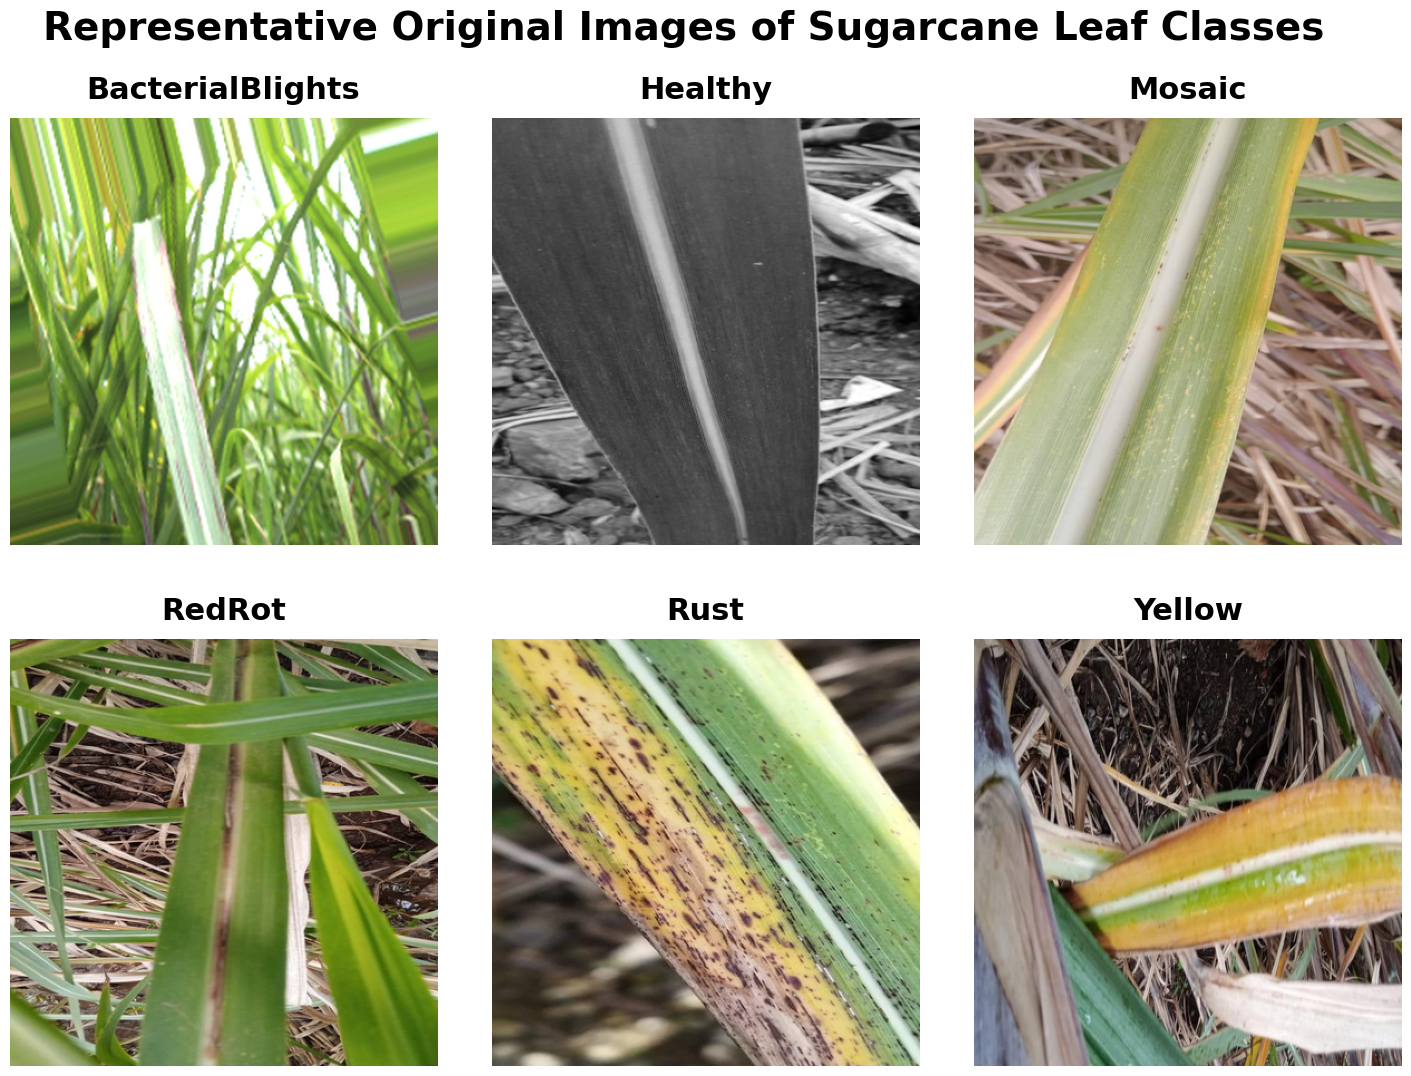


CELL 1 COMPLETED SUCCESSFULLY
Selected classes: ['BacterialBlights', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Number of selected images: 6
Original collage saved at: /content/sugarcane_original_classwise_collage.png

Important variables created:
1. image_df
2. selected_images_df
3. selected_rgb_images
4. class_names


In [ ]:
# ============================================================
# CELL 1
# LOAD DATASET AND SELECT ONE VALID IMAGE FROM EACH CLASS
# No segmentation is performed in this cell
# ============================================================

import sys
import subprocess
import importlib.util
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True


# ============================================================
# 1. INSTALL OPENCV WHEN REQUIRED
# ============================================================

if importlib.util.find_spec("cv2") is None:

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "opencv-python-headless"
    ])

import cv2


# ============================================================
# 2. DATASET PATH
# ============================================================

DATASET_ROOT = Path(
    "/content/sugarcane_data/Sugarcane_leafs"
)

if not DATASET_ROOT.exists():

    raise FileNotFoundError(
        f"Dataset folder was not found:\n{DATASET_ROOT}"
    )


# ============================================================
# 3. EXPECTED CLASS ORDER
# ============================================================

preferred_class_names = [
    "BacterialBlights",
    "Healthy",
    "Mosaic",
    "RedRot",
    "Rust",
    "Yellow"
]


# ============================================================
# 4. VALID IMAGE EXTENSIONS
# ============================================================

valid_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}


# ============================================================
# 5. DETECT CLASS FOLDERS
# ============================================================

available_class_folders = {
    folder.name: folder
    for folder in DATASET_ROOT.iterdir()
    if folder.is_dir()
}

class_names = [
    class_name
    for class_name in preferred_class_names
    if class_name in available_class_folders
]

# Include any additional class folders.
for detected_class_name in sorted(
    available_class_folders.keys()
):

    if detected_class_name not in class_names:

        class_names.append(
            detected_class_name
        )

if not class_names:

    raise RuntimeError(
        "No class folders were found inside the dataset folder."
    )

print("=" * 80)
print("DETECTED SUGARCANE CLASSES")
print("=" * 80)

for class_index, class_name in enumerate(
    class_names,
    start=1
):

    print(
        f"{class_index}. {class_name}"
    )


# ============================================================
# 6. FIND ALL IMAGE FILES
# ============================================================

image_records = []

for class_name in class_names:

    class_folder = available_class_folders[
        class_name
    ]

    class_image_paths = [
        image_path
        for image_path in class_folder.rglob("*")
        if (
            image_path.is_file()
            and
            image_path.suffix.lower()
            in valid_extensions
        )
    ]

    print(
        f"{class_name:22s}: "
        f"{len(class_image_paths):5d} image files"
    )

    for image_path in class_image_paths:

        image_records.append({
            "filepath": str(image_path),
            "class_name": class_name
        })


image_df = pd.DataFrame(
    image_records
)

if image_df.empty:

    raise RuntimeError(
        "No supported image files were found in the dataset."
    )


# ============================================================
# 7. VERIFY WHETHER ONE IMAGE CAN BE READ
# ============================================================

def verify_image_file(image_path):
    """
    Return True only when the image can be opened and has a
    valid non-zero width and height.
    """

    try:

        with Image.open(image_path) as image:

            image.verify()

        with Image.open(image_path) as image:

            image = image.convert("RGB")

            width, height = image.size

            if width <= 0 or height <= 0:

                return False

        return True

    except Exception:

        return False


# ============================================================
# 8. CALCULATE IMAGE SHARPNESS SAFELY
# ============================================================

def calculate_safe_sharpness(image_path):
    """
    Calculate Laplacian variance.

    Returns zero when an image cannot be read.
    This function does not use reductions on empty arrays.
    """

    try:

        grayscale_image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if grayscale_image is None:

            return 0.0

        if grayscale_image.size == 0:

            return 0.0

        grayscale_image = cv2.resize(
            grayscale_image,
            (256, 256),
            interpolation=cv2.INTER_AREA
        )

        laplacian_image = cv2.Laplacian(
            grayscale_image,
            cv2.CV_64F
        )

        if laplacian_image.size == 0:

            return 0.0

        return float(
            laplacian_image.var()
        )

    except Exception:

        return 0.0


# ============================================================
# 9. SELECT ONE VALID REPRESENTATIVE IMAGE PER CLASS
# ============================================================

selected_image_records = []

for class_index, class_name in enumerate(
    class_names
):

    class_dataframe = (
        image_df[
            image_df["class_name"]
            == class_name
        ]
        .reset_index(drop=True)
        .copy()
    )

    if class_dataframe.empty:

        print(
            f"Warning: no files found for {class_name}."
        )

        continue

    # Examine at most 30 images from each class.
    candidate_count = min(
        30,
        len(class_dataframe)
    )

    candidate_dataframe = class_dataframe.sample(
        n=candidate_count,
        random_state=42 + class_index
    ).reset_index(drop=True)

    valid_candidates = []

    for _, candidate_row in (
        candidate_dataframe.iterrows()
    ):

        candidate_path = candidate_row[
            "filepath"
        ]

        if not verify_image_file(
            candidate_path
        ):

            continue

        sharpness_value = (
            calculate_safe_sharpness(
                candidate_path
            )
        )

        valid_candidates.append({
            "filepath": candidate_path,
            "class_name": class_name,
            "sharpness": sharpness_value
        })

    if not valid_candidates:

        raise RuntimeError(
            f"No readable image was found for class: "
            f"{class_name}"
        )

    valid_candidates_df = pd.DataFrame(
        valid_candidates
    )

    selected_candidate = (
        valid_candidates_df
        .sort_values(
            by="sharpness",
            ascending=False
        )
        .iloc[0]
    )

    selected_image_records.append({
        "filepath":
            selected_candidate["filepath"],

        "class_name":
            selected_candidate["class_name"],

        "sharpness":
            float(
                selected_candidate["sharpness"]
            )
    })


selected_images_df = pd.DataFrame(
    selected_image_records
)

if selected_images_df.empty:

    raise RuntimeError(
        "No representative images could be selected."
    )


# ============================================================
# 10. DISPLAY SELECTED IMAGE INFORMATION
# ============================================================

print("\n" + "=" * 80)
print("SELECTED REPRESENTATIVE IMAGES")
print("=" * 80)

display(
    selected_images_df
)


# ============================================================
# 11. LOAD IMAGE SAFELY FOR DISPLAY
# ============================================================

def load_original_rgb_image(
    image_path,
    target_size=(384, 384)
):
    """
    Load and resize an RGB image.

    Returns a valid array or raises a clear error.
    """

    try:

        with Image.open(image_path) as image:

            image = image.convert("RGB")

            image = image.resize(
                (
                    target_size[1],
                    target_size[0]
                ),
                Image.Resampling.LANCZOS
            )

            image_array = np.asarray(
                image,
                dtype=np.uint8
            )

    except Exception as error:

        raise RuntimeError(
            f"Unable to load image:\n{image_path}"
        ) from error

    if image_array.size == 0:

        raise RuntimeError(
            f"Loaded image is empty:\n{image_path}"
        )

    if image_array.ndim != 3:

        raise RuntimeError(
            f"Unexpected image dimensions for:\n{image_path}"
        )

    if image_array.shape[2] != 3:

        raise RuntimeError(
            f"Image is not RGB:\n{image_path}"
        )

    return image_array


# ============================================================
# 12. CREATE ORIGINAL CLASS-WISE COLLAGE
# ============================================================

number_of_images = len(
    selected_images_df
)

number_of_columns = 3

number_of_rows = int(
    np.ceil(
        number_of_images
        / number_of_columns
    )
)

figure, axes = plt.subplots(
    nrows=number_of_rows,
    ncols=number_of_columns,
    figsize=(
        6 * number_of_columns,
        6 * number_of_rows
    ),
    squeeze=False
)

axes = axes.flatten()

selected_rgb_images = {}

for image_index, selected_row in (
    selected_images_df.iterrows()
):

    class_name = selected_row[
        "class_name"
    ]

    image_path = selected_row[
        "filepath"
    ]

    rgb_image = load_original_rgb_image(
        image_path,
        target_size=(384, 384)
    )

    selected_rgb_images[
        class_name
    ] = rgb_image

    axes[image_index].imshow(
        rgb_image
    )

    axes[image_index].set_title(
        class_name,
        fontsize=22,
        fontweight="bold",
        pad=14
    )

    axes[image_index].axis("off")


# Hide unused axes.
for unused_index in range(
    number_of_images,
    len(axes)
):

    axes[unused_index].axis("off")


figure.suptitle(
    "Representative Original Images of Sugarcane Leaf Classes",
    fontsize=28,
    fontweight="bold",
    y=0.99
)

plt.subplots_adjust(
    top=0.90,
    wspace=0.12,
    hspace=0.22
)

original_collage_path = Path(
    "/content/sugarcane_original_classwise_collage.png"
)

figure.savefig(
    original_collage_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25,
    facecolor="white"
)

plt.show()
plt.close(figure)


# ============================================================
# 13. FINAL CHECK
# ============================================================

print("\n" + "=" * 80)
print("CELL 1 COMPLETED SUCCESSFULLY")
print("=" * 80)

print(
    "Selected classes:",
    list(
        selected_images_df[
            "class_name"
        ]
    )
)

print(
    "Number of selected images:",
    len(selected_images_df)
)

print(
    "Original collage saved at:",
    original_collage_path
)

print(
    "\nImportant variables created:"
)

print(
    "1. image_df"
)

print(
    "2. selected_images_df"
)

print(
    "3. selected_rgb_images"
)

print(
    "4. class_names"
)

In [ ]:
# ============================================================
# CELL 2
# SAFE LEAF EXTRACTION AND LEAF-MASK VISUALIZATION
#
# Required variables from Cell 1:
# selected_images_df
# selected_rgb_images
# class_names
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ============================================================
# 1. VERIFY CELL 1 VARIABLES
# ============================================================

required_variables = [
    "selected_images_df",
    "selected_rgb_images",
    "class_names"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:

    raise NameError(
        "Run Cell 1 first. Missing variables: "
        + ", ".join(missing_variables)
    )

if selected_images_df.empty:

    raise ValueError(
        "selected_images_df is empty."
    )


# ============================================================
# 2. OUTPUT DIRECTORY
# ============================================================

LEAF_EXTRACTION_OUTPUT_DIRECTORY = Path(
    "/content/pretraining_sugarcane_segmentation/"
    "leaf_extraction"
)

LEAF_MASK_DIRECTORY = (
    LEAF_EXTRACTION_OUTPUT_DIRECTORY
    / "leaf_masks"
)

EXTRACTED_LEAF_DIRECTORY = (
    LEAF_EXTRACTION_OUTPUT_DIRECTORY
    / "extracted_leaves"
)

LEAF_ROI_DIRECTORY = (
    LEAF_EXTRACTION_OUTPUT_DIRECTORY
    / "leaf_roi_images"
)

for directory_path in [
    LEAF_EXTRACTION_OUTPUT_DIRECTORY,
    LEAF_MASK_DIRECTORY,
    EXTRACTED_LEAF_DIRECTORY,
    LEAF_ROI_DIRECTORY
]:

    directory_path.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 3. SETTINGS
# ============================================================

MINIMUM_VALID_LEAF_FRACTION = 0.02
MAXIMUM_VALID_LEAF_FRACTION = 0.995

MORPHOLOGY_KERNEL_SIZE = 9

COLLAGE_TITLE_FONT_SIZE = 22
ROW_LABEL_FONT_SIZE = 22
MAIN_TITLE_FONT_SIZE = 28

COLLAGE_DPI = 300


# ============================================================
# 4. SAFE BINARY-MASK CONVERSION
# ============================================================

def convert_to_binary_mask(
    mask,
    expected_shape
):
    """
    Convert any proposed mask to a valid uint8 binary mask.
    """

    image_height, image_width = expected_shape

    if mask is None:

        return np.zeros(
            expected_shape,
            dtype=np.uint8
        )

    mask = np.asarray(mask)

    if mask.size == 0:

        return np.zeros(
            expected_shape,
            dtype=np.uint8
        )

    if mask.ndim == 3:

        mask = mask[:, :, 0]

    if mask.shape != expected_shape:

        mask = cv2.resize(
            mask.astype(np.uint8),
            (
                image_width,
                image_height
            ),
            interpolation=cv2.INTER_NEAREST
        )

    return np.where(
        mask > 0,
        255,
        0
    ).astype(np.uint8)


# ============================================================
# 5. SAFE CONNECTED-COMPONENT PROCESSING
# ============================================================

def retain_largest_leaf_components(
    binary_mask,
    maximum_components=3
):
    """
    Retain the largest foreground components without using
    reductions on empty arrays.
    """

    binary_mask = np.where(
        binary_mask > 0,
        255,
        0
    ).astype(np.uint8)

    if binary_mask.size == 0:

        return binary_mask

    if np.count_nonzero(binary_mask) == 0:

        return binary_mask

    (
        component_count,
        component_labels,
        component_statistics,
        _
    ) = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )

    if component_count <= 1:

        return binary_mask

    component_information = []

    for component_id in range(
        1,
        component_count
    ):

        component_area = int(
            component_statistics[
                component_id,
                cv2.CC_STAT_AREA
            ]
        )

        if component_area > 0:

            component_information.append(
                (
                    component_id,
                    component_area
                )
            )

    if not component_information:

        return np.zeros_like(
            binary_mask
        )

    component_information.sort(
        key=lambda item: item[1],
        reverse=True
    )

    selected_components = (
        component_information[
            :maximum_components
        ]
    )

    retained_mask = np.zeros_like(
        binary_mask
    )

    for component_id, _ in selected_components:

        retained_mask[
            component_labels == component_id
        ] = 255

    return retained_mask


# ============================================================
# 6. SAFE INITIAL FOREGROUND ESTIMATION
# ============================================================

def create_initial_leaf_foreground(
    rgb_image
):
    """
    Estimate a broad foreground mask using:

    1. Background-colour distance
    2. HSV saturation
    3. Excess-green information
    """

    if rgb_image is None:

        raise ValueError(
            "Input image is None."
        )

    rgb_image = np.asarray(
        rgb_image,
        dtype=np.uint8
    )

    if rgb_image.size == 0:

        raise ValueError(
            "Input image is empty."
        )

    image_height, image_width = (
        rgb_image.shape[:2]
    )

    hsv_image = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2HSV
    )

    saturation = hsv_image[:, :, 1]
    brightness = hsv_image[:, :, 2]

    red_channel = (
        rgb_image[:, :, 0]
        .astype(np.int16)
    )

    green_channel = (
        rgb_image[:, :, 1]
        .astype(np.int16)
    )

    blue_channel = (
        rgb_image[:, :, 2]
        .astype(np.int16)
    )

    excess_green = (
        2 * green_channel
        - red_channel
        - blue_channel
    )

    # --------------------------------------------------------
    # Estimate background colour using image borders
    # --------------------------------------------------------

    border_width = max(
        4,
        int(
            min(
                image_height,
                image_width
            ) * 0.025
        )
    )

    border_pixel_groups = [
        rgb_image[
            :border_width,
            :
        ].reshape(-1, 3),

        rgb_image[
            -border_width:,
            :
        ].reshape(-1, 3),

        rgb_image[
            :,
            :border_width
        ].reshape(-1, 3),

        rgb_image[
            :,
            -border_width:
        ].reshape(-1, 3)
    ]

    non_empty_border_groups = [
        pixel_group
        for pixel_group in border_pixel_groups
        if pixel_group.size > 0
    ]

    if non_empty_border_groups:

        border_pixels = np.concatenate(
            non_empty_border_groups,
            axis=0
        )

    else:

        border_pixels = rgb_image.reshape(
            -1,
            3
        )

    if border_pixels.size == 0:

        background_colour = np.array(
            [255, 255, 255],
            dtype=np.float32
        )

    else:

        background_colour = np.median(
            border_pixels,
            axis=0
        ).astype(np.float32)

    colour_distance = np.linalg.norm(
        rgb_image.astype(np.float32)
        -
        background_colour[
            np.newaxis,
            np.newaxis,
            :
        ],
        axis=-1
    )

    finite_distances = colour_distance[
        np.isfinite(colour_distance)
    ]

    if finite_distances.size > 0:

        colour_distance_threshold = max(
            12.0,
            float(
                np.percentile(
                    finite_distances,
                    50
                )
            )
        )

    else:

        colour_distance_threshold = 12.0

    probable_leaf = (
        (
            colour_distance
            >= colour_distance_threshold
        )
        |
        (
            saturation >= 18
        )
        |
        (
            excess_green >= 5
        )
    ) & (
        brightness >= 10
    )

    initial_mask = np.where(
        probable_leaf,
        255,
        0
    ).astype(np.uint8)

    morphology_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (
            MORPHOLOGY_KERNEL_SIZE,
            MORPHOLOGY_KERNEL_SIZE
        )
    )

    initial_mask = cv2.morphologyEx(
        initial_mask,
        cv2.MORPH_CLOSE,
        morphology_kernel,
        iterations=2
    )

    initial_mask = cv2.morphologyEx(
        initial_mask,
        cv2.MORPH_OPEN,
        morphology_kernel,
        iterations=1
    )

    initial_mask = retain_largest_leaf_components(
        initial_mask,
        maximum_components=3
    )

    return initial_mask


# ============================================================
# 7. SAFE GRABCUT LEAF EXTRACTION
# ============================================================

def extract_leaf_mask_safely(
    rgb_image
):
    """
    Extract the leaf using a colour-informed GrabCut mask.

    The function always returns a non-empty processing mask.
    """

    rgb_image = np.asarray(
        rgb_image,
        dtype=np.uint8
    )

    image_height, image_width = (
        rgb_image.shape[:2]
    )

    total_pixel_count = (
        image_height * image_width
    )

    minimum_valid_pixels = max(
        100,
        int(
            total_pixel_count
            * MINIMUM_VALID_LEAF_FRACTION
        )
    )

    initial_mask = create_initial_leaf_foreground(
        rgb_image
    )

    initial_foreground_count = int(
        np.count_nonzero(
            initial_mask
        )
    )

    # --------------------------------------------------------
    # Try mask-initialized GrabCut
    # --------------------------------------------------------

    grabcut_result = None

    if initial_foreground_count >= minimum_valid_pixels:

        grabcut_mask = np.full(
            (
                image_height,
                image_width
            ),
            cv2.GC_PR_BGD,
            dtype=np.uint8
        )

        grabcut_mask[
            initial_mask > 0
        ] = cv2.GC_PR_FGD

        border_width = max(
            3,
            int(
                min(
                    image_height,
                    image_width
                ) * 0.015
            )
        )

        # Definite background on borders
        grabcut_mask[
            :border_width,
            :
        ] = cv2.GC_BGD

        grabcut_mask[
            -border_width:,
            :
        ] = cv2.GC_BGD

        grabcut_mask[
            :,
            :border_width
        ] = cv2.GC_BGD

        grabcut_mask[
            :,
            -border_width:
        ] = cv2.GC_BGD

        # Definite foreground from eroded initial mask
        foreground_kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (5, 5)
        )

        definite_foreground = cv2.erode(
            initial_mask,
            foreground_kernel,
            iterations=1
        )

        grabcut_mask[
            definite_foreground > 0
        ] = cv2.GC_FGD

        background_model = np.zeros(
            (1, 65),
            dtype=np.float64
        )

        foreground_model = np.zeros(
            (1, 65),
            dtype=np.float64
        )

        try:

            bgr_image = cv2.cvtColor(
                rgb_image,
                cv2.COLOR_RGB2BGR
            )

            cv2.grabCut(
                bgr_image,
                grabcut_mask,
                None,
                background_model,
                foreground_model,
                5,
                cv2.GC_INIT_WITH_MASK
            )

            grabcut_result = np.where(
                (
                    grabcut_mask
                    == cv2.GC_FGD
                )
                |
                (
                    grabcut_mask
                    == cv2.GC_PR_FGD
                ),
                255,
                0
            ).astype(np.uint8)

        except cv2.error:

            grabcut_result = None

    # --------------------------------------------------------
    # Rectangle-based GrabCut fallback
    # --------------------------------------------------------

    if (
        grabcut_result is None
        or
        np.count_nonzero(
            grabcut_result
        ) < minimum_valid_pixels
    ):

        rectangle_mask = np.zeros(
            (
                image_height,
                image_width
            ),
            dtype=np.uint8
        )

        rectangle_margin_x = max(
            2,
            int(image_width * 0.02)
        )

        rectangle_margin_y = max(
            2,
            int(image_height * 0.02)
        )

        rectangle = (
            rectangle_margin_x,
            rectangle_margin_y,
            max(
                image_width
                - 2 * rectangle_margin_x,
                1
            ),
            max(
                image_height
                - 2 * rectangle_margin_y,
                1
            )
        )

        background_model = np.zeros(
            (1, 65),
            dtype=np.float64
        )

        foreground_model = np.zeros(
            (1, 65),
            dtype=np.float64
        )

        try:

            cv2.grabCut(
                cv2.cvtColor(
                    rgb_image,
                    cv2.COLOR_RGB2BGR
                ),
                rectangle_mask,
                rectangle,
                background_model,
                foreground_model,
                5,
                cv2.GC_INIT_WITH_RECT
            )

            rectangle_result = np.where(
                (
                    rectangle_mask
                    == cv2.GC_FGD
                )
                |
                (
                    rectangle_mask
                    == cv2.GC_PR_FGD
                ),
                255,
                0
            ).astype(np.uint8)

            if (
                np.count_nonzero(
                    rectangle_result
                )
                >= minimum_valid_pixels
            ):

                grabcut_result = (
                    rectangle_result
                )

        except cv2.error:

            pass

    # --------------------------------------------------------
    # Use the initial mask if GrabCut remains invalid
    # --------------------------------------------------------

    if (
        grabcut_result is None
        or
        np.count_nonzero(
            grabcut_result
        ) < minimum_valid_pixels
    ):

        grabcut_result = initial_mask.copy()

    # --------------------------------------------------------
    # Final guaranteed fallback
    # --------------------------------------------------------

    if (
        np.count_nonzero(
            grabcut_result
        ) < minimum_valid_pixels
    ):

        final_margin = max(
            1,
            int(
                min(
                    image_height,
                    image_width
                ) * 0.01
            )
        )

        grabcut_result = np.zeros(
            (
                image_height,
                image_width
            ),
            dtype=np.uint8
        )

        grabcut_result[
            final_margin:
            image_height - final_margin,
            final_margin:
            image_width - final_margin
        ] = 255

    morphology_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (
            MORPHOLOGY_KERNEL_SIZE,
            MORPHOLOGY_KERNEL_SIZE
        )
    )

    grabcut_result = cv2.morphologyEx(
        grabcut_result,
        cv2.MORPH_CLOSE,
        morphology_kernel,
        iterations=2
    )

    grabcut_result = cv2.morphologyEx(
        grabcut_result,
        cv2.MORPH_OPEN,
        morphology_kernel,
        iterations=1
    )

    grabcut_result = retain_largest_leaf_components(
        grabcut_result,
        maximum_components=3
    )

    grabcut_result = convert_to_binary_mask(
        grabcut_result,
        (
            image_height,
            image_width
        )
    )

    final_foreground_count = int(
        np.count_nonzero(
            grabcut_result
        )
    )

    if final_foreground_count == 0:

        raise RuntimeError(
            "Leaf extraction produced an empty mask "
            "after all fallback procedures."
        )

    return grabcut_result


# ============================================================
# 8. CREATE EXTRACTED LEAF IMAGE
# ============================================================

def create_extracted_leaf_image(
    rgb_image,
    leaf_mask
):
    """
    Keep leaf pixels and replace the background with white.
    """

    extracted_image = np.full_like(
        rgb_image,
        255
    )

    foreground_selector = (
        leaf_mask > 0
    )

    extracted_image[
        foreground_selector
    ] = rgb_image[
        foreground_selector
    ]

    return extracted_image


# ============================================================
# 9. CREATE LEAF ROI IMAGE
# ============================================================

def create_leaf_roi_image(
    rgb_image,
    leaf_mask
):
    """
    Draw a large green bounding box around the extracted leaf.
    """

    roi_image = rgb_image.copy()

    foreground_points = cv2.findNonZero(
        leaf_mask
    )

    if foreground_points is None:

        return roi_image, None

    x, y, width, height = cv2.boundingRect(
        foreground_points
    )

    cv2.rectangle(
        roi_image,
        (x, y),
        (
            x + width,
            y + height
        ),
        (0, 255, 0),
        3
    )

    label_text = "Leaf ROI"

    text_scale = 0.90
    text_thickness = 2

    (
        text_width,
        text_height
    ), baseline = cv2.getTextSize(
        label_text,
        cv2.FONT_HERSHEY_SIMPLEX,
        text_scale,
        text_thickness
    )

    text_y = max(
        y - 8,
        text_height + 8
    )

    cv2.rectangle(
        roi_image,
        (
            x,
            text_y
            - text_height
            - 6
        ),
        (
            min(
                x + text_width + 8,
                roi_image.shape[1] - 1
            ),
            min(
                text_y + baseline + 4,
                roi_image.shape[0] - 1
            )
        ),
        (0, 255, 0),
        -1
    )

    cv2.putText(
        roi_image,
        label_text,
        (
            x + 3,
            text_y
        ),
        cv2.FONT_HERSHEY_SIMPLEX,
        text_scale,
        (0, 0, 0),
        text_thickness,
        cv2.LINE_AA
    )

    return (
        roi_image,
        (
            int(x),
            int(y),
            int(width),
            int(height)
        )
    )


# ============================================================
# 10. PROCESS ALL SELECTED CLASS IMAGES
# ============================================================

selected_leaf_masks = {}
selected_extracted_leaf_images = {}
selected_leaf_roi_images = {}

leaf_extraction_records = []

for row_index, selected_row in (
    selected_images_df
    .reset_index(drop=True)
    .iterrows()
):

    class_name = selected_row[
        "class_name"
    ]

    image_path = selected_row[
        "filepath"
    ]

    if class_name in selected_rgb_images:

        rgb_image = np.asarray(
            selected_rgb_images[
                class_name
            ],
            dtype=np.uint8
        )

    else:

        rgb_image = load_original_rgb_image(
            image_path,
            target_size=(384, 384)
        )

    if rgb_image.size == 0:

        raise RuntimeError(
            f"Empty RGB image detected for class: "
            f"{class_name}"
        )

    leaf_mask = extract_leaf_mask_safely(
        rgb_image
    )

    foreground_pixel_count = int(
        np.count_nonzero(
            leaf_mask
        )
    )

    total_pixel_count = int(
        leaf_mask.size
    )

    leaf_area_percentage = (
        foreground_pixel_count
        /
        max(
            total_pixel_count,
            1
        )
        * 100.0
    )

    extracted_leaf_image = (
        create_extracted_leaf_image(
            rgb_image,
            leaf_mask
        )
    )

    (
        leaf_roi_image,
        leaf_bounding_box
    ) = create_leaf_roi_image(
        rgb_image,
        leaf_mask
    )

    selected_leaf_masks[
        class_name
    ] = leaf_mask

    selected_extracted_leaf_images[
        class_name
    ] = extracted_leaf_image

    selected_leaf_roi_images[
        class_name
    ] = leaf_roi_image

    safe_class_name = (
        str(class_name)
        .replace(" ", "_")
        .replace("/", "_")
    )

    leaf_mask_path = (
        LEAF_MASK_DIRECTORY
        / f"{safe_class_name}_leaf_mask.png"
    )

    extracted_leaf_path = (
        EXTRACTED_LEAF_DIRECTORY
        / f"{safe_class_name}_extracted_leaf.png"
    )

    leaf_roi_path = (
        LEAF_ROI_DIRECTORY
        / f"{safe_class_name}_leaf_roi.png"
    )

    cv2.imwrite(
        str(leaf_mask_path),
        leaf_mask
    )

    cv2.imwrite(
        str(extracted_leaf_path),
        cv2.cvtColor(
            extracted_leaf_image,
            cv2.COLOR_RGB2BGR
        )
    )

    cv2.imwrite(
        str(leaf_roi_path),
        cv2.cvtColor(
            leaf_roi_image,
            cv2.COLOR_RGB2BGR
        )
    )

    leaf_extraction_records.append({
        "Class":
            class_name,

        "Filepath":
            image_path,

        "Foreground_Pixels":
            foreground_pixel_count,

        "Total_Pixels":
            total_pixel_count,

        "Estimated_Leaf_Area_Percentage":
            leaf_area_percentage,

        "Leaf_Bounding_Box":
            str(leaf_bounding_box),

        "Leaf_Mask_Path":
            str(leaf_mask_path),

        "Extracted_Leaf_Path":
            str(extracted_leaf_path),

        "Leaf_ROI_Path":
            str(leaf_roi_path)
    })

    print(
        f"{class_name:22s} | "
        f"Leaf pixels: "
        f"{foreground_pixel_count:7d} | "
        f"Area: "
        f"{leaf_area_percentage:6.2f}%"
    )


leaf_extraction_results_df = pd.DataFrame(
    leaf_extraction_records
)

leaf_extraction_results_df.to_csv(
    LEAF_EXTRACTION_OUTPUT_DIRECTORY
    / "leaf_extraction_results.csv",
    index=False
)


# ============================================================
# 11. DISPLAY LEAF-EXTRACTION RESULTS
# ============================================================

print("\nLEAF EXTRACTION SUMMARY")

display(
    leaf_extraction_results_df[
        [
            "Class",
            "Foreground_Pixels",
            "Estimated_Leaf_Area_Percentage",
            "Leaf_Bounding_Box"
        ]
    ].round(2)
)


# ============================================================
# 12. CREATE CLASS-WISE LEAF EXTRACTION COLLAGE
# ============================================================

number_of_classes = len(
    leaf_extraction_results_df
)

leaf_figure, leaf_axes = plt.subplots(
    nrows=number_of_classes,
    ncols=4,
    figsize=(
        24,
        5.5 * number_of_classes
    ),
    squeeze=False
)

for row_index, result_row in (
    leaf_extraction_results_df
    .reset_index(drop=True)
    .iterrows()
):

    class_name = result_row[
        "Class"
    ]

    original_image = selected_rgb_images[
        class_name
    ]

    leaf_mask = selected_leaf_masks[
        class_name
    ]

    extracted_leaf_image = (
        selected_extracted_leaf_images[
            class_name
        ]
    )

    leaf_roi_image = (
        selected_leaf_roi_images[
            class_name
        ]
    )

    # Original
    leaf_axes[
        row_index,
        0
    ].imshow(
        original_image
    )

    leaf_axes[
        row_index,
        0
    ].set_title(
        "Original Image",
        fontsize=COLLAGE_TITLE_FONT_SIZE,
        fontweight="bold",
        pad=15
    )

    # Binary leaf mask
    leaf_axes[
        row_index,
        1
    ].imshow(
        leaf_mask,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    leaf_axes[
        row_index,
        1
    ].set_title(
        "Binary Leaf Mask",
        fontsize=COLLAGE_TITLE_FONT_SIZE,
        fontweight="bold",
        pad=15
    )

    # Extracted leaf
    leaf_axes[
        row_index,
        2
    ].imshow(
        extracted_leaf_image
    )

    leaf_axes[
        row_index,
        2
    ].set_title(
        "Extracted Leaf",
        fontsize=COLLAGE_TITLE_FONT_SIZE,
        fontweight="bold",
        pad=15
    )

    # Bounding box
    leaf_axes[
        row_index,
        3
    ].imshow(
        leaf_roi_image
    )

    leaf_axes[
        row_index,
        3
    ].set_title(
        (
            "Detected Leaf ROI\n"
            f"Estimated Area: "
            f"{result_row['Estimated_Leaf_Area_Percentage']:.2f}%"
        ),
        fontsize=COLLAGE_TITLE_FONT_SIZE,
        fontweight="bold",
        pad=15
    )

    for column_index in range(4):

        leaf_axes[
            row_index,
            column_index
        ].axis("off")

    leaf_axes[
        row_index,
        0
    ].set_ylabel(
        class_name,
        fontsize=ROW_LABEL_FONT_SIZE,
        fontweight="bold",
        rotation=90,
        labelpad=25
    )


leaf_figure.suptitle(
    "Class-wise Sugarcane Leaf Extraction Before Model Training",
    fontsize=MAIN_TITLE_FONT_SIZE,
    fontweight="bold",
    y=0.995
)

leaf_figure.subplots_adjust(
    left=0.07,
    right=0.99,
    top=0.95,
    bottom=0.02,
    wspace=0.16,
    hspace=0.38
)

leaf_extraction_collage_path = (
    LEAF_EXTRACTION_OUTPUT_DIRECTORY
    / "classwise_leaf_extraction_collage.png"
)

leaf_figure.savefig(
    leaf_extraction_collage_path,
    dpi=COLLAGE_DPI,
    bbox_inches="tight",
    pad_inches=0.30,
    facecolor="white"
)

plt.show()
plt.close(leaf_figure)


# ============================================================
# 13. FINAL VALIDATION
# ============================================================

empty_mask_classes = [
    class_name
    for class_name, leaf_mask
    in selected_leaf_masks.items()
    if (
        leaf_mask is None
        or leaf_mask.size == 0
        or np.count_nonzero(
            leaf_mask
        ) == 0
    )
]

if empty_mask_classes:

    raise RuntimeError(
        "Empty leaf masks remain for: "
        + ", ".join(
            empty_mask_classes
        )
    )


print("\n" + "=" * 80)
print("CELL 2 COMPLETED SUCCESSFULLY")
print("=" * 80)

print(
    "Class-wise leaf extraction collage saved at:"
)

print(
    leaf_extraction_collage_path
)

print(
    "\nImportant variables created:"
)

print(
    "1. selected_leaf_masks"
)

print(
    "2. selected_extracted_leaf_images"
)

print(
    "3. selected_leaf_roi_images"
)

print(
    "4. leaf_extraction_results_df"
)

## 19. Attention ablation study (exact McNemar tests)


ATTENTION-MECHANISM ABLATION STUDY
Number of test images: 2863
Classes: ['BacterialBlights', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']

COMPLETE AVAILABLE MODEL RESULTS


,Model,Backbone,Attention,Total_Parameters,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,MCC,Cohen_Kappa,Classification_Errors
0,DenseNet121-CBAM,DenseNet121,CBAM,7437800,0.8921,0.8818,0.8828,0.8818,0.8807,0.8919,0.8696,0.8691,309
1,DenseNet121,DenseNet121,None,7305542,0.8910,0.8795,0.8831,0.8795,0.8795,0.8911,0.8684,0.8677,312
2,MobileNetV3Large-CA,MobileNetV3Large,Coordinate Attention,3336190,0.9179,0.9081,0.9130,0.9081,0.9089,0.9179,0.9009,0.9004,235
3,MobileNetV3Large-ECA,MobileNetV3Large,ECA,3247755,0.9057,0.8937,0.9010,0.8937,0.8960,0.9055,0.8859,0.8854,270
4,MobileNetV3Large,MobileNetV3Large,None,3247750,0.9050,0.8934,0.8991,0.8934,0.8944,0.9048,0.8853,0.8847,272
5,ResNet50-CBAM,ResNet50,CBAM,24648552,0.9260,0.9174,0.9216,0.9174,0.9184,0.9255,0.9104,0.9101,212
6,ResNet50,ResNet50,None,24121990,0.9294,0.9214,0.9263,0.9214,0.9222,0.9291,0.9149,0.9143,202



MAIN ATTENTION ABLATION RESULTS


,Baseline_Model,Attention_Variant,Attention_Module,Baseline_Accuracy,Variant_Accuracy,Accuracy_Change_Percentage_Points,Baseline_Macro_F1,Variant_Macro_F1,Macro_F1_Change_Percentage_Points,Additional_Parameters,Parameter_Overhead_Percentage,Error_Reduction,McNemar_Exact_P_Value
0,ResNet50,ResNet50-CBAM,CBAM,0.9294,0.9260,-0.3493,0.9222,0.9184,-0.3813,526562,2.1829,-10,0.3533
1,DenseNet121,DenseNet121-CBAM,CBAM,0.8910,0.8921,0.1048,0.8795,0.8807,0.1216,132258,1.8104,3,0.8724
2,MobileNetV3Large,MobileNetV3Large-ECA,ECA,0.9050,0.9057,0.0699,0.8944,0.8960,0.1574,5,0.0002,2,0.9296
3,MobileNetV3Large,MobileNetV3Large-CA,Coordinate Attention,0.9050,0.9179,1.2924,0.8944,0.9089,1.4539,88440,2.7231,37,0.0029



MANUSCRIPT-READY ABLATION TABLE


,Backbone,Attention,Baseline Accuracy (%),Attention Accuracy (%),Δ Accuracy (pp),Baseline Macro-F1 (%),Attention Macro-F1 (%),Δ Macro-F1 (pp),Parameter Overhead (%),Error Reduction,McNemar p-value
0,ResNet50,CBAM,92.944,92.595,-0.349,92.224,91.843,-0.381,2.183,-10,0.353
1,DenseNet121,CBAM,89.102,89.207,0.105,87.953,88.075,0.122,1.810,3,0.872
2,MobileNetV3Large,ECA,90.499,90.569,0.070,89.439,89.597,0.157,0.000,2,0.930
3,MobileNetV3Large,Coordinate Attention,90.499,91.792,1.292,89.439,90.893,1.454,2.723,37,0.003


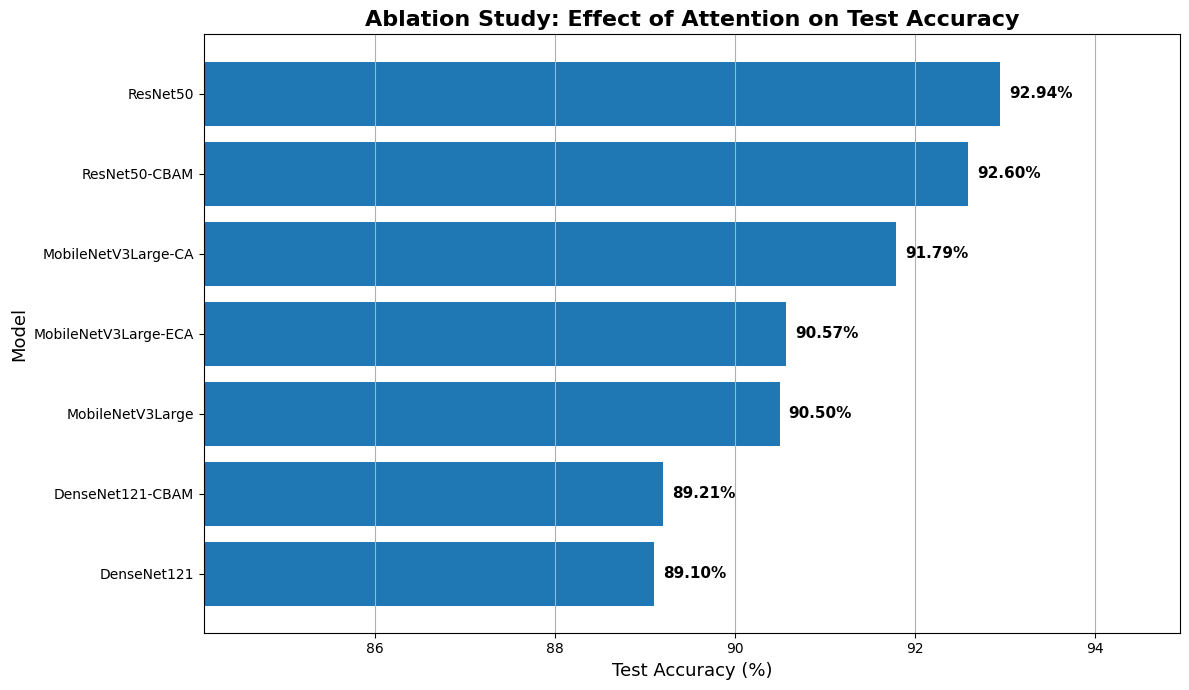

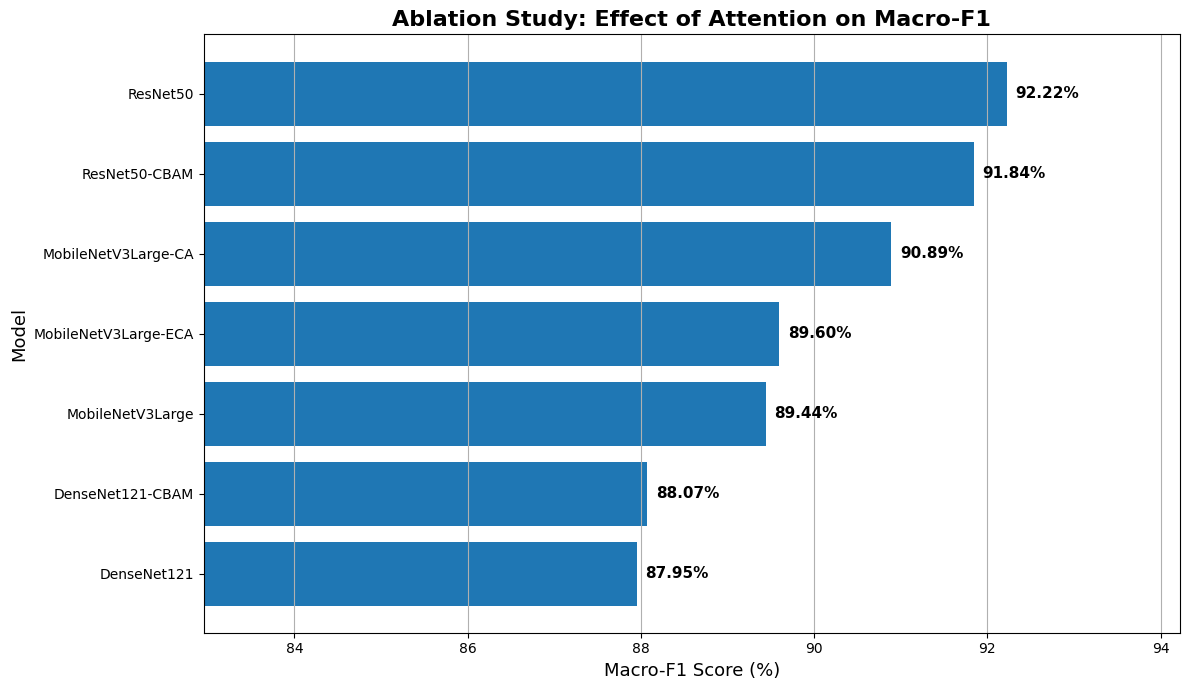

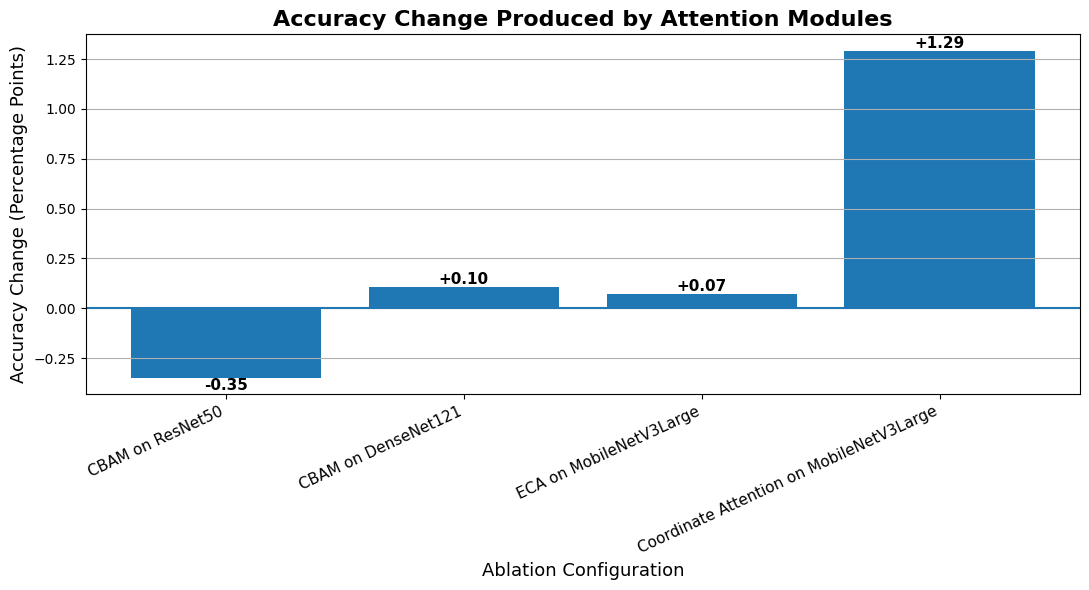

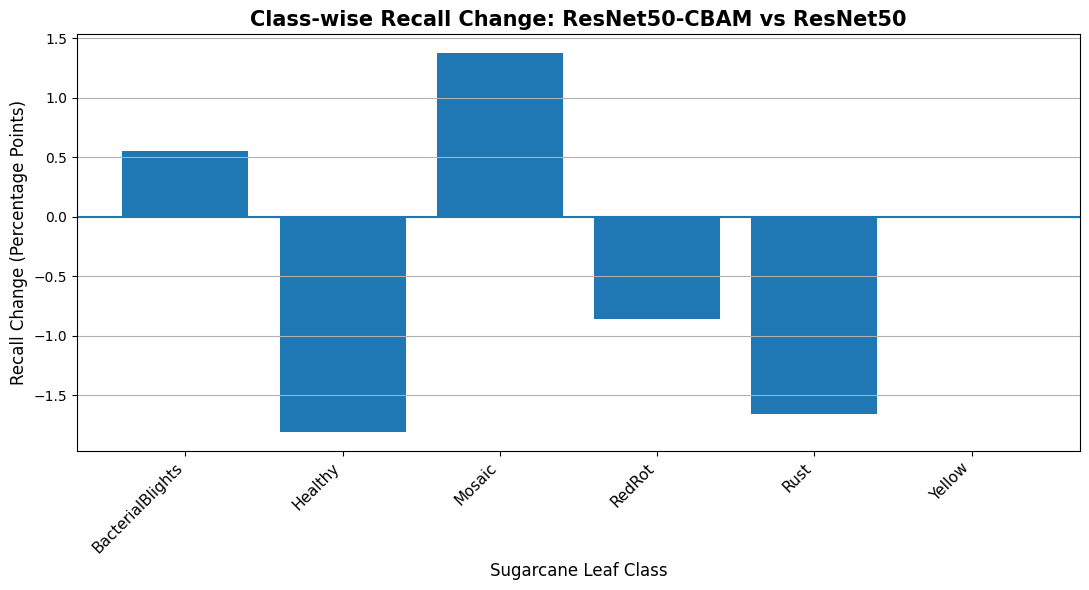

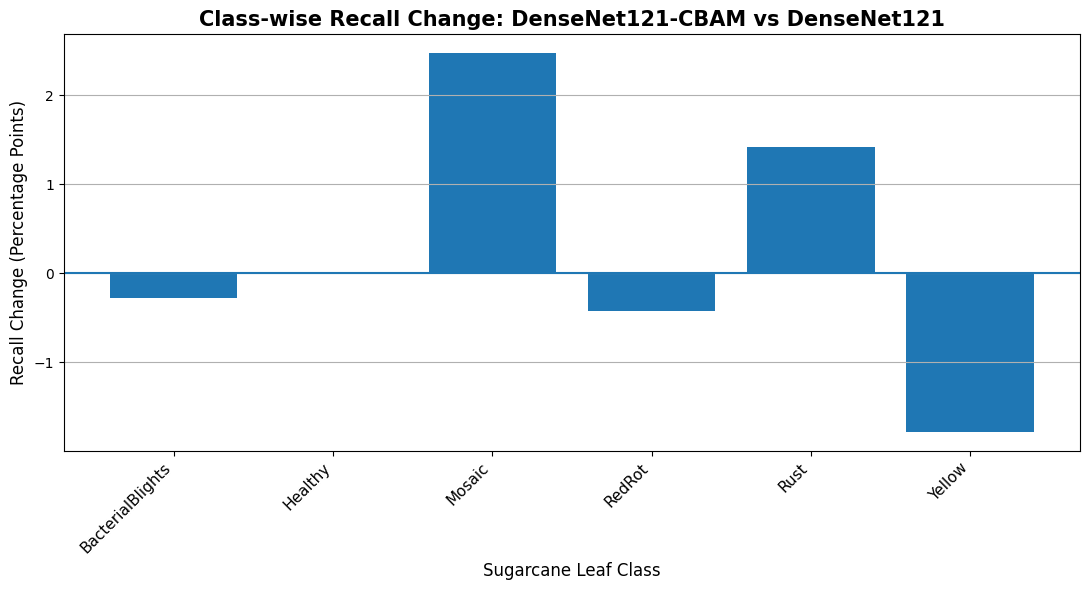

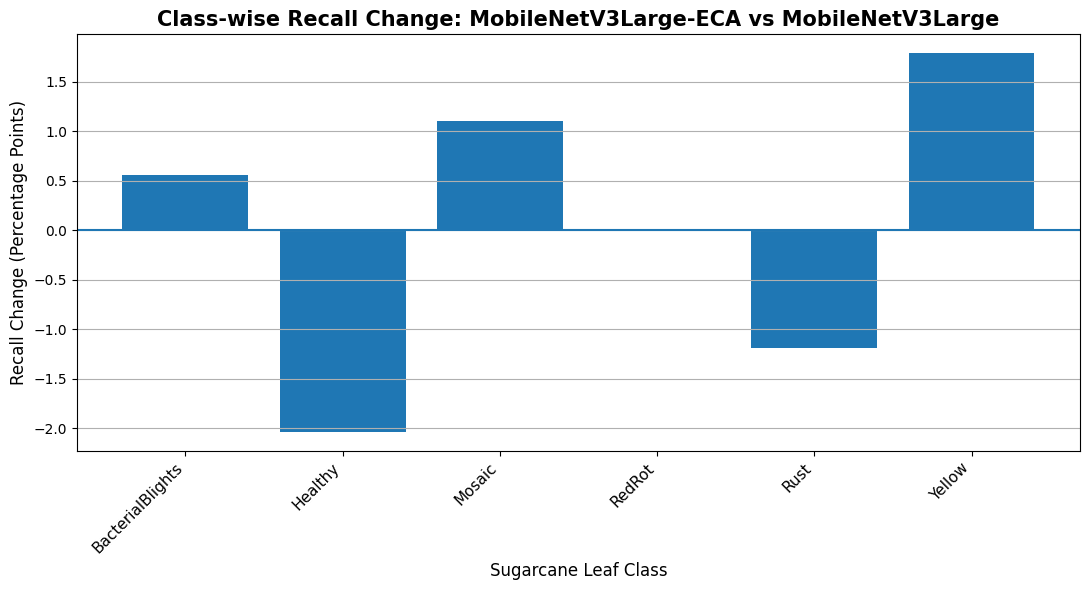

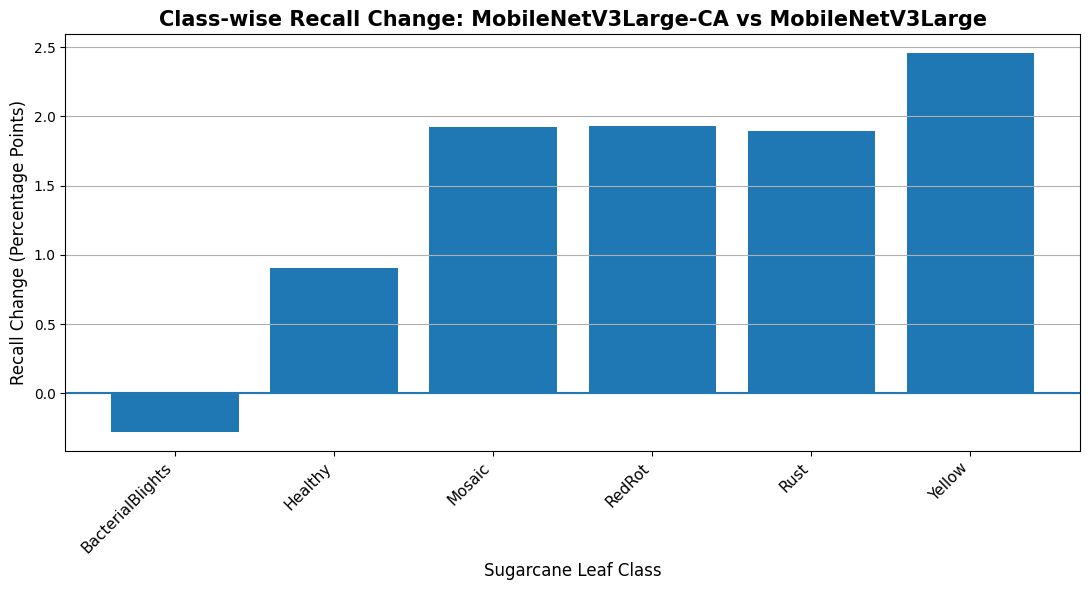


AUTOMATIC ABLATION INTERPRETATION

Compared with ResNet50, ResNet50-CBAM reduced test accuracy by 0.35 percentage points and reduced Macro-F1 by 0.38 percentage points, with a parameter overhead of 2.18%. The paired difference was not statistically significant (exact McNemar p=0.3533).

Compared with DenseNet121, DenseNet121-CBAM improved test accuracy by 0.10 percentage points and improved Macro-F1 by 0.12 percentage points, with a parameter overhead of 1.81%. The paired difference was not statistically significant (exact McNemar p=0.8724).

Compared with MobileNetV3Large, MobileNetV3Large-ECA improved test accuracy by 0.07 percentage points and improved Macro-F1 by 0.16 percentage points, with a parameter overhead of 0.00%. The paired difference was not statistically significant (exact McNemar p=0.9296).

Compared with MobileNetV3Large, MobileNetV3Large-CA improved test accuracy by 1.29 percentage points and improved Macro-F1 by 1.45 percentage points, with a parameter overhead of 2

In [ ]:
# ============================================================
# COMPLETE ATTENTION-MECHANISM ABLATION STUDY
#
# Comparisons:
# 1. ResNet50 vs ResNet50-CBAM
# 2. DenseNet121 vs DenseNet121-CBAM
# 3. MobileNetV3Large vs MobileNetV3Large-ECA
# 4. MobileNetV3Large vs MobileNetV3Large-CA
#
# Outputs:
# - Complete performance table
# - Baseline-versus-attention improvement table
# - Parameter-overhead table
# - Exact McNemar significance test
# - Class-wise recall changes
# - Accuracy and Macro-F1 graphs
# - CSV files for the research paper
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score
)

try:
    from scipy.stats import binomtest
    SCIPY_AVAILABLE = True

except ImportError:
    SCIPY_AVAILABLE = False


# ============================================================
# 1. VERIFY REQUIRED TEST DATA
# ============================================================

if "test_df" not in globals():
    raise NameError(
        "test_df was not found. Run the dataset preparation "
        "and test-split code first."
    )

if "label_id" not in test_df.columns:
    raise ValueError(
        "test_df must contain a 'label_id' column."
    )

ablation_true_labels = (
    test_df
    .reset_index(drop=True)["label_id"]
    .to_numpy(dtype=int)
)

number_of_test_images = len(
    ablation_true_labels
)

if "class_names" in globals():

    ablation_class_names = [
        str(class_name)
        for class_name in class_names
    ]

else:

    number_of_classes = int(
        np.max(ablation_true_labels)
        + 1
    )

    ablation_class_names = [
        f"Class_{class_id}"
        for class_id in range(
            number_of_classes
        )
    ]

number_of_classes = len(
    ablation_class_names
)

all_class_ids = np.arange(
    number_of_classes
)

print("=" * 88)
print("ATTENTION-MECHANISM ABLATION STUDY")
print("=" * 88)

print(
    "Number of test images:",
    number_of_test_images
)

print(
    "Classes:",
    ablation_class_names
)


# ============================================================
# 2. OUTPUT DIRECTORY
# ============================================================

ablation_output_directory = Path(
    "/content/attention_ablation_study"
)

ablation_output_directory.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. SAFE VARIABLE-RETRIEVAL FUNCTIONS
# ============================================================

def get_first_available_variable(
    possible_variable_names
):
    """
    Return the first variable available in the runtime.
    """

    for variable_name in possible_variable_names:

        if variable_name in globals():

            variable_value = globals()[
                variable_name
            ]

            if variable_value is not None:

                return (
                    variable_value,
                    variable_name
                )

    return None, None


def get_parameter_count(
    possible_model_variable_names
):
    """
    Get model parameters from a trained Keras model.
    """

    model_object, model_variable_name = (
        get_first_available_variable(
            possible_model_variable_names
        )
    )

    if model_object is None:
        return np.nan, None

    if not hasattr(
        model_object,
        "count_params"
    ):
        return np.nan, model_variable_name

    try:

        parameter_count = int(
            model_object.count_params()
        )

        return (
            parameter_count,
            model_variable_name
        )

    except Exception:

        return np.nan, model_variable_name


def get_optional_numeric_value(
    possible_variable_names
):
    """
    Safely retrieve an optional numeric variable.
    """

    value, variable_name = (
        get_first_available_variable(
            possible_variable_names
        )
    )

    if value is None:
        return np.nan, None

    try:

        return float(value), variable_name

    except (TypeError, ValueError):

        return np.nan, variable_name


# ============================================================
# 4. MODEL VARIABLE DEFINITIONS
# ============================================================

model_definitions = [
    {
        "Model":
            "ResNet50",

        "Backbone":
            "ResNet50",

        "Attention":
            "None",

        "Prediction_Variables": [
            "resnet_predicted_labels",
            "resnet50_predicted_labels"
        ],

        "Model_Variables": [
            "best_resnet_model",
            "best_resnet50_model"
        ],

        "Inference_Variables": [
            "resnet_inference_ms",
            "resnet50_inference_ms"
        ]
    },

    {
        "Model":
            "ResNet50-CBAM",

        "Backbone":
            "ResNet50",

        "Attention":
            "CBAM",

        "Prediction_Variables": [
            "resnet50_cbam_predicted_labels"
        ],

        "Model_Variables": [
            "best_resnet50_cbam_model"
        ],

        "Inference_Variables": [
            "resnet50_cbam_inference_ms"
        ]
    },

    {
        "Model":
            "DenseNet121",

        "Backbone":
            "DenseNet121",

        "Attention":
            "None",

        "Prediction_Variables": [
            "densenet_predicted_labels",
            "densenet121_predicted_labels"
        ],

        "Model_Variables": [
            "best_densenet_model",
            "best_densenet121_model"
        ],

        "Inference_Variables": [
            "densenet_inference_ms",
            "densenet121_inference_ms"
        ]
    },

    {
        "Model":
            "DenseNet121-CBAM",

        "Backbone":
            "DenseNet121",

        "Attention":
            "CBAM",

        "Prediction_Variables": [
            "densenet121_cbam_predicted_labels"
        ],

        "Model_Variables": [
            "best_densenet121_cbam_model"
        ],

        "Inference_Variables": [
            "densenet121_cbam_inference_ms"
        ]
    },

    {
        "Model":
            "MobileNetV3Large",

        "Backbone":
            "MobileNetV3Large",

        "Attention":
            "None",

        "Prediction_Variables": [
            "mobilenetv3_predicted_labels"
        ],

        "Model_Variables": [
            "best_mobilenetv3_model"
        ],

        "Inference_Variables": [
            "mobilenetv3_inference_ms"
        ]
    },

    {
        "Model":
            "MobileNetV3Large-ECA",

        "Backbone":
            "MobileNetV3Large",

        "Attention":
            "ECA",

        "Prediction_Variables": [
            "mobilenetv3_eca_predicted_labels"
        ],

        "Model_Variables": [
            "best_mobilenetv3_eca_model"
        ],

        "Inference_Variables": [
            "mobilenetv3_eca_inference_ms"
        ]
    },

    {
        "Model":
            "MobileNetV3Large-CA",

        "Backbone":
            "MobileNetV3Large",

        "Attention":
            "Coordinate Attention",

        "Prediction_Variables": [
            "mobilenetv3_ca_predicted_labels"
        ],

        "Model_Variables": [
            "best_mobilenetv3_ca_model"
        ],

        "Inference_Variables": [
            "mobilenetv3_ca_inference_ms"
        ]
    }
]


# ============================================================
# 5. COLLECT AVAILABLE MODEL RESULTS
# ============================================================

available_model_records = []
ablation_prediction_dictionary = {}

for model_definition in model_definitions:

    prediction_values, prediction_variable_name = (
        get_first_available_variable(
            model_definition[
                "Prediction_Variables"
            ]
        )
    )

    if prediction_values is None:

        print(
            f"Skipped {model_definition['Model']}: "
            "prediction variable not found."
        )

        continue

    prediction_values = np.asarray(
        prediction_values
    ).reshape(-1)

    if len(prediction_values) != number_of_test_images:

        print(
            f"Skipped {model_definition['Model']}: "
            f"prediction length {len(prediction_values)} "
            f"does not match test length "
            f"{number_of_test_images}."
        )

        continue

    prediction_values = prediction_values.astype(
        int
    )

    parameter_count, model_variable_name = (
        get_parameter_count(
            model_definition[
                "Model_Variables"
            ]
        )
    )

    inference_time_ms, inference_variable_name = (
        get_optional_numeric_value(
            model_definition[
                "Inference_Variables"
            ]
        )
    )

    model_accuracy = accuracy_score(
        ablation_true_labels,
        prediction_values
    )

    model_balanced_accuracy = (
        balanced_accuracy_score(
            ablation_true_labels,
            prediction_values
        )
    )

    model_macro_precision = precision_score(
        ablation_true_labels,
        prediction_values,
        labels=all_class_ids,
        average="macro",
        zero_division=0
    )

    model_macro_recall = recall_score(
        ablation_true_labels,
        prediction_values,
        labels=all_class_ids,
        average="macro",
        zero_division=0
    )

    model_macro_f1 = f1_score(
        ablation_true_labels,
        prediction_values,
        labels=all_class_ids,
        average="macro",
        zero_division=0
    )

    model_weighted_f1 = f1_score(
        ablation_true_labels,
        prediction_values,
        labels=all_class_ids,
        average="weighted",
        zero_division=0
    )

    model_mcc = matthews_corrcoef(
        ablation_true_labels,
        prediction_values
    )

    model_kappa = cohen_kappa_score(
        ablation_true_labels,
        prediction_values
    )

    number_of_correct_predictions = int(
        np.sum(
            prediction_values
            == ablation_true_labels
        )
    )

    number_of_errors = (
        number_of_test_images
        - number_of_correct_predictions
    )

    available_model_records.append({
        "Model":
            model_definition["Model"],

        "Backbone":
            model_definition["Backbone"],

        "Attention":
            model_definition["Attention"],

        "Prediction_Variable":
            prediction_variable_name,

        "Model_Variable":
            model_variable_name,

        "Total_Parameters":
            parameter_count,

        "Parameters_Million":
            (
                parameter_count / 1_000_000
                if np.isfinite(
                    parameter_count
                )
                else np.nan
            ),

        "Inference_Time_ms_Per_Image":
            inference_time_ms,

        "Correct_Predictions":
            number_of_correct_predictions,

        "Classification_Errors":
            number_of_errors,

        "Accuracy":
            model_accuracy,

        "Balanced_Accuracy":
            model_balanced_accuracy,

        "Macro_Precision":
            model_macro_precision,

        "Macro_Recall":
            model_macro_recall,

        "Macro_F1":
            model_macro_f1,

        "Weighted_F1":
            model_weighted_f1,

        "MCC":
            model_mcc,

        "Cohen_Kappa":
            model_kappa
    })

    ablation_prediction_dictionary[
        model_definition["Model"]
    ] = prediction_values


if not available_model_records:

    raise RuntimeError(
        "No compatible model-prediction variables were found."
    )


attention_ablation_metrics_df = pd.DataFrame(
    available_model_records
)

attention_ablation_metrics_df = (
    attention_ablation_metrics_df
    .sort_values(
        by=[
            "Backbone",
            "Attention"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# 6. DISPLAY COMPLETE MODEL RESULTS
# ============================================================

print("\nCOMPLETE AVAILABLE MODEL RESULTS")

display_columns = [
    "Model",
    "Backbone",
    "Attention",
    "Total_Parameters",
    "Accuracy",
    "Balanced_Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1",
    "Weighted_F1",
    "MCC",
    "Cohen_Kappa",
    "Classification_Errors"
]

display(
    attention_ablation_metrics_df[
        display_columns
    ].round(4)
)

attention_ablation_metrics_df.to_csv(
    ablation_output_directory
    / "complete_attention_model_metrics.csv",
    index=False
)


# ============================================================
# 7. DEFINE TRUE ABLATION PAIRS
# ============================================================

ablation_pair_definitions = [
    {
        "Baseline": "ResNet50",
        "Variant": "ResNet50-CBAM",
        "Attention": "CBAM"
    },

    {
        "Baseline": "DenseNet121",
        "Variant": "DenseNet121-CBAM",
        "Attention": "CBAM"
    },

    {
        "Baseline": "MobileNetV3Large",
        "Variant": "MobileNetV3Large-ECA",
        "Attention": "ECA"
    },

    {
        "Baseline": "MobileNetV3Large",
        "Variant": "MobileNetV3Large-CA",
        "Attention": "Coordinate Attention"
    }
]


# ============================================================
# 8. EXACT MCNEMAR TEST FUNCTION
# ============================================================

def calculate_exact_mcnemar_test(
    true_labels,
    baseline_predictions,
    variant_predictions
):
    """
    Calculate an exact two-sided McNemar test.

    b:
        Baseline correct and attention variant incorrect.

    c:
        Baseline incorrect and attention variant correct.
    """

    baseline_correct = (
        baseline_predictions
        == true_labels
    )

    variant_correct = (
        variant_predictions
        == true_labels
    )

    baseline_only_correct = int(
        np.sum(
            baseline_correct
            &
            (~variant_correct)
        )
    )

    variant_only_correct = int(
        np.sum(
            (~baseline_correct)
            &
            variant_correct
        )
    )

    discordant_pairs = (
        baseline_only_correct
        + variant_only_correct
    )

    if discordant_pairs == 0:

        p_value = 1.0

    elif SCIPY_AVAILABLE:

        p_value = float(
            binomtest(
                k=variant_only_correct,
                n=discordant_pairs,
                p=0.5,
                alternative="two-sided"
            ).pvalue
        )

    else:

        p_value = np.nan

    return {
        "Baseline_Only_Correct":
            baseline_only_correct,

        "Attention_Only_Correct":
            variant_only_correct,

        "Discordant_Pairs":
            discordant_pairs,

        "McNemar_Exact_P_Value":
            p_value
    }


# ============================================================
# 9. BUILD BASELINE-VERSUS-ATTENTION TABLE
# ============================================================

ablation_comparison_records = []
classwise_recall_records = []

for pair_definition in ablation_pair_definitions:

    baseline_name = pair_definition[
        "Baseline"
    ]

    variant_name = pair_definition[
        "Variant"
    ]

    attention_name = pair_definition[
        "Attention"
    ]

    if (
        baseline_name
        not in ablation_prediction_dictionary
        or
        variant_name
        not in ablation_prediction_dictionary
    ):

        print(
            f"Skipped comparison: "
            f"{baseline_name} vs {variant_name}"
        )

        continue

    baseline_predictions = (
        ablation_prediction_dictionary[
            baseline_name
        ]
    )

    variant_predictions = (
        ablation_prediction_dictionary[
            variant_name
        ]
    )

    baseline_row = (
        attention_ablation_metrics_df[
            attention_ablation_metrics_df[
                "Model"
            ] == baseline_name
        ]
        .iloc[0]
    )

    variant_row = (
        attention_ablation_metrics_df[
            attention_ablation_metrics_df[
                "Model"
            ] == variant_name
        ]
        .iloc[0]
    )

    baseline_parameters = baseline_row[
        "Total_Parameters"
    ]

    variant_parameters = variant_row[
        "Total_Parameters"
    ]

    if (
        np.isfinite(
            baseline_parameters
        )
        and
        np.isfinite(
            variant_parameters
        )
        and
        baseline_parameters > 0
    ):

        additional_parameters = (
            variant_parameters
            - baseline_parameters
        )

        parameter_overhead_percentage = (
            additional_parameters
            /
            baseline_parameters
            * 100
        )

    else:

        additional_parameters = np.nan
        parameter_overhead_percentage = np.nan

    mcnemar_results = (
        calculate_exact_mcnemar_test(
            true_labels=ablation_true_labels,
            baseline_predictions=(
                baseline_predictions
            ),
            variant_predictions=(
                variant_predictions
            )
        )
    )

    accuracy_change = (
        variant_row["Accuracy"]
        - baseline_row["Accuracy"]
    )

    macro_f1_change = (
        variant_row["Macro_F1"]
        - baseline_row["Macro_F1"]
    )

    balanced_accuracy_change = (
        variant_row["Balanced_Accuracy"]
        - baseline_row[
            "Balanced_Accuracy"
        ]
    )

    error_reduction = (
        baseline_row[
            "Classification_Errors"
        ]
        -
        variant_row[
            "Classification_Errors"
        ]
    )

    if baseline_row[
        "Classification_Errors"
    ] > 0:

        relative_error_reduction = (
            error_reduction
            /
            baseline_row[
                "Classification_Errors"
            ]
            * 100
        )

    else:

        relative_error_reduction = np.nan

    ablation_comparison_records.append({
        "Baseline_Model":
            baseline_name,

        "Attention_Variant":
            variant_name,

        "Attention_Module":
            attention_name,

        "Baseline_Accuracy":
            baseline_row["Accuracy"],

        "Variant_Accuracy":
            variant_row["Accuracy"],

        "Accuracy_Change":
            accuracy_change,

        "Accuracy_Change_Percentage_Points":
            accuracy_change * 100,

        "Baseline_Balanced_Accuracy":
            baseline_row[
                "Balanced_Accuracy"
            ],

        "Variant_Balanced_Accuracy":
            variant_row[
                "Balanced_Accuracy"
            ],

        "Balanced_Accuracy_Change":
            balanced_accuracy_change,

        "Baseline_Macro_F1":
            baseline_row["Macro_F1"],

        "Variant_Macro_F1":
            variant_row["Macro_F1"],

        "Macro_F1_Change":
            macro_f1_change,

        "Macro_F1_Change_Percentage_Points":
            macro_f1_change * 100,

        "Baseline_MCC":
            baseline_row["MCC"],

        "Variant_MCC":
            variant_row["MCC"],

        "MCC_Change":
            (
                variant_row["MCC"]
                - baseline_row["MCC"]
            ),

        "Baseline_Errors":
            baseline_row[
                "Classification_Errors"
            ],

        "Variant_Errors":
            variant_row[
                "Classification_Errors"
            ],

        "Error_Reduction":
            error_reduction,

        "Relative_Error_Reduction_Percentage":
            relative_error_reduction,

        "Baseline_Parameters":
            baseline_parameters,

        "Variant_Parameters":
            variant_parameters,

        "Additional_Parameters":
            additional_parameters,

        "Parameter_Overhead_Percentage":
            parameter_overhead_percentage,

        **mcnemar_results
    })

    # --------------------------------------------------------
    # Class-wise recall changes
    # --------------------------------------------------------

    baseline_class_recall = recall_score(
        ablation_true_labels,
        baseline_predictions,
        labels=all_class_ids,
        average=None,
        zero_division=0
    )

    variant_class_recall = recall_score(
        ablation_true_labels,
        variant_predictions,
        labels=all_class_ids,
        average=None,
        zero_division=0
    )

    class_support = np.array([
        np.sum(
            ablation_true_labels
            == class_id
        )
        for class_id in all_class_ids
    ])

    for class_id, class_name in enumerate(
        ablation_class_names
    ):

        classwise_recall_records.append({
            "Baseline_Model":
                baseline_name,

            "Attention_Variant":
                variant_name,

            "Attention_Module":
                attention_name,

            "Class_ID":
                class_id,

            "Class":
                class_name,

            "Test_Support":
                int(
                    class_support[
                        class_id
                    ]
                ),

            "Baseline_Recall":
                baseline_class_recall[
                    class_id
                ],

            "Variant_Recall":
                variant_class_recall[
                    class_id
                ],

            "Recall_Change":
                (
                    variant_class_recall[
                        class_id
                    ]
                    -
                    baseline_class_recall[
                        class_id
                    ]
                ),

            "Recall_Change_Percentage_Points":
                (
                    variant_class_recall[
                        class_id
                    ]
                    -
                    baseline_class_recall[
                        class_id
                    ]
                ) * 100
        })


attention_ablation_comparison_df = pd.DataFrame(
    ablation_comparison_records
)

attention_ablation_classwise_df = pd.DataFrame(
    classwise_recall_records
)

if attention_ablation_comparison_df.empty:

    raise RuntimeError(
        "No complete baseline-attention pair was available."
    )


# ============================================================
# 10. DISPLAY MAIN ABLATION TABLE
# ============================================================

print("\nMAIN ATTENTION ABLATION RESULTS")

main_ablation_columns = [
    "Baseline_Model",
    "Attention_Variant",
    "Attention_Module",
    "Baseline_Accuracy",
    "Variant_Accuracy",
    "Accuracy_Change_Percentage_Points",
    "Baseline_Macro_F1",
    "Variant_Macro_F1",
    "Macro_F1_Change_Percentage_Points",
    "Additional_Parameters",
    "Parameter_Overhead_Percentage",
    "Error_Reduction",
    "McNemar_Exact_P_Value"
]

display(
    attention_ablation_comparison_df[
        main_ablation_columns
    ].round(4)
)

attention_ablation_comparison_df.to_csv(
    ablation_output_directory
    / "attention_ablation_comparison.csv",
    index=False
)

attention_ablation_classwise_df.to_csv(
    ablation_output_directory
    / "attention_ablation_classwise_recall.csv",
    index=False
)


# ============================================================
# 11. CREATE MANUSCRIPT-READY ABLATION TABLE
# ============================================================

manuscript_ablation_table_df = pd.DataFrame({
    "Backbone":
        attention_ablation_comparison_df[
            "Baseline_Model"
        ],

    "Attention":
        attention_ablation_comparison_df[
            "Attention_Module"
        ],

    "Baseline Accuracy (%)":
        (
            attention_ablation_comparison_df[
                "Baseline_Accuracy"
            ]
            * 100
        ),

    "Attention Accuracy (%)":
        (
            attention_ablation_comparison_df[
                "Variant_Accuracy"
            ]
            * 100
        ),

    "Δ Accuracy (pp)":
        attention_ablation_comparison_df[
            "Accuracy_Change_Percentage_Points"
        ],

    "Baseline Macro-F1 (%)":
        (
            attention_ablation_comparison_df[
                "Baseline_Macro_F1"
            ]
            * 100
        ),

    "Attention Macro-F1 (%)":
        (
            attention_ablation_comparison_df[
                "Variant_Macro_F1"
            ]
            * 100
        ),

    "Δ Macro-F1 (pp)":
        attention_ablation_comparison_df[
            "Macro_F1_Change_Percentage_Points"
        ],

    "Parameter Overhead (%)":
        attention_ablation_comparison_df[
            "Parameter_Overhead_Percentage"
        ],

    "Error Reduction":
        attention_ablation_comparison_df[
            "Error_Reduction"
        ],

    "McNemar p-value":
        attention_ablation_comparison_df[
            "McNemar_Exact_P_Value"
        ]
})

print("\nMANUSCRIPT-READY ABLATION TABLE")

display(
    manuscript_ablation_table_df.round(3)
)

manuscript_ablation_table_df.to_csv(
    ablation_output_directory
    / "manuscript_ready_ablation_table.csv",
    index=False
)


# ============================================================
# 12. ACCURACY COMPARISON GRAPH
# ============================================================

accuracy_plot_df = (
    attention_ablation_metrics_df
    .sort_values(
        by="Accuracy",
        ascending=True
    )
)

plt.figure(figsize=(12, 7))

plt.barh(
    accuracy_plot_df["Model"],
    accuracy_plot_df["Accuracy"] * 100
)

plt.title(
    "Ablation Study: Effect of Attention on Test Accuracy",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Test Accuracy (%)",
    fontsize=13
)

plt.ylabel(
    "Model",
    fontsize=13
)

minimum_accuracy = max(
    0,
    float(
        accuracy_plot_df[
            "Accuracy"
        ].min() * 100 - 5
    )
)

maximum_accuracy = min(
    100.5,
    float(
        accuracy_plot_df[
            "Accuracy"
        ].max() * 100 + 2
    )
)

plt.xlim(
    minimum_accuracy,
    maximum_accuracy
)

for bar_index, accuracy_value in enumerate(
    accuracy_plot_df["Accuracy"] * 100
):

    plt.text(
        accuracy_value + 0.1,
        bar_index,
        f"{accuracy_value:.2f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

plt.grid(
    axis="x"
)

plt.tight_layout()

accuracy_graph_path = (
    ablation_output_directory
    / "attention_ablation_accuracy.png"
)

plt.savefig(
    accuracy_graph_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# 13. MACRO-F1 COMPARISON GRAPH
# ============================================================

macro_f1_plot_df = (
    attention_ablation_metrics_df
    .sort_values(
        by="Macro_F1",
        ascending=True
    )
)

plt.figure(figsize=(12, 7))

plt.barh(
    macro_f1_plot_df["Model"],
    macro_f1_plot_df["Macro_F1"] * 100
)

plt.title(
    "Ablation Study: Effect of Attention on Macro-F1",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Macro-F1 Score (%)",
    fontsize=13
)

plt.ylabel(
    "Model",
    fontsize=13
)

minimum_f1 = max(
    0,
    float(
        macro_f1_plot_df[
            "Macro_F1"
        ].min() * 100 - 5
    )
)

maximum_f1 = min(
    100.5,
    float(
        macro_f1_plot_df[
            "Macro_F1"
        ].max() * 100 + 2
    )
)

plt.xlim(
    minimum_f1,
    maximum_f1
)

for bar_index, f1_value in enumerate(
    macro_f1_plot_df["Macro_F1"] * 100
):

    plt.text(
        f1_value + 0.1,
        bar_index,
        f"{f1_value:.2f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

plt.grid(
    axis="x"
)

plt.tight_layout()

macro_f1_graph_path = (
    ablation_output_directory
    / "attention_ablation_macro_f1.png"
)

plt.savefig(
    macro_f1_graph_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# 14. ACCURACY-IMPROVEMENT GRAPH
# ============================================================

improvement_plot_df = (
    attention_ablation_comparison_df
    .copy()
)

improvement_plot_df[
    "Comparison"
] = (
    improvement_plot_df[
        "Attention_Module"
    ]
    + " on "
    + improvement_plot_df[
        "Baseline_Model"
    ]
)

plt.figure(figsize=(11, 6))

plt.bar(
    improvement_plot_df["Comparison"],
    improvement_plot_df[
        "Accuracy_Change_Percentage_Points"
    ]
)

plt.axhline(
    y=0,
    linewidth=1.5
)

plt.title(
    "Accuracy Change Produced by Attention Modules",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Ablation Configuration",
    fontsize=13
)

plt.ylabel(
    "Accuracy Change (Percentage Points)",
    fontsize=13
)

plt.xticks(
    rotation=25,
    ha="right",
    fontsize=11
)

for bar_index, change_value in enumerate(
    improvement_plot_df[
        "Accuracy_Change_Percentage_Points"
    ]
):

    vertical_alignment = (
        "bottom"
        if change_value >= 0
        else "top"
    )

    plt.text(
        bar_index,
        change_value,
        f"{change_value:+.2f}",
        ha="center",
        va=vertical_alignment,
        fontsize=11,
        fontweight="bold"
    )

plt.grid(
    axis="y"
)

plt.tight_layout()

improvement_graph_path = (
    ablation_output_directory
    / "attention_ablation_accuracy_change.png"
)

plt.savefig(
    improvement_graph_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# 15. CLASS-WISE RECALL-CHANGE GRAPH
# ============================================================

for comparison_name in (
    attention_ablation_classwise_df[
        "Attention_Variant"
    ].unique()
):

    current_comparison_df = (
        attention_ablation_classwise_df[
            attention_ablation_classwise_df[
                "Attention_Variant"
            ] == comparison_name
        ]
        .copy()
    )

    baseline_name = (
        current_comparison_df[
            "Baseline_Model"
        ].iloc[0]
    )

    plt.figure(figsize=(11, 6))

    plt.bar(
        current_comparison_df["Class"],
        current_comparison_df[
            "Recall_Change_Percentage_Points"
        ]
    )

    plt.axhline(
        y=0,
        linewidth=1.5
    )

    plt.title(
        (
            f"Class-wise Recall Change: "
            f"{comparison_name} vs {baseline_name}"
        ),
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        "Sugarcane Leaf Class",
        fontsize=12
    )

    plt.ylabel(
        "Recall Change (Percentage Points)",
        fontsize=12
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=11
    )

    plt.grid(
        axis="y"
    )

    plt.tight_layout()

    classwise_graph_path = (
        ablation_output_directory
        / (
            comparison_name
            .replace(" ", "_")
            .replace("/", "_")
            + "_classwise_recall_change.png"
        )
    )

    plt.savefig(
        classwise_graph_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()


# ============================================================
# 16. AUTOMATIC INTERPRETATION SENTENCES
# ============================================================

print("\n" + "=" * 88)
print("AUTOMATIC ABLATION INTERPRETATION")
print("=" * 88)

for _, comparison_row in (
    attention_ablation_comparison_df.iterrows()
):

    baseline_name = comparison_row[
        "Baseline_Model"
    ]

    variant_name = comparison_row[
        "Attention_Variant"
    ]

    accuracy_change = comparison_row[
        "Accuracy_Change_Percentage_Points"
    ]

    f1_change = comparison_row[
        "Macro_F1_Change_Percentage_Points"
    ]

    parameter_overhead = comparison_row[
        "Parameter_Overhead_Percentage"
    ]

    p_value = comparison_row[
        "McNemar_Exact_P_Value"
    ]

    if accuracy_change > 0:

        accuracy_statement = (
            f"improved test accuracy by "
            f"{accuracy_change:.2f} percentage points"
        )

    elif accuracy_change < 0:

        accuracy_statement = (
            f"reduced test accuracy by "
            f"{abs(accuracy_change):.2f} percentage points"
        )

    else:

        accuracy_statement = (
            "produced no change in test accuracy"
        )

    if f1_change > 0:

        f1_statement = (
            f"and improved Macro-F1 by "
            f"{f1_change:.2f} percentage points"
        )

    elif f1_change < 0:

        f1_statement = (
            f"and reduced Macro-F1 by "
            f"{abs(f1_change):.2f} percentage points"
        )

    else:

        f1_statement = (
            "and produced no change in Macro-F1"
        )

    if np.isfinite(
        parameter_overhead
    ):

        parameter_statement = (
            f"with a parameter overhead of "
            f"{parameter_overhead:.2f}%"
        )

    else:

        parameter_statement = (
            "while parameter overhead could not be calculated"
        )

    if np.isfinite(p_value):

        if p_value < 0.05:

            significance_statement = (
                f"The paired difference was statistically "
                f"significant (exact McNemar "
                f"p={p_value:.4f})."
            )

        else:

            significance_statement = (
                f"The paired difference was not statistically "
                f"significant (exact McNemar "
                f"p={p_value:.4f})."
            )

    else:

        significance_statement = (
            "The McNemar p-value was unavailable."
        )

    print(
        f"\nCompared with {baseline_name}, "
        f"{variant_name} {accuracy_statement} "
        f"{f1_statement}, {parameter_statement}. "
        f"{significance_statement}"
    )


# ============================================================
# 17. DISPLAY GENERATED FILES
# ============================================================

print("\n" + "=" * 88)
print("ATTENTION ABLATION STUDY COMPLETED")
print("=" * 88)

for generated_file in sorted(
    ablation_output_directory.iterdir()
):

    if not generated_file.is_file():
        continue

    file_size_mb = (
        generated_file.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{generated_file.name:65s}"
        f"{file_size_mb:10.3f} MB"
    )

print("\nMain output directory:")
print(ablation_output_directory)

## 20. Additional analysis: MobileNetV3Large-CA vs ResNet50

Paired exact McNemar test between the proposed model and the most accurate model, and the probabilistic metrics and inference time of ResNet50 (Table 8 of the paper). Run after Sections 9 and 17. If the runtime was restarted, the cell falls back to the saved prediction CSV files (inference time then needs the model in memory).


In [ ]:
# ============================================================
# ADDITIONAL ANALYSIS (added for journal submission)
# 1. Exact McNemar test: MobileNetV3Large-CA vs ResNet50
# 2. ResNet50 ROC-AUC, PR-AUC, NLL, stage-2 trainable
#    parameters and inference time (Table 8)
# ============================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    accuracy_score
)

RESNET_CSV = Path(
    "/content/resnet50_results/resnet50_complete_test_predictions.csv"
)
CA_CSV = Path(
    "/content/mobilenetv3large_coordinate_attention_results/"
    "mobilenetv3large_ca_complete_test_predictions.csv"
)


def clean_probabilities(probabilities):
    """Clip and renormalise, exactly as in the model cells."""
    probabilities = np.clip(
        np.asarray(probabilities, dtype=np.float64), 1e-12, 1.0
    )
    return probabilities / probabilities.sum(axis=1, keepdims=True)


def load_from_csv(csv_path):
    frame = pd.read_csv(csv_path)
    probability_columns = [
        f"Probability_{name}" for name in class_names
    ]
    return (
        frame["label_id"].to_numpy(dtype=int),
        frame["predicted_id"].to_numpy(dtype=int),
        frame[probability_columns].to_numpy(dtype=np.float64),
        frame["filepath"].astype(str).to_numpy()
    )


# ------------------------------------------------------------
# 1. Collect predictions (from memory, otherwise from CSV files)
# ------------------------------------------------------------

true_labels = (
    test_df.reset_index(drop=True)["label_id"].to_numpy(dtype=int)
)

if "resnet_probabilities" in globals():
    resnet_probs = clean_probabilities(resnet_probabilities)
    resnet_pred = np.argmax(resnet_probs, axis=1)
else:
    resnet_true, resnet_pred, resnet_probs, resnet_files = (
        load_from_csv(RESNET_CSV)
    )
    resnet_probs = clean_probabilities(resnet_probs)
    assert np.array_equal(resnet_true, true_labels), (
        "ResNet50 CSV order does not match test_df."
    )

if "mobilenetv3_ca_predicted_labels" in globals():
    ca_pred = np.asarray(mobilenetv3_ca_predicted_labels, dtype=int)
else:
    ca_true, ca_pred, _, ca_files = load_from_csv(CA_CSV)
    assert np.array_equal(ca_true, true_labels), (
        "MobileNetV3Large-CA CSV order does not match test_df."
    )

assert len(resnet_pred) == len(ca_pred) == len(true_labels)

# ------------------------------------------------------------
# 2. Exact McNemar test (two-sided, binomial)
# ------------------------------------------------------------

resnet_correct = resnet_pred == true_labels
ca_correct = ca_pred == true_labels

n01 = int(np.sum(~resnet_correct & ca_correct))   # only CA correct
n10 = int(np.sum(resnet_correct & ~ca_correct))   # only ResNet50 correct
discordant = n01 + n10

mcnemar_p = (
    binomtest(min(n01, n10), discordant, 0.5).pvalue
    if discordant > 0 else 1.0
)

print("=" * 70)
print("EXACT McNEMAR TEST: MobileNetV3Large-CA vs ResNet50")
print("=" * 70)
print(f"ResNet50 accuracy            : {accuracy_score(true_labels, resnet_pred) * 100:.2f} %")
print(f"MobileNetV3Large-CA accuracy : {accuracy_score(true_labels, ca_pred) * 100:.2f} %")
print(f"Only ResNet50 correct (n10)  : {n10}")
print(f"Only CA model correct (n01)  : {n01}")
print(f"Exact McNemar p-value        : {mcnemar_p:.4g}")

# ------------------------------------------------------------
# 3. ResNet50 probabilistic metrics (same definitions as Table 8)
# ------------------------------------------------------------

all_class_ids = np.arange(len(class_names))
true_one_hot = np.eye(len(class_names))[true_labels]

resnet_roc_auc = roc_auc_score(
    true_labels, resnet_probs, multi_class="ovr", average="macro"
)
resnet_pr_auc = average_precision_score(
    true_one_hot, resnet_probs, average="macro"
)
resnet_nll = log_loss(true_labels, resnet_probs, labels=all_class_ids)

# ------------------------------------------------------------
# 4. Stage-2 trainable parameters and inference time
#    (needs the trained ResNet50 model in memory)
# ------------------------------------------------------------

resnet_trainable_m = np.nan
resnet_inference_ms = np.nan

if "best_resnet_model" in globals() and "resnet_test_dataset" in globals():

    resnet_trainable_m = sum(
        int(np.prod(weight.shape))
        for weight in best_resnet_model.trainable_weights
    ) / 1e6

    # Warm-up, then time batched prediction over the whole test set,
    # exactly as for the other models
    for warmup_images, _ in resnet_test_dataset.take(1):
        _ = best_resnet_model.predict(warmup_images, verbose=0)

    start_time = time.perf_counter()
    _ = best_resnet_model.predict(resnet_test_dataset, verbose=0)
    end_time = time.perf_counter()

    resnet_inference_ms = (
        (end_time - start_time) / len(true_labels) * 1000
    )
else:
    print(
        "\nbest_resnet_model is not in memory: re-run Section 9 to "
        "obtain trainable parameters and inference time."
    )

resnet_table8_row = pd.DataFrame([{
    "Model": "ResNet50",
    "ROC-AUC (macro)": round(resnet_roc_auc, 4),
    "PR-AUC (macro)": round(resnet_pr_auc, 4),
    "NLL": round(resnet_nll, 4),
    "Stage-2 trainable params (M)": round(resnet_trainable_m, 2),
    "Inference (ms / image)": round(resnet_inference_ms, 2),
}])

print("\nRESNET50 ROW FOR TABLE 8")
display(resnet_table8_row)

output_directory = Path("/content/additional_analysis")
output_directory.mkdir(parents=True, exist_ok=True)

resnet_table8_row.to_csv(
    output_directory / "resnet50_table8_row.csv", index=False
)
pd.DataFrame([{
    "Comparison": "MobileNetV3Large-CA vs ResNet50",
    "n01_only_CA_correct": n01,
    "n10_only_ResNet50_correct": n10,
    "exact_McNemar_p": mcnemar_p,
}]).to_csv(output_directory / "mcnemar_ca_vs_resnet50.csv", index=False)

print("\nSaved to:", output_directory)
